# Big Three Comparison: Federer, Nadal, and Djokovic

## Performance, pressure, playing style, and tactical evolution

###### A Data Science Project by Vishal Srikanth

## Executive overview
**How do Federer, Nadal, and Djokovic compare through performance, pressure, playing style, and adaptability—and how does the answer change with what we value?**

This is an observational comparison of the supplied **charted-match sample**, not a reconstruction of complete professional careers. Individual coverage windows, unknown endings, and metric-specific eligibility accompany the results. The implementation pools event counts, reconstructs pressure situations, fits two explanatory logistic models with match-clustered uncertainty, and uses 2,000 paired match-bootstrap draws (seed 42). Style and tactical change remain descriptive; they receive no automatic greatness credit.

**The principal findings, checked again at release:** Federer has the highest observed overall match-win rate and DR; Djokovic has the highest primary Surface Adaptability Score; Nadal has the highest observed clay win rate. Federer has a narrow balanced-score point lead over Djokovic, while the adaptability-priority scenario reverses their order. None of the six planned pressure-model player comparisons survives Holm correction at 5%. These statements describe this sample and these definitions, not universally superior ability. The [generated synthesis](#executive-summary) gives current magnitudes, paired difference intervals, rank uncertainty, and the tactical/rivalry context.

Unequal opponents, career stages, surfaces, chart selection, and missing outcomes can shift every comparison. Career achievements outside the files—including ranking weeks—remain unmeasured. The result is a defensible comparison of observed tennis and explicit preferences, not an all-history GOAT verdict.

**Read the report:** [I. Scope](#scope) · [II. Sources](#sources) · [III. Audit](#audit) · [IV. Events](#events) · [V. Performance](#performance) · [VI. Pressure](#pressure) · [VII. Shots](#shots) · [VIII. Adaptability and evolution](#adaptability) · [IX. Profiles, rivalries and preferences](#comparison) · [computed synthesis](#executive-summary) · [X. Reproduction and Tableau](#tableau-handoff).

Headline evidence is visible below each analysis; large audit tables remain embedded in expandable panels. Saved outputs support reading without execution; reproduction requires the identified local inputs.


<a id="scope"></a>

## I. Project scope and KPI specifications

### 1.1 Purpose and comparison scope
This report compares **Roger Federer, Rafael Nadal, and Novak Djokovic** using only the CSV files supplied in `Raw Data`, interpreted with the accompanying local data dictionary and charting workbook. The objective is to compare their observed performance, pressure outcomes, surface adaptability, playing styles, and tactical evolution, then explore how explicit preferences affect their relative ranking.

Each player is followed from their **earliest to latest eligible charted match available in these files**. These are individual coverage windows, not a shared calendar period and not necessarily their actual professional debut or final career match. No universal 2005 or 2010 cutoff applies to the final report. Time-based sections may use shorter supported periods, which must be identified and justified.

The analysis concerns the Big Three and this charted sample. It cannot establish an all-history GOAT across players outside the comparison. Total wins and match counts are sample totals, not complete career records. Different opponents, surfaces, ages, and charting coverage can influence comparisons.

Performance, style, and evolution are separate analytical questions. Shot diversity and tactical change are descriptive; greater variety or greater change does not automatically mean better tennis. Any preference-based overall score must disclose its included performance metrics, normalization, weights, uncertainty, and limitations.

All analysis code, definitions, tables, charts, and interpretation belong in this notebook. Saved outputs will make the completed report readable without execution; reproducing it requires the supplied local source files and Python dependencies. Documented optional Tableau exports are generated by notebook code in Section X. Weeks at No. 1 remain unavailable until separately sourced ranking history is explicitly authorized.

### 1.2 KPI dictionary: performance and player context

**Notation:** all sums use eligible observations for the stated player, period, and surface. Rates are displayed as percentages unless identified as ratios or indices. Numerators and denominators remain available beside displayed rates. Unknown outcomes are excluded from outcome-rate denominators, never counted as losses.

| KPI | Definition and denominator | Surface applicability / interpretation |
|---|---|---|
| Charted coverage | Earliest and latest eligible match dates; eligible matches and matches with known outcomes | Overall and per surface; does not establish actual career boundaries |
| Charted wins | Count of distinct matches with a verified player win | Overall and per surface; no extrapolation to career wins |
| Match win percentage | Known wins / matches with known outcomes | Overall and per surface; show unknown outcomes separately |
| Wins per surface | Charted win counts on Clay, Grass, and Hard | Counts plus within-surface win percentages |
| Handedness | Consistent player metadata; audit conflicting values before selecting a label | Player attribute, not a surface metric |
| Weeks at No. 1 | Not available in the supplied files | Overall; display unavailable, not zero or an estimate |
| Total point-win percentage | Points won / points with a valid winner in eligible charted sequences | Overall and per surface; report invalid or missing point outcomes |
| First-serve in percentage | First serves in / service points played | Overall and per surface |
| First-serve win percentage | First-serve points won / first serves in | Overall and per surface; conditional on the first serve landing in |
| Second-serve win percentage | Second-serve points won / second-serve opportunities, including double faults | Overall and per surface; validate the source field semantics |
| Service-point win percentage | Service points won / service points played | Overall and per surface |
| Return-point win percentage | Return points won / return points played | Overall and per surface |
| Ace percentage | Aces / service points played | Overall and per surface |
| Double-fault percentage | Double faults / service points played | Overall and per surface; optional second-serve-opportunity rate labeled separately |
| Dominance Ratio (DR) | Return-point win rate / (1 − service-point win rate), calculated from pooled counts | Overall and per surface; undefined at zero service-point loss rate, flag near-zero denominators |
| Break-point save percentage | Break points saved / break points faced | Overall and per surface; a pressure component, not proof of psychological toughness |
| Break-point conversion percentage | Break points won while returning / break-point opportunities while returning | Overall and per surface; validate event/source reconciliation |
| Service hold / return break percentage | Service games held / completed service games; return games won / completed return games | Overall and per surface if game reconstruction is validated; exclude tiebreaks and incomplete games |
| Tiebreak win percentage | Completed tiebreaks won / completed tiebreaks played | Overall and per surface; distinguish tiebreaks from individual tiebreak points |
| Deciding-set win percentage | Completed deciding sets won / completed deciding sets played | Overall and per surface; distinguish match format and identify special match-tiebreak formats |
| Clutch Index (CI) | 0.50 × break-point save rate + 0.30 × tiebreak win rate + 0.20 × deciding-set win rate | Overall and per surface when all three components are supported; show each component and its sample size |

CI weights are a declared project preference, not empirically established measures of mental strength. Any comparison with ordinary service/return performance is a separate analysis. Serve speed is not measured in these CSVs: remove supplied speed estimates from evidence-based comparisons and do not score them.

### 1.2 KPI dictionary: adaptability, shot patterns, and style

| KPI | Definition | Surface applicability / interpretation |
|---|---|---|
| Surface win-rate evidence | Win percentage and known-outcome match count on each of Clay, Grass, and Hard | Required evidence for the overall adaptability score |
| Surface parity | Let p be overall known-outcome win rate and p_s each surface rate. Parity = 100 × [1 − sqrt(mean_s((p_s − p)²))] | One overall measure requiring all three surfaces; consistency alone does not measure strength |
| Surface Adaptability Score (SAS) | 0.60 × parity + 0.40 × [100 × min_s(p_s)] | Primary overall adaptability score, 0–100; show parity, weakest-surface rate, and sensitivity to weights |
| Surface performance profile | Clay, Grass, and Hard win rates, DR, and serve/return measures | Per-surface evidence; do not call a single-surface score cross-surface adaptability |
| Shot-type mix | Shares of parsed rally strokes by stroke family: groundstroke, slice, volley, overhead, drop shot, lob, half-volley, swinging volley, and other/unknown; retain forehand/backhand detail where coded | Overall and per surface; exclude serves, preserve unknown categories, distinguish attempted error strokes from successful strokes |
| Directional mix | Crosscourt, middle, down-the-line, inside-out, and inside-in counts / classified directional strokes from the appropriate statistical slice | Overall and per surface; direction-code target zones are a separate classification |
| Shot-type diversity | Normalized Shannon entropy H = −sum(p_k log(p_k)) / log(K), using the same fixed, mutually exclusive known shot categories for every player | Overall and per surface; 0–1 descriptive index, unknown share reported separately; fixed K > 1 |
| Directional diversity | The same entropy formula over the five fixed directional categories, with shares calculated from pooled counts | Overall and per surface; display the underlying shares and classification coverage |
| Conditional directional diversity | Directional distribution and entropy within forehands, backhands, and returns where the available source grain supports it | Overall and per surface; do not invent shot-type/direction combinations unavailable in the data |
| Shot placement percentages | Counts in known chart-code target zones / strokes with classified target zones; serve zones reported separately | Overall and per surface; preserve unknown-direction share and actual depth coverage |
| Placement illustrations | Schematic categorical court strips and recorded return-depth/target heatmaps; no fabricated coordinates | Overall and per surface; not observed tracking, movement, or landing precision; numerical zone shares use observed codes |
| Net approach / net-point frequency | Approach points or net points / all eligible player points on matched source coverage | Overall and per surface; keep Approach and NetPoints slices distinct |
| Net-point success | Net points won / net points played, using the same source slice | Overall and per surface |
| Serve-and-volley frequency | Serve-and-volley points / service points on supported coverage | Overall and per surface; missing source rows are not assumed zero without validation |
| Winner and unforced-error rates | Winners and unforced errors per eligible player point, reported separately with explicit ace inclusion/exclusion from source semantics | Overall and per surface; avoid treating a winner/error ratio as a complete aggression measure |
| Rally profile | Shares of valid rallies in fixed bins: 1–4, 5–8, and 9+ shots, using the validated common counting convention | Overall and per surface; if direct reconstruction is unsupported, label any aggregate proxy separately |
| Tactical evolution | Changes over career periods in approach, serve-and-volley, drop-shot and slice shares, serve placement, and rally profile | Overall trends plus within-surface comparisons where supported; counts and denominator definitions accompany every change |
| Playing-style profile | Evidence from serving, returning, net activity, aggression, rally tendency, and shot diversity | Overall and per surface; transparent descriptions rather than inferred athleticism or hard-coded model labels |

**Definition choices:** SAS is the primary adaptability metric; parity is its supporting component, not a second competing headline score. Tactical evolution replaces the unsupported full tactical-innovation composite: these files cannot establish invention, equipment change, measured serve-speed variation, or influence on the sport. Evolution is expressed first as component changes, not a score that rewards change for its own sake. Career periods use fixed four-year bins anchored to each player’s first charted year, with the final period truncated to available coverage; boundaries, samples, and surface composition are reported in Section VIII. Any later scoring or period-definition change will be documented here.


### 1.3 Eligibility, missing data, sample sizes, and uncertainty

1. **Shared eligibility and grain.** Deduplicate exact repeats. Quarantine genuinely conflicting match, point, and player-match keys at the documented affected scope; never choose a conflicting row arbitrarily. Preserve all statistical slices needed by downstream analyses. Match metadata must be unique by match ID; the master table must be unique by player and match; point keys and statistical keys must be validated at their actual grain. Publish exclusions and checks against source totals.
2. **Outcomes and missingness.** Verify inferred match, set, and game outcomes against complete sequence state where possible. Exclude unknown outcomes only from metrics needing those outcomes; do not discard otherwise usable statistics automatically. Distinguish structural zero, unknown value, unavailable source, and ineligible observation. A zero denominator returns unavailable, not zero. Full CI requires all three valid components; any exploratory available-component score is separately named and never silently substituted.
3. **Pooled counts and matched coverage.** Compute headline rates from summed numerators and denominators, not unweighted averages of match percentages. Use matched eligible observations for each metric's numerator and denominator. Display coverage as eligible contributing matches / relevant eligible player-matches, along with point/event counts and unknown-category shares. Statistical slices with different meanings must not be combined or relabeled interchangeably.
4. **Surface and period scope.** Primary surface comparisons cover Clay, Grass, and Hard. Audit any other or unknown surface and disclose its treatment; do not silently lose it from overall totals. SAS requires all three named surfaces and uses an overall win rate restricted to that same three-surface universe. Player career windows remain individual. Show exact coverage for each analysis and flag partial recent periods. Evolution uses the fixed bins and reporting thresholds stated in Section VIII.
5. **Reporting thresholds.** Always show valid counts and underlying rates, even for small samples. Flag match-based rates below 30 known-outcome matches, point-based rates below 200 valid points, and event-based rates below 30 events as **small sample**. These are transparent reporting heuristics, not guarantees of precision or hypothesis-test cutoffs. Mark full CI small-sample if any of its three components has fewer than 30 events. Mark SAS small-sample if any surface has fewer than 30 known-outcome matches. Mark shot diversity small-sample below 200 classified strokes. Unsupported definitions or zero denominators remain unavailable regardless of sample size.
6. **Uncertainty.** Report 95% intervals for headline comparative rates and indices where estimable. Use match-cluster resampling for point/event aggregates and preserve both player observations when resampling a shared rivalry match. Recompute derived metrics in each replicate; disclose replicate count, seed, invalid replicates, and whether normalization bounds are held fixed. Use the same replicates across preference scenarios. Counts and categorical metadata need no inferential interval. Sparse metrics may have unstable or unavailable intervals, which must be shown explicitly.
7. **Model interpretation.** Validate event reconstruction before fitting pressure models. Account for serving status in tiebreak-point models and show supported opponent/context adjustments. Report direct player contrasts and their uncertainty rather than deciding differences from overlap of separate confidence intervals. Describe odds as odds, probabilities as probabilities, and logistic point-outcome models as such. Exploratory PCA/clusters do not establish intrinsic archetypes, causal effects, or athletic ability.
8. **Comparison and scoring.** Unequal charting coverage, opponents, career stages, and surface schedules constrain conclusions. Raw win totals are descriptive. Publish raw metrics before any normalized preference score; justify performance inputs, avoid rewarding descriptive variety/evolution automatically, disclose overlap between inputs, and test weight and surface-composition sensitivity. Conditional bootstrap intervals do not eliminate chart-selection bias. Report scenario-dependent rankings and uncertainty instead of declaring an objectively proven GOAT.


<a id="sources"></a>

## II. Setup and source ingestion

### 2.1 Libraries and configuration

Load the libraries used by the current analyses and declare the player, surface, and reproducibility settings. Configuration, package versions, and the reporting formatter are shared throughout the analysis. Warnings remain visible.

In [1]:
from pathlib import Path
import re
import platform
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LogisticRegression
from IPython.display import display, HTML
from html import escape

BIG_THREE = ["Roger Federer", "Rafael Nadal", "Novak Djokovic"]
PROJECT_SURFACES = ["Clay", "Grass", "Hard"]
RANDOM_SEED = 42
BOOTSTRAP_REPLICATES = 2000  # Target for the final validated comparison.
SMALL_SAMPLE_THRESHOLDS = {"matches": 30, "points": 200, "events": 30, "shots": 200}
raw_data_dir = Path("Raw Data")



def report_table(frame, caption=None, expanded=None):
    """Render a complete readable table; large evidence tables remain embedded in details panels."""
    if not isinstance(frame, pd.DataFrame):
        display(frame)
        return
    if frame.empty:
        display(HTML("<p><em>No records in this review table.</em></p>"))
        return
    p_formatters = {column: (lambda value: f"{value:.3g}" if pd.notna(value) else "Unavailable")
                    for column in frame.columns if "p_value" in str(column)}
    html = frame.to_html(index=not isinstance(frame.index, pd.RangeIndex), border=0, na_rep="Unavailable",
        float_format=lambda value: f"{value:,.3f}", formatters=p_formatters,
        max_rows=None, max_cols=None, escape=True, classes="report-table")
    label = escape(caption or f"Complete evidence table: {len(frame):,} rows × {len(frame.columns)} columns")
    wrapped = '<div style="overflow-x:auto;max-width:100%">'+html+'</div>'
    collapse = len(frame)>40 or len(frame.columns)>25 if expanded is None else not expanded
    display(HTML('<details><summary>'+label+'</summary>'+wrapped+'</details>' if collapse else wrapped))

runtime_versions = pd.DataFrame(
    [{"package": "Python", "version": platform.python_version()}]
    + [{"package": package, "version": version(package)}
       for package in ["pandas", "numpy", "matplotlib", "seaborn", "scipy", "scikit-learn"]]
)
print("Runtime versions for reproducing this saved execution:")
report_table(runtime_versions)


Runtime versions for reproducing this saved execution:


package,version
Python,3.10.7
pandas,2.2.2
numpy,1.26.4
matplotlib,3.8.4
seaborn,0.13.2
scipy,1.13.0
scikit-learn,1.4.2


The runtime table records the environment used for these saved setup outputs. Shared constants specify the executed analysis configuration. Warnings remain visible.

### 2.2 Load and preserve source tables

Require all 19 expected CSV files and check the columns needed for ingestion and coverage reporting. Each source is loaded without filtering or deduplication. `raw_dataframes_unfiltered` preserves the original inputs; `raw_dataframes` starts as independent working copies for compatibility with the existing downstream audit. No source CSV is modified.

In [2]:
csv_filenames = ['charting-m-matches.csv', 'charting-m-points-2010s.csv', 'charting-m-points-2020s.csv', 'charting-m-points-to-2009.csv', 'charting-m-stats-KeyPointsReturn.csv', 'charting-m-stats-KeyPointsServe.csv', 'charting-m-stats-NetPoints.csv', 'charting-m-stats-Overview.csv', 'charting-m-stats-Rally.csv', 'charting-m-stats-ReturnDepth.csv', 'charting-m-stats-ReturnOutcomes.csv', 'charting-m-stats-ServeBasics.csv', 'charting-m-stats-ServeDirection.csv', 'charting-m-stats-ServeInfluence.csv', 'charting-m-stats-ShotDirection.csv', 'charting-m-stats-ShotDirOutcomes.csv', 'charting-m-stats-SnV.csv', 'charting-m-stats-SvBreakSplit.csv', 'charting-m-stats-SvBreakTotal.csv']

missing_files = [str(raw_data_dir / name) for name in csv_filenames
                 if not (raw_data_dir / name).is_file()]
if missing_files:
    raise FileNotFoundError("Missing expected source files: " + ", ".join(missing_files))

required_source_columns = {
    "charting_m_matches": {"match_id", "Player 1", "Player 2", "Date", "Surface",
                           "Pl 1 hand", "Pl 2 hand", "Best of"},
    "points": {"match_id", "Pt", "Set1", "Set2", "Gm1", "Gm2", "Pts", "Gm#",
               "TbSet", "Svr", "1st", "2nd", "PtWinner"},
    "statistics": {"match_id", "player"},
    "charting_m_stats_Rally": {"match_id", "server", "returner", "row", "pts"},
}
loaded_sources = {}
for filename in csv_filenames:
    dataset_key = Path(filename).stem.replace("-", "_")
    frame = pd.read_csv(raw_data_dir / filename, low_memory=False)
    source_kind = (dataset_key if dataset_key in {"charting_m_matches", "charting_m_stats_Rally"} else
                   "points" if dataset_key.startswith("charting_m_points") else "statistics")
    missing_columns = required_source_columns[source_kind] - set(frame.columns)
    if missing_columns:
        raise ValueError(f"{filename}: missing required columns {sorted(missing_columns)}")
    if frame.empty:
        raise ValueError(f"{filename}: source contains no rows")
    loaded_sources[dataset_key] = frame

if len(loaded_sources) != 19:
    raise AssertionError("Expected 19 distinct source tables")
raw_dataframes_unfiltered = loaded_sources
raw_dataframes = {key: frame.copy(deep=True)
                  for key, frame in raw_dataframes_unfiltered.items()}
del loaded_sources, frame

source_inventory = pd.DataFrame([
    {"dataset": key, "rows": len(frame), "columns": frame.shape[1],
     "distinct_nonmissing_match_ids": frame["match_id"].nunique(),
     "missing_match_id_rows": int(frame["match_id"].isna().sum()),
     "missing_player_rows": int(frame["player"].isna().sum()) if "player" in frame else pd.NA}
    for key, frame in raw_dataframes_unfiltered.items()
]).sort_values("dataset").reset_index(drop=True)
print("Loaded 19 original source tables; independent working copies created.")
print("Raw inventory: row counts include duplicates and conflicting records pending Step 3.")
report_table(source_inventory)


Loaded 19 original source tables; independent working copies created.
Raw inventory: row counts include duplicates and conflicting records pending Step 3.


dataset,rows,columns,distinct_nonmissing_match_ids,missing_match_id_rows,missing_player_rows
charting_m_matches,7566,15,7565,0,<NA>
charting_m_points_2010s,357229,14,2232,0,<NA>
charting_m_points_2020s,547478,14,3337,0,<NA>
charting_m_points_to_2009,379569,14,1963,0,<NA>
charting_m_stats_KeyPointsReturn,60464,8,7545,0,0
charting_m_stats_KeyPointsServe,60464,12,7545,0,0
charting_m_stats_NetPoints,59396,11,7541,0,0
charting_m_stats_Overview,56850,20,7545,0,0
charting_m_stats_Rally,96706,13,7545,0,<NA>
charting_m_stats_ReturnDepth,270002,12,7545,0,0


The inventory reports source rows, columns, unique nonmissing match IDs, and missing identifier fields. Different statistical slices can produce multiple rows per match, so source row totals are not interchangeable with match counts. These are pre-audit inputs; eligibility and exclusions are determined in Section III.

### 2.3 Source and player coverage

Coverage previews use unambiguous match metadata and distinct player-match membership. Statistical-source presence means at least one row exists for that player-match; it does not guarantee the required metric slice is available. Point-source percentages describe each era file separately and must not be added without checking overlap. Final analytical coverage follows the shared audit.

In [3]:
# Coverage is descriptive only: ambiguous metadata is isolated, not resolved here.
source_matches = raw_dataframes_unfiltered["charting_m_matches"].copy()
metadata_conflict_mask = source_matches.drop_duplicates().duplicated("match_id", keep=False)
metadata_conflict_ids = set(source_matches.drop_duplicates().loc[metadata_conflict_mask, "match_id"])
coverage_matches = source_matches.loc[
    source_matches["match_id"].notna()
    & ~source_matches["match_id"].isin(metadata_conflict_ids)
].drop_duplicates("match_id").copy()
coverage_matches["match_date"] = pd.to_datetime(
    coverage_matches["Date"].astype("string").str.strip(), format="%Y%m%d", errors="coerce")
coverage_matches["surface"] = coverage_matches["Surface"].astype("string").str.strip().str.title()
coverage_matches["surface"] = coverage_matches["surface"].replace(
    {"Hard Court": "Hard", "Grass Court": "Grass", "Clay Court": "Clay"}).fillna("Unknown")
coverage_participation = pd.concat([
    coverage_matches[["match_id", "match_date", "surface", column]].rename(columns={column: "player"})
    for column in ["Player 1", "Player 2"]
], ignore_index=True)
coverage_participation = coverage_participation[
    coverage_participation["player"].isin(BIG_THREE)
].drop_duplicates(["match_id", "player"])
player_source_coverage = coverage_participation.groupby("player", as_index=False).agg(
    charted_matches=("match_id", "nunique"), earliest_charted_date=("match_date", "min"),
    latest_charted_date=("match_date", "max"), missing_date_matches=("match_date", lambda x: int(x.isna().sum())))
player_surface_source_coverage = coverage_participation.groupby(["player", "surface"], as_index=False).agg(
    charted_matches=("match_id", "nunique"), earliest_charted_date=("match_date", "min"),
    latest_charted_date=("match_date", "max"))

# Membership sets avoid concatenating million-row point tables just to describe coverage.
source_match_id_sets = {key: set(frame["match_id"].dropna())
                        for key, frame in raw_dataframes_unfiltered.items()}
source_player_match_sets = {
    key: set(frame[["match_id", "player"]].dropna().itertuples(index=False, name=None))
    for key, frame in raw_dataframes_unfiltered.items() if "player" in frame
}
rally_source = raw_dataframes_unfiltered["charting_m_stats_Rally"]
source_player_match_sets["charting_m_stats_Rally"] = (
    set(rally_source[["match_id", "server"]].dropna().itertuples(index=False, name=None))
    | set(rally_source[["match_id", "returner"]].dropna().itertuples(index=False, name=None))
)
coverage_rows = []
for player in BIG_THREE:
    player_ids = set(coverage_participation.loc[coverage_participation["player"].eq(player), "match_id"])
    for key in raw_dataframes_unfiltered:
        supported_ids = ({mid for mid in player_ids if (mid, player) in source_player_match_sets[key]}
                         if key in source_player_match_sets else player_ids & source_match_id_sets[key])
        coverage_rows.append({"player": player, "dataset": key,
                              "metadata_matches": len(player_ids),
                              "matches_present_in_source": len(supported_ids),
                              "source_presence_pct": 100 * len(supported_ids) / len(player_ids) if player_ids else np.nan})
player_source_presence = pd.DataFrame(coverage_rows)
source_date_quality = pd.DataFrame([{
    "raw_metadata_rows": len(source_matches),
    "ambiguous_metadata_match_ids": len(metadata_conflict_ids),
    "unambiguous_metadata_matches": len(coverage_matches),
    "unparseable_or_missing_date_matches": int(coverage_matches["match_date"].isna().sum()),
    "earliest_source_match_date": coverage_matches["match_date"].min(),
    "latest_source_match_date": coverage_matches["match_date"].max(),
}])
print("Metadata date coverage (ambiguous match IDs excluded from this preview):")
report_table(source_date_quality)
print("Individual Big Three charted coverage; dates are not verified professional debut/retirement dates:")
report_table(player_source_coverage)
print("Big Three coverage by surface, including any unknown/other surfaces:")
report_table(player_surface_source_coverage)
print("Source presence by player (any statistical slice; not validated KPI coverage):")
report_table(player_source_presence)


Metadata date coverage (ambiguous match IDs excluded from this preview):


raw_metadata_rows,ambiguous_metadata_match_ids,unambiguous_metadata_matches,unparseable_or_missing_date_matches,earliest_source_match_date,latest_source_match_date
7566,1,7564,0,1960-05-29,2026-05-21


Individual Big Three charted coverage; dates are not verified professional debut/retirement dates:


player,charted_matches,earliest_charted_date,latest_charted_date,missing_date_matches
Novak Djokovic,553,2005-01-17,2026-03-11,0
Rafael Nadal,425,2003-05-15,2024-11-19,0
Roger Federer,723,1998-07-04,2021-07-05,0


Big Three coverage by surface, including any unknown/other surfaces:


player,surface,charted_matches,earliest_charted_date,latest_charted_date
Novak Djokovic,Clay,129,2006-04-19,2025-06-06
Novak Djokovic,Grass,58,2007-07-05,2025-07-11
Novak Djokovic,Hard,366,2005-01-17,2026-03-11
Rafael Nadal,Clay,166,2003-05-15,2024-07-29
Rafael Nadal,Grass,40,2003-06-27,2022-07-04
Rafael Nadal,Hard,219,2004-03-28,2024-11-19
Roger Federer,Clay,130,1999-07-16,2021-06-05
Roger Federer,Grass,119,1998-07-04,2021-07-05
Roger Federer,Hard,474,1998-10-05,2021-03-10


Source presence by player (any statistical slice; not validated KPI coverage):


player,dataset,metadata_matches,matches_present_in_source,source_presence_pct
Roger Federer,charting_m_matches,723,723,100.000
Roger Federer,charting_m_points_2010s,723,344,47.580
Roger Federer,charting_m_points_2020s,723,14,1.936
Roger Federer,charting_m_points_to_2009,723,364,50.346
Roger Federer,charting_m_stats_KeyPointsReturn,723,722,99.862
Roger Federer,charting_m_stats_KeyPointsServe,723,722,99.862
Roger Federer,charting_m_stats_NetPoints,723,722,99.862
Roger Federer,charting_m_stats_Overview,723,722,99.862
Roger Federer,charting_m_stats_Rally,723,722,99.862
Roger Federer,charting_m_stats_ReturnDepth,723,722,99.862


### 2.4 Handedness: source evidence and explicit adjudication
The original all-values-must-agree rule made Nadal unavailable because three records say `R`. Stripping whitespace cannot resolve that genuine conflict. We use a declared player-profile rule: at least 30 recognized records and at least 99% agreement, otherwise unavailable. This is **source-consensus adjudication**, not independent historical verification. Missing values do not vote; only unambiguous labels are normalized. All contradictory and missing records remain visible, and the original CSV and match-level codes remain unchanged.

The result is a player attribute shared across surface scorecards. Changing this label does not reverse parsed target codes or recompute source directional classifications. The three contradictory hand records remain a potential limitation of source-derived directional summaries; the code-based target-side analysis is independent of handedness. No external profile dataset is introduced.

In [ ]:
# Profile metadata is adjudicated separately from match records; raw contradictions survive.
def normalize_hand(value):
    if pd.isna(value) or not str(value).strip():
        return pd.NA
    return {"R":"R", "RIGHT":"R", "RIGHT-HANDED":"R", "L":"L", "LEFT":"L", "LEFT-HANDED":"L"}.get(str(value).strip().upper(), pd.NA)
hand_parts=[]
for slot in [1,2]:
    part=source_matches.loc[source_matches[f"Player {slot}"].isin(BIG_THREE),
        ["match_id",f"Player {slot}",f"Pl {slot} hand"]].copy()
    part.columns=["match_id","player","raw_hand"]
    part["source_column"]=f"Pl {slot} hand"
    hand_parts.append(part)
handedness_source_records=pd.concat(hand_parts,ignore_index=True)
handedness_source_records["raw_representation"]=handedness_source_records["raw_hand"].map(repr)
handedness_source_records["normalized_hand"]=handedness_source_records["raw_hand"].map(normalize_hand)
handedness_raw_values=handedness_source_records.groupby(
    ["player","source_column","raw_representation"],as_index=False,dropna=False).size().rename(columns={"size":"records"})
profile_rows=[]
for player in BIG_THREE:
    group=handedness_source_records.loc[handedness_source_records["player"].eq(player)]
    counts=group["normalized_hand"].value_counts()
    dominant=counts.index[0] if len(counts) else None
    supporting=int(counts.iloc[0]) if len(counts) else 0
    known=int(counts.sum())
    # Declared source-consensus adjudication; no majority rule for weak/disputed metadata.
    supported=known>=30 and supporting/known>=.99 and (len(counts)==1 or counts.iloc[0]>counts.iloc[1])
    profile_rows.append({"player":player,"hand_code":dominant if supported else pd.NA,
        "handedness": {"R":"Right-handed","L":"Left-handed"}.get(dominant,"Unavailable") if supported else "Unavailable/conflicting",
        "supporting_records":supporting,"recognized_records":known,"conflicting_records":known-supporting,
        "missing_or_unrecognized_records":int(group["normalized_hand"].isna().sum()),
        "consensus_pct":100*supporting/known if known else np.nan,
        "resolution_status":"documented source consensus; contradictions retained" if supported and len(counts)>1 else "consistent recognized source records" if supported else "unresolved",
        "evidence_source":"Raw Data/charting-m-matches.csv; both participant slots"})
player_metadata=pd.DataFrame(profile_rows)
handedness_source_records=handedness_source_records.merge(player_metadata[["player","hand_code"]],on="player",validate="many_to_one")
handedness_source_records["exception_type"]=np.select(
    [handedness_source_records["normalized_hand"].isna(),
     handedness_source_records["normalized_hand"].fillna("").ne(handedness_source_records["hand_code"].fillna(""))],
    ["missing/unrecognized","contradicts adjudicated player profile"],default="consistent")
handedness_exceptions=handedness_source_records.loc[handedness_source_records["exception_type"].ne("consistent"),
    ["match_id","player","source_column","raw_representation","normalized_hand","hand_code","exception_type"]].copy()
handedness_conflicts=handedness_exceptions.loc[handedness_exceptions["exception_type"].eq("contradicts adjudicated player profile")]
assert normalize_hand(" l ")=="L" and normalize_hand("RIGHT-HANDED")=="R" and pd.isna(normalize_hand("?"))
assert not player_metadata.duplicated("player").any()
assert not handedness_source_records.duplicated(["match_id","player","source_column"]).any()
print("Raw handedness values by original column (repr exposes whitespace):")
report_table(handedness_raw_values,expanded=True)
print("Adjudicated player profiles; no raw hand record is overwritten:")
report_table(player_metadata,expanded=True)
print("All handedness exceptions, including genuine contradictory codes and missing records:")
report_table(handedness_exceptions,expanded=True)

The source preview contains 723 Federer, 425 Nadal, and 553 Djokovic matches in unambiguous metadata. Their earliest/latest available charted dates are 1998-07-04 / 2021-07-05, 2003-05-15 / 2024-11-19, and 2005-01-17 / 2026-03-11, respectively. These are source coverage boundaries, not verified career boundaries. Later analytical samples may be smaller because of missing statistics, missing points, or audit exclusions.

One ambiguous match ID is excluded only from this coverage preview; preserved sources are unchanged. The Rally source identifies participants through `server` and `returner`, unlike the player-keyed statistical tables. Source presence respects that distinction but does not establish metric-specific coverage.

<a id="audit"></a>

## III. Shared data audit

**Audit question:** Can each observation be traced to one coherent match, participant, and statistical slice? Duplicate chart rows would otherwise over-weight selected matches and produce falsely precise comparisons.


### 3.1 Full-grain duplicate and eligibility policy
Audit every statistical slice, not only Total rows: retain `row` and `set` in the key wherever present. Rally uses `(match_id, server, returner, row)` rather than a player key. Exact repeats are removed before identifying conflicts. Conflicting match metadata or point sequences quarantine the entire affected match across sources; conflicting statistics quarantine the affected player-match across player-keyed statistics and Rally. Point records for an otherwise coherent match remain available, with player-statistic exclusions recorded separately.

Missing key rows and orphan source records are excluded and counted. Invalid point numbers or participant/winner codes make their match ineligible because sequence-based outcomes require coherent points. Metadata requires valid dates and distinct named participants; invalid identities/dates quarantine that match. Handedness whitespace/case is standardized only in working metadata; unknown handedness and match formats are flagged for metric-specific handling, not grounds to discard unrelated statistics. Unknown surfaces are reported rather than silently filtered. Numerical statistic anomalies are retained as explicit review flags, not silently repaired. All rules run from preserved originals and are repeatable. Full excluded source rows are retained in `audit_quarantined_rows`; point duplicates preserve their source provenance.


In [4]:
def filter_stat_slice(frame, row_value=None, set_value=None):
    # A compatibility helper for downstream sections; the shared audit never slices.
    if isinstance(frame, dict):
        frame = frame["charting_m_stats_Overview"]
    selected = frame.copy()
    for column, value in [("row", row_value), ("set", set_value)]:
        if value is not None and column in selected:
            selected = selected[selected[column].astype("string").str.strip().str.casefold().eq(value.casefold())]
    return selected.copy()


def audit_duplicate_key_frame(frame, key_columns, exact_columns=None):
    exact = frame.duplicated(subset=exact_columns, keep="first")
    dedup = frame.loc[~exact].copy()
    missing = dedup[key_columns].isna().any(axis=1)
    for column in key_columns:
        missing |= dedup[column].astype("string").str.strip().eq("").fillna(False)
    conflicts = ~missing & dedup.duplicated(key_columns, keep=False)
    return dedup.loc[~missing & ~conflicts].copy(), exact, dedup.loc[missing].copy(), dedup.loc[conflicts].copy()


# Explicit provenance and full statistical grain, built from originals on every run.
point_source_keys = sorted(key for key in raw_dataframes_unfiltered if key.startswith("charting_m_points"))
STAT_SOURCE_CONFIG = {key: {"row": None, "set": None}
                      for key in raw_dataframes_unfiltered if "_stats_" in key}
stat_key_columns = {}
analysis_dataframes = {}
audit_quarantined_rows = {}
audit_exact_duplicate_rows = {}
audit_records = {}
clean_sources = {}
for key, original in raw_dataframes_unfiltered.items():
    if key in point_source_keys:
        continue
    if key == "charting_m_matches":
        grain = ["match_id"]
    elif key == "charting_m_stats_Rally":
        grain = ["match_id", "server", "returner", "row"]
    else:
        grain = ["match_id", "player"] + [c for c in ["row", "set"] if c in original]
        stat_key_columns[key] = grain
    clean, exact, missing, conflicts = audit_duplicate_key_frame(original, grain)
    clean_sources[key] = clean
    audit_exact_duplicate_rows[key] = original.loc[exact].copy()
    audit_quarantined_rows[key] = pd.concat([
        missing.assign(_audit_reason="missing key"),
        conflicts.assign(_audit_reason="conflicting key")], ignore_index=True)
    audit_records[key] = {"dataset": key, "key": ", ".join(grain), "raw_rows": len(original),
        "exact_duplicates_removed": int(exact.sum()), "missing_key_rows": len(missing),
        "conflicting_key_rows": len(conflicts), "conflicting_keys": len(conflicts[grain].drop_duplicates())}

matches_source = raw_dataframes_unfiltered["charting_m_matches"]
malformed_match_records = audit_quarantined_rows["charting_m_matches"].drop(columns="_audit_reason")
conflicted_match_ids = set(audit_quarantined_rows["charting_m_matches"].loc[
    lambda x: x["_audit_reason"].eq("conflicting key"), "match_id"].dropna().astype(str))
metadata = clean_sources["charting_m_matches"].copy()
for hand_column in ["Pl 1 hand", "Pl 2 hand"]:
    metadata[hand_column] = metadata[hand_column].astype("string").str.strip().str.upper()
clean_sources["charting_m_matches"] = metadata
metadata_dates = pd.to_datetime(metadata["Date"].astype("string"), format="%Y%m%d", errors="coerce")
metadata_invalid = (metadata_dates.isna()
    | metadata["Player 1"].isna() | metadata["Player 2"].isna()
    | metadata["Player 1"].astype("string").str.strip().eq("")
    | metadata["Player 2"].astype("string").str.strip().eq("")
    | metadata["Player 1"].eq(metadata["Player 2"]))
invalid_metadata_ids = set(metadata.loc[metadata_invalid, "match_id"].astype(str))

point_columns = list(raw_dataframes_unfiltered[point_source_keys[0]].columns)
if any(list(raw_dataframes_unfiltered[k].columns) != point_columns for k in point_source_keys):
    raise ValueError("Point sources have different schemas; reconcile before combining")
points_with_origin = pd.concat([
    raw_dataframes_unfiltered[key].assign(_audit_source=key, _audit_row=np.arange(len(raw_dataframes_unfiltered[key])))
    for key in point_source_keys], ignore_index=True)
points_clean, point_exact_mask, point_missing, point_conflict_rows = audit_duplicate_key_frame(
    points_with_origin, ["match_id", "Pt"], exact_columns=point_columns)
point_conflict_keys = set(point_conflict_rows[["match_id", "Pt"]].itertuples(index=False, name=None))
point_conflict_match_ids = set(point_conflict_rows["match_id"].dropna().astype(str))
point_missing_ids = set(point_missing["match_id"].dropna().astype(str))
point_numbers = pd.to_numeric(points_clean["Pt"], errors="coerce")
invalid_point_rows = (point_numbers.isna() | point_numbers.lt(1) | point_numbers.mod(1).ne(0)
                      | ~pd.to_numeric(points_clean["Svr"], errors="coerce").isin([1, 2])
                      | ~pd.to_numeric(points_clean["PtWinner"], errors="coerce").isin([1, 2]))
invalid_point_match_ids = set(points_clean.loc[invalid_point_rows, "match_id"].astype(str))
excluded_match_ids = (conflicted_match_ids | invalid_metadata_ids | point_conflict_match_ids
                      | point_missing_ids | invalid_point_match_ids)

all_player_match_conflicts = set()
for key in STAT_SOURCE_CONFIG:
    flagged = audit_quarantined_rows[key]
    if "player" in flagged:
        all_player_match_conflicts.update(flagged[["match_id", "player"]].dropna().itertuples(index=False, name=None))
    else:
        for role in ["server", "returner"]:
            all_player_match_conflicts.update(flagged[["match_id", role]].dropna().itertuples(index=False, name=None))

metadata_eligible = metadata.loc[~metadata["match_id"].astype(str).isin(excluded_match_ids)].copy()
valid_match_ids = set(metadata_eligible["match_id"])
participant_pairs = set(metadata_eligible[["match_id", "Player 1"]].itertuples(index=False, name=None)) | set(
    metadata_eligible[["match_id", "Player 2"]].itertuples(index=False, name=None))
for key, clean in clean_sources.items():
    reasons = pd.Series("", index=clean.index, dtype="string")
    reasons.loc[~clean["match_id"].isin(valid_match_ids)] = "shared match exclusion or orphan metadata"
    if "player" in clean:
        pairs = list(clean[["match_id", "player"]].itertuples(index=False, name=None))
        reasons.loc[[pair not in participant_pairs for pair in pairs]] = "player absent from eligible match metadata"
        reasons.loc[[pair in all_player_match_conflicts for pair in pairs]] = "shared player-match exclusion"
    elif key == "charting_m_stats_Rally":
        for role in ["server", "returner"]:
            pairs = list(clean[["match_id", role]].itertuples(index=False, name=None))
            reasons.loc[[pair not in participant_pairs for pair in pairs]] = "participant absent from eligible match metadata"
            reasons.loc[[pair in all_player_match_conflicts for pair in pairs]] = "shared player-match exclusion"
    if key == "charting_m_matches":
        reasons.loc[clean["match_id"].astype(str).isin(invalid_metadata_ids)] = "invalid match metadata"
    rejected = reasons.ne("")
    audit_quarantined_rows[key] = pd.concat([audit_quarantined_rows[key],
        clean.loc[rejected].assign(_audit_reason=reasons.loc[rejected])], ignore_index=True)
    analysis_dataframes[key] = clean.loc[~rejected].copy()

for key in point_source_keys:
    original = raw_dataframes_unfiltered[key]
    clean = points_clean.loc[points_clean["_audit_source"].eq(key)]
    rejected = ~clean["match_id"].isin(valid_match_ids)
    early = pd.concat([point_missing.assign(_audit_reason="missing point key"),
                       point_conflict_rows.assign(_audit_reason="conflicting point key")], ignore_index=True)
    audit_quarantined_rows[key] = pd.concat([
        early.loc[early["_audit_source"].eq(key)],
        clean.loc[rejected].assign(_audit_reason="shared match exclusion or orphan metadata")], ignore_index=True)
    exact_rows = points_with_origin.loc[point_exact_mask & points_with_origin["_audit_source"].eq(key)]
    audit_exact_duplicate_rows[key] = exact_rows.copy()
    analysis_dataframes[key] = clean.loc[~rejected, point_columns].copy()
    audit_records[key] = {"dataset": key, "key": "match_id, Pt (across all era files)",
        "raw_rows": len(original), "exact_duplicates_removed": len(exact_rows),
        "missing_key_rows": int(point_missing["_audit_source"].eq(key).sum()),
        "conflicting_key_rows": int(point_conflict_rows["_audit_source"].eq(key).sum()),
        "conflicting_keys": len(point_conflict_rows.loc[point_conflict_rows["_audit_source"].eq(key), ["match_id", "Pt"]].drop_duplicates())}

for key, record in audit_records.items():
    record["quarantined_rows"] = len(audit_quarantined_rows[key])
    record["eligible_rows"] = len(analysis_dataframes[key])
    record["rows_after_shared_quarantine"] = record["eligible_rows"]
    if record["raw_rows"] != record["exact_duplicates_removed"] + record["quarantined_rows"] + record["eligible_rows"]:
        raise AssertionError(f"Row accounting failed for {key}")
audit_summary = pd.DataFrame(audit_records.values()).sort_values("dataset").reset_index(drop=True)
reference_overview_before = filter_stat_slice(raw_dataframes_unfiltered["charting_m_stats_Overview"], None, "total")
reference_overview_after = filter_stat_slice(analysis_dataframes["charting_m_stats_Overview"], None, "total")
conflicted_big_three_player_matches = {pair for pair in all_player_match_conflicts if pair[1] in BIG_THREE}
duplicate_audit_exclusions = pd.DataFrame([
    {"measure": "conflicting match IDs", "count": len(conflicted_match_ids)},
    {"measure": "invalid metadata match IDs", "count": len(invalid_metadata_ids)},
    {"measure": "conflicting point keys (match_id, Pt)", "count": len(point_conflict_keys)},
    {"measure": "matches excluded due to point-key conflicts", "count": len(point_conflict_match_ids)},
    {"measure": "invalid point-code match IDs", "count": len(invalid_point_match_ids)},
    {"measure": "player-match exclusions across all statistical slices", "count": len(all_player_match_conflicts)},
    {"measure": "conflicting Big Three player-match keys", "count": len(conflicted_big_three_player_matches)},
    {"measure": "Overview total rows before shared quarantine", "count": len(reference_overview_before)},
    {"measure": "Overview player-match rows after shared quarantine", "count": len(reference_overview_after)},
])
duplicate_audit_state = {"conflicted_match_ids": conflicted_match_ids, "point_conflict_keys": point_conflict_keys,
    "point_conflict_match_ids": point_conflict_match_ids, "excluded_match_ids": excluded_match_ids,
    "player_match_conflicts": all_player_match_conflicts, "big_three_player_match_conflicts": conflicted_big_three_player_matches,
    "audit_summary": audit_summary, "exclusions": duplicate_audit_exclusions,
    "malformed_match_records": malformed_match_records, "overview_rows_before_quarantine": len(reference_overview_before),
    "overview_rows_after_quarantine": len(reference_overview_after)}
print("Complete source accounting: raw = exact duplicates removed + quarantined + eligible")
report_table(audit_summary)
print("Shared exclusions (categories can overlap; do not sum counts):")
report_table(duplicate_audit_exclusions)
print("Conflicting raw match metadata, retained unchanged:")
report_table(malformed_match_records)


Complete source accounting: raw = exact duplicates removed + quarantined + eligible


dataset,key,raw_rows,exact_duplicates_removed,missing_key_rows,conflicting_key_rows,conflicting_keys,quarantined_rows,eligible_rows,rows_after_shared_quarantine
charting_m_matches,match_id,7566,0,0,2,1,10,7556,7556
charting_m_points_2010s,"match_id, Pt (across all era files)",357229,299,0,0,0,0,356930,356930
charting_m_points_2020s,"match_id, Pt (across all era files)",547478,83,0,394,197,593,546802,546802
charting_m_points_to_2009,"match_id, Pt (across all era files)",379569,1243,0,578,289,1842,376484,376484
charting_m_stats_KeyPointsReturn,"match_id, player, row",60464,84,0,40,20,92,60288,60288
charting_m_stats_KeyPointsServe,"match_id, player, row",60464,84,0,40,20,92,60288,60288
charting_m_stats_NetPoints,"match_id, player, row",59396,74,0,60,30,102,59220,59220
charting_m_stats_Overview,"match_id, player, set",56850,56,0,92,46,126,56668,56668
charting_m_stats_Rally,"match_id, server, returner, row",96706,107,0,110,55,167,96432,96432
charting_m_stats_ReturnDepth,"match_id, player, row",270002,323,0,276,138,457,269222,269222


Shared exclusions (categories can overlap; do not sum counts):


measure,count
conflicting match IDs,1
invalid metadata match IDs,0
"conflicting point keys (match_id, Pt)",486
matches excluded due to point-key conflicts,8
invalid point-code match IDs,0
player-match exclusions across all statistical slices,16
conflicting Big Three player-match keys,0
Overview total rows before shared quarantine,15116
Overview player-match rows after shared quarantine,15072


Conflicting raw match metadata, retained unchanged:


match_id,Player 1,Player 2,Pl 1 hand,Pl 2 hand,Date,Tournament,Round,Time,Court,Surface,Umpire,Best of,Final TB?,Charted by
20240915-M-Davis_Cup_World_Group-RR-Botic_Van_De_Zandschulp-Matteo_Berrettini,R,R,20240915,Davis Cup World Group,RR,15:15,Unipol Arena,Hard,Arnaud Gabas,3,1,Zindaras,Unavailable,Unavailable
20240915-M-Davis_Cup_World_Group-RR-Botic_Van_De_Zandschulp-Matteo_Berrettini,Botic Van De Zandschulp,Matteo Berrettini,Unavailable,Unavailable,20240915,Davis_Cup_World_Group,RR,Unavailable,Unavailable,Hard,Unavailable,Unavailable,Unavailable,Zindaras


The audit preserves every row/set slice, including NetPoints and Approach, and includes Rally in duplicate-key checks. The tables above are computed from the current originals; exclusion counts refer to distinct scopes and are not additive. The next checks verify the retained grains and flag numerical anomalies for review without silently changing source values.

### 3.2 Integrity and numerical consistency checks

In [5]:
integrity_checks = []
def record_integrity(check, failures):
    integrity_checks.append({"check": check, "failures": int(failures)})

record_integrity("All sources reconcile raw/duplicate/quarantine/eligible row counts", sum(
    r["raw_rows"] != r["exact_duplicates_removed"] + r["quarantined_rows"] + r["eligible_rows"]
    for r in audit_records.values()))
record_integrity("Match IDs unique", analysis_dataframes["charting_m_matches"].duplicated("match_id").sum())
for key in STAT_SOURCE_CONFIG:
    grain = (["match_id", "server", "returner", "row"] if key.endswith("_Rally") else stat_key_columns[key])
    record_integrity(f"Unique full grain: {key}", analysis_dataframes[key].duplicated(grain).sum())
retained_points = pd.concat([analysis_dataframes[k] for k in point_source_keys], ignore_index=True)
record_integrity("Point keys unique across era files", retained_points.duplicated(["match_id", "Pt"]).sum())
for key, frame in analysis_dataframes.items():
    record_integrity(f"No orphan match IDs: {key}", (~frame["match_id"].isin(valid_match_ids)).sum())

# Flags remain inspectable at source-row grain; review before using affected metrics.
numeric_quality_parts = []
for key in STAT_SOURCE_CONFIG:
    frame = analysis_dataframes[key]
    labels = {"match_id", "player", "row", "set", "server", "returner"}
    for column in frame.columns.difference(list(labels)):
        is_percentage = key.endswith("_ServeInfluence") and column.startswith("won_")
        values = pd.to_numeric(frame[column].astype("string").str.rstrip("%") if is_percentage else frame[column], errors="coerce")
        flag = frame[column].isna() | values.isna() | ~np.isfinite(values) | values.lt(0)
        flag |= values.gt(100) if is_percentage else values.mod(1).ne(0)
        if flag.any():
            numeric_quality_parts.append(frame.loc[flag, [c for c in ["match_id", "player", "server", "returner", "row", "set"] if c in frame]]
                .assign(dataset=key, check=(f"missing/invalid percentage: {column}" if is_percentage else f"missing/nonfinite/negative/noninteger count: {column}")))
    for numerator, denominator in [("pts_won", "pts"), ("bp_saved", "bk_pts"), ("first_won", "first_in"),
                                    ("second_won", "second_in"), ("return_pts_won", "return_pts"),
                                    ("aces", "serve_pts"), ("dfs", "second_in")]:
        if numerator in frame and denominator in frame:
            flag = pd.to_numeric(frame[numerator], errors="coerce").gt(pd.to_numeric(frame[denominator], errors="coerce"))
            if flag.any():
                numeric_quality_parts.append(frame.loc[flag, [c for c in ["match_id", "player", "row", "set"] if c in frame]]
                    .assign(dataset=key, check=f"{numerator} exceeds {denominator}"))
    if key.endswith("_Overview"):
        flag = frame["first_in"] + frame["second_in"] != frame["serve_pts"]
        if flag.any():
            numeric_quality_parts.append(frame.loc[flag, ["match_id", "player", "set"]]
                .assign(dataset=key, check="first_in + second_in differs from serve_pts"))
numeric_quality_flags = (pd.concat(numeric_quality_parts, ignore_index=True) if numeric_quality_parts else
                        pd.DataFrame(columns=["dataset", "match_id", "player", "check"]))
numeric_quality_summary = numeric_quality_flags.groupby(["dataset", "check"], as_index=False).size().rename(columns={"size": "flagged_rows"})
integrity_check_results = pd.DataFrame(integrity_checks)
if integrity_check_results["failures"].sum():
    raise AssertionError("Shared integrity checks failed; inspect integrity_check_results")

# Source-code/state diagnostics are review flags, not automatic match deletions.
point_state_quality = pd.DataFrame([
    {"field": column, "missing_or_invalid_rows": int((pd.to_numeric(retained_points[column], errors="coerce").isna()
        | pd.to_numeric(retained_points[column], errors="coerce").lt(0)
        | pd.to_numeric(retained_points[column], errors="coerce").mod(1).ne(0)).sum())}
    for column in ["Set1", "Set2", "Gm1", "Gm2"]])
sequence_coverage_checks = retained_points.groupby("match_id")["Pt"].agg(["min", "max", "count"])
sequence_coverage_checks["gap_or_nonunit_start"] = (sequence_coverage_checks["min"].ne(1)
    | sequence_coverage_checks["max"].ne(sequence_coverage_checks["count"]))
point_sequence_flags = sequence_coverage_checks.loc[sequence_coverage_checks["gap_or_nonunit_start"]].reset_index()
net_slice_coverage = analysis_dataframes["charting_m_stats_NetPoints"].groupby("row", as_index=False).size().rename(columns={"size": "retained_rows"})
if not {"Approach", "NetPoints"}.issubset(set(net_slice_coverage["row"])):
    raise AssertionError("Required net-point slices were lost")
point_key_sizes = points_with_origin.groupby(["match_id", "Pt"], dropna=False).size()
all_point_duplicate_excess = int(point_key_sizes.sub(1).clip(lower=0).sum())
big_three_match_ids = set(matches_source.loc[matches_source["Player 1"].isin(BIG_THREE)
    | matches_source["Player 2"].isin(BIG_THREE), "match_id"])
big_three_point_key_sizes = points_with_origin.loc[points_with_origin["match_id"].isin(big_three_match_ids)].groupby(["match_id", "Pt"], dropna=False).size()
big_three_point_duplicate_excess = int(big_three_point_key_sizes.sub(1).clip(lower=0).sum())
point_duplicate_summary = pd.DataFrame([
    {"scope": "All point sources", "duplicate_key_excess_rows": all_point_duplicate_excess},
    {"scope": "Big Three matches", "duplicate_key_excess_rows": big_three_point_duplicate_excess}])
print("Hard integrity checks (all must pass):")
report_table(integrity_check_results)
print("Numerical review flags; retained unchanged pending metric-specific validation:")
report_table(numeric_quality_summary)
metadata_field_quality = pd.DataFrame([
    {"field": c, "missing_or_unrecognized_matches": int((~analysis_dataframes["charting_m_matches"][c].isin(["R", "L"])).sum())}
    for c in ["Pl 1 hand", "Pl 2 hand"]] + [
    {"field": "Best of (3/5 required for current deciding-set model)", "missing_or_unrecognized_matches": int((~pd.to_numeric(
        analysis_dataframes["charting_m_matches"]["Best of"], errors="coerce").isin([3, 5])).sum())}])
print("Metadata fields requiring metric-specific handling (matches retained):")
report_table(metadata_field_quality)
print("Point-state review flags:")
report_table(point_state_quality)
print(f"Point sequences with gaps or a start other than 1: {len(point_sequence_flags)}")
report_table(point_sequence_flags)
print("Net-point slices preserved for later analyses:")
report_table(net_slice_coverage)
report_table(point_duplicate_summary)


Hard integrity checks (all must pass):


check,failures
All sources reconcile raw/duplicate/quarantine/eligible row counts,0
Match IDs unique,0
Unique full grain: charting_m_stats_KeyPointsReturn,0
Unique full grain: charting_m_stats_KeyPointsServe,0
Unique full grain: charting_m_stats_NetPoints,0
Unique full grain: charting_m_stats_Overview,0
Unique full grain: charting_m_stats_Rally,0
Unique full grain: charting_m_stats_ReturnDepth,0
Unique full grain: charting_m_stats_ReturnOutcomes,0
Unique full grain: charting_m_stats_ServeBasics,0


Numerical review flags; retained unchanged pending metric-specific validation:


dataset,check,flagged_rows
charting_m_stats_ServeInfluence,missing/invalid percentage: won_10+,4688
charting_m_stats_ServeInfluence,missing/invalid percentage: won_2+,1
charting_m_stats_ServeInfluence,missing/invalid percentage: won_3+,1
charting_m_stats_ServeInfluence,missing/invalid percentage: won_4+,23
charting_m_stats_ServeInfluence,missing/invalid percentage: won_5+,81
charting_m_stats_ServeInfluence,missing/invalid percentage: won_6+,641
charting_m_stats_ServeInfluence,missing/invalid percentage: won_7+,1205
charting_m_stats_ServeInfluence,missing/invalid percentage: won_8+,2243
charting_m_stats_ServeInfluence,missing/invalid percentage: won_9+,3255


Metadata fields requiring metric-specific handling (matches retained):


...

field,missing_or_invalid_rows
Set1,0
Set2,0
Gm1,1
Gm2,2


Point sequences with gaps or a start other than 1: 0


Net-point slices preserved for later analyses:


row,retained_rows
Approach,14654
ApproachRallies,14506
NetPoints,15044
NetPointsRallies,15016


scope,duplicate_key_excess_rows
All point sources,2111
Big Three matches,0


### 3.3 Retained analytical coverage and review register

Compare original and audited player-match membership in each source using unambiguous metadata. Statistical source presence means any retained slice, not guaranteed eligibility for every KPI. Detailed quarantined and numerically flagged records remain available in notebook variables. Hard key and accounting checks must pass; numerical/state flags remain unresolved until the relevant metric is validated. No inferred outcomes or performance rankings are computed in this step.

In [6]:
audit_player_coverage_rows = []
for key, frame in analysis_dataframes.items():
    original = raw_dataframes_unfiltered[key]
    for player in BIG_THREE:
        metadata_ids = set(coverage_participation.loc[coverage_participation["player"].eq(player), "match_id"])
        def source_ids(table):
            if "player" in table:
                return set(table.loc[table["player"].eq(player), "match_id"]) & metadata_ids
            if "server" in table and "returner" in table:
                return set(table.loc[table["server"].eq(player) | table["returner"].eq(player), "match_id"]) & metadata_ids
            return set(table["match_id"]) & metadata_ids
        before, after = source_ids(original), source_ids(frame)
        audit_player_coverage_rows.append({"player": player, "dataset": key,
            "source_matches_before": len(before), "source_matches_after": len(after),
            "matches_removed": len(before - after)})
audit_player_coverage = pd.DataFrame(audit_player_coverage_rows).sort_values(["player", "dataset"]).reset_index(drop=True)
quarantine_reason_summary = pd.concat([
    rows.assign(dataset=key)[["dataset", "_audit_reason"]]
    for key, rows in audit_quarantined_rows.items()], ignore_index=True).groupby(
        ["dataset", "_audit_reason"], as_index=False).size().rename(columns={"size": "rows"})
audit_review_register = pd.DataFrame([
    {"issue": "Numerical statistical field flags (not distinct rows)", "count": len(numeric_quality_flags), "next_action": "Unavailable percentages retained; count/rate eligibility applied in Sections IV–VIII"},
    {"issue": "Metadata field flags", "count": int(metadata_field_quality["missing_or_unrecognized_matches"].sum()), "next_action": "Handle handedness/format unknowns only in metrics requiring these fields"},
    {"issue": "Point-state flags", "count": int(point_state_quality["missing_or_invalid_rows"].sum()), "next_action": "Invalid score/state points excluded from validated event cohorts"},
    {"issue": "Gapped/nonunit-start point sequences", "count": len(point_sequence_flags), "next_action": "Terminal-score and event-completeness rules applied in Section IV"},
])
print("Quarantine rows by source and reason (each nonduplicate excluded row counted once):")
report_table(quarantine_reason_summary)
print("Big Three source coverage before and after shared audit:")
report_table(audit_player_coverage)
print("Remaining review work, not certified as metric-ready:")
report_table(audit_review_register)
# Re-run invariant: originals stay untouched and the audited inputs remain independent.
for key, original in raw_dataframes_unfiltered.items():
    if analysis_dataframes[key] is original:
        raise AssertionError(f"Original and analysis frame alias: {key}")
raw_dataframes = analysis_dataframes  # Legacy consumers use audited inputs; originals remain separate.
print("Step 3 complete: original inputs preserved, all 19 sources accounted for, full slices retained.")


Quarantine rows by source and reason (each nonduplicate excluded row counted once):


dataset,_audit_reason,rows
charting_m_matches,conflicting key,2
charting_m_matches,shared match exclusion or orphan metadata,8
charting_m_points_2020s,conflicting point key,394
charting_m_points_2020s,shared match exclusion or orphan metadata,199
charting_m_points_to_2009,conflicting point key,578
charting_m_points_to_2009,shared match exclusion or orphan metadata,1264
charting_m_stats_KeyPointsReturn,conflicting key,40
charting_m_stats_KeyPointsReturn,player absent from eligible match metadata,8
charting_m_stats_KeyPointsReturn,shared player-match exclusion,44
charting_m_stats_KeyPointsServe,conflicting key,40


Big Three source coverage before and after shared audit:


player,dataset,source_matches_before,source_matches_after,matches_removed
Novak Djokovic,charting_m_matches,553,553,0
Novak Djokovic,charting_m_points_2010s,283,283,0
Novak Djokovic,charting_m_points_2020s,197,197,0
Novak Djokovic,charting_m_points_to_2009,72,72,0
Novak Djokovic,charting_m_stats_KeyPointsReturn,550,550,0
Novak Djokovic,charting_m_stats_KeyPointsServe,550,550,0
Novak Djokovic,charting_m_stats_NetPoints,551,551,0
Novak Djokovic,charting_m_stats_Overview,550,550,0
Novak Djokovic,charting_m_stats_Rally,550,550,0
Novak Djokovic,charting_m_stats_ReturnDepth,550,550,0


Remaining review work, not certified as metric-ready:


issue,count,next_action
Numerical statistical field flags (not distinct rows),12138,Unavailable percentages retained; count/rate eligibility applied in Sections IV–VIII
Metadata field flags,97,Handle handedness/format unknowns only in metrics requiring these fields
Point-state flags,3,Invalid score/state points excluded from validated event cohorts
Gapped/nonunit-start point sequences,0,Terminal-score and event-completeness rules applied in Section IV


Step 3 complete: original inputs preserved, all 19 sources accounted for, full slices retained.


The audit outputs provide key checks, exact row accounting, retained-slice coverage, and an explicit review register. A passed shared audit establishes unique joins and transparent exclusions; it does not certify every numeric field or reconstructed event. All statistical slices now survive when eligible, so downstream consumers must explicitly choose Total, set, stroke, or tactical slices before aggregating.

**Current audit findings:** 1 conflicting match ID, 486 conflicting point keys across 8 matches, 1,625 exact duplicate point rows, and 16 affected statistical player-match keys. None of the conflicting statistical player-match keys or duplicate point-key excess rows involve the Big Three. Overview Total rows decrease from 15,116 to 15,072; full Overview set slices remain available separately. The 12,138 statistical field flags are unavailable ServeInfluence percentage entries represented as `-`, not 12,138 corrupt matches; these values must remain unavailable rather than becoming zero. Three point-state field flags are handled by the event-eligibility rules in Section IV. No retained sequence has a point-number gap or a nonunit start, but contiguous numbering alone does not prove match completion.

<a id="events"></a>

## IV. Canonical match, point, and shot tables

**Reconstruction question:** Which recorded points establish a completed game, tiebreak, set, or match? A last recorded point can belong to an unfinished chart or retirement; treating it as a match winner would change the central comparison.


### 4.1 A complete player-match spine
Start with audited match participation, not Overview presence. Retain every eligible Big Three player-match even when Overview or point records are missing; preserve missing values and expose coverage flags. The local workbook defines `Pts` relative to the **server and returner**, unlike `Set1/Set2` and `Gm1/Gm2`, which refer to Player 1/Player 2. Point ordering and all metadata joins are validated before event reconstruction.


In [7]:
def prepare_base_tables(raw_dataframes, big_three):
    matches = raw_dataframes["charting_m_matches"].rename(columns={
        "Player 1": "player1", "Player 2": "player2", "Date": "match_date", "Surface": "surface"}).copy()
    matches["match_date"] = pd.to_datetime(matches["match_date"].astype("string"), format="%Y%m%d", errors="coerce")
    matches["surface"] = matches["surface"].astype("string").str.strip().str.title().replace(
        {"Hard Court": "Hard", "Grass Court": "Grass", "Clay Court": "Clay"}).fillna("Unknown")
    matches["Final TB?"] = matches["Final TB?"].astype("string").str.strip().str.upper()
    matches["Best of"] = pd.to_numeric(matches["Best of"], errors="coerce")
    if matches["match_id"].duplicated().any():
        raise AssertionError("Match metadata must be unique")
    points = pd.concat([frame for key, frame in raw_dataframes.items() if key.startswith("charting_m_points")], ignore_index=True)
    for column in ["Pt", "Svr", "PtWinner", "Set1", "Set2", "Gm1", "Gm2"]:
        points[column] = pd.to_numeric(points[column], errors="coerce")
    if points.duplicated(["match_id", "Pt"]).any():
        raise AssertionError("Point keys must be unique across all source files")
    big = matches[matches["player1"].isin(big_three) | matches["player2"].isin(big_three)].copy()
    return matches, points, big


def build_master_from_overview(raw_dataframes, matches, big_three):
    parts = []
    for own, other, hand in [("player1", "player2", "Pl 1 hand"), ("player2", "player1", "Pl 2 hand")]:
        part = matches.loc[matches[own].isin(big_three)].copy()
        part["player"], part["opponent"], part["handedness"] = part[own], part[other], part[hand]
        parts.append(part)
    spine = pd.concat(parts, ignore_index=True)
    exclusions = globals().get("all_player_match_conflicts", set())
    spine = spine.loc[[pair not in exclusions for pair in spine[["match_id", "player"]].itertuples(index=False, name=None)]].copy()
    overview = filter_stat_slice(raw_dataframes["charting_m_stats_Overview"], None, "total").drop(columns="set")
    if overview.duplicated(["match_id", "player"]).any():
        raise AssertionError("Overview Total must be unique")
    master = spine.merge(overview.assign(has_overview=True), on=["match_id", "player"], how="left", validate="one_to_one")
    master["has_overview"] = master["has_overview"].astype("boolean").fillna(False).astype(bool)
    if master.duplicated(["match_id", "player"]).any() or len(master) != len(spine):
        raise AssertionError("Player-match spine changed during enrichment")
    return master


# Shared token grammar: preserve undirected and modified strokes before assigning hitters.
SHOT_TOKEN_PATTERN = re.compile(r"([fbrsvzopuylmhijktq])([+\-=;^]*)([0-3])?([789])?")
SHOT_FAMILIES = {"f": "groundstroke", "b": "groundstroke", "r": "slice", "s": "slice",
    "v": "volley", "z": "volley", "o": "overhead", "p": "overhead", "u": "drop shot", "y": "drop shot",
    "l": "lob", "m": "lob", "h": "half-volley", "i": "half-volley", "j": "swinging volley", "k": "swinging volley", "t": "other", "q": "unknown"}
FOREHAND_CODES = set("frvoulhj")
BACKHAND_CODES = set("bszpymik")
NET_SHOT_CODES = set("vzophijk")


def select_point_sequence(first, second):
    if pd.notna(second) and str(second).strip():
        return str(second).strip(), 2
    return (str(first).strip(), 1) if pd.notna(first) and str(first).strip() else ("", None)


def parse_point_sequence(first, second):
    sequence, serve_number = select_point_sequence(first, second)
    tokens = list(SHOT_TOKEN_PATTERN.finditer(sequence))
    prefix = sequence[:tokens[0].start()] if tokens else sequence
    serve_codes = [int(char) for char in prefix if char in "456"]
    unknown_point = not serve_codes and "0" not in prefix  # Includes S/R/P/Q placeholders; never fabricate rally length.
    double_fault = serve_number == 2 and not tokens and bool(re.search(r"[nwdxe!]", prefix))
    end_error = bool(tokens and re.search(r"[@#]|[nwdxe!]", sequence[tokens[-1].end():]))
    rally_length = (np.nan if unknown_point else 0 if double_fault else 1 + len(tokens) - int(end_error))
    return {"sequence": sequence, "serve_number": serve_number,
        "serve_direction_code": serve_codes[-1] if serve_codes else 0 if "0" in prefix else pd.NA,
        "serve_attempts": sum(str(value).count(char) for value in [first, second] if pd.notna(value) for char in "456"),
        "double_fault_from_code": double_fault, "rally_length": rally_length,
        "sequence_known": not unknown_point, "tokens": tokens, "last_stroke_error": end_error}


### 4.2 Reconstruct pressure events and verify match completion
Tiebreak games are identified as groups using numeric nonstandard scores and tied game counts, with match-tiebreak formats handled separately. Preserve all points in each identified tiebreak, including its 0–0 start. Break points use receiver-leading server-relative scores; no-ad deciding points are explicitly recognized. A match winner is accepted only when the final point ends a valid game/tiebreak, a set, and the required best-of match. Otherwise the outcome remains unknown. Tiebreak service court alternates with **total points played**, not the two-point service-turn pattern. Special or unsupported states remain visible in validation tables.

In [8]:
def build_canonical_events(matches, points_all, include_shots=True):
    points = points_all.loc[points_all["match_id"].isin(matches["match_id"])].copy()
    points = points.merge(matches, on="match_id", how="inner", validate="many_to_one").sort_values(["match_id", "Pt"]).reset_index(drop=True)
    points["game_number"] = points["Gm#"].astype("string").str.split("(", regex=False).str[0].str.strip()
    scores = points["Pts"].astype("string").str.upper().str.strip().str.extract(r"^(AD|A|\d+)-(AD|A|\d+)$")
    left, right = pd.to_numeric(scores[0], errors="coerce"), pd.to_numeric(scores[1], errors="coerce")
    nonstandard = left.notna() & right.notna() & (~left.isin([0, 15, 30, 40]) | ~right.isin([0, 15, 30, 40]))
    tied_games = points["Gm1"].eq(points["Gm2"])
    possible_tb = tied_games & (points["Gm1"].ge(3) | (points["Final TB?"].eq("S") & points["Gm1"].eq(0)))
    keys = ["match_id", "Set1", "Set2", "game_number"]
    candidate_keys = points.loc[nonstandard & possible_tb, keys].drop_duplicates()
    points["is_tiebreak_point"] = pd.MultiIndex.from_frame(points[keys]).isin(pd.MultiIndex.from_frame(candidate_keys))
    rank = {"0": 0, "15": 1, "30": 2, "40": 3, "AD": 4, "A": 4}
    server_rank, receiver_rank = scores[0].map(rank), scores[1].map(rank)
    regular_valid = (server_rank.notna() & receiver_rank.notna()
        & (~server_rank.eq(4) | receiver_rank.eq(3)) & (~receiver_rank.eq(4) | server_rank.eq(3)))
    tb_valid = left.notna() & right.notna() & left.ge(0) & right.ge(0)
    state_valid = points[["Set1", "Set2", "Gm1", "Gm2"]].notna().all(axis=1)
    state_valid &= points[["Set1", "Set2", "Gm1", "Gm2"]].ge(0).all(axis=1)
    points["score_state_valid"] = state_valid & np.where(points["is_tiebreak_point"], tb_valid, regular_valid)
    points["server_name"] = np.where(points["Svr"].eq(1), points["player1"], points["player2"])
    points["returner_name"] = np.where(points["Svr"].eq(1), points["player2"], points["player1"])
    points["point_winner"] = np.where(points["PtWinner"].eq(1), points["player1"], points["player2"])
    server_won = points["Svr"].eq(points["PtWinner"])
    no_ad = points["Final TB?"].eq("N") & server_rank.eq(3) & receiver_rank.eq(3)
    points["is_break_point"] = ~points["is_tiebreak_point"] & ((receiver_rank.ge(3) & receiver_rank.gt(server_rank)) | no_ad)
    points["break_point_saved"] = points["is_break_point"] & server_won
    game_end_regular = ((np.where(server_won, server_rank, receiver_rank) >= 3)
        & (np.where(server_won, server_rank - receiver_rank, receiver_rank - server_rank) >= 1)) | no_ad
    # Match/set tiebreak formats: 10 in S, or A deciding sets; otherwise standard seven-point TB.
    deciding = points["Set1"].add(points["Set2"]).add(1).eq(points["Best of"])
    tb_target = np.where(points["Final TB?"].eq("S") | (points["Final TB?"].eq("A") & deciding), 10, 7)
    winner_pre = np.where(server_won, left, right)
    loser_pre = np.where(server_won, right, left)
    game_end_tb = (winner_pre + 1 >= tb_target) & (winner_pre + 1 - loser_pre >= 2)
    points["game_ended"] = points["score_state_valid"] & np.where(points["is_tiebreak_point"], game_end_tb, game_end_regular)
    points["set_number"] = points["Set1"] + points["Set2"] + 1
    points["is_deciding_set"] = deciding
    score_sum = np.where(points["is_tiebreak_point"], left + right, server_rank + receiver_rank)
    points["service_court"] = pd.Series(np.where(score_sum % 2 == 0, "deuce", "ad"), index=points.index).where(points["score_state_valid"])
    points.loc[no_ad, "service_court"] = pd.NA  # Receiver chooses; cannot infer from parity.
    points["score_server_numeric"], points["score_receiver_numeric"] = left, right
    parsed = [parse_point_sequence(a, b) for a, b in points[["1st", "2nd"]].itertuples(index=False, name=None)]
    for field in ["sequence", "serve_number", "serve_direction_code", "serve_attempts", "double_fault_from_code", "rally_length", "sequence_known", "last_stroke_error"]:
        points[field] = [item[field] for item in parsed]
    points["previous_rally_length"] = points.groupby("match_id")["rally_length"].shift(1)
    shot_rows = []
    for row, item in (zip(points.itertuples(index=False), parsed) if include_shots else []):
        for index, token in enumerate(item["tokens"]):
            kind, modifiers, direction, depth = token.groups()
            hitter = row.returner_name if index % 2 == 0 else row.server_name
            if hitter not in BIG_THREE:
                continue
            shot_rows.append({"match_id": row.match_id, "Pt": row.Pt, "shot_number": index + 1,
                "player": hitter, "surface": row.surface, "match_date": row.match_date,
                "shot_code": kind, "shot_family": SHOT_FAMILIES[kind],
                "wing": "forehand" if kind in FOREHAND_CODES else "backhand" if kind in BACKHAND_CODES else "unknown",
                "direction_code": int(direction) if direction else pd.NA, "depth_code": int(depth) if depth else pd.NA,
                "at_net_inferred": True if "-" in modifiers else False if "=" in modifiers else kind in NET_SHOT_CODES,
                "approach_marker": "+" in modifiers, "is_return": index == 0,
                "is_error_attempt": index == len(item["tokens"]) - 1 and item["last_stroke_error"]})
    shots = pd.DataFrame(shot_rows)
    return points, shots


def validated_match_results(matches, points):
    last = points.groupby("match_id", sort=False).tail(1).copy()
    win1 = last["PtWinner"].eq(1)
    winner_games = np.where(win1, last["Gm1"], last["Gm2"]) + last["game_ended"].astype(int)
    loser_games = np.where(win1, last["Gm2"], last["Gm1"])
    needed_games = np.where(last["Final TB?"].eq("N"), 4, 6)
    set_end = last["game_ended"] & (((winner_games >= needed_games) & (winner_games - loser_games >= 2))
        | last["is_tiebreak_point"])
    sets_won = np.where(win1, last["Set1"], last["Set2"]) + set_end.astype(int)
    supported = last["Best of"].isin([3, 5])
    required_sets = last["Best of"] // 2 + 1
    format_valid = last["Set1"].lt(required_sets) & last["Set2"].lt(required_sets)
    complete = set_end & supported & format_valid & (sets_won == required_sets)
    last["winner"] = last["point_winner"].where(complete)
    last["outcome_status"] = np.select([complete, ~supported, ~format_valid],
        ["validated terminal score", "unsupported match format", "format metadata contradicts set state"], default="terminal score not verified")
    result = matches.merge(last[["match_id", "winner", "outcome_status"]], on="match_id", how="left", validate="one_to_one")
    result["outcome_status"] = result["outcome_status"].fillna("no charted points")
    return result


def infer_match_results(matches_big, points_all):
    # Later report consumers inherit the corrected winner policy.
    events, _ = build_canonical_events(matches_big, points_all, include_shots=False)
    return validated_match_results(matches_big, events)


### 4.3 Construct tables and reconcile source counts
The reconciliation uses matched player-match rows, with exact counts for service/return points and pressure events. Any discrepancy is retained in a review table; source values are not overwritten to force agreement. Point-derived pressure components are eligible only where their required score states and source comparisons agree. Match outcomes remain independent: a verified terminal score does not automatically certify a whole point sequence or every derived event.

The workbook uses S/R for entirely uncharted points with known server/returner outcomes, and P/Q for point penalties. Keep those valid point outcomes in the point table, but distinguish them from charted serve/rally statistics. Reconciliation of Overview counts uses sequence-known points; overall point-win counts retain valid recorded outcomes. Double faults can end with net, wide, deep, or other error codes, not only `d`.

In [9]:
canonical_matches_all, canonical_points_all, canonical_matches = prepare_base_tables(analysis_dataframes, BIG_THREE)
canonical_points, canonical_shots = build_canonical_events(canonical_matches, canonical_points_all)
canonical_match_results = validated_match_results(canonical_matches, canonical_points)
canonical_master = build_master_from_overview(analysis_dataframes, canonical_matches, BIG_THREE)
canonical_master = canonical_master.merge(canonical_match_results[["match_id", "winner", "outcome_status"]],
    on="match_id", how="left", validate="many_to_one")
canonical_master["is_win"] = canonical_master["player"].eq(canonical_master["winner"]).astype("Int64").where(canonical_master["winner"].notna())
player_point_parts = []
for number, column in [(1, "player1"), (2, "player2")]:
    part = canonical_points.loc[canonical_points[column].isin(BIG_THREE), ["match_id", "Pt", "surface", "match_date", "Svr", "PtWinner",
        "is_break_point", "score_state_valid", "is_tiebreak_point", "game_ended", "game_number", "Set1", "Set2", "set_number", "is_deciding_set", "rally_length", "previous_rally_length", "double_fault_from_code", "sequence_known"]].copy()
    part["player"] = canonical_points.loc[part.index, column]
    part["is_serving"] = part["Svr"].eq(number)
    part["point_won"] = part["PtWinner"].eq(number)
    part["bp_faced_from_score"] = part["is_break_point"] & part["is_serving"]
    part["bp_faced"] = part["bp_faced_from_score"] & part["sequence_known"]
    part["bp_saved"] = part["bp_faced"] & part["point_won"]
    part["bp_opportunity"] = part["is_break_point"] & ~part["is_serving"] & part["sequence_known"]
    part["bp_converted"] = part["bp_opportunity"] & part["point_won"]
    part["service_point"] = (part["is_serving"] & part["sequence_known"]).astype(int)
    part["return_point"] = (~part["is_serving"] & part["sequence_known"]).astype(int)
    part["service_point_won"] = part["is_serving"] & part["point_won"] & part["sequence_known"]
    part["return_point_won"] = ~part["is_serving"] & part["point_won"] & part["sequence_known"]
    part["dfs_parsed"] = part["is_serving"] & part["double_fault_from_code"]
    player_point_parts.append(part)
canonical_player_points = pd.concat(player_point_parts, ignore_index=True)
point_totals = canonical_player_points.groupby(["match_id", "player"], as_index=False).agg(
    points_played=("Pt", "size"), points_won=("point_won", "sum"),
    service_points_parsed=("service_point", "sum"), service_wins_parsed=("service_point_won", "sum"),
    return_points_parsed=("return_point", "sum"), return_wins_parsed=("return_point_won", "sum"),
    bp_faced_parsed=("bp_faced", "sum"), bp_saved_parsed=("bp_saved", "sum"),
    bp_opportunities_parsed=("bp_opportunity", "sum"), bp_converted_parsed=("bp_converted", "sum"),
    dfs_parsed=("dfs_parsed", "sum"), sequence_known_points=("sequence_known", "sum"), valid_score_points=("score_state_valid", "sum"))
canonical_master = canonical_master.merge(point_totals, on=["match_id", "player"], how="left", validate="one_to_one")
canonical_master["has_points"] = canonical_master["points_played"].notna()
canonical_master["source_service_wins"] = canonical_master["first_won"] + canonical_master["second_won"]
comparisons = {"service_points_parsed": "serve_pts", "service_wins_parsed": "source_service_wins",
    "return_points_parsed": "return_pts", "return_wins_parsed": "return_pts_won", "bp_faced_parsed": "bk_pts",
    "bp_saved_parsed": "bp_saved", "dfs_parsed": "dfs"}
reconciliation_parts = []
for parsed_field, source_field in comparisons.items():
    rows = canonical_master.loc[canonical_master["has_points"] & canonical_master["has_overview"],
        ["match_id", "player", "surface", parsed_field, source_field]].copy()
    rows["metric"] = parsed_field
    rows["parsed_count"], rows["source_count"] = rows[parsed_field], rows[source_field]
    rows["difference"] = rows["parsed_count"] - rows["source_count"]
    reconciliation_parts.append(rows[["match_id", "player", "surface", "metric", "parsed_count", "source_count", "difference"]])
canonical_reconciliation = pd.concat(reconciliation_parts, ignore_index=True)
canonical_reconciliation_summary = canonical_reconciliation.groupby("metric", as_index=False).agg(
    compared_player_matches=("difference", "size"), mismatching_player_matches=("difference", lambda x: int(x.ne(0).sum())),
    total_parsed=("parsed_count", "sum"), total_source=("source_count", "sum"))
canonical_reconciliation_flags = canonical_reconciliation.loc[canonical_reconciliation["difference"].ne(0)].copy()
pressure_disagreements = set(canonical_reconciliation_flags.loc[canonical_reconciliation_flags["metric"].isin([
    "bp_faced_parsed", "bp_saved_parsed", "service_points_parsed", "return_points_parsed"]), ["match_id", "player"]].itertuples(index=False, name=None))
canonical_master["bp_events_validated"] = (canonical_master["has_overview"] & canonical_master["has_points"]
    & canonical_master["valid_score_points"].eq(canonical_master["points_played"])
    & pd.Series([pair not in pressure_disagreements for pair in canonical_master[["match_id", "player"]].itertuples(index=False, name=None)], index=canonical_master.index))

# Completed tiebreaks are outcomes, not a count of every numeric-score candidate.
tb_keys = ["match_id", "Set1", "Set2", "game_number"]
canonical_tiebreaks = canonical_points.loc[canonical_points["is_tiebreak_point"]].groupby(tb_keys, sort=False).tail(1).copy()
canonical_tiebreaks["tiebreak_winner"] = canonical_tiebreaks["point_winner"].where(canonical_tiebreaks["game_ended"])
canonical_games = canonical_points.groupby(["match_id", "game_number"], sort=False).tail(1).copy()
canonical_games["game_winner"] = canonical_games["point_winner"].where(canonical_games["game_ended"])
canonical_sets = canonical_points.groupby(["match_id", "Set1", "Set2"], sort=False).tail(1).copy()
set_win1 = canonical_sets["PtWinner"].eq(1)
set_winner_games = np.where(set_win1, canonical_sets["Gm1"], canonical_sets["Gm2"]) + canonical_sets["game_ended"].astype(int)
set_loser_games = np.where(set_win1, canonical_sets["Gm2"], canonical_sets["Gm1"])
set_target = np.where(canonical_sets["Final TB?"].eq("N"), 4, 6)
canonical_sets["set_ended"] = canonical_sets["game_ended"] & (
    ((set_winner_games >= set_target) & (set_winner_games - set_loser_games >= 2)) | canonical_sets["is_tiebreak_point"])
canonical_sets["set_winner"] = canonical_sets["point_winner"].where(canonical_sets["set_ended"])
# Reject deciding-set labels when observed set counts contradict declared format.
max_observed_sets = canonical_points.groupby("match_id")[["Set1", "Set2"]].max().max(axis=1)
format_contradiction_ids = set(max_observed_sets.index[max_observed_sets.ge(2)]) & set(
    canonical_matches.loc[canonical_matches["Best of"].eq(3), "match_id"])
canonical_sets["format_consistent"] = ~canonical_sets["match_id"].isin(format_contradiction_ids)
canonical_sets["deciding_set_validated"] = canonical_sets["is_deciding_set"] & canonical_sets["set_ended"] & canonical_sets["format_consistent"]
canonical_format_review = canonical_matches.loc[canonical_matches["match_id"].isin(format_contradiction_ids), ["match_id", "Best of"]].copy()
canonical_format_review["maximum_prepoint_sets_won"] = canonical_format_review["match_id"].map(max_observed_sets)

# Assertions check real source identities and parser edge cases rather than duplicated formulas.
assert select_point_sequence("6f27b3*", np.nan) == ("6f27b3*", 1)
assert select_point_sequence("5d", "4b+2f*") == ("4b+2f*", 2)
assert len(parse_point_sequence("6fb+2z-3*", None)["tokens"]) == 3
assert parse_point_sequence("6f27b3*", None)["rally_length"] == 3
assert parse_point_sequence("6f27b3n@", None)["rally_length"] == 2
assert parse_point_sequence("5d", "6d")["rally_length"] == 0
assert parse_point_sequence("5n", "4n")["double_fault_from_code"]
assert parse_point_sequence("0f1*", None)["sequence_known"]
assert pd.isna(parse_point_sequence("S", None)["rally_length"])
fixture_matches = canonical_matches.head(1).copy()
fixture_id = fixture_matches.iloc[0]["match_id"]
fixture_points = pd.DataFrame([
    {"match_id": fixture_id, "Pt": 1, "Svr": 2, "PtWinner": 2, "Set1": 0, "Set2": 0,
     "Gm1": 0, "Gm2": 0, "Pts": "30-40", "Gm#": "1", "TbSet": True, "1st": "6f27*", "2nd": np.nan},
    {"match_id": fixture_id, "Pt": 2, "Svr": 2, "PtWinner": 1, "Set1": 0, "Set2": 0,
     "Gm1": 0, "Gm2": 0, "Pts": "40-AD", "Gm#": "1", "TbSet": True, "1st": "5n", "2nd": "4n"}])
fixture_events, _ = build_canonical_events(fixture_matches, fixture_points, include_shots=False)
assert fixture_events["is_break_point"].all()  # Server is Player 2; receiver is still the right score.
assert fixture_events["break_point_saved"].tolist() == [True, False]
assert fixture_events["game_ended"].tolist() == [False, True]
assert "z" in NET_SHOT_CODES
assert not canonical_master.duplicated(["match_id", "player"]).any()
assert not canonical_player_points.duplicated(["match_id", "Pt", "player"]).any()
assert not canonical_shots.duplicated(["match_id", "Pt", "shot_number"]).any()
assert canonical_master.loc[~canonical_master["has_points"], "points_played"].isna().all()
assert canonical_master.loc[canonical_master["winner"].isna(), "is_win"].isna().all()
canonical_coverage_summary = canonical_master.groupby("player", as_index=False).agg(
    charted_matches=("match_id", "size"), matches_with_overview=("has_overview", "sum"),
    matches_with_points=("has_points", "sum"), verified_outcomes=("winner", "count"),
    verified_wins=("is_win", "sum"), validated_bp_player_matches=("bp_events_validated", "sum"),
    earliest_charted_date=("match_date", "min"), latest_charted_date=("match_date", "max"))
canonical_outcome_review = canonical_master.loc[canonical_master["winner"].isna(),
    ["match_id", "player", "has_overview", "has_points", "outcome_status"]]
print("Canonical coverage and verified outcomes:")
report_table(canonical_coverage_summary)
print("Source reconciliation on matched coverage (source statistics exclude S/R uncharted-rally placeholders):")
report_table(canonical_reconciliation_summary)
print("Declared match formats contradicted by observed set counts (not silently overridden):")
report_table(canonical_format_review)
print("Outcome review (unknown outcomes remain missing):")
report_table(canonical_outcome_review)
print(f"Reconciliation discrepancies: {len(canonical_reconciliation_flags)} field-level comparisons")
report_table(canonical_reconciliation_flags)
canonical_event_quality = pd.DataFrame([
    {"check": "invalid score/state point rows", "count": int((~canonical_points["score_state_valid"]).sum())},
    {"check": "unavailable rally lengths", "count": int(canonical_points["rally_length"].isna().sum())},
    {"check": "completed reconstructed tiebreaks", "count": int(canonical_tiebreaks["tiebreak_winner"].notna().sum())},
    {"check": "incomplete reconstructed tiebreak groups", "count": int(canonical_tiebreaks["tiebreak_winner"].isna().sum())},
    {"check": "declared formats contradicted by recorded sets", "count": len(canonical_format_review)},
])
print("Event coverage and review checks:")
report_table(canonical_event_quality)
print("Canonical player-match preview:")
report_table(canonical_master[["match_id", "player", "surface", "winner", "is_win", "has_overview", "has_points", "bp_events_validated"]].head(10))
print(f"Built {len(canonical_points):,} match-point rows, {len(canonical_player_points):,} Big Three player-point rows, and {len(canonical_shots):,} Big Three attempted rally strokes.")
print("Parser edge cases, unique grains, missing-outcome handling, and join checks passed.")


/var/folders/8n/5rlx_ndj5ls059wv2fxhffdh0000gn/T/ipykernel_51969/3505769019.py:33: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  master["has_overview"] = master["has_overview"].fillna(False).astype(bool)


Canonical coverage and verified outcomes:


player,charted_matches,matches_with_overview,matches_with_points,verified_outcomes,verified_wins,validated_bp_player_matches,earliest_charted_date,latest_charted_date
Novak Djokovic,553,550,552,526,404,546,2005-01-17,2026-03-11
Rafael Nadal,425,424,423,412,298,404,2003-05-15,2024-11-19
Roger Federer,723,722,722,709,559,702,1998-07-04,2021-07-05


Source reconciliation on matched coverage (source statistics exclude S/R uncharted-rally placeholders):


metric,compared_player_matches,mismatching_player_matches,total_parsed,total_source
bp_faced_parsed,1694,4.000,"9,137.000","9,139.000"
bp_saved_parsed,1694,2.000,"5,909.000","5,909.000"
dfs_parsed,1694,10.000,"3,404.000","3,406.000"
return_points_parsed,1694,27.000,"147,573.000","147,576.000"
return_wins_parsed,1694,19.000,"58,812.000","58,822.000"
service_points_parsed,1694,19.000,"139,906.000","139,903.000"
service_wins_parsed,1694,10.000,"94,683.000","94,675.000"


...

check,count
invalid score/state point rows,16
unavailable rally lengths,1840
completed reconstructed tiebreaks,745
incomplete reconstructed tiebreak groups,7
declared formats contradicted by recorded sets,13


,match_id,player,surface,metric,parsed_count,source_count,difference
146,20220130-M-Australian_Open-F-Rafael_Nadal-Daniil_Medvedev,Rafael Nadal,Hard,service_points_parsed,188.000,189.000,-1.000
430,20160108-M-Brisbane-QF-Roger_Federer-Grigor_Dimitrov,Roger Federer,Hard,service_points_parsed,82.000,83.000,-1.000
447,20151101-M-Basel-F-Rafael_Nadal-Roger_Federer,Rafael Nadal,Hard,service_points_parsed,90.000,83.000,7.000
516,20140810-M-Cincinnati_Masters-F-Roger_Federer-David_Ferrer,Roger Federer,Hard,service_points_parsed,73.000,74.000,-1.000
521,20140626-M-Wimbledon-R64-Rafael_Nadal-Lukas_Rosol,Rafael Nadal,Grass,service_points_parsed,121.000,122.000,-1.000
539,20140223-M-Rio_de_Janeiro-F-Rafael_Nadal-Alexandr_Dolgopolov,Rafael Nadal,Clay,service_points_parsed,67.000,68.000,-1.000
556,20131010-M-Shanghai_Masters-R16-Roger_Federer-Gael_Monfils,Roger Federer,Hard,service_points_parsed,101.000,102.000,-1.000
595,20121106-M-Tour_Finals-RR-Roger_Federer-Janko_Tipsarevic,Roger Federer,Hard,service_points_parsed,40.000,41.000,-1.000
628,20120605-M-Roland_Garros-QF-Novak_Djokovic-Jo_Wilfried_Tsonga,Novak Djokovic,Clay,service_points_parsed,167.000,168.000,-1.000
789,20090123-M-Australian_Open-R32-Roger_Federer-Marat_Safin,Roger Federer,Hard,service_points_parsed,88.000,89.000,-1.000


Canonical player-match preview:


match_id,player,surface,winner,is_win,has_overview,has_points,bp_events_validated
20260311-M-Indian_Wells_Masters-R16-Novak_Djokovic-Jack_Draper,Novak Djokovic,Hard,Jack Draper,0,True,True,True
20260201-M-Australian_Open-F-Novak_Djokovic-Carlos_Alcaraz,Novak Djokovic,Hard,Carlos Alcaraz,0,True,True,True
20260128-M-Australian_Open-QF-Novak_Djokovic-Lorenzo_Musetti,Novak Djokovic,Hard,Unavailable,<NA>,True,True,True
20260124-M-Australian_Open-R32-Novak_Djokovic-Botic_Van_De_Zandschulp,Novak Djokovic,Hard,Novak Djokovic,1,True,True,True
20251108-M-Athens-F-Novak_Djokovic-Lorenzo_Musetti,Novak Djokovic,Hard,Novak Djokovic,1,True,True,True
20251107-M-Athens-SF-Novak_Djokovic-Yannick_Hanfmann,Novak Djokovic,Hard,Novak Djokovic,1,True,True,True
20251003-M-Shanghai_Masters-R64-Novak_Djokovic-Marin_Cilic,Novak Djokovic,Hard,Novak Djokovic,1,True,True,True
20250905-M-US_Open-SF-Novak_Djokovic-Carlos_Alcaraz,Novak Djokovic,Hard,Carlos Alcaraz,0,True,True,True
20250902-M-US_Open-QF-Novak_Djokovic-Taylor_Fritz,Novak Djokovic,Hard,Novak Djokovic,1,True,True,True
20250831-M-US_Open-R16-Novak_Djokovic-Jan_Lennard_Struff,Novak Djokovic,Hard,Novak Djokovic,1,True,True,True


Built 265,339 match-point rows, 289,837 Big Three player-point rows, and 574,281 Big Three attempted rally strokes.
Parser edge cases, unique grains, missing-outcome handling, and join checks passed.


### 4.4 Interpretation and downstream handoff
The canonical tables above are the inputs for the performance and pressure analyses. Unknown outcomes and missing point totals remain missing; presence of a terminal score is not proof against every transcription error. Reconciliation discrepancies remain visible and are excluded from validated break-point components where relevant. Shot rows represent attempted strokes, including flagged error attempts; serves are separate point attributes. Missing preceding-point rally length remains missing, not a fabricated zero.

<a id="performance"></a>

## V. Core performance KPIs

**Performance question:** Is observed success driven more by serving, returning, or the surface schedule? Service and return rates separate two routes to winning; DR combines them on a common eligible sample.


### 5.1 Eligibility and coverage
Use each player's complete available charted coverage. **Wins are verified wins in this sample**, not complete career wins: terminal-score uncertainty remains unknown rather than a loss. Individual coverage dates, source availability, and unknown outcomes accompany the results. Weeks at No. 1 are unavailable in the supplied files.

Performance rates pool valid numerators and denominators. Overview statistics do not require a verified match outcome. A source/point discrepancy excludes only the affected KPI fields, not the whole player-match; source rows without points can still contribute valid statistics, with their unverified reconciliation coverage disclosed. DR requires a common eligible sample for both serving and returning. No radar-speed estimates or arbitrary Serve Impact composite are used.

Break-point rates here use source-compatible charted events on score-valid player-matches with matching Overview break-point and point-count checks. Conversion additionally reconciles against the opponent’s Overview break points faced and saved. Uncharted S/R placeholders have outcomes but no charted serve/rally detail; total point-win percentage includes their recorded outcomes. Completed regular-game hold/break rates exclude tiebreaks, missing 0–0 starts, changing servers, invalid score states or within-game score transitions, and incomplete games. These remain descriptive outcomes, not pressure-adjusted ability.


In [10]:
# Metric records retain counts, match coverage, source reconciliation, and uncertainty.
kpi_master = canonical_master.copy()
kpi_master["first_service_wins"] = kpi_master["first_won"]
kpi_master["second_service_wins"] = kpi_master["second_won"]
kpi_master["total_service_wins"] = kpi_master["first_won"] + kpi_master["second_won"]
opponent_pressure = filter_stat_slice(analysis_dataframes["charting_m_stats_Overview"], None, "total")[["match_id", "player", "bk_pts", "bp_saved"]].rename(
    columns={"player": "opponent", "bk_pts": "opponent_bp_faced", "bp_saved": "opponent_bp_saved"})
kpi_master = kpi_master.merge(opponent_pressure, on=["match_id", "opponent"], how="left", validate="many_to_one")
kpi_master["source_bp_converted"] = kpi_master["opponent_bp_faced"] - kpi_master["opponent_bp_saved"]
kpi_master["bp_conversion_reconciled"] = (kpi_master["opponent_bp_faced"].notna()
    & kpi_master["bp_opportunities_parsed"].eq(kpi_master["opponent_bp_faced"])
    & kpi_master["bp_converted_parsed"].eq(kpi_master["source_bp_converted"]))
bp_conversion_source_review = kpi_master.loc[kpi_master["has_points"] & kpi_master["opponent_bp_faced"].notna()
    & ~kpi_master["bp_conversion_reconciled"], ["match_id", "player", "bp_opportunities_parsed", "opponent_bp_faced", "bp_converted_parsed", "source_bp_converted"]].copy()
kpi_master["known_outcome"] = kpi_master["winner"].notna().astype(int)
kpi_master["verified_win_count"] = kpi_master["is_win"].fillna(0).astype(int)

# Completed service games: check the entire game, not only its final point.
game_keys = ["match_id", "game_number"]
game_starts = canonical_points.groupby(game_keys, sort=False).head(1)[game_keys + ["Pts"]].rename(columns={"Pts": "starting_score"})
# Validate every within-game score transition in the regular-game denominator.
score_parts = canonical_points["Pts"].astype("string").str.upper().str.extract(r"^(AD|A|\d+)-(AD|A|\d+)$")
score_rank_map = {"0": 0, "15": 1, "30": 2, "40": 3, "AD": 4, "A": 4}
server_rank = score_parts[0].map(score_rank_map)
receiver_rank = score_parts[1].map(score_rank_map)
server_won = canonical_points["Svr"].eq(canonical_points["PtWinner"])
expected_server = server_rank + server_won.astype(int)
expected_receiver = receiver_rank + (~server_won).astype(int)
back_to_deuce = expected_server.eq(4) & expected_receiver.eq(4)
expected_server = expected_server.mask(back_to_deuce, 3)
expected_receiver = expected_receiver.mask(back_to_deuce, 3)
next_server = server_rank.groupby([canonical_points[k] for k in game_keys]).shift(-1)
next_receiver = receiver_rank.groupby([canonical_points[k] for k in game_keys]).shift(-1)
is_game_last = ~canonical_points.duplicated(game_keys, keep="last")
within_game_valid = (is_game_last | (~canonical_points["game_ended"]
    & expected_server.eq(next_server) & expected_receiver.eq(next_receiver)))
game_transition_quality = canonical_points[game_keys].assign(valid_transition=within_game_valid).groupby(game_keys, as_index=False).agg(
    all_transitions_valid=("valid_transition", "all"))
game_quality = canonical_points.groupby(game_keys, as_index=False).agg(
    all_score_states_valid=("score_state_valid", "all"), server_count=("Svr", "nunique"))
kpi_games = canonical_games.merge(game_starts, on=game_keys, validate="one_to_one").merge(game_quality, on=game_keys, validate="one_to_one")
kpi_games = kpi_games.merge(game_transition_quality, on=game_keys, validate="one_to_one")
kpi_games["eligible_regular_game"] = (~kpi_games["is_tiebreak_point"] & kpi_games["game_ended"]
    & kpi_games["starting_score"].eq("0-0") & kpi_games["all_score_states_valid"] & kpi_games["all_transitions_valid"] & kpi_games["server_count"].eq(1))
game_parts = []
for role in ["server_name", "returner_name"]:
    part = kpi_games.loc[kpi_games["eligible_regular_game"] & kpi_games[role].isin(BIG_THREE)].copy()
    part["player"] = part[role]
    part["service_games"] = int(role == "server_name")
    part["return_games"] = int(role == "returner_name")
    part["service_holds"] = part["game_winner"].eq(part["player"]) & part["service_games"].eq(1)
    part["return_breaks"] = part["game_winner"].eq(part["player"]) & part["return_games"].eq(1)
    game_parts.append(part)
game_counts = pd.concat(game_parts, ignore_index=True).groupby(["match_id", "player"], as_index=False)[
    ["service_games", "return_games", "service_holds", "return_breaks"]].sum()
kpi_master = kpi_master.merge(game_counts, on=["match_id", "player"], how="left", validate="one_to_one")

# Exclusion sets apply only to the corresponding metric, never to unknown match outcomes.
reconciliation_bad_pairs = {
    metric: set(group[["match_id", "player"]].itertuples(index=False, name=None))
    for metric, group in canonical_reconciliation_flags.groupby("metric")
}
kpi_pairs = list(kpi_master[["match_id", "player"]].itertuples(index=False, name=None))
def valid_count_ratio(numerator, denominator):
    a, b = pd.to_numeric(kpi_master[numerator], errors="coerce"), pd.to_numeric(kpi_master[denominator], errors="coerce")
    return a.notna() & b.notna() & np.isfinite(a) & np.isfinite(b) & a.ge(0) & b.gt(0) & a.le(b)

def reconciled_mask(fields):
    bad = set().union(*(reconciliation_bad_pairs.get(field, set()) for field in fields))
    return pd.Series([pair not in bad for pair in kpi_pairs], index=kpi_master.index)

source_valid = kpi_master["has_overview"]
rate_specs = {
    "match_win_pct": ("verified_win_count", "known_outcome", "matches", []),
    "point_win_pct": ("points_won", "points_played", "points", []),
    "first_serve_in_pct": ("first_in", "serve_pts", "points", ["service_points_parsed"]),
    "first_serve_win_pct": ("first_service_wins", "first_in", "points", ["service_wins_parsed", "service_points_parsed"]),
    "second_serve_win_pct": ("second_service_wins", "second_in", "points", ["service_wins_parsed", "service_points_parsed"]),
    "service_point_win_pct": ("total_service_wins", "serve_pts", "points", ["service_wins_parsed", "service_points_parsed"]),
    "return_point_win_pct": ("return_pts_won", "return_pts", "points", ["return_wins_parsed", "return_points_parsed"]),
    "ace_pct": ("aces", "serve_pts", "points", ["service_points_parsed"]),
    "double_fault_pct": ("dfs", "serve_pts", "points", ["dfs_parsed", "service_points_parsed"]),
    "break_point_save_pct": ("bp_saved_parsed", "bp_faced_parsed", "events", []),
    "break_point_conversion_pct": ("bp_converted_parsed", "bp_opportunities_parsed", "events", []),
    "service_hold_pct": ("service_holds", "service_games", "events", []),
    "return_break_pct": ("return_breaks", "return_games", "events", []),
}
source_metric_names = set(rate_specs) - {"match_win_pct", "point_win_pct", "break_point_save_pct", "break_point_conversion_pct", "service_hold_pct", "return_break_pct"}
kpi_masks = {}
for metric, (num, den, basis, fields) in rate_specs.items():
    mask = valid_count_ratio(num, den)
    if metric in source_metric_names:
        mask &= source_valid & reconciled_mask(fields)
    if metric.startswith("break_point_"):
        mask &= kpi_master["bp_events_validated"]
    if metric == "break_point_conversion_pct":
        mask &= kpi_master["bp_conversion_reconciled"]
    kpi_masks[metric] = mask
# DR uses the same observations for service and return terms.
kpi_masks["dominance_ratio"] = (valid_count_ratio("total_service_wins", "serve_pts")
    & valid_count_ratio("return_pts_won", "return_pts") & source_valid
    & reconciled_mask(["service_wins_parsed", "service_points_parsed", "return_wins_parsed", "return_points_parsed"]))

kpi_scope_groups = [(player, surface) for player in BIG_THREE for surface in ["Overall"] + PROJECT_SURFACES]
kpi_rows, bootstrap_inputs, bootstrap_descriptors = [], [], []
bootstrap_match_ids = sorted(kpi_master["match_id"].unique())
bootstrap_match_index = {match_id: index for index, match_id in enumerate(bootstrap_match_ids)}
for player, surface in kpi_scope_groups:
    group_mask = kpi_master["player"].eq(player)
    if surface != "Overall":
        group_mask &= kpi_master["surface"].eq(surface)
    cohort = kpi_master.loc[group_mask]
    for metric in list(rate_specs) + ["dominance_ratio"]:
        eligible = group_mask & kpi_masks[metric]
        sample = kpi_master.loc[eligible]
        if metric == "dominance_ratio":
            fields = ["return_pts_won", "return_pts", "total_service_wins", "serve_pts"]
            totals = sample[fields].sum(min_count=1)
            service_loss_rate = 1 - totals["total_service_wins"] / totals["serve_pts"] if totals["serve_pts"] > 0 else np.nan
            estimate = (totals["return_pts_won"] / totals["return_pts"] / service_loss_rate
                        if totals["return_pts"] > 0 and service_loss_rate > 0 else np.nan)
            numerator, denominator = np.nan, np.nan
            sample_size = min(totals["return_pts"], totals["serve_pts"])
            small = pd.isna(sample_size) or sample_size < SMALL_SAMPLE_THRESHOLDS["points"]
            near_zero = pd.notna(service_loss_rate) and service_loss_rate < .01
        else:
            num, den, basis, _ = rate_specs[metric]
            fields = [num, den]
            numerator, denominator = sample[num].sum(min_count=1), sample[den].sum(min_count=1)
            estimate = 100 * numerator / denominator if denominator > 0 else np.nan
            small = pd.isna(denominator) or denominator < SMALL_SAMPLE_THRESHOLDS[basis]
            near_zero = False
        row_index = len(kpi_rows)
        kpi_rows.append({"player": player, "surface": surface, "metric": metric,
            "estimate": estimate, "unit": "ratio" if metric == "dominance_ratio" else "%",
            "numerator": numerator, "denominator": denominator, "eligible_matches": len(sample),
            "cohort_matches": len(cohort), "coverage_pct": 100 * len(sample) / len(cohort) if len(cohort) else np.nan,
            "matches_with_point_reconciliation": int(sample["has_points"].sum()) if metric in source_metric_names or metric == "dominance_ratio" else pd.NA,
            "small_sample": bool(small), "near_zero_dr_denominator": bool(near_zero),
            "return_points_won_dr": totals["return_pts_won"] if metric == "dominance_ratio" else np.nan,
            "return_points_dr": totals["return_pts"] if metric == "dominance_ratio" else np.nan,
            "service_points_won_dr": totals["total_service_wins"] if metric == "dominance_ratio" else np.nan,
            "service_points_dr": totals["serve_pts"] if metric == "dominance_ratio" else np.nan})
        columns = []
        for field in fields:
            vector = np.zeros(len(bootstrap_match_ids))
            for match_id, value in sample[["match_id", field]].itertuples(index=False, name=None):
                vector[bootstrap_match_index[match_id]] = value
            columns.append(len(bootstrap_inputs))
            bootstrap_inputs.append(vector)
        bootstrap_descriptors.append((row_index, metric, columns))

core_kpi_long = pd.DataFrame(kpi_rows)
# One joint match bootstrap retains both observations of a rivalry match.
bootstrap_rng = np.random.default_rng(RANDOM_SEED)
bootstrap_weights = bootstrap_rng.multinomial(len(bootstrap_match_ids),
    np.full(len(bootstrap_match_ids), 1 / len(bootstrap_match_ids)), size=BOOTSTRAP_REPLICATES)
bootstrap_totals = bootstrap_weights @ np.column_stack(bootstrap_inputs)
for row_index, metric, columns in bootstrap_descriptors:
    with np.errstate(divide="ignore", invalid="ignore"):
        if metric == "dominance_ratio":
            rw, rp, sw, sp = [bootstrap_totals[:, column] for column in columns]
            loss = 1 - sw / sp
            values = np.where((rp > 0) & (sp > 0) & (loss > 0), (rw / rp) / loss, np.nan)
        else:
            numerator, denominator = [bootstrap_totals[:, column] for column in columns]
            values = np.where(denominator > 0, 100 * numerator / denominator, np.nan)
    values = values[np.isfinite(values)]
    core_kpi_long.loc[row_index, "valid_bootstrap_replicates"] = len(values)
    core_kpi_long.loc[row_index, "ci95_lower"] = np.percentile(values, 2.5) if len(values) >= .95 * BOOTSTRAP_REPLICATES else np.nan
    core_kpi_long.loc[row_index, "ci95_upper"] = np.percentile(values, 97.5) if len(values) >= .95 * BOOTSTRAP_REPLICATES else np.nan
core_kpi_long["valid_bootstrap_replicates"] = core_kpi_long["valid_bootstrap_replicates"].astype(int)
core_kpi_long["status"] = np.select([core_kpi_long["estimate"].isna(), core_kpi_long["near_zero_dr_denominator"], core_kpi_long["small_sample"]],
    ["unavailable", "unstable DR denominator", "small sample"], default="available")

coverage_rows = []
for player, surface in kpi_scope_groups:
    group = kpi_master.loc[kpi_master["player"].eq(player)]
    if surface != "Overall":
        group = group.loc[group["surface"].eq(surface)]
    metadata_row = player_metadata.set_index("player").loc[player]
    hand = metadata_row["handedness"]
    coverage_rows.append({"player": player, "surface": surface, "charted_matches": len(group),
        "verified_wins": int(group["is_win"].sum()), "known_outcome_matches": int(group["winner"].notna().sum()),
        "unknown_outcome_matches": int(group["winner"].isna().sum()),
        "matches_with_overview": int(group["has_overview"].sum()), "matches_with_points": int(group["has_points"].sum()),
        "earliest_charted_date": group["match_date"].min(), "latest_charted_date": group["match_date"].max(),
        "handedness": hand, "handedness_resolution": metadata_row["resolution_status"],
        "handedness_conflicting_records": metadata_row["conflicting_records"], "weeks_at_no_1": "Unavailable in supplied files"})
core_kpi_coverage = pd.DataFrame(coverage_rows)
core_kpi_wide = core_kpi_coverage.merge(core_kpi_long.pivot(index=["player", "surface"], columns="metric", values="estimate").reset_index(),
    on=["player", "surface"], validate="one_to_one")
core_kpi_overall = core_kpi_wide.loc[core_kpi_wide["surface"].eq("Overall")].reset_index(drop=True)
core_kpi_by_surface = core_kpi_wide.loc[core_kpi_wide["surface"].ne("Overall")].reset_index(drop=True)

# Data and output invariants; confidence intervals need not contain the point estimate.
assert not core_kpi_long.duplicated(["player", "surface", "metric"]).any()
assert len(core_kpi_long) == 3 * 4 * 14
assert core_kpi_long.loc[core_kpi_long["unit"].eq("%"), "estimate"].dropna().between(0, 100).all()
assert core_kpi_long["eligible_matches"].le(core_kpi_long["cohort_matches"]).all()
assert core_kpi_long["valid_bootstrap_replicates"].between(0, BOOTSTRAP_REPLICATES).all()
assert (core_kpi_coverage["known_outcome_matches"] + core_kpi_coverage["unknown_outcome_matches"]).eq(core_kpi_coverage["charted_matches"]).all()
for player in BIG_THREE:
    overall = core_kpi_overall.loc[core_kpi_overall["player"].eq(player)].iloc[0]
    by_surface = core_kpi_by_surface.loc[core_kpi_by_surface["player"].eq(player)]
    other_surfaces = kpi_master.loc[kpi_master["player"].eq(player) & ~kpi_master["surface"].isin(PROJECT_SURFACES)]
    assert by_surface["verified_wins"].sum() + other_surfaces["is_win"].sum() == overall["verified_wins"]
print(f"Core KPIs validated: {len(core_kpi_long)} player/scope/metric rows; {BOOTSTRAP_REPLICATES:,} shared match-bootstrap replicates (seed {RANDOM_SEED}).")
print("Intervals condition on supplied charted matches, fixed eligibility, and the recorded outcomes; they do not repair unknown outcomes or selection bias.")


Core KPIs validated: 168 player/scope/metric rows; 2,000 shared match-bootstrap replicates (seed 42).
Intervals condition on supplied charted matches, fixed eligibility, and the recorded outcomes; they do not repair unknown outcomes or selection bias.


### 5.2 Overall and surface scorecards
Percentages are displayed on a 0–100 scale; DR is a ratio. The long-form evidence table contains every numerator, denominator, eligible-match count, small-sample flag, and 95% interval. Different KPIs can use different samples; compare their coverage before interpreting differences. First-serve win percentage is conditional on the first serve landing in; ace and double-fault percentages use all eligible service points. No rankings are inferred from overlapping or nonoverlapping marginal intervals alone.

In [11]:
print("Coverage and player context:")
report_table(core_kpi_coverage)
scorecard_columns = ["player", "surface", "verified_wins", "known_outcome_matches", "unknown_outcome_matches",
    "match_win_pct", "point_win_pct", "dominance_ratio", "first_serve_in_pct", "first_serve_win_pct", "second_serve_win_pct",
    "service_point_win_pct", "return_point_win_pct", "ace_pct", "double_fault_pct", "break_point_save_pct",
    "break_point_conversion_pct", "service_hold_pct", "return_break_pct"]
print("Overall performance (eligible samples vary by KPI):")
report_table(core_kpi_overall[scorecard_columns].round(2))
print("Surface-specific performance:")
report_table(core_kpi_by_surface[scorecard_columns].round(2))
print("Complete metric evidence and uncertainty:")
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    report_table(core_kpi_long.round(3))
print("Unavailable or small-sample estimates:")
report_table(core_kpi_long.loc[core_kpi_long["status"].ne("available"), ["player", "surface", "metric", "status", "denominator", "eligible_matches"]])
print("Regular-game eligibility:")
report_table(kpi_games.groupby(["is_tiebreak_point", "eligible_regular_game"], as_index=False).size().rename(columns={"size": "games"}))

print("Break-point conversion cross-check against opponent Overview counts (flagged matches excluded from conversion KPI):")
report_table(bp_conversion_source_review)


Coverage and player context:


player,surface,charted_matches,verified_wins,known_outcome_matches,unknown_outcome_matches,matches_with_overview,matches_with_points,earliest_charted_date,latest_charted_date,handedness,weeks_at_no_1
Roger Federer,Overall,723,559,709,14,722,722,1998-07-04,2021-07-05,Right-handed,Unavailable in supplied files
Roger Federer,Clay,130,87,126,4,130,130,1999-07-16,2021-06-05,Right-handed,Unavailable in supplied files
Roger Federer,Grass,119,97,116,3,119,119,1998-07-04,2021-07-05,Right-handed,Unavailable in supplied files
Roger Federer,Hard,474,375,467,7,473,473,1998-10-05,2021-03-10,Right-handed,Unavailable in supplied files
Rafael Nadal,Overall,425,298,412,13,424,423,2003-05-15,2024-11-19,Unavailable/conflicting,Unavailable in supplied files
Rafael Nadal,Clay,166,139,164,2,165,166,2003-05-15,2024-07-29,Unavailable/conflicting,Unavailable in supplied files
Rafael Nadal,Grass,40,22,37,3,40,39,2003-06-27,2022-07-04,Left-handed,Unavailable in supplied files
Rafael Nadal,Hard,219,137,211,8,219,218,2004-03-28,2024-11-19,Unavailable/conflicting,Unavailable in supplied files
Novak Djokovic,Overall,553,404,526,27,550,552,2005-01-17,2026-03-11,Right-handed,Unavailable in supplied files
Novak Djokovic,Clay,129,87,124,5,128,129,2006-04-19,2025-06-06,Right-handed,Unavailable in supplied files


Overall performance (eligible samples vary by KPI):


player,surface,verified_wins,known_outcome_matches,unknown_outcome_matches,match_win_pct,point_win_pct,dominance_ratio,first_serve_in_pct,first_serve_win_pct,second_serve_win_pct,service_point_win_pct,return_point_win_pct,ace_pct,double_fault_pct,break_point_save_pct,break_point_conversion_pct,service_hold_pct,return_break_pct
Roger Federer,Overall,559,709,14,78.840,53.760,1.280,62.450,76.990,56.460,69.280,39.230,10.180,2.200,65.790,40.640,88.210,25.680
Rafael Nadal,Overall,298,412,13,72.330,52.750,1.180,68.880,70.550,55.790,65.960,40.170,4.280,2.320,63.860,42.850,83.230,28.310
Novak Djokovic,Overall,404,526,27,76.810,53.420,1.220,65.250,73.270,54.930,66.900,40.450,7.190,2.820,63.920,42.730,84.720,28.140


Surface-specific performance:


...

Unavailable or small-sample estimates:


Regular-game eligibility:


is_tiebreak_point,eligible_regular_game,games
False,False,24
False,True,41734
True,False,752


Break-point conversion cross-check against opponent Overview counts (flagged matches excluded from conversion KPI):


,match_id,player,bp_opportunities_parsed,opponent_bp_faced,bp_converted_parsed,source_bp_converted
1275,20151101-M-Basel-F-Rafael_Nadal-Roger_Federer,Roger Federer,7,6.000,3,3.000
1682,20020208-M-Davis_Cup_World_Group_R1-RR-Marat_Safin-Roger_Federer,Roger Federer,10,11.000,5,6.000


### 5.3 Visual comparison with uncertainty
Points show pooled estimates; whiskers show 95% percentile intervals from the same joint match bootstrap. Verified win rates exclude unknown outcomes. Small samples are labeled in the evidence table; intervals are conditional on recorded data and eligibility. A lower double-fault percentage is generally preferable; a higher percentage is not universally better for every style measure.

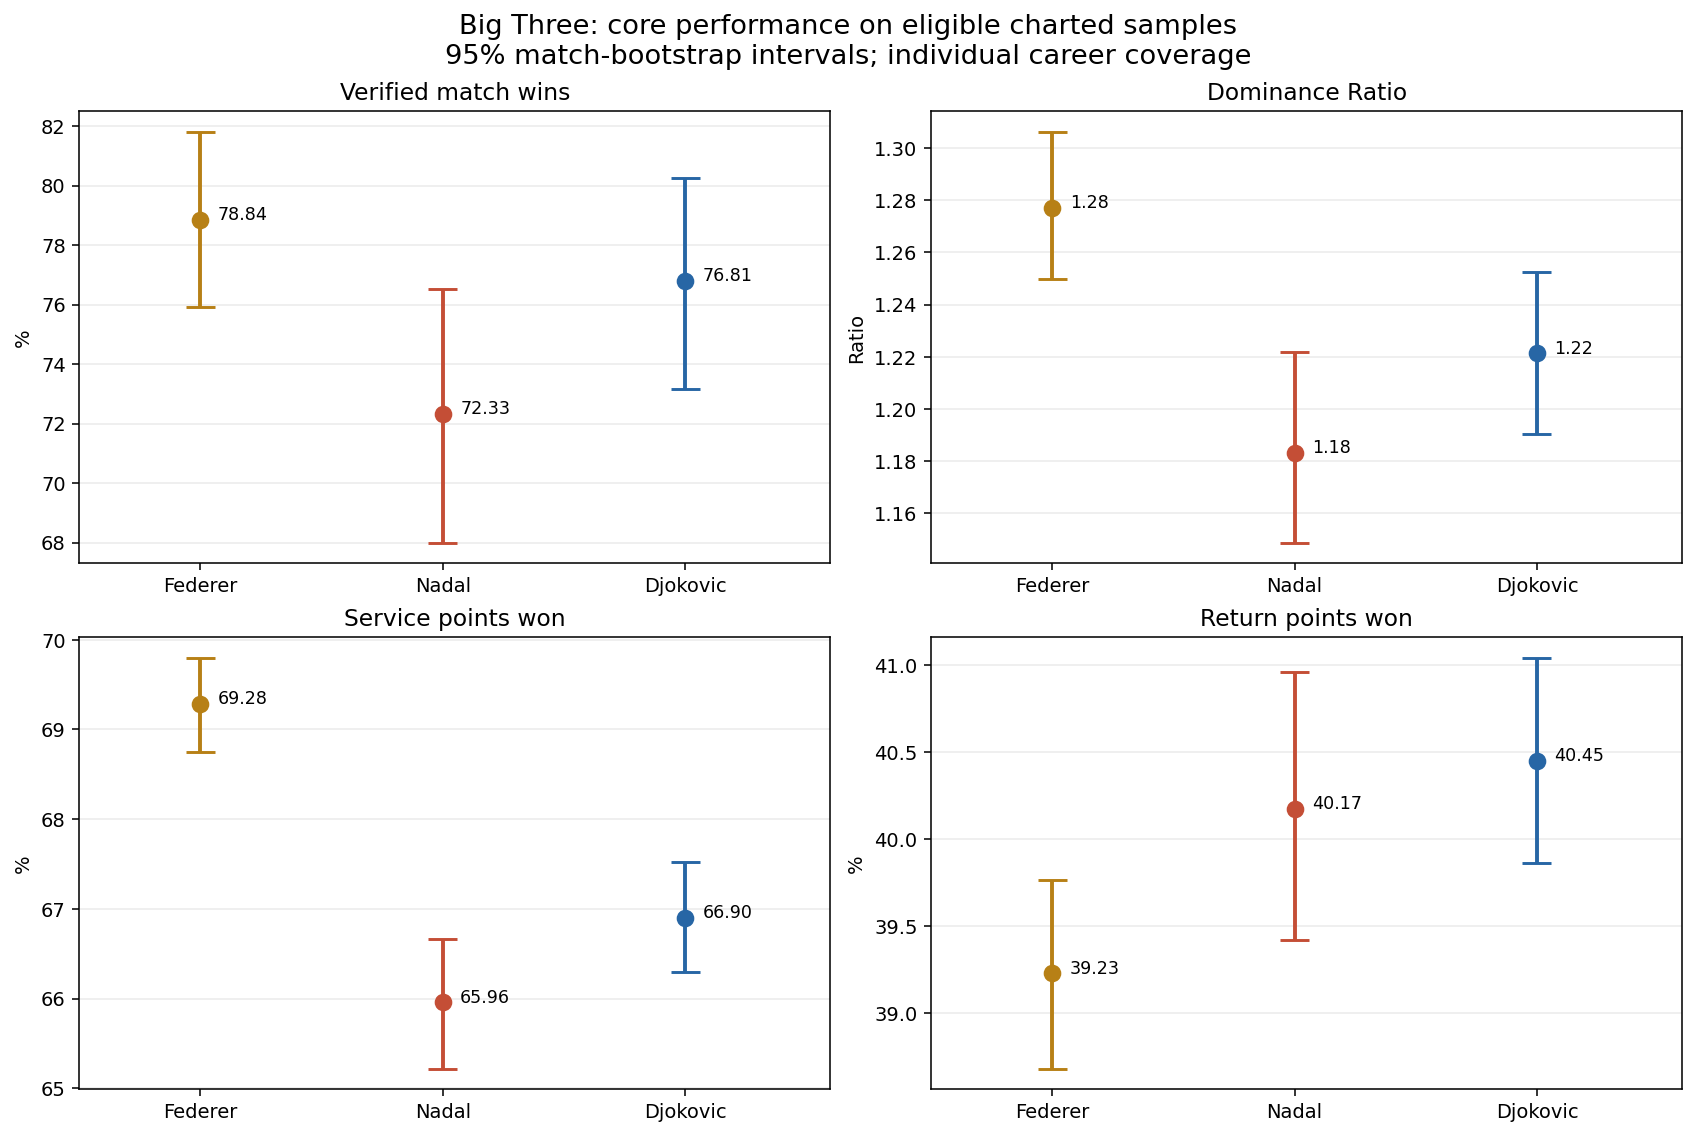

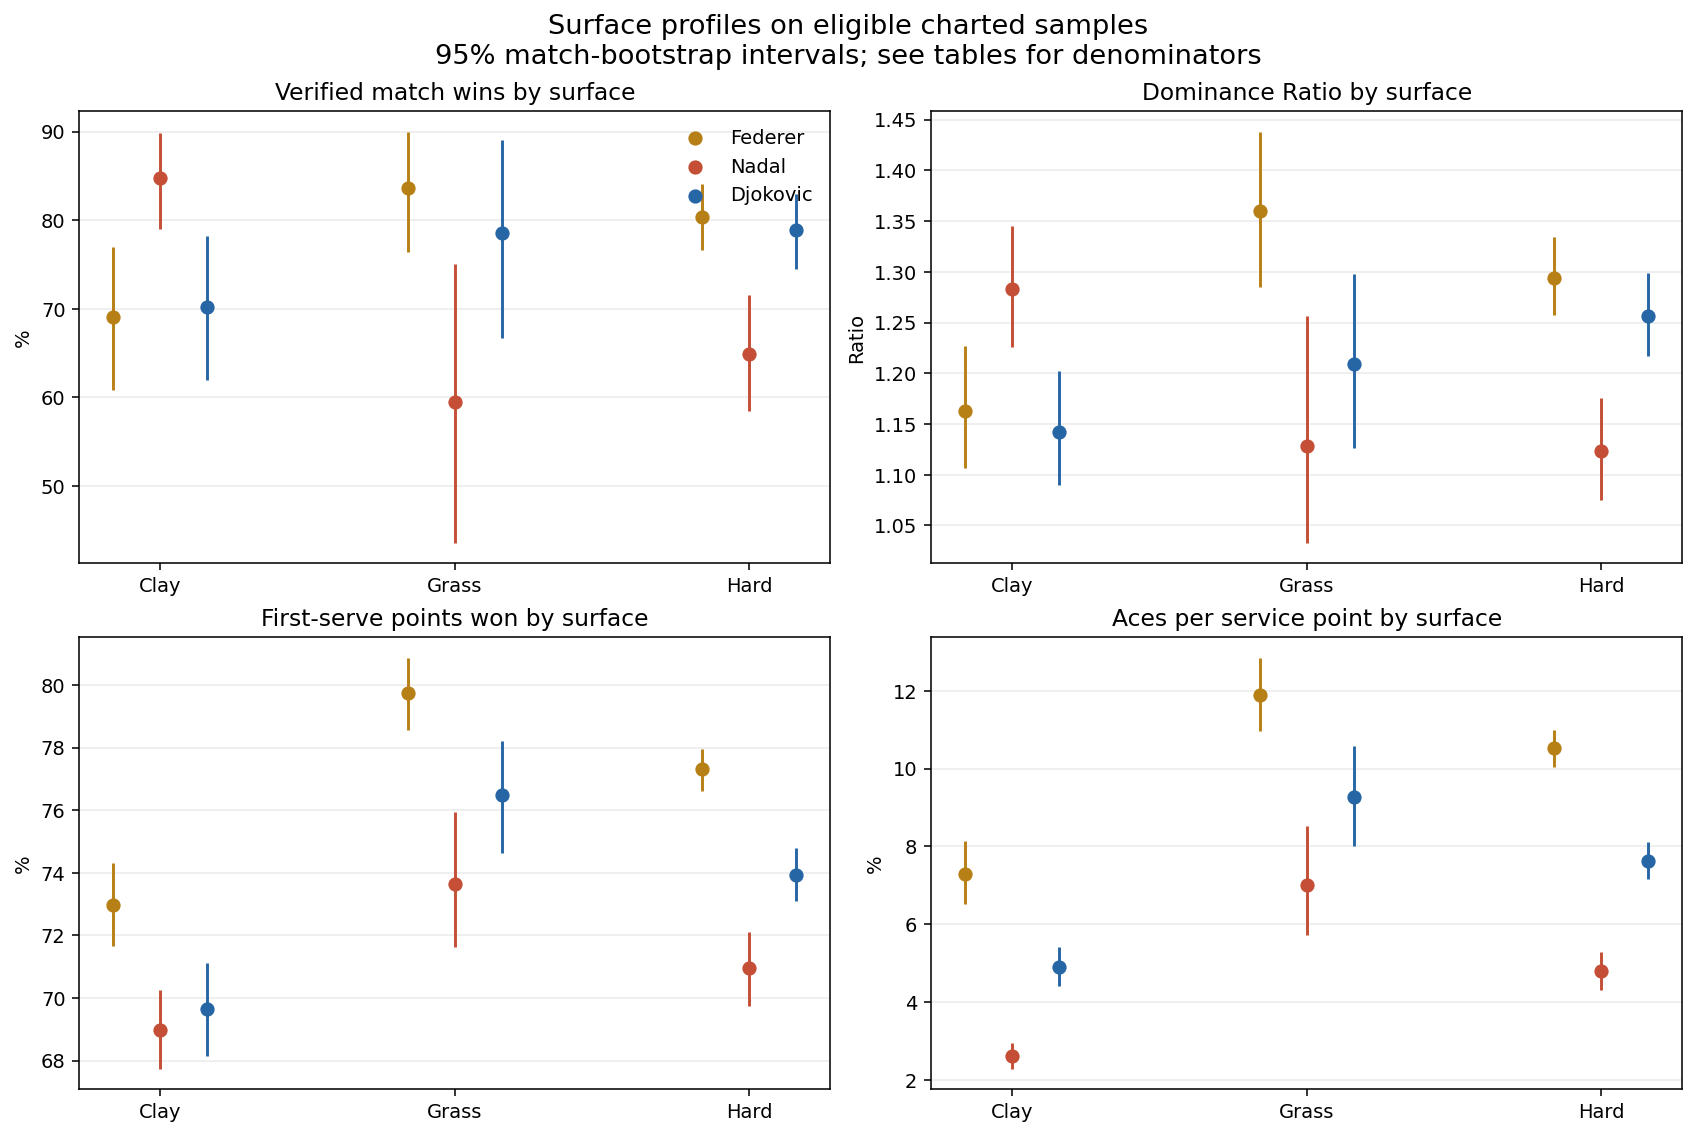

In [12]:
import io
from IPython.display import Image

KPI_PLAYER_COLORS = {"Roger Federer": "#B78016", "Rafael Nadal": "#C44E36", "Novak Djokovic": "#2766A5"}
KPI_SHORT_NAMES = {"Roger Federer": "Federer", "Rafael Nadal": "Nadal", "Novak Djokovic": "Djokovic"}
def display_kpi_figure(figure):
    buffer = io.BytesIO()
    figure.savefig(buffer, format="png", dpi=140, bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
    plt.close(figure)

with plt.style.context("default"):
    fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
    for ax, metric, title in zip(axes.flat,
        ["match_win_pct", "dominance_ratio", "service_point_win_pct", "return_point_win_pct"],
        ["Verified match wins", "Dominance Ratio", "Service points won", "Return points won"]):
        for index, player in enumerate(BIG_THREE):
            row = core_kpi_long.loc[core_kpi_long["player"].eq(player) & core_kpi_long["surface"].eq("Overall") & core_kpi_long["metric"].eq(metric)].iloc[0]
            if pd.isna(row["estimate"]):
                continue
            ax.scatter(index, row["estimate"], color=KPI_PLAYER_COLORS[player], s=65, zorder=3)
            if pd.notna(row["ci95_lower"]):
                ax.vlines(index, row["ci95_lower"], row["ci95_upper"], color=KPI_PLAYER_COLORS[player], linewidth=2)
                ax.hlines([row["ci95_lower"], row["ci95_upper"]], index-.06, index+.06, color=KPI_PLAYER_COLORS[player])
            ax.annotate(f"{row['estimate']:.2f}", (index, row["estimate"]), xytext=(9, 0), textcoords="offset points", fontsize=9)
        ax.set_xticks(range(3), [KPI_SHORT_NAMES[p] for p in BIG_THREE])
        ax.set_xlim(-.5, 2.6)
        ax.set_title(title)
        ax.set_ylabel("Ratio" if metric == "dominance_ratio" else "%")
        ax.grid(axis="y", alpha=.25)
    fig.suptitle("Big Three: core performance on eligible charted samples\n95% match-bootstrap intervals; individual career coverage", fontsize=14)
    display_kpi_figure(fig)

    fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
    for ax, metric, title in zip(axes.flat,
        ["match_win_pct", "dominance_ratio", "first_serve_win_pct", "ace_pct"],
        ["Verified match wins by surface", "Dominance Ratio by surface", "First-serve points won by surface", "Aces per service point by surface"]):
        for player_index, player in enumerate(BIG_THREE):
            group = core_kpi_long.loc[core_kpi_long["player"].eq(player) & core_kpi_long["metric"].eq(metric)].set_index("surface").reindex(PROJECT_SURFACES)
            x = np.arange(3) + (player_index - 1) * .16
            ax.scatter(x, group["estimate"], color=KPI_PLAYER_COLORS[player], label=KPI_SHORT_NAMES[player], s=40, zorder=3)
            for xpos, (_, row) in zip(x, group.iterrows()):
                if pd.notna(row["ci95_lower"]):
                    ax.vlines(xpos, row["ci95_lower"], row["ci95_upper"], color=KPI_PLAYER_COLORS[player], linewidth=1.5)
        ax.set_xticks(range(3), PROJECT_SURFACES)
        ax.set_title(title)
        ax.set_ylabel("Ratio" if metric == "dominance_ratio" else "%")
        ax.grid(axis="y", alpha=.25)
    axes.flat[0].legend(frameon=False)
    fig.suptitle("Surface profiles on eligible charted samples\n95% match-bootstrap intervals; see tables for denominators", fontsize=14)
    display_kpi_figure(fig)


### 5.4 Reading the performance results
These scorecards summarize verified match outcomes and eligible source/point statistics. Unknown endings, source discrepancies, and different charted schedules affect who contributes to each estimate. The source-compatible service/return rates deliberately use different coverage from the all-recorded-outcome point-win rate. A high ace rate describes one serving weapon, not complete serving strength; return-point success and DR add complementary context. Hold and break rates are reconstructed from fully eligible regular games, not inferred from overall match wins.

`core_kpi_long` is the auditable metric table, `core_kpi_coverage` records scope and context, and `core_kpi_overall` / `core_kpi_by_surface` are display-friendly scorecards. Counts and unavailable ranking history have no bootstrap intervals. Sections VI–IX report Clutch Index, adaptability, shot diversity, tactical evolution, style profiles, and the preference comparison.

<a id="pressure"></a>

## VI. Pressure outcomes and Clutch Index

**Pressure question:** Do raw pressure outcomes and context-adjusted point associations tell the same story? Break points, tiebreaks, and deciding sets represent different tennis situations; their declared composite is a preference, not a psychological diagnosis.


### 6.1 Completed events and a common comparison sample
CI = **0.50 × break-point save rate + 0.30 × tiebreak win rate + 0.20 × deciding-set win rate**. It is a descriptive 0–1 composite with declared preference weights, not a measurement of mental toughness. Each full CI uses one common eligible player-match cohort for all three components. Require validated source-compatible break-point counts, valid score states, fully validated tiebreak groups (if present), a verified match outcome, and consistent supported match format. No-tiebreak and no-decider matches contribute genuine zero event counts, not invented wins or losses. Zero component denominators make full CI unavailable; an optional available-component result is explicitly labeled partial and never substitutes for full CI.

Tiebreak validation checks 0–0 starts, numerical score progression through serving changes, and a valid terminal score. Deciding-set outcomes require completed sets, verified match outcomes, and supported best-of metadata; a match tiebreak is identified separately and is not also counted as a conventional deciding set. Component-specific evidence is shown alongside the stricter common-cohort CI. Surface CIs use the same formula but may be small-sample. Uncertainty uses the 2,000 joint match draws from Section V, preserving dependence in Big Three rivalry matches.


In [13]:
# Validate complete tiebreak groups, including score rotation when the server changes.
tb_keys = ["match_id", "Set1", "Set2", "game_number"]
tb_points = canonical_points.loc[canonical_points["is_tiebreak_point"]].copy()
tb_groupers = [tb_points[k] for k in tb_keys]
tb_first = ~tb_points.duplicated(tb_keys, keep="first")
tb_last = ~tb_points.duplicated(tb_keys, keep="last")
tb_server_won = tb_points["Svr"].eq(tb_points["PtWinner"])
tb_next_svr = tb_points["Svr"].groupby(tb_groupers).shift(-1)
tb_next_left = tb_points["score_server_numeric"].groupby(tb_groupers).shift(-1)
tb_next_right = tb_points["score_receiver_numeric"].groupby(tb_groupers).shift(-1)
tb_new_left = tb_points["score_server_numeric"] + tb_server_won.astype(int)
tb_new_right = tb_points["score_receiver_numeric"] + (~tb_server_won).astype(int)
tb_switched = tb_points["Svr"].ne(tb_next_svr)
tb_transition_valid = tb_last | (~tb_points["game_ended"]
    & pd.Series(np.where(tb_switched, tb_new_right, tb_new_left), index=tb_points.index).eq(tb_next_left)
    & pd.Series(np.where(tb_switched, tb_new_left, tb_new_right), index=tb_points.index).eq(tb_next_right))
tb_points["tb_row_valid"] = (tb_points["score_state_valid"] & tb_transition_valid
    & (~tb_first | (tb_points["score_server_numeric"].eq(0) & tb_points["score_receiver_numeric"].eq(0))))
tb_group_quality = tb_points.groupby(tb_keys, as_index=False).agg(all_tb_rows_valid=("tb_row_valid", "all"), tiebreak_points=("Pt", "size"))
validated_tiebreaks = canonical_tiebreaks.merge(tb_group_quality, on=tb_keys, validate="one_to_one")
validated_tiebreaks["tb_complete_validated"] = validated_tiebreaks["all_tb_rows_valid"] & validated_tiebreaks["tiebreak_winner"].notna()
# A deciding-set A rule cannot be trusted when recorded set counts contradict Best of.
validated_tiebreaks.loc[validated_tiebreaks["Final TB?"].eq("A") & validated_tiebreaks["match_id"].isin(format_contradiction_ids), "tb_complete_validated"] = False
bad_tb_match_ids = set(validated_tiebreaks.loc[~validated_tiebreaks["tb_complete_validated"], "match_id"])
valid_tb_keys = pd.MultiIndex.from_frame(validated_tiebreaks.loc[validated_tiebreaks["tb_complete_validated"], tb_keys])

clutch_match_events = kpi_master[["match_id", "player", "surface", "match_date", "opponent", "Best of", "Final TB?", "has_points",
    "has_overview", "winner", "outcome_status", "bp_events_validated", "bp_faced_parsed", "bp_saved_parsed", "points_played", "valid_score_points"]].copy()
clutch_match_events["bp_faced"] = clutch_match_events["bp_faced_parsed"].where(clutch_match_events["bp_events_validated"])
clutch_match_events["bp_saved"] = clutch_match_events["bp_saved_parsed"].where(clutch_match_events["bp_events_validated"])
clutch_match_events["tb_match_eligible"] = (clutch_match_events["has_points"] & ~clutch_match_events["match_id"].isin(bad_tb_match_ids)
    & clutch_match_events["valid_score_points"].eq(clutch_match_events["points_played"]))
clutch_match_events["deciding_match_eligible"] = (clutch_match_events["winner"].notna()
    & clutch_match_events["Best of"].isin([3, 5]) & ~clutch_match_events["match_id"].isin(format_contradiction_ids)
    & ~clutch_match_events["Final TB?"].eq("S"))
tb_player_rows, deciding_player_rows = [], []
for role in ["player1", "player2"]:
    a = validated_tiebreaks.loc[validated_tiebreaks["tb_complete_validated"] & validated_tiebreaks[role].isin(BIG_THREE)].copy()
    a["player"] = a[role]
    a["tiebreaks_played"] = 1
    a["tiebreaks_won"] = a["player"].eq(a["tiebreak_winner"]).astype(int)
    tb_player_rows.append(a)
    b = canonical_sets.loc[canonical_sets["deciding_set_validated"] & canonical_sets[role].isin(BIG_THREE)
        & ~canonical_sets["Final TB?"].eq("S")].copy()
    b["player"] = b[role]
    b["deciding_sets_played"] = 1
    b["deciding_sets_won"] = b["player"].eq(b["set_winner"]).astype(int)
    deciding_player_rows.append(b)
tb_match_counts = pd.concat(tb_player_rows, ignore_index=True).groupby(["match_id", "player"], as_index=False)[["tiebreaks_played", "tiebreaks_won"]].sum()
deciding_match_counts = pd.concat(deciding_player_rows, ignore_index=True).groupby(["match_id", "player"], as_index=False)[["deciding_sets_played", "deciding_sets_won"]].sum()
clutch_match_events = clutch_match_events.merge(tb_match_counts, on=["match_id", "player"], how="left", validate="one_to_one").merge(
    deciding_match_counts, on=["match_id", "player"], how="left", validate="one_to_one")
for fields, eligible_field in [(["tiebreaks_played", "tiebreaks_won"], "tb_match_eligible"),
                                (["deciding_sets_played", "deciding_sets_won"], "deciding_match_eligible")]:
    for field in fields:
        clutch_match_events[field] = clutch_match_events[field].fillna(0).where(clutch_match_events[eligible_field])
clutch_match_events["common_ci_eligible"] = (clutch_match_events["bp_events_validated"]
    & clutch_match_events["tb_match_eligible"] & clutch_match_events["deciding_match_eligible"])

CI_COMPONENTS = {"bp": ("bp_saved", "bp_faced", .5), "tb": ("tiebreaks_won", "tiebreaks_played", .3),
                 "deciding": ("deciding_sets_won", "deciding_sets_played", .2)}
clutch_rows, clutch_boot_arrays, clutch_boot_descriptors, component_evidence = [], [], [], []
for player, surface in kpi_scope_groups:
    group = clutch_match_events.loc[clutch_match_events["player"].eq(player)]
    if surface != "Overall":
        group = group.loc[group["surface"].eq(surface)]
    common = group.loc[group["common_ci_eligible"]]
    row = {"player": player, "surface": surface, "cohort_matches": len(group), "common_ci_matches": len(common),
           "common_ci_coverage_pct": 100 * len(common) / len(group) if len(group) else np.nan}
    available_weight, available_score = 0., 0.
    columns = []
    for component, (num, den, weight) in CI_COMPONENTS.items():
        numerator, denominator = common[num].sum(min_count=1), common[den].sum(min_count=1)
        rate = numerator / denominator if denominator > 0 else np.nan
        row.update({num: numerator, den: denominator, component + "_component": rate})
        broad = group.loc[group[num].notna() & group[den].notna()]
        broad_den = broad[den].sum(min_count=1)
        component_evidence.append({"player": player, "surface": surface, "component": component,
            "component_eligible_matches": len(broad), "component_wins": broad[num].sum(min_count=1), "component_events": broad_den,
            "component_only_rate": broad[num].sum(min_count=1) / broad_den if broad_den > 0 else np.nan,
            "common_ci_wins": numerator, "common_ci_events": denominator, "common_ci_rate": rate})
        if pd.notna(rate):
            available_weight += weight
            available_score += weight * rate
        for field in [num, den]:
            vector = np.zeros(len(bootstrap_match_ids))
            for match_id, value in common[["match_id", field]].itertuples(index=False, name=None):
                vector[bootstrap_match_index[match_id]] = value
            columns.append(len(clutch_boot_arrays))
            clutch_boot_arrays.append(vector)
    rates = [row[c + "_component"] for c in CI_COMPONENTS]
    row["clutch_index_full"] = sum(rate * spec[2] for rate, spec in zip(rates, CI_COMPONENTS.values())) if all(pd.notna(r) for r in rates) else np.nan
    row["clutch_index_partial_renorm"] = available_score / available_weight if available_weight else np.nan
    row["partial_index_label"] = "Available-component index; never substituted for full CI"
    row["small_sample"] = any(pd.isna(row[spec[1]]) or row[spec[1]] < SMALL_SAMPLE_THRESHOLDS["events"] for spec in CI_COMPONENTS.values())
    clutch_boot_descriptors.append((len(clutch_rows), columns))
    clutch_rows.append(row)
clutch_summary = pd.DataFrame(clutch_rows)
clutch_component_evidence = pd.DataFrame(component_evidence)
clutch_boot_totals = bootstrap_weights @ np.column_stack(clutch_boot_arrays)
clutch_bootstrap_distributions = {}
for index, columns in clutch_boot_descriptors:
    with np.errstate(divide="ignore", invalid="ignore"):
        rates = [np.where(clutch_boot_totals[:, columns[j+1]] > 0,
            clutch_boot_totals[:, columns[j]] / clutch_boot_totals[:, columns[j+1]], np.nan) for j in [0, 2, 4]]
        full = .5 * rates[0] + .3 * rates[1] + .2 * rates[2]
    for metric, values in zip(["bp_component", "tb_component", "deciding_component", "clutch_index_full"], rates + [full]):
        valid = values[np.isfinite(values)]
        clutch_summary.loc[index, metric + "_valid_bootstraps"] = len(valid)
        clutch_summary.loc[index, metric + "_ci95_lower"] = np.percentile(valid, 2.5) if len(valid) >= .95 * BOOTSTRAP_REPLICATES else np.nan
        clutch_summary.loc[index, metric + "_ci95_upper"] = np.percentile(valid, 97.5) if len(valid) >= .95 * BOOTSTRAP_REPLICATES else np.nan
    clutch_bootstrap_distributions[(clutch_summary.loc[index, "player"], clutch_summary.loc[index, "surface"])] = full
clutch_summary["status"] = np.where(clutch_summary["clutch_index_full"].isna(), "unavailable", np.where(clutch_summary["small_sample"], "small sample", "available"))
clutch_overall = clutch_summary.loc[clutch_summary["surface"].eq("Overall")].reset_index(drop=True)
clutch_by_surface = clutch_summary.loc[clutch_summary["surface"].ne("Overall")].reset_index(drop=True)
assert not clutch_match_events.duplicated(["match_id", "player"]).any()
assert not clutch_summary.duplicated(["player", "surface"]).any()
assert clutch_summary["clutch_index_full"].dropna().between(0, 1).all()
for num, den, _ in CI_COMPONENTS.values():
    assert clutch_summary[num].dropna().le(clutch_summary[den].dropna()).all()
assert clutch_summary["common_ci_matches"].le(clutch_summary["cohort_matches"]).all()
print("Clutch Index on a common cohort: full counts, components, and uncertainty")
with pd.option_context("display.max_columns", None):
    report_table(clutch_summary.round(4))
print("Component-specific evidence versus the stricter common CI cohort:")
report_table(clutch_component_evidence.round(4))
print("Tiebreak groups requiring review (excluded, not assigned a winner):")
report_table(validated_tiebreaks.loc[~validated_tiebreaks["tb_complete_validated"], tb_keys + ["tiebreak_points", "all_tb_rows_valid", "game_ended"]])
print("Common-cohort eligibility counts:")
report_table(clutch_match_events.groupby("player", as_index=False)[["bp_events_validated", "tb_match_eligible", "deciding_match_eligible", "common_ci_eligible"]].sum())


Clutch Index on a common cohort: full counts, components, and uncertainty


player,surface,cohort_matches,common_ci_matches,common_ci_coverage_pct,bp_saved,bp_faced,bp_component,tiebreaks_won,tiebreaks_played,tb_component,deciding_sets_won,deciding_sets_played,deciding_component,clutch_index_full,clutch_index_partial_renorm,partial_index_label,small_sample,bp_component_valid_bootstraps,bp_component_ci95_lower,bp_component_ci95_upper,tb_component_valid_bootstraps,tb_component_ci95_lower,tb_component_ci95_upper,deciding_component_valid_bootstraps,deciding_component_ci95_lower,deciding_component_ci95_upper,clutch_index_full_valid_bootstraps,clutch_index_full_ci95_lower,clutch_index_full_ci95_upper,status
Roger Federer,Overall,723,687,95.021,2154,3271,0.658,229.000,366.000,0.626,109.000,179.000,0.609,0.639,0.639,Available-component index; never substituted for full CI,False,"2,000.000",0.643,0.675,"2,000.000",0.573,0.676,"2,000.000",0.537,0.681,"2,000.000",0.614,0.664,available
Roger Federer,Clay,130,122,93.846,505,809,0.624,36.000,64.000,0.562,19.000,32.000,0.594,0.600,0.600,Available-component index; never substituted for full CI,False,"2,000.000",0.591,0.656,"2,000.000",0.443,0.677,"2,000.000",0.424,0.765,"2,000.000",0.541,0.659,available
Roger Federer,Grass,119,116,97.479,331,459,0.721,60.000,91.000,0.659,16.000,27.000,0.593,0.677,0.677,Available-component index; never substituted for full CI,True,"2,000.000",0.684,0.756,"2,000.000",0.553,0.759,"2,000.000",0.393,0.781,"2,000.000",0.614,0.736,small sample
Roger Federer,Hard,474,449,94.726,1318,2003,0.658,133.000,211.000,0.630,74.000,120.000,0.617,0.641,0.641,Available-component index; never substituted for full CI,False,"2,000.000",0.637,0.679,"2,000.000",0.562,0.698,"2,000.000",0.529,0.704,"2,000.000",0.609,0.674,available
Rafael Nadal,Overall,425,392,92.235,1489,2338,0.637,89.000,172.000,0.517,65.000,97.000,0.670,0.608,0.608,Available-component index; never substituted for full CI,False,"2,000.000",0.618,0.656,"2,000.000",0.440,0.595,"2,000.000",0.571,0.762,"2,000.000",0.572,0.640,available
Rafael Nadal,Clay,166,153,92.169,635,970,0.655,27.000,48.000,0.562,28.000,32.000,0.875,0.671,0.671,Available-component index; never substituted for full CI,False,"2,000.000",0.623,0.687,"2,000.000",0.432,0.692,"2,000.000",0.741,0.971,"2,000.000",0.614,0.721,available
Rafael Nadal,Grass,40,36,90.000,155,232,0.668,14.000,29.000,0.483,4.000,9.000,0.444,0.568,0.568,Available-component index; never substituted for full CI,True,"2,000.000",0.598,0.735,"2,000.000",0.281,0.707,"2,000.000",0.100,0.800,"2,000.000",0.477,0.661,small sample
Rafael Nadal,Hard,219,203,92.694,699,1136,0.615,48.000,95.000,0.505,33.000,56.000,0.589,0.577,0.577,Available-component index; never substituted for full CI,False,"2,000.000",0.587,0.644,"2,000.000",0.398,0.613,"2,000.000",0.451,0.717,"2,000.000",0.529,0.625,available
Novak Djokovic,Overall,553,519,93.852,1901,2957,0.643,146.000,237.000,0.616,90.000,132.000,0.682,0.643,0.643,Available-component index; never substituted for full CI,False,"2,000.000",0.625,0.661,"2,000.000",0.550,0.679,"2,000.000",0.605,0.764,"2,000.000",0.614,0.671,available
Novak Djokovic,Clay,129,122,94.574,525,860,0.611,29.000,48.000,0.604,24.000,37.000,0.649,0.616,0.616,Available-component index; never substituted for full CI,False,"2,000.000",0.575,0.645,"2,000.000",0.447,0.761,"2,000.000",0.488,0.800,"2,000.000",0.564,0.677,available


Component-specific evidence versus the stricter common CI cohort:


player,surface,component,component_eligible_matches,component_wins,component_events,component_only_rate,common_ci_wins,common_ci_events,common_ci_rate
Roger Federer,Overall,bp,702,"2,187.000","3,324.000",0.658,"2,154.000","3,271.000",0.658
Roger Federer,Overall,tb,717,237.000,376.000,0.630,229.000,366.000,0.626
Roger Federer,Overall,deciding,707,115.000,187.000,0.615,109.000,179.000,0.609
Roger Federer,Clay,bp,126,515.000,824.000,0.625,505.000,809.000,0.624
Roger Federer,Clay,tb,130,38.000,66.000,0.576,36.000,64.000,0.562
Roger Federer,Clay,deciding,126,21.000,34.000,0.618,19.000,32.000,0.594
Roger Federer,Grass,bp,119,344.000,479.000,0.718,331.000,459.000,0.721
Roger Federer,Grass,tb,119,60.000,92.000,0.652,60.000,91.000,0.659
Roger Federer,Grass,deciding,116,16.000,27.000,0.593,16.000,27.000,0.593
Roger Federer,Hard,bp,457,"1,328.000","2,021.000",0.657,"1,318.000","2,003.000",0.658


Tiebreak groups requiring review (excluded, not assigned a winner):


,match_id,Set1,Set2,game_number,tiebreak_points,all_tb_rows_valid,game_ended
315,20120129-M-Australian_Open-F-Novak_Djokovic-Rafael_Nadal,2,1,43.0,12,False,False
344,20121112-M-Tour_Finals-F-Roger_Federer-Novak_Djokovic,0,0,13.0,14,False,False
390,20140423-M-Barcelona-R32-Albert_Ramos-Rafael_Nadal,0,0,13.0,9,False,False
523,20170924-M-Laver_Cup-RR-Roger_Federer-Nick_Kyrgios,0,1,23.0,14,True,False
611,20190921-M-Laver_Cup-RR-Milos_Raonic-Rafael_Nadal,0,1,22.0,8,True,False
612,20190921-M-Laver_Cup-RR-Roger_Federer-Nick_Kyrgios,0,0,13.0,12,True,False
614,20190922-M-Laver_Cup-RR-John_Isner-Roger_Federer,0,1,23.0,10,True,False


Common-cohort eligibility counts:


player,bp_events_validated,tb_match_eligible,deciding_match_eligible,common_ci_eligible
Novak Djokovic,546,550,526,519
Rafael Nadal,404,420,412,392
Roger Federer,702,717,707,687


### 6.2 Separate point-outcome models
Fit **two inferential logistic regressions**: saving a break point while serving, and winning a point in a validated completed tiebreak. The tiebreak model includes whether the player is serving. Both use player effects, surface, set number, deciding-set state, preceding-point rally length, and a descriptive opponent-strength proxy. Unsupported or contradicted match formats are excluded from model context. Break-point observations follow the source-compatible eligibility used in Section V; match completion is not required for the point model.

Opponent context is pooled return-point success for the BP opponent and pooled total-point success for the TB opponent, calculated from the local Overview tables **excluding the current match**. Require at least ten other Overview matches; otherwise retain a missing-context indicator and impute the observed model-sample mean. Prior-rally missingness is also explicitly indicated, with mean imputation for that covariate. These are retrospective contextual associations, not leakage-free forecasts or causal adjustments. Age, injury, career phase, and unmeasured opponent differences remain limitations.

Player indicators are fitted without a global intercept. Their exponentials are **reference-profile odds**, not player-to-player odds ratios. Direct pairwise contrasts use coefficient differences and the full match-clustered covariance. Wald intervals are unadjusted 95%; Holm-adjusted p-values cover all six planned player comparisons across both models. Point observations within a match, including complementary rivalry tiebreak rows, share one uncertainty cluster. No model result measures psychology or establishes an overall GOAT.

For a binary outcome, the model is $\operatorname{logit}(p_i)=x_i^Teta$. A player contrast is $\exp(eta_a-eta_b)$; an odds ratio of 1 is equality of conditional odds, not equality of observed win percentages. Hard is the surface reference, first set and non-deciding are the state reference, and centered continuous covariates are evaluated at their model-sample means. The opponent coefficient refers to a full 0–1 change; the added diagnostic table reports the more interpretable **10-percentage-point** change. Robust covariance aggregates score contributions by match, allowing point dependence within a match. Independence across match clusters and the additive logit form remain assumptions; career/era dependence is not eliminated.

The six planned contrasts form one Holm family. An unadjusted interval can exclude 1 even when its Holm-adjusted test does not reject. Failure to reject is not proof of equivalence. In-sample Brier scores summarize fit only; the model is not evaluated or advertised as a forecast.


In [14]:
# Assemble eligible pressure observations without re-parsing point scores or rally codes.
context_master = kpi_master[["match_id", "player", "opponent", "Best of", "Final TB?", "bp_events_validated"]]
pressure_player_points = canonical_player_points.merge(context_master, on=["match_id", "player"], how="left", validate="many_to_one")
valid_context = (pressure_player_points["Best of"].isin([3, 5])
    & ~pressure_player_points["match_id"].isin(format_contradiction_ids)
    & pressure_player_points["surface"].isin(PROJECT_SURFACES))
bp_model_events = pressure_player_points.loc[valid_context & pressure_player_points["bp_events_validated"] & pressure_player_points["bp_faced"]].copy()
bp_model_events["success"] = bp_model_events["point_won"].astype(int)
tb_point_keys = canonical_points.loc[canonical_points["is_tiebreak_point"]].copy()
tb_point_keys = tb_point_keys.loc[pd.MultiIndex.from_frame(tb_point_keys[tb_keys]).isin(valid_tb_keys), ["match_id", "Pt"]]
tb_model_events = pressure_player_points.loc[valid_context & pressure_player_points["is_tiebreak_point"]].merge(tb_point_keys,
    on=["match_id", "Pt"], how="inner", validate="many_to_one")
tb_model_events["success"] = tb_model_events["point_won"].astype(int)

opponent_overview = filter_stat_slice(analysis_dataframes["charting_m_stats_Overview"], None, "total").copy()
opponent_overview["context_point_wins"] = opponent_overview["first_won"] + opponent_overview["second_won"] + opponent_overview["return_pts_won"]
opponent_overview["context_points"] = opponent_overview["serve_pts"] + opponent_overview["return_pts"]
context_fields = ["return_pts_won", "return_pts", "context_point_wins", "context_points"]
context_valid = opponent_overview[context_fields].notna().all(axis=1) & opponent_overview[context_fields].ge(0).all(axis=1)
context_valid &= opponent_overview["return_pts_won"].le(opponent_overview["return_pts"]) & opponent_overview["context_point_wins"].le(opponent_overview["context_points"])
opponent_overview = opponent_overview.loc[context_valid]
opponent_totals = opponent_overview.groupby("player", as_index=False)[context_fields].sum().rename(columns={"player": "opponent"})
opponent_match_counts = opponent_overview.groupby("player")["match_id"].nunique()
opponent_totals["opponent_matches"] = opponent_totals["opponent"].map(opponent_match_counts)
current_opponent_rows = opponent_overview[["match_id", "player"] + context_fields].rename(columns={"player": "opponent", **{c: "current_" + c for c in context_fields}})
PLAYER_PRESSURE_TERMS = {p: "player_" + p.split()[-1].lower() for p in BIG_THREE}

def fit_pressure_outcome_model(events, kind):
    events = events.merge(opponent_totals, on="opponent", how="left", validate="many_to_one").merge(
        current_opponent_rows, on=["match_id", "opponent"], how="left", validate="many_to_one")
    current_present = events["current_context_points"].notna().astype(int)
    other_matches = events["opponent_matches"] - current_present
    wins_field, points_field = ("return_pts_won", "return_pts") if kind == "BP save" else ("context_point_wins", "context_points")
    other_wins = events[wins_field] - events["current_" + wins_field].fillna(0)
    other_points = events[points_field] - events["current_" + points_field].fillna(0)
    events["opponent_strength"] = (other_wins / other_points).where(other_matches.ge(10) & other_points.gt(0))
    events = events.reset_index(drop=True)
    design = pd.DataFrame({term: events["player"].eq(player).astype(float) for player, term in PLAYER_PRESSURE_TERMS.items()})
    design["surface_clay"] = events["surface"].eq("Clay").astype(float)
    design["surface_grass"] = events["surface"].eq("Grass").astype(float)
    design["set_after_first"] = events["set_number"] - 1
    design["deciding_set"] = events["is_deciding_set"].astype(float)
    references = {}
    for source, name in [("previous_rally_length", "prior_rally"), ("opponent_strength", "opponent_strength")]:
        values = pd.to_numeric(events[source], errors="coerce")
        reference = float(values.mean())
        if not np.isfinite(reference):
            raise ValueError(f"No supported {name} covariate for {kind}")
        references[name] = reference
        design[name + "_centered"] = values.fillna(reference) - reference
        if values.isna().any():
            design[name + "_missing"] = values.isna().astype(float)
    if kind == "TB point":
        design["is_serving"] = events["is_serving"].astype(float)
    design = design.astype(float)
    X, y = design.to_numpy(), events["success"].to_numpy(dtype=float)
    rank = np.linalg.matrix_rank(X)
    if rank != X.shape[1] or len(np.unique(y)) != 2:
        raise ValueError(f"Unsupported design or outcome variation for {kind}")
    model = LogisticRegression(penalty=None, fit_intercept=False, solver="lbfgs", max_iter=3000, tol=1e-10)
    model.fit(design, y)
    if int(model.n_iter_[0]) >= model.max_iter:
        raise RuntimeError(f"{kind} model did not converge")
    beta = model.coef_[0]
    fitted = model.predict_proba(design)[:, 1]
    information = X.T @ (X * (fitted * (1 - fitted))[:, None])
    if np.linalg.matrix_rank(information) != X.shape[1]:
        raise RuntimeError(f"{kind} information matrix is singular")
    bread = np.linalg.inv(information)
    scores = pd.DataFrame(X * (y - fitted)[:, None])
    scores["match_id"] = events["match_id"].to_numpy()
    clustered_scores = scores.groupby("match_id").sum().to_numpy()
    G, N, K = len(clustered_scores), len(y), X.shape[1]
    if G <= K or N <= K:
        raise ValueError(f"Too few independent match clusters for {kind}")
    correction = G / (G - 1) * (N - 1) / (N - K)
    covariance = correction * bread @ (clustered_scores.T @ clustered_scores) @ bread
    se = np.sqrt(np.diag(covariance))
    if not np.isfinite(se).all() or (se <= 0).any():
        raise RuntimeError(f"{kind}: invalid match-clustered uncertainty")
    critical = stats.norm.ppf(.975)
    coefficients = pd.DataFrame({"model": kind, "term": design.columns, "coefficient": beta, "clustered_se": se,
        "exp_coefficient": np.exp(beta), "ci95_lower": np.exp(beta-critical*se), "ci95_upper": np.exp(beta+critical*se),
        "p_value_unadjusted": 2 * stats.norm.sf(np.abs(beta / se))})
    diagnostics = {"model": kind, "observations": N, "match_clusters": G, "parameters": K, "design_rank": rank,
        "iterations": int(model.n_iter_[0]), "successes": int(y.sum()), "raw_success_pct": 100*y.mean(),
        "brier_in_sample": float(np.mean((y-fitted)**2)), "prior_rally_missing": int(events["previous_rally_length"].isna().sum()),
        "opponent_context_missing": int(events["opponent_strength"].isna().sum()), "information_condition_number": float(np.linalg.cond(information))}
    return {"kind": kind, "events": events, "design": design, "model": model, "beta": beta, "covariance": covariance,
        "coefficients": coefficients, "diagnostics": diagnostics, "references": references}

pressure_models = {kind: fit_pressure_outcome_model(events, kind) for kind, events in [("BP save", bp_model_events), ("TB point", tb_model_events)]}
pressure_model_diagnostics = pd.DataFrame([r["diagnostics"] for r in pressure_models.values()])
pressure_model_coefficients = pd.concat([r["coefficients"] for r in pressure_models.values()], ignore_index=True)
contrast_rows, profile_rows = [], []
for kind, result in pressure_models.items():
    columns = list(result["design"].columns)
    for a, b in [(BIG_THREE[0], BIG_THREE[1]), (BIG_THREE[0], BIG_THREE[2]), (BIG_THREE[1], BIG_THREE[2])]:
        contrast = np.zeros(len(columns))
        contrast[columns.index(PLAYER_PRESSURE_TERMS[a])] = 1
        contrast[columns.index(PLAYER_PRESSURE_TERMS[b])] = -1
        delta = contrast @ result["beta"]
        se = float(np.sqrt(contrast @ result["covariance"] @ contrast))
        contrast_rows.append({"model": kind, "comparison": a + " / " + b, "odds_ratio": np.exp(delta),
            "ci95_lower": np.exp(delta - 1.96*se), "ci95_upper": np.exp(delta + 1.96*se),
            "p_value_unadjusted": 2*stats.norm.sf(abs(delta/se))})
    for player in BIG_THREE:
        for serving in ([True] if kind == "BP save" else [False, True]):
            x = np.zeros(len(columns))
            x[columns.index(PLAYER_PRESSURE_TERMS[player])] = 1
            if "is_serving" in columns:
                x[columns.index("is_serving")] = int(serving)
            logit = x @ result["beta"]
            se = float(np.sqrt(x @ result["covariance"] @ x))
            logistic = lambda z: 1 / (1 + np.exp(-z))
            profile_rows.append({"model": kind, "player": player, "is_serving": serving,
                "reference_probability_pct": 100*logistic(logit), "ci95_lower": 100*logistic(logit-1.96*se),
                "ci95_upper": 100*logistic(logit+1.96*se), "reference_surface": "Hard", "reference_set": 1,
                "prior_rally_reference": result["references"]["prior_rally"], "opponent_strength_reference": result["references"]["opponent_strength"]})
pressure_pairwise = pd.DataFrame(contrast_rows)
order = np.argsort(pressure_pairwise["p_value_unadjusted"].to_numpy())
adjusted = np.minimum(1, np.maximum.accumulate((len(order)-np.arange(len(order))) * pressure_pairwise.iloc[order]["p_value_unadjusted"].to_numpy()))
pressure_pairwise.loc[order, "p_value_holm_six_tests"] = adjusted
pressure_reference_profiles = pd.DataFrame(profile_rows)
pressure_event_coverage = pd.concat([result["events"].assign(model=kind) for kind, result in pressure_models.items()], ignore_index=True).groupby(
    ["model", "player", "surface"], as_index=False).agg(observations=("success", "size"), successes=("success", "sum"), match_clusters=("match_id", "nunique"))
pressure_event_coverage["observed_success_pct"] = 100*pressure_event_coverage["successes"] / pressure_event_coverage["observations"]
assert pressure_pairwise["p_value_holm_six_tests"].between(0, 1).all()
assert pressure_pairwise["odds_ratio"].gt(0).all()
assert pressure_reference_profiles["reference_probability_pct"].between(0, 100).all()
assert pressure_pairwise["ci95_lower"].le(pressure_pairwise["ci95_upper"]).all()
assert not bp_model_events.duplicated(["match_id", "Pt", "player"]).any()
assert not tb_model_events.duplicated(["match_id", "Pt", "player"]).any()
print("Pressure model diagnostics (in-sample fit describes these observations, not predictive performance):")
report_table(pressure_model_diagnostics.round(5))
print("Observed event coverage by player and surface:")
report_table(pressure_event_coverage.round(3))
print("Model coefficients: player exponentials are reference odds; other exponentials are conditional odds ratios:")
with pd.option_context("display.max_rows", None):
    report_table(pressure_model_coefficients)
print("Direct player comparisons: unadjusted 95% intervals and Holm p-values across all six planned tests:")
with pd.option_context("display.max_colwidth", None):
    report_table(pressure_pairwise)
print("Conditional probabilities: Hard, set 1, non-deciding, model-average prior rally and opponent context, neither covariate missing:")
report_table(pressure_reference_profiles.round(4))


Pressure model diagnostics (in-sample fit describes these observations, not predictive performance):


model,observations,match_clusters,parameters,design_rank,iterations,successes,raw_success_pct,brier_in_sample,prior_rally_missing,opponent_context_missing,information_condition_number
BP save,8773,1342,11,11,100,5673,64.664,0.227,8,688,"29,522.560"
TB point,9586,595,12,12,96,5101,53.213,0.229,18,860,"61,970.064"


Observed event coverage by player and surface:


model,player,surface,observations,successes,match_clusters,observed_success_pct
BP save,Novak Djokovic,Clay,865,527,119,60.925
BP save,Novak Djokovic,Grass,374,256,55,68.449
BP save,Novak Djokovic,Hard,1797,1161,318,64.608
BP save,Rafael Nadal,Clay,980,640,139,65.306
BP save,Rafael Nadal,Grass,245,166,33,67.755
BP save,Rafael Nadal,Hard,1206,748,188,62.023
BP save,Roger Federer,Clay,824,515,121,62.500
BP save,Roger Federer,Grass,467,337,97,72.163
BP save,Roger Federer,Hard,2015,1323,390,65.658
TB point,Novak Djokovic,Clay,551,309,42,56.080


Model coefficients: player exponentials are reference odds; other exponentials are conditional odds ratios:


model,term,coefficient,clustered_se,exp_coefficient,ci95_lower,ci95_upper,p_value_unadjusted
BP save,player_federer,0.575,0.048,1.777,1.618,1.952,0
BP save,player_nadal,0.533,0.056,1.704,1.525,1.903,0
BP save,player_djokovic,0.529,0.050,1.697,1.539,1.872,0
BP save,surface_clay,-0.028,0.052,0.973,0.879,1.076,0.591
BP save,surface_grass,0.214,0.073,1.238,1.074,1.429,0.00332
BP save,set_after_first,0.030,0.026,1.030,0.979,1.084,0.248
BP save,deciding_set,-0.042,0.084,0.958,0.814,1.129,0.611
BP save,prior_rally_centered,0.001,0.005,1.001,0.992,1.010,0.82
BP save,prior_rally_missing,-0.709,0.645,0.492,0.139,1.743,0.272
BP save,opponent_strength_centered,-4.257,0.794,0.014,0.003,0.067,0


Direct player comparisons: unadjusted 95% intervals and Holm p-values across all six planned tests:


model,comparison,odds_ratio,ci95_lower,ci95_upper,p_value_unadjusted,p_value_holm_six_tests
BP save,Roger Federer / Rafael Nadal,1.043,0.930,1.170,0.473,1
BP save,Roger Federer / Novak Djokovic,1.047,0.942,1.163,0.393,1
BP save,Rafael Nadal / Novak Djokovic,1.004,0.890,1.132,0.951,1
TB point,Roger Federer / Rafael Nadal,1.091,0.974,1.221,0.132,0.659
TB point,Roger Federer / Novak Djokovic,0.941,0.841,1.052,0.286,1
TB point,Rafael Nadal / Novak Djokovic,0.863,0.758,0.982,0.0257,0.154


Conditional probabilities: Hard, set 1, non-deciding, model-average prior rally and opponent context, neither covariate missing:


model,player,is_serving,reference_probability_pct,ci95_lower,ci95_upper,reference_surface,reference_set,prior_rally_reference,opponent_strength_reference
BP save,Roger Federer,True,63.989,61.800,66.121,Hard,1,5.661,0.367
BP save,Rafael Nadal,True,63.015,60.401,65.555,Hard,1,5.661,0.367
BP save,Novak Djokovic,True,62.927,60.620,65.178,Hard,1,5.661,0.367
TB point,Roger Federer,False,39.652,37.352,42.000,Hard,1,4.762,0.502
TB point,Roger Federer,True,67.875,65.832,69.852,Hard,1,4.762,0.502
TB point,Rafael Nadal,False,37.591,34.850,40.415,Hard,1,4.762,0.502
TB point,Rafael Nadal,True,65.950,63.102,68.688,Hard,1,4.762,0.502
TB point,Novak Djokovic,False,41.118,38.639,43.642,Hard,1,4.762,0.502
TB point,Novak Djokovic,True,69.188,66.856,71.425,Hard,1,4.762,0.502


### 6.3 Component, surface, and model comparisons
The common-sample component plots and CI describe pooled event outcomes; the model profiles condition on a shared reference scenario. Their samples and questions differ. A tiebreak point win probability is not a tiebreak win percentage. Model probabilities are not unconditional player abilities. Pairwise odds-ratio whiskers use the clustered covariance; use the Holm-adjusted table for the six planned comparisons rather than inferring differences from overlapping separate player intervals.

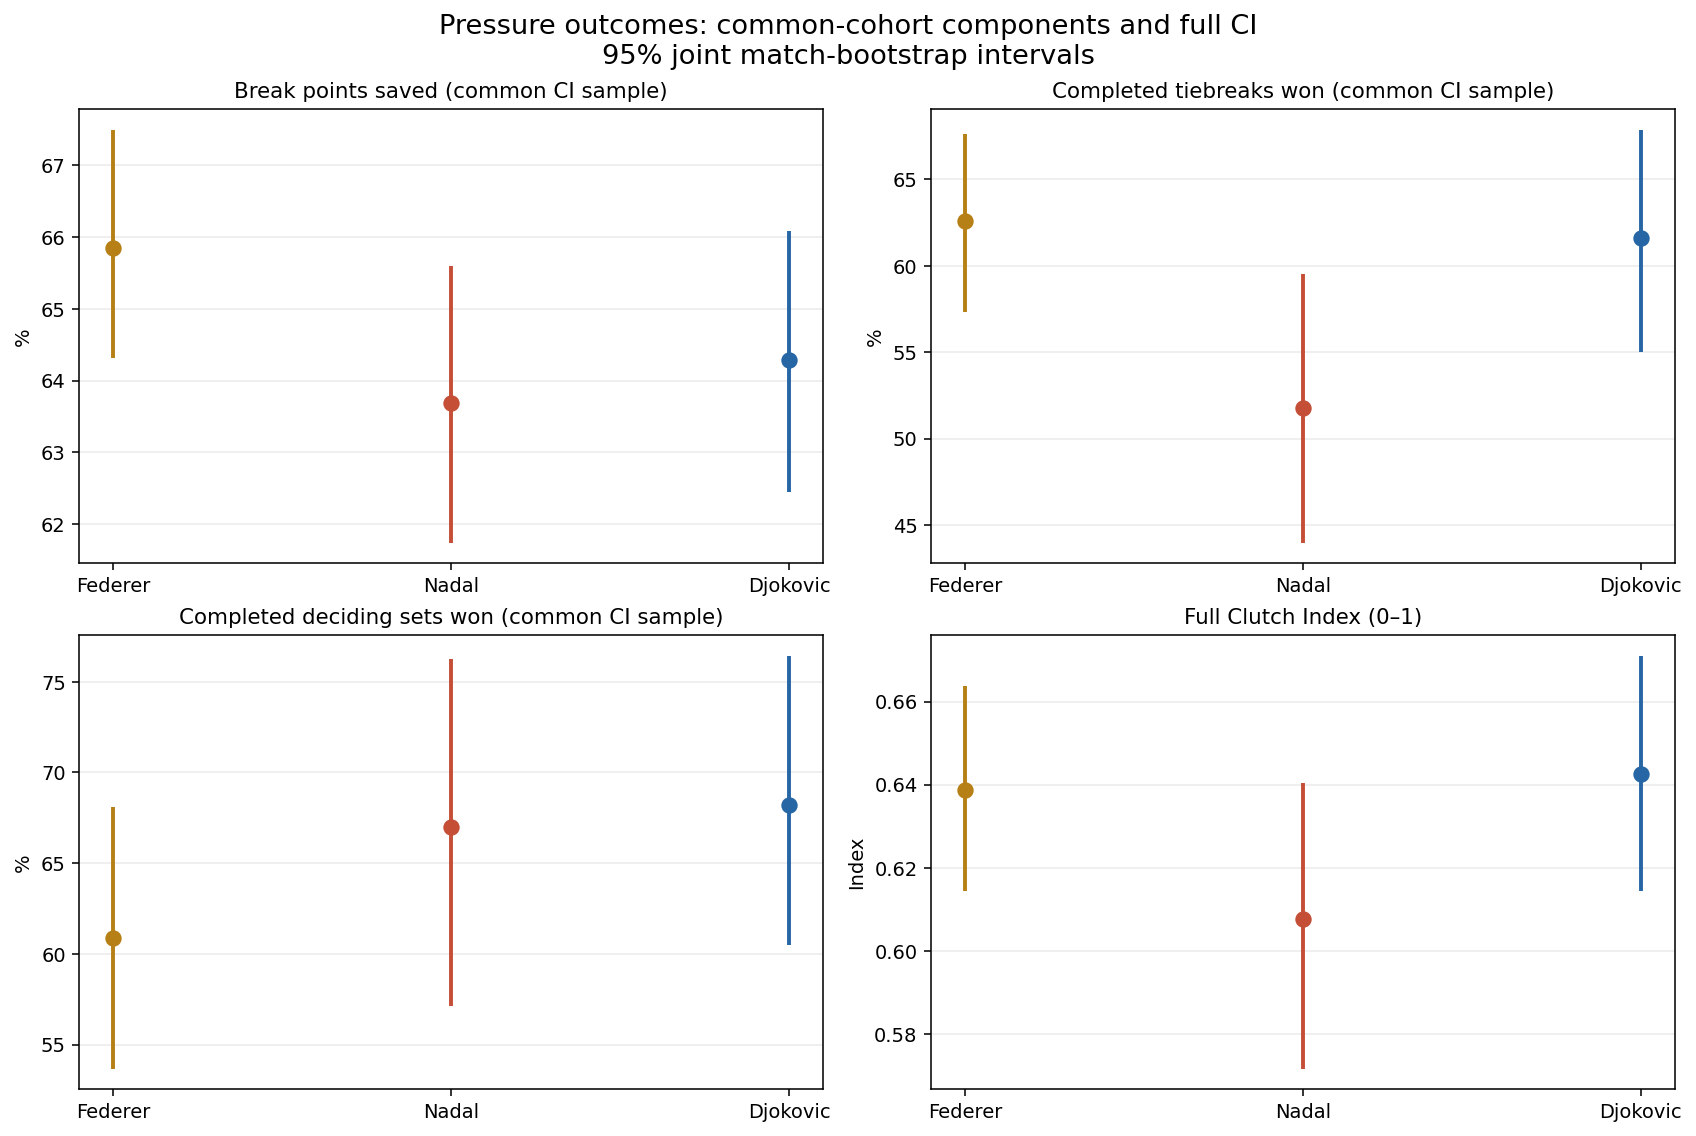

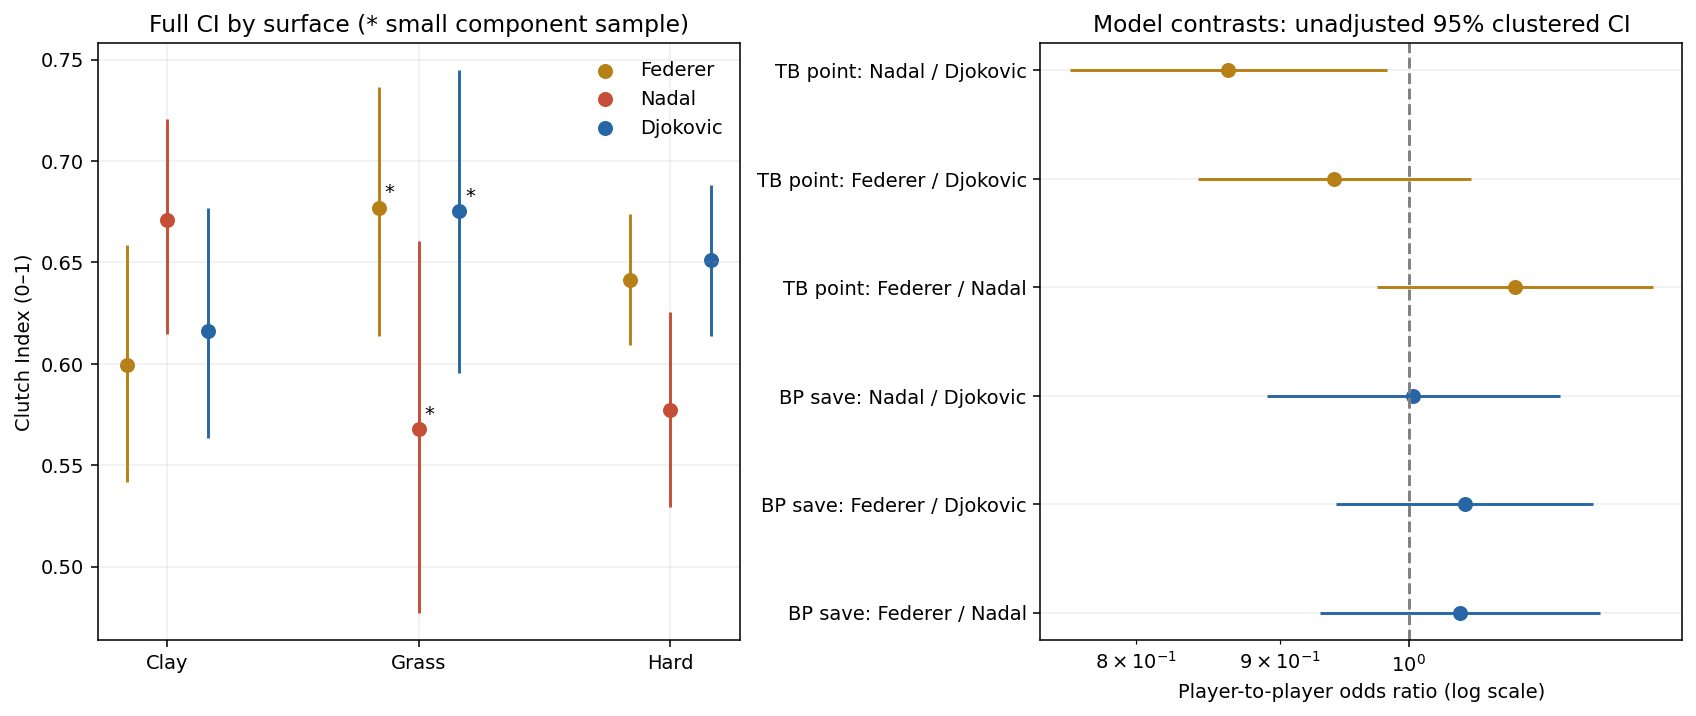

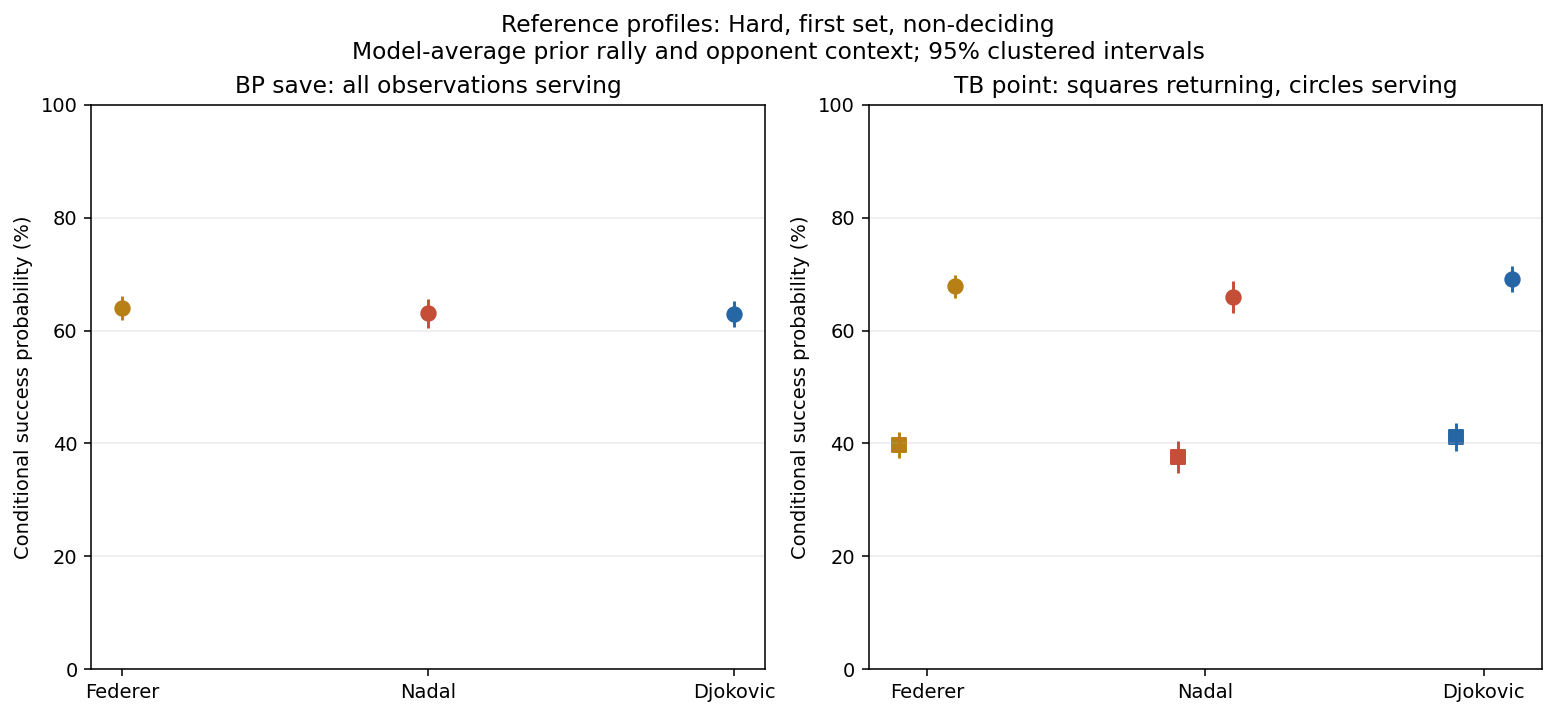

In [15]:
with plt.style.context("default"):
    fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
    for ax, metric, title in zip(axes.flat, ["bp_component", "tb_component", "deciding_component", "clutch_index_full"],
        ["Break points saved (common CI sample)", "Completed tiebreaks won (common CI sample)", "Completed deciding sets won (common CI sample)", "Full Clutch Index (0–1)"]):
        scale = 1 if metric == "clutch_index_full" else 100
        for index, player in enumerate(BIG_THREE):
            row = clutch_overall.loc[clutch_overall["player"].eq(player)].iloc[0]
            ax.scatter(index, row[metric]*scale, color=KPI_PLAYER_COLORS[player], s=55, zorder=3)
            ax.vlines(index, row[metric+"_ci95_lower"]*scale, row[metric+"_ci95_upper"]*scale, color=KPI_PLAYER_COLORS[player], linewidth=2)
        ax.set_xticks(range(3), [KPI_SHORT_NAMES[p] for p in BIG_THREE])
        ax.set_ylabel("Index" if scale == 1 else "%")
        ax.set_title(title, fontsize=11)
        ax.grid(axis="y", alpha=.25)
    fig.suptitle("Pressure outcomes: common-cohort components and full CI\n95% joint match-bootstrap intervals", fontsize=14)
    display_kpi_figure(fig)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
    for index, player in enumerate(BIG_THREE):
        rows = clutch_by_surface.loc[clutch_by_surface["player"].eq(player)].set_index("surface").reindex(PROJECT_SURFACES)
        x = np.arange(3) + (index-1)*.16
        axes[0].scatter(x, rows["clutch_index_full"], color=KPI_PLAYER_COLORS[player], label=KPI_SHORT_NAMES[player], s=45)
        for xpos, (_, row) in zip(x, rows.iterrows()):
            axes[0].vlines(xpos, row["clutch_index_full_ci95_lower"], row["clutch_index_full_ci95_upper"], color=KPI_PLAYER_COLORS[player])
            if row["small_sample"]:
                axes[0].annotate("*", (xpos, row["clutch_index_full"]), xytext=(3, 5), textcoords="offset points")
    axes[0].set_xticks(range(3), PROJECT_SURFACES)
    axes[0].set_title("Full CI by surface (* small component sample)")
    axes[0].set_ylabel("Clutch Index (0–1)")
    axes[0].legend(frameon=False)
    for index, row in pressure_pairwise.iterrows():
        color = "#2766A5" if row["model"] == "BP save" else "#B78016"
        axes[1].scatter(row["odds_ratio"], index, color=color, s=45)
        axes[1].hlines(index, row["ci95_lower"], row["ci95_upper"], color=color)
    axes[1].set_yticks(range(len(pressure_pairwise)), [r.model + ": " + r.comparison.replace("Roger ", "").replace("Rafael ", "").replace("Novak ", "") for r in pressure_pairwise.itertuples()])
    axes[1].axvline(1, color="gray", linestyle="--")
    axes[1].set_xscale("log")
    axes[1].set_xlabel("Player-to-player odds ratio (log scale)")
    axes[1].set_title("Model contrasts: unadjusted 95% clustered CI")
    for ax in axes:
        ax.grid(alpha=.2)
    display_kpi_figure(fig)

    fig, axes = plt.subplots(1, 2, figsize=(11, 5), constrained_layout=True)
    for ax, kind in zip(axes, ["BP save", "TB point"]):
        for index, player in enumerate(BIG_THREE):
            for _, row in pressure_reference_profiles.loc[pressure_reference_profiles["model"].eq(kind) & pressure_reference_profiles["player"].eq(player)].iterrows():
                xpos = index if kind == "BP save" else index + (.1 if row["is_serving"] else -.1)
                ax.scatter(xpos, row["reference_probability_pct"], marker="o" if row["is_serving"] else "s", color=KPI_PLAYER_COLORS[player], s=55)
                ax.vlines(xpos, row["ci95_lower"], row["ci95_upper"], color=KPI_PLAYER_COLORS[player])
        ax.set_xticks(range(3), [KPI_SHORT_NAMES[p] for p in BIG_THREE])
        ax.set_ylabel("Conditional success probability (%)")
        ax.set_ylim(0, 100)
        ax.set_title("BP save: all observations serving" if kind == "BP save" else "TB point: squares returning, circles serving")
        ax.grid(axis="y", alpha=.25)
    fig.suptitle("Reference profiles: Hard, first set, non-deciding\nModel-average prior rally and opponent context; 95% clustered intervals", fontsize=12)
    display_kpi_figure(fig)


### 6.4 Interpretation and validation limits
The full CI rewards the declared blend of pressure outcomes on a common sample. It is sensitive to the weights, selection of charted matches, opponent mix, and component event counts; surface estimates with fewer than 30 events in any component are flagged. Ordinary serving/returning strength can explain part of pressure success. The point models provide context-adjusted associations, not a direct measure of performing above a player's normal expectation under pressure. A future pressure-uplift metric would require a separately specified baseline and validation.

The models deliberately exclude unsupported contexts and retain missing-covariate indicators. In-sample Brier scores and convergence checks are diagnostics, not out-of-sample forecasting claims. Descriptive opponent proxies and preceding-point rally length do not exhaust confounding. The preference comparison in Section IX consumes full common-cohort CI and its paired uncertainty, not the logistic coefficients or fitted probabilities.


<a id="shots"></a>

## VII. Shot mix, diversity, and coded placement

**Tactical question:** Do the players build points with different stroke families and directional patterns? Repeated patterns can be effective; variety describes options used, rather than the quality of those choices.


### 7.1 Observed categories and denominators
Use every available eligible career period, without a 2005 cutoff. The shared parser assigns hitters **before** dropping unknown types or directions. Rally strokes exclude serves and include attempted error strokes, which are flagged separately; a stroke ending in `#` or `@` is an error attempt even without an explicit net/wide/deep suffix. Entirely uncharted S/R points contain no recoverable shot mix. Point-sequence coverage and unknown-category shares accompany all comparisons.

Shot-type shares include nine fixed known families plus unknown. Known-family entropy excludes unknown types and uses fixed K=9; zero-count families remain in the normalization. Source directional mix uses the five ShotDirection categories (crosscourt, middle, line, inside-out, inside-in), separately for Total and source F/B/S stroke classes. These source classes are not an exhaustive taxonomy of every parsed stroke; their denominator is the sum of the five classified source counts, not all rally shots. Source direction availability is shown as matches, not an invented unknown-shot fraction.

Parsed target codes 1/2/3 answer a different question: the target's right/center/left, defined relative to a right-hander's forehand/backhand reference in the workbook. In a hitter-facing-opponent court view, code 1 is on the left of the page and code 3 on the right, irrespective of the hitter's handedness. These codes alone do not establish crosscourt versus down-the-line trajectories. Return-only target diversity is reported separately. No diversity index contributes automatically to performance or greatness.


In [16]:
SHOT_KNOWN_FAMILIES = ["groundstroke", "slice", "volley", "overhead", "drop shot", "lob", "half-volley", "swinging volley", "other"]
SHOT_ALL_FAMILIES = SHOT_KNOWN_FAMILIES + ["unknown"]
SOURCE_DIRECTION_CATEGORIES = ["crosscourt", "down_middle", "down_the_line", "inside_out", "inside_in"]
TARGET_CATEGORIES = ["1", "2", "3"]
SERVE_ZONE_CATEGORIES = ["deuce_wide", "deuce_body", "deuce_t", "ad_wide", "ad_body", "ad_t"]
RETURN_JOINT_CATEGORIES = [str(depth) + "|" + str(direction) for depth in [7, 8, 9] for direction in [1, 2, 3]]
shot_analysis = canonical_shots.copy()
shot_analysis["target_category"] = shot_analysis["direction_code"].map({1: "1", 2: "2", 3: "3"})
shot_analysis["return_joint_category"] = [str(int(depth)) + "|" + str(int(direction))
    if ret and pd.notna(depth) and depth in [7, 8, 9] and pd.notna(direction) and direction in [1, 2, 3] else None
    for ret, depth, direction in shot_analysis[["is_return", "depth_code", "direction_code"]].itertuples(index=False, name=None)]
source_direction = analysis_dataframes["charting_m_stats_ShotDirection"].copy()
source_direction = source_direction.loc[source_direction["player"].isin(BIG_THREE)].merge(
    canonical_master[["match_id", "player", "surface"]], on=["match_id", "player"], how="inner", validate="many_to_one")
for field in SOURCE_DIRECTION_CATEGORIES:
    source_direction[field] = pd.to_numeric(source_direction[field], errors="coerce")
source_direction["direction_counts_valid"] = (source_direction[SOURCE_DIRECTION_CATEGORIES].notna().all(axis=1)
    & source_direction[SOURCE_DIRECTION_CATEGORIES].ge(0).all(axis=1)
    & source_direction[SOURCE_DIRECTION_CATEGORIES].mod(1).eq(0).all(axis=1))
source_direction_invalid = source_direction.loc[~source_direction["direction_counts_valid"]].copy()
source_direction = source_direction.loc[source_direction["direction_counts_valid"]].copy()

# Active point serve = first serve when it was played, otherwise the second serve.
# Includes coded double-fault attempts; first-serve faults preceding a second serve are not counted again.
serve_analysis = canonical_points.loc[canonical_points["server_name"].isin(BIG_THREE)].copy()
serve_analysis["player"] = serve_analysis["server_name"]
serve_analysis["target_category"] = [str(court) + "_" + {4: "wide", 5: "body", 6: "t"}[int(code)]
    if pd.notna(court) and court in ["deuce", "ad"] and pd.notna(code) and code in [4, 5, 6] else None
    for court, code in serve_analysis[["service_court", "serve_direction_code"]].itertuples(index=False, name=None)]

# Category counts at player-match grain allow the same joint match bootstrap as Sections V–VI.
def parsed_category_counts(frame, category):
    return frame.dropna(subset=[category]).groupby(["match_id", "player", "surface", category], as_index=False).size().rename(columns={category: "category", "size": "count"})

distribution_inputs = {
    "shot_type": (parsed_category_counts(shot_analysis, "shot_family"), SHOT_ALL_FAMILIES, SHOT_KNOWN_FAMILIES),
    "target_all_attempts": (parsed_category_counts(shot_analysis, "target_category"), TARGET_CATEGORIES, TARGET_CATEGORIES),
    "target_non_error_strokes": (parsed_category_counts(shot_analysis.loc[~shot_analysis["is_error_attempt"]], "target_category"), TARGET_CATEGORIES, TARGET_CATEGORIES),
    "target_returns": (parsed_category_counts(shot_analysis.loc[shot_analysis["is_return"]], "target_category"), TARGET_CATEGORIES, TARGET_CATEGORIES),
    "active_serve_target": (parsed_category_counts(serve_analysis, "target_category"), SERVE_ZONE_CATEGORIES, None),
    "return_depth_target": (parsed_category_counts(shot_analysis, "return_joint_category"), RETURN_JOINT_CATEGORIES, None),
}
for row_value in ["Total", "F", "B", "S"]:
    selected = source_direction.loc[source_direction["row"].eq(row_value)]
    counts = selected.melt(id_vars=["match_id", "player", "surface"], value_vars=SOURCE_DIRECTION_CATEGORIES,
        var_name="category", value_name="count")
    distribution_inputs["source_direction_" + row_value] = (counts, SOURCE_DIRECTION_CATEGORIES, SOURCE_DIRECTION_CATEGORIES)

def normalized_entropy(counts, known_indices):
    known = counts[..., known_indices]
    denominator = known.sum(axis=-1, keepdims=True)
    with np.errstate(divide="ignore", invalid="ignore"):
        probabilities = np.divide(known, denominator, out=np.zeros_like(known, dtype=float), where=denominator > 0)
        terms = np.where(probabilities > 0, probabilities * np.log(probabilities), 0)
        entropy = -terms.sum(axis=-1) / np.log(len(known_indices))
    return np.where(denominator[..., 0] > 0, entropy, np.nan)

shot_distribution_rows, shot_diversity_rows = [], []
for distribution, (counts, categories, entropy_categories) in distribution_inputs.items():
    for player, surface in kpi_scope_groups:
        data = counts.loc[counts["player"].eq(player)]
        if surface != "Overall":
            data = data.loc[data["surface"].eq(surface)]
        # One vector per category, including absent categories as zeros.
        category_matrix = np.zeros((len(bootstrap_match_ids), len(categories)))
        for match_id, category, count in data[["match_id", "category", "count"]].itertuples(index=False, name=None):
            if category in categories and match_id in bootstrap_match_index:
                category_matrix[bootstrap_match_index[match_id], categories.index(category)] += count
        totals = category_matrix.sum(axis=0)
        total = totals.sum()
        contributing_matches = int((category_matrix.sum(axis=1) > 0).sum())
        boot = bootstrap_weights @ category_matrix
        boot_den = boot.sum(axis=1)
        for index, category in enumerate(categories):
            with np.errstate(divide="ignore", invalid="ignore"):
                values = np.where(boot_den > 0, 100 * boot[:, index] / boot_den, np.nan)
            valid = values[np.isfinite(values)]
            shot_distribution_rows.append({"player": player, "surface": surface, "distribution": distribution, "category": category,
                "count": int(totals[index]), "classified_denominator": int(total), "share_pct": 100*totals[index]/total if total else np.nan,
                "contributing_matches": contributing_matches, "valid_bootstraps": len(valid),
                "ci95_lower": np.percentile(valid, 2.5) if len(valid) >= .95*BOOTSTRAP_REPLICATES else np.nan,
                "ci95_upper": np.percentile(valid, 97.5) if len(valid) >= .95*BOOTSTRAP_REPLICATES else np.nan})
        if entropy_categories is not None:
            indices = [categories.index(category) for category in entropy_categories]
            point_entropy = float(normalized_entropy(totals, indices))
            values = normalized_entropy(boot, indices)
            valid = values[np.isfinite(values)]
            known_count = int(totals[indices].sum())
            shot_diversity_rows.append({"player": player, "surface": surface, "distribution": distribution,
                "normalized_entropy": point_entropy, "fixed_categories_K": len(indices), "classified_strokes": known_count,
                "contributing_matches": contributing_matches, "small_sample": known_count < SMALL_SAMPLE_THRESHOLDS["shots"],
                "valid_bootstraps": len(valid), "ci95_lower": np.percentile(valid, 2.5) if len(valid) >= .95*BOOTSTRAP_REPLICATES else np.nan,
                "ci95_upper": np.percentile(valid, 97.5) if len(valid) >= .95*BOOTSTRAP_REPLICATES else np.nan})
shot_distribution_long = pd.DataFrame(shot_distribution_rows)
shot_diversity_summary = pd.DataFrame(shot_diversity_rows)

shot_coverage_rows = []
for player, surface in kpi_scope_groups:
    shots = shot_analysis.loc[shot_analysis["player"].eq(player)]
    serves = serve_analysis.loc[serve_analysis["player"].eq(player)]
    player_points = canonical_player_points.loc[canonical_player_points["player"].eq(player)]
    metadata = canonical_master.loc[canonical_master["player"].eq(player)]
    direction_rows = source_direction.loc[source_direction["player"].eq(player) & source_direction["row"].eq("Total")]
    if surface != "Overall":
        shots, serves, player_points, metadata, direction_rows = [frame.loc[frame["surface"].eq(surface)] for frame in [shots, serves, player_points, metadata, direction_rows]]
    returns = shots.loc[shots["is_return"]]
    known_targets = int(shots["target_category"].notna().sum())
    known_wings = shots["wing"].isin(["forehand", "backhand"])
    shot_coverage_rows.append({"player": player, "surface": surface, "cohort_matches": len(metadata),
        "matches_with_parsed_strokes": shots["match_id"].nunique(), "recorded_player_points": len(player_points),
        "points_with_sequence_codes": int(player_points["sequence_known"].sum()),
        "sequence_code_coverage_pct": 100*player_points["sequence_known"].mean() if len(player_points) else np.nan,
        "attempted_rally_strokes": len(shots), "error_attempts": int(shots["is_error_attempt"].sum()),
        "unknown_type_strokes": int(shots["shot_family"].eq("unknown").sum()),
        "unknown_type_pct": 100*shots["shot_family"].eq("unknown").mean() if len(shots) else np.nan,
        "known_wing_strokes": int(known_wings.sum()),
        "forehand_share_known_wing_pct": 100*shots["wing"].eq("forehand").sum()/known_wings.sum() if known_wings.sum() else np.nan,
        "classified_targets": known_targets, "target_direction_coverage_pct": 100*known_targets/len(shots) if len(shots) else np.nan,
        "parsed_return_attempts": len(returns), "returns_with_known_depth": int(returns["depth_code"].isin([7, 8, 9]).sum()),
        "return_depth_coverage_pct": 100*returns["depth_code"].isin([7, 8, 9]).mean() if len(returns) else np.nan,
        "returns_with_depth_and_direction": int(returns["return_joint_category"].notna().sum()),
        "recorded_service_points": len(serves), "classified_active_serve_targets": int(serves["target_category"].notna().sum()),
        "active_serve_target_coverage_pct": 100*serves["target_category"].notna().mean() if len(serves) else np.nan,
        "source_Total_direction_matches": direction_rows["match_id"].nunique()})
shot_coverage_summary = pd.DataFrame(shot_coverage_rows)
# Classification denominator checks and identities, including the entropy boundary cases.
assert np.isclose(normalized_entropy(np.array([1., 0, 0]), [0, 1, 2]), 0)
assert np.isclose(normalized_entropy(np.ones(3), [0, 1, 2]), 1)
assert pd.isna(normalized_entropy(np.zeros(3), [0, 1, 2]))
assert parse_point_sequence("6f#", None)["last_stroke_error"]
assert parse_point_sequence("6f#", None)["rally_length"] == 1
assert not shot_distribution_long.duplicated(["player", "surface", "distribution", "category"]).any()
assert shot_distribution_long["share_pct"].dropna().between(0, 100).all()
assert shot_diversity_summary["normalized_entropy"].dropna().between(-1e-12, 1+1e-12).all()
for _, group in shot_distribution_long.groupby(["player", "surface", "distribution"]):
    if group["classified_denominator"].iloc[0] > 0:
        assert np.isclose(group["share_pct"].sum(), 100)
        assert group["count"].sum() == group["classified_denominator"].iloc[0]
for player in BIG_THREE:
    family_rows = shot_distribution_long.loc[shot_distribution_long["player"].eq(player) & shot_distribution_long["surface"].eq("Overall") & shot_distribution_long["distribution"].eq("shot_type")]
    assert family_rows["count"].sum() == len(shot_analysis.loc[shot_analysis["player"].eq(player)])
print("Coverage and missing-category evidence:")
with pd.option_context("display.max_columns", None):
    report_table(shot_coverage_summary.round(3))
print("Shot diversity: different distributions describe different concepts; do not rank them as performance:")
with pd.option_context("display.max_rows", None):
    report_table(shot_diversity_summary.round(4))
print("Complete category counts, percentages, and match-bootstrap intervals:")
with pd.option_context("display.max_rows", None):
    report_table(shot_distribution_long.round(3))
print(f"Invalid source-direction count rows excluded: {len(source_direction_invalid)}")
report_table(source_direction_invalid)


Coverage and missing-category evidence:


player,surface,cohort_matches,matches_with_parsed_strokes,recorded_player_points,points_with_sequence_codes,sequence_code_coverage_pct,attempted_rally_strokes,error_attempts,unknown_type_strokes,unknown_type_pct,known_wing_strokes,forehand_share_known_wing_pct,classified_targets,target_direction_coverage_pct,parsed_return_attempts,returns_with_known_depth,return_depth_coverage_pct,returns_with_depth_and_direction,recorded_service_points,classified_active_serve_targets,active_serve_target_coverage_pct,source_Total_direction_matches
Roger Federer,Overall,723,722,125338,124133,99.039,220280,39628,32,0.015,220184,49.187,215848,97.988,57377,42924,74.810,42882,60460,59819,98.940,722
Roger Federer,Clay,130,130,23303,23044,98.889,45793,7809,12,0.026,45777,49.197,45132,98.557,10889,8429,77.408,8427,11371,11226,98.725,130
Roger Federer,Grass,119,119,23438,23258,99.232,35126,6933,4,0.011,35108,49.220,33574,95.582,10535,7228,68.609,7221,11202,11109,99.170,119
Roger Federer,Hard,474,473,78597,77831,99.025,139361,24886,16,0.011,139299,49.176,137142,98.408,35953,27267,75.841,27234,37887,37484,98.936,473
Rafael Nadal,Overall,425,423,70896,70639,99.637,151792,20050,11,0.007,151738,55.412,145635,95.944,31719,25627,80.794,22262,34660,34542,99.660,425
Rafael Nadal,Clay,166,166,25786,25708,99.698,62935,7309,6,0.010,62917,55.821,59868,95.127,12228,10428,85.280,8508,12513,12464,99.608,166
Rafael Nadal,Grass,40,39,8502,8413,98.953,14056,2323,3,0.021,14043,54.226,13581,96.621,3542,2722,76.849,2431,4162,4121,99.015,40
Rafael Nadal,Hard,219,218,36608,36518,99.754,74801,10418,2,0.003,74778,55.290,72186,96.504,15949,12477,78.231,11323,17985,17957,99.844,219
Novak Djokovic,Overall,553,552,93603,93110,99.473,202209,27378,25,0.012,202154,50.100,199028,98.427,41780,32139,76.924,31898,45935,45681,99.447,552
Novak Djokovic,Clay,129,129,21959,21870,99.595,52098,6617,14,0.027,52080,50.340,51435,98.727,10022,7946,79.286,7756,10927,10874,99.515,129


Shot diversity: different distributions describe different concepts; do not rank them as performance:


player,surface,distribution,normalized_entropy,fixed_categories_K,classified_strokes,contributing_matches,small_sample,valid_bootstraps,ci95_lower,ci95_upper
Roger Federer,Overall,shot_type,0.410,9,220248,722,False,2000,0.406,0.415
Roger Federer,Clay,shot_type,0.373,9,45781,130,False,2000,0.362,0.384
Roger Federer,Grass,shot_type,0.451,9,35122,119,False,2000,0.439,0.464
Roger Federer,Hard,shot_type,0.410,9,139345,473,False,2000,0.405,0.416
Rafael Nadal,Overall,shot_type,0.257,9,151781,423,False,2000,0.250,0.264
Rafael Nadal,Clay,shot_type,0.217,9,62929,166,False,2000,0.209,0.226
Rafael Nadal,Grass,shot_type,0.335,9,14053,39,False,2000,0.314,0.356
Rafael Nadal,Hard,shot_type,0.270,9,74799,218,False,2000,0.262,0.278
Novak Djokovic,Overall,shot_type,0.280,9,202184,552,False,2000,0.274,0.286
Novak Djokovic,Clay,shot_type,0.258,9,52084,129,False,2000,0.246,0.269


Complete category counts, percentages, and match-bootstrap intervals:


player,surface,distribution,category,count,classified_denominator,share_pct,contributing_matches,valid_bootstraps,ci95_lower,ci95_upper
Roger Federer,Overall,shot_type,groundstroke,158256,220280,71.843,722,2000,71.354,72.331
Roger Federer,Overall,shot_type,slice,42402,220280,19.249,722,2000,18.805,19.694
Roger Federer,Overall,shot_type,volley,9847,220280,4.470,722,2000,4.285,4.653
Roger Federer,Overall,shot_type,overhead,2687,220280,1.220,722,2000,1.159,1.282
Roger Federer,Overall,shot_type,drop shot,2135,220280,0.969,722,2000,0.906,1.039
Roger Federer,Overall,shot_type,lob,2226,220280,1.011,722,2000,0.951,1.067
Roger Federer,Overall,shot_type,half-volley,1652,220280,0.750,722,2000,0.685,0.825
Roger Federer,Overall,shot_type,swinging volley,979,220280,0.444,722,2000,0.411,0.480
Roger Federer,Overall,shot_type,other,64,220280,0.029,722,2000,0.021,0.037
Roger Federer,Overall,shot_type,unknown,32,220280,0.015,722,2000,0.009,0.022


Invalid source-direction count rows excluded: 0


### 7.2 Shot mix and conditional directional variety
Shot-type mix uses all parsed attempted rally strokes, including unknown types. Entropy uses known types only; classifications and K are fixed across players and surfaces. Source directional shares and their F/B/S breakdown use the source's classified counts; they are not interchangeable with the parser's three target-side codes. Returns have a separate three-target distribution. All rates pool counts before division; bootstrap draws resample matches jointly rather than treating strokes as independent observations. No uncertainty interval addresses uncharted or misclassified strokes.

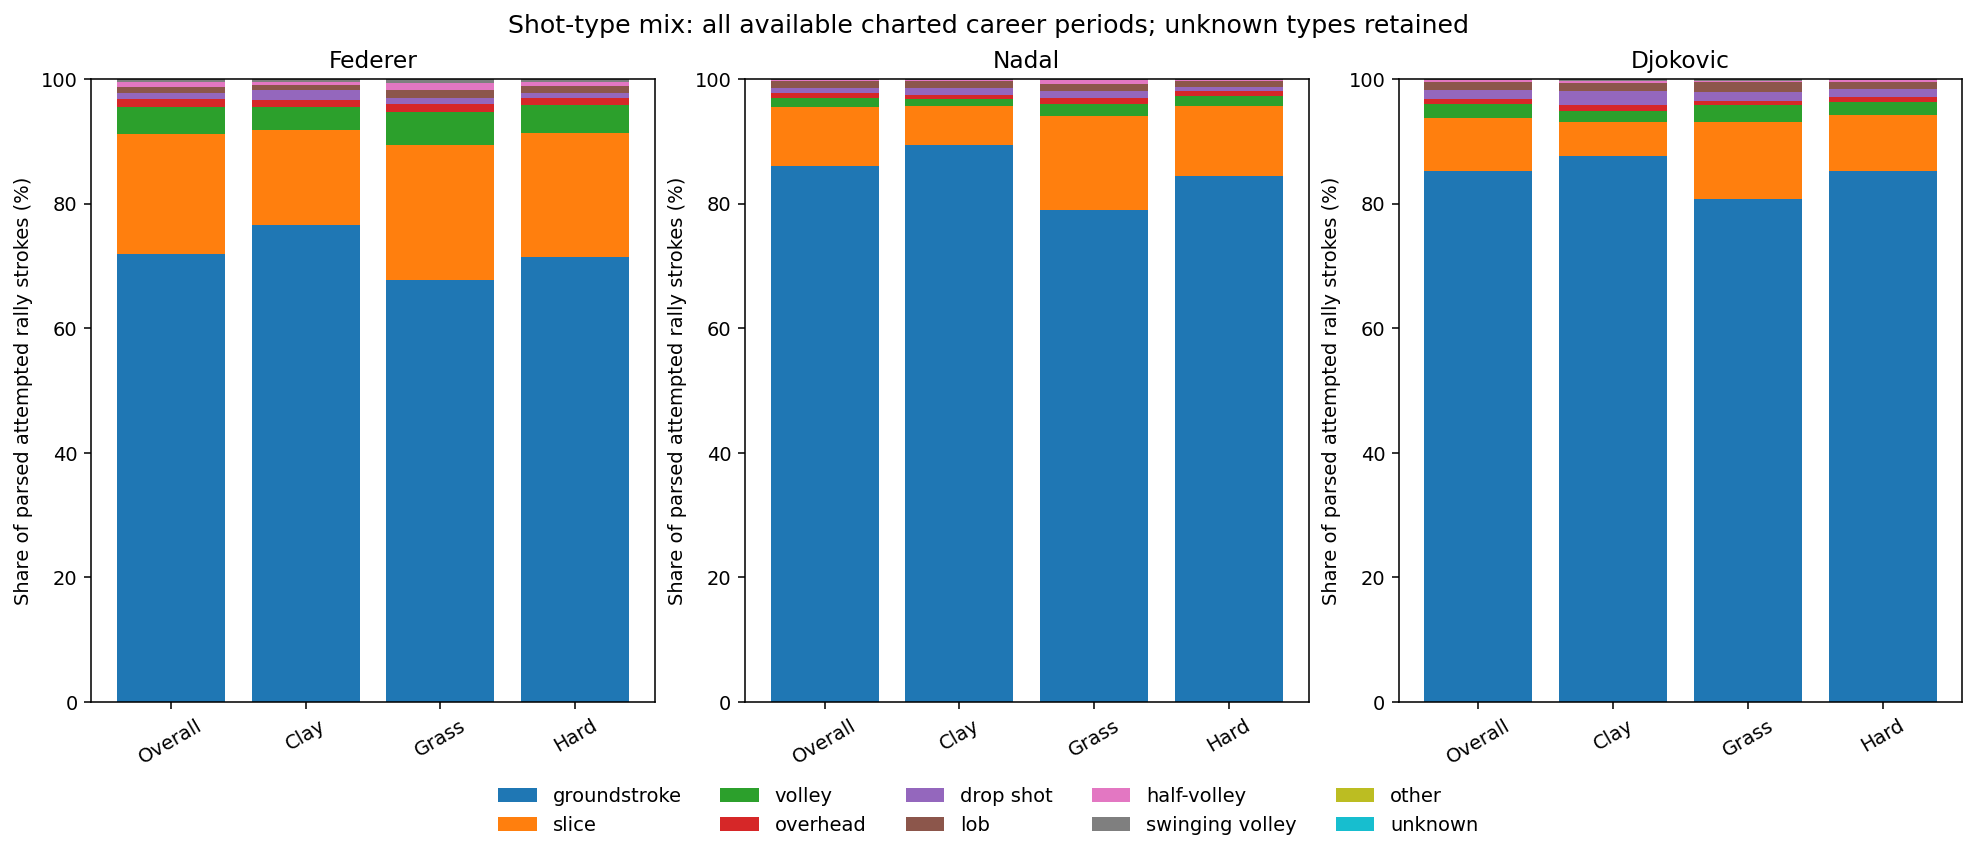

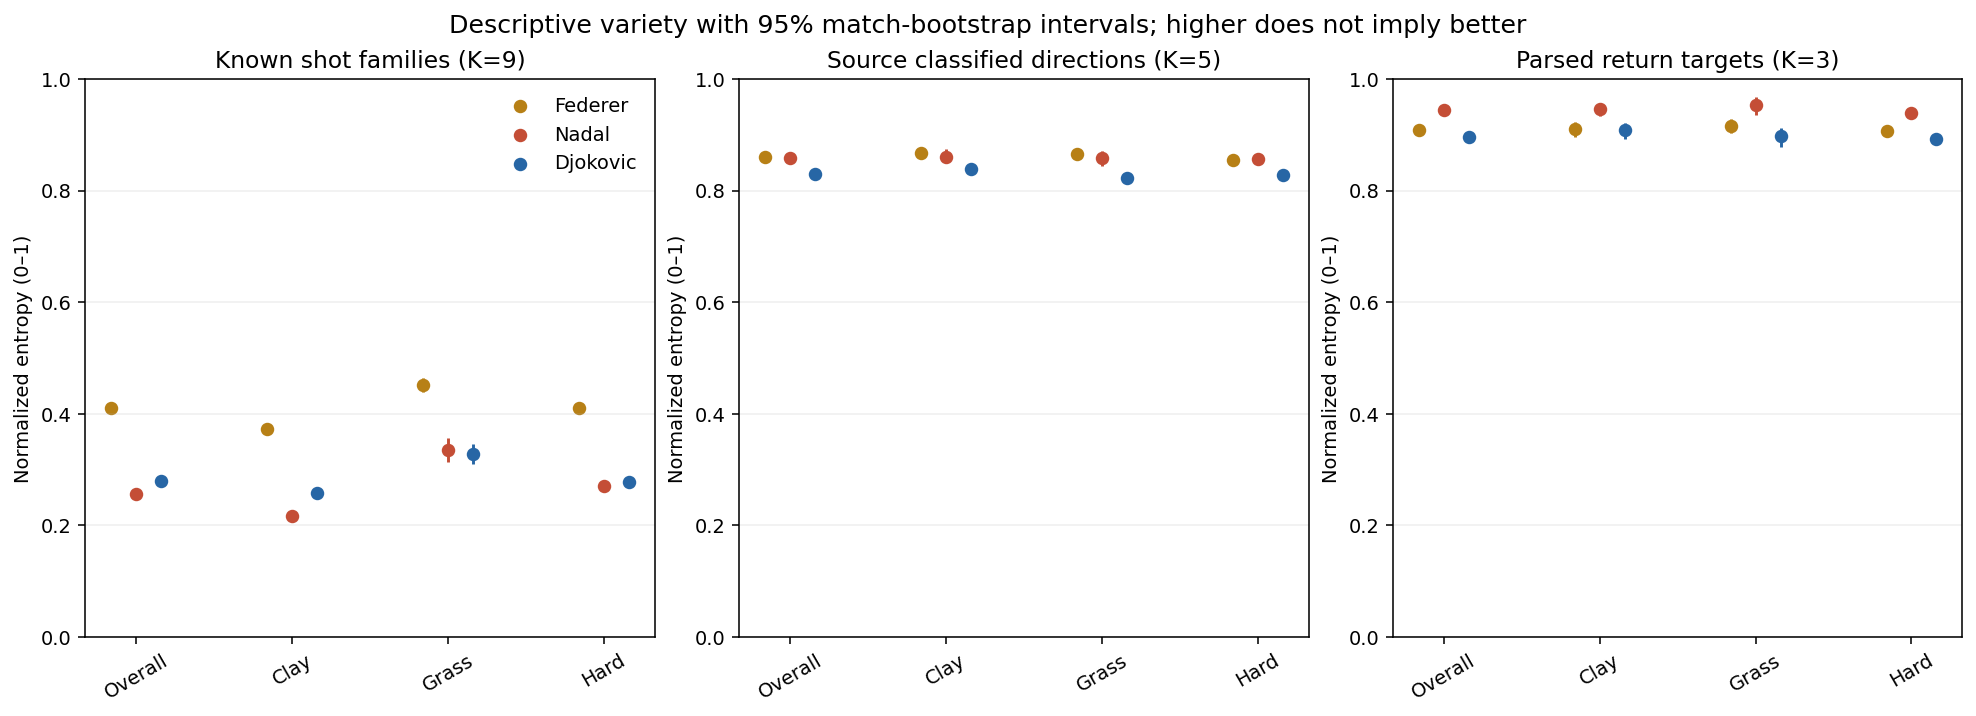

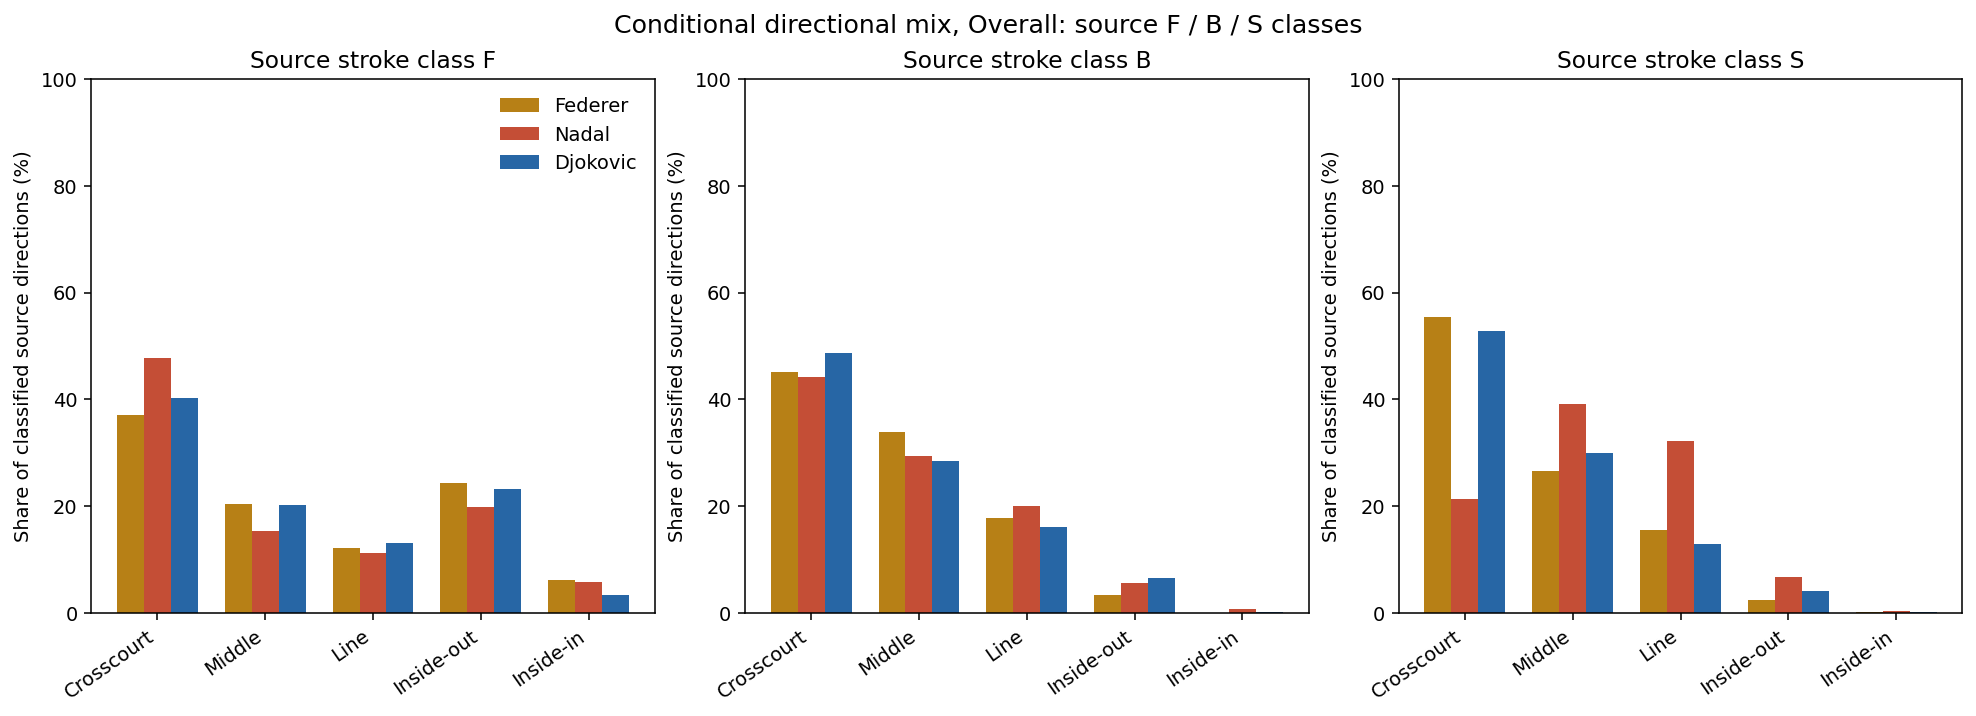

In [17]:
def get_shot_distribution(player, surface, distribution, categories):
    return shot_distribution_long.loc[shot_distribution_long["player"].eq(player)
        & shot_distribution_long["surface"].eq(surface) & shot_distribution_long["distribution"].eq(distribution)].set_index("category").reindex(categories)

with plt.style.context("default"):
    family_colors = plt.get_cmap("tab20")(np.linspace(0, .9, len(SHOT_ALL_FAMILIES)))
    fig, axes = plt.subplots(1, 3, figsize=(14, 6), constrained_layout=True)
    for ax, player in zip(axes, BIG_THREE):
        bottom = np.zeros(4)
        for family, color in zip(SHOT_ALL_FAMILIES, family_colors):
            values = [get_shot_distribution(player, scope, "shot_type", SHOT_ALL_FAMILIES).loc[family, "share_pct"] for scope in ["Overall"] + PROJECT_SURFACES]
            ax.bar(range(4), values, bottom=bottom, label=family, color=color)
            bottom += np.nan_to_num(values)
        ax.set_xticks(range(4), ["Overall"] + PROJECT_SURFACES, rotation=30)
        ax.set_ylim(0, 100)
        ax.set_title(KPI_SHORT_NAMES[player])
        ax.set_ylabel("Share of parsed attempted rally strokes (%)")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside lower center", ncol=5, frameon=False)
    fig.suptitle("Shot-type mix: all available charted career periods; unknown types retained", fontsize=13)
    display_kpi_figure(fig)

    fig, axes = plt.subplots(1, 3, figsize=(14, 5), constrained_layout=True)
    for ax, distribution, title in zip(axes,
        ["shot_type", "source_direction_Total", "target_returns"],
        ["Known shot families (K=9)", "Source classified directions (K=5)", "Parsed return targets (K=3)"]):
        for index, player in enumerate(BIG_THREE):
            rows = shot_diversity_summary.loc[shot_diversity_summary["player"].eq(player)
                & shot_diversity_summary["distribution"].eq(distribution)].set_index("surface").reindex(["Overall"]+PROJECT_SURFACES)
            x = np.arange(4) + (index-1)*.16
            ax.scatter(x, rows["normalized_entropy"], color=KPI_PLAYER_COLORS[player], label=KPI_SHORT_NAMES[player], s=35)
            for xpos, (_, row) in zip(x, rows.iterrows()):
                ax.vlines(xpos, row["ci95_lower"], row["ci95_upper"], color=KPI_PLAYER_COLORS[player])
        ax.set_xticks(range(4), ["Overall"]+PROJECT_SURFACES, rotation=30)
        ax.set_ylim(0, 1)
        ax.set_title(title)
        ax.set_ylabel("Normalized entropy (0–1)")
        ax.grid(axis="y", alpha=.2)
    axes[0].legend(frameon=False)
    fig.suptitle("Descriptive variety with 95% match-bootstrap intervals; higher does not imply better", fontsize=13)
    display_kpi_figure(fig)

    fig, axes = plt.subplots(1, 3, figsize=(14, 5), constrained_layout=True)
    for ax, stroke_class in zip(axes, ["F", "B", "S"]):
        for index, player in enumerate(BIG_THREE):
            data = get_shot_distribution(player, "Overall", "source_direction_"+stroke_class, SOURCE_DIRECTION_CATEGORIES)
            ax.bar(np.arange(5)+(index-1)*.25, data["share_pct"], width=.25, color=KPI_PLAYER_COLORS[player], label=KPI_SHORT_NAMES[player])
        ax.set_xticks(range(5), ["Crosscourt", "Middle", "Line", "Inside-out", "Inside-in"], rotation=35, ha="right")
        ax.set_ylim(0, 100)
        ax.set_title("Source stroke class " + stroke_class)
        ax.set_ylabel("Share of classified source directions (%)")
    axes[0].legend(frameon=False)
    fig.suptitle("Conditional directional mix, Overall: source F / B / S classes", fontsize=13)
    display_kpi_figure(fig)


### 7.3 Court-zone illustrations, not ball tracking
The first court grid displays **baseline-direction shares** for all parsed attempted rally strokes. It places categorical color strips at the opponent baseline to emphasize the workbook's baseline-crossing definition; it does not estimate bounce depth, shot origins, player movement, or tracking coordinates. Code 1 is the opponent's right side (left of the page), code 2 center, and code 3 the opponent's left. Nadal's left-handedness does not reverse these target labels. Shot-type and target-side shares cannot identify crosscourt forehands without the appropriate directional classification.

The second heatmap shows the joint categories for **return attempts with both recorded depth and direction**. Depth 7 means service-box depth, 8 the nearer half between service line and baseline, and 9 the deeper half. Unknown depth is excluded with its coverage reported; it is never projected to the baseline. Joint cells sum to 100% within each panel. These are categorical code combinations, not precise landing coordinates. Error attempts may indicate intended/coded targets rather than successful landings. No KDE, synthetic jitter, or inferred origin positions are used.

Active-point serve placement uses the selected first or second serve, including coded second-serve faults, and classifies deuce/ad × wide/body/T where score parity and direction are known. It excludes first-serve faults that precede a second serve from this particular denominator; it is not the distribution of every serve attempt. Unknown direction, missing sequence, and no-ad court choice reduce classification coverage.

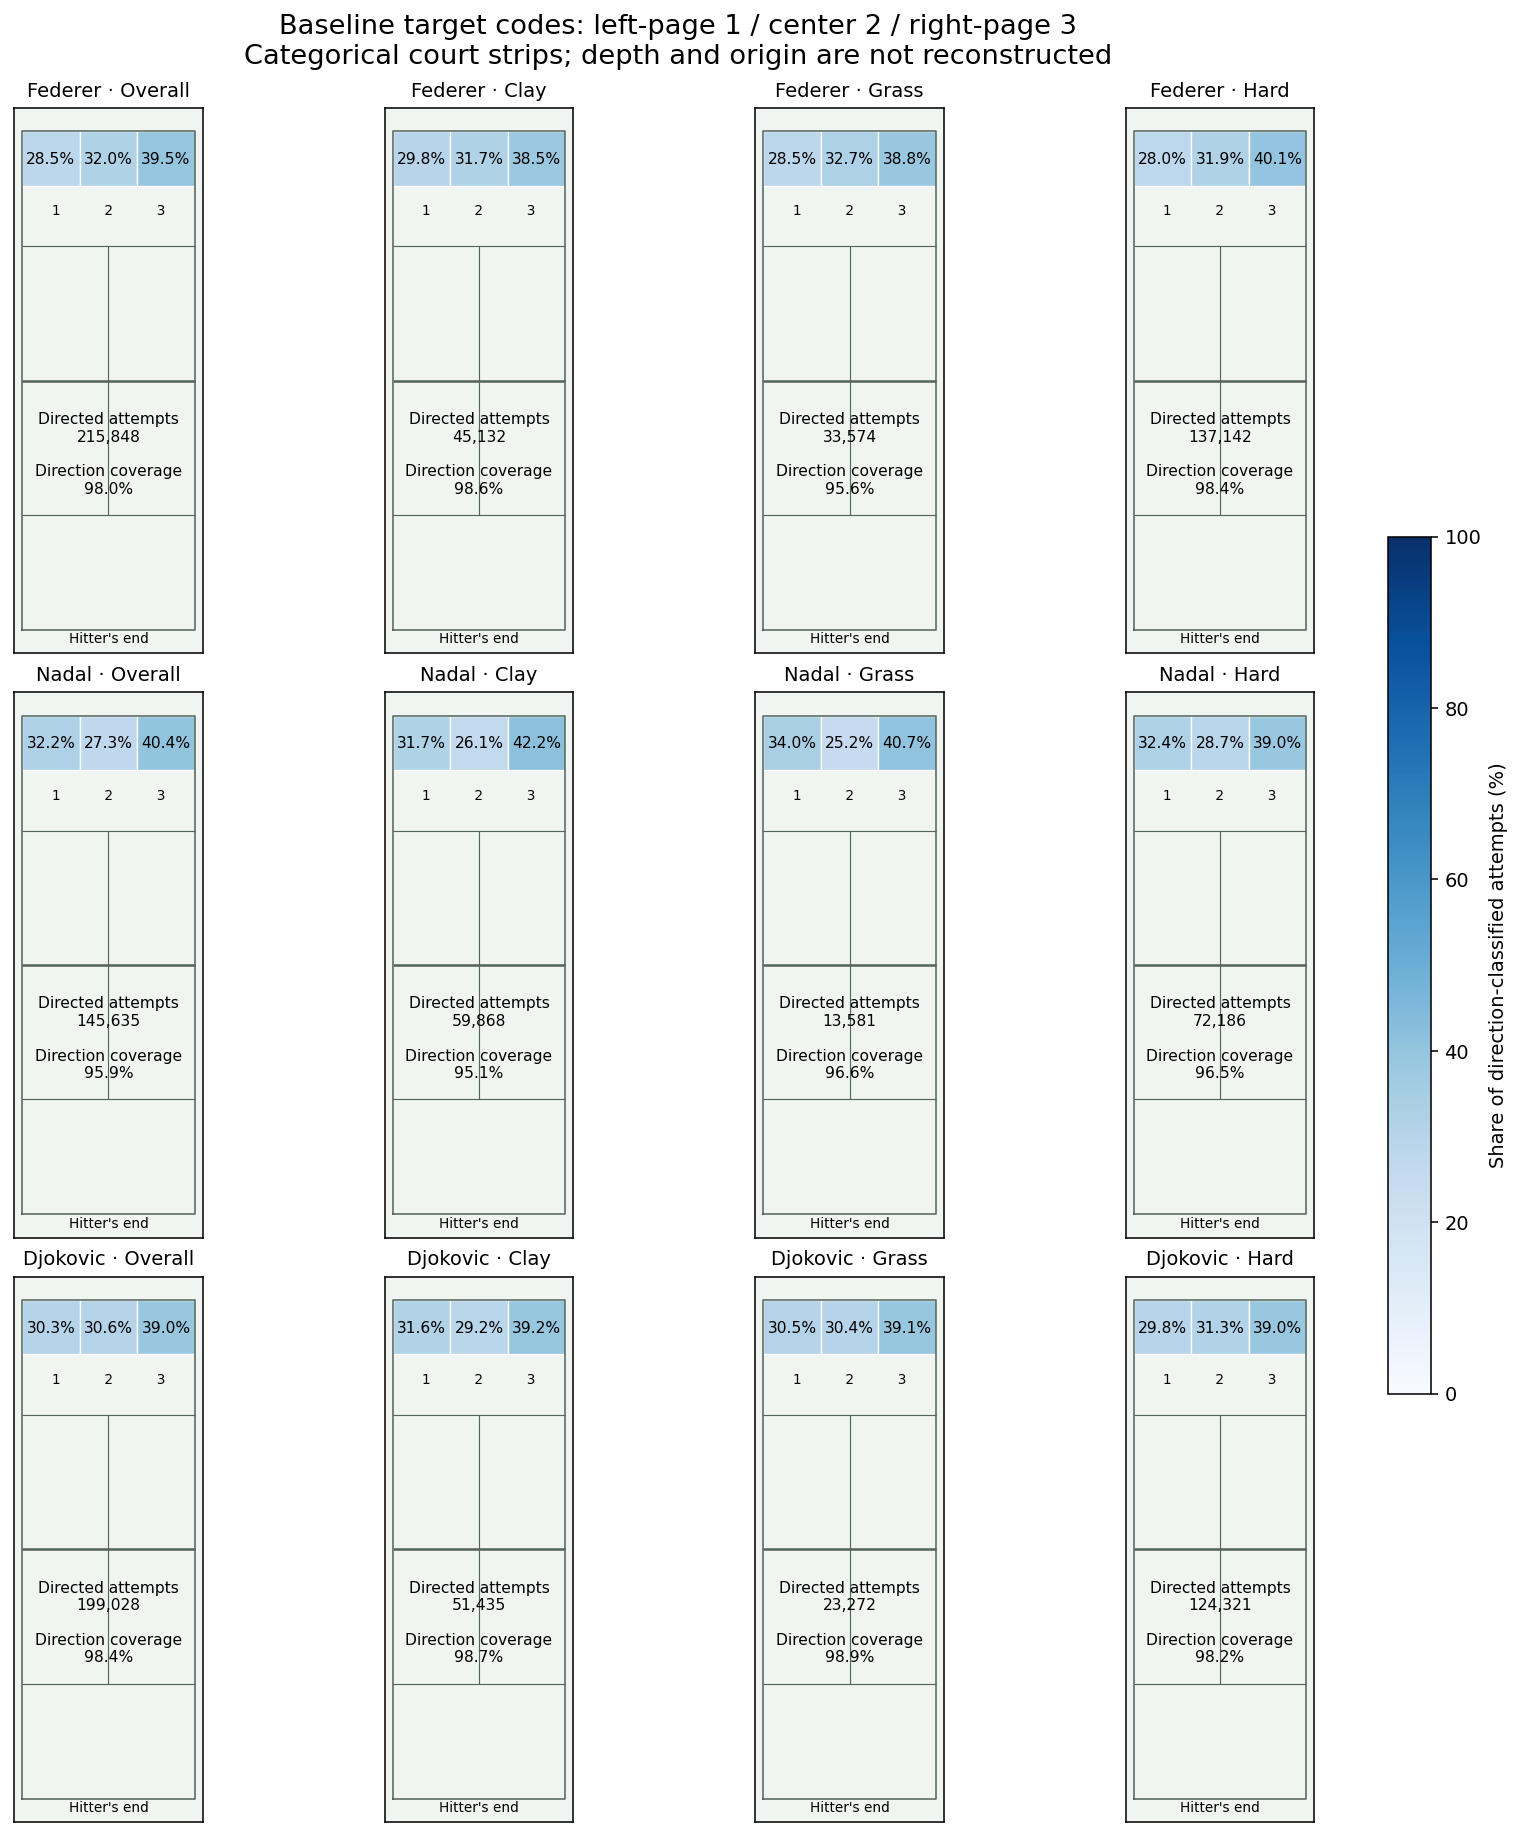

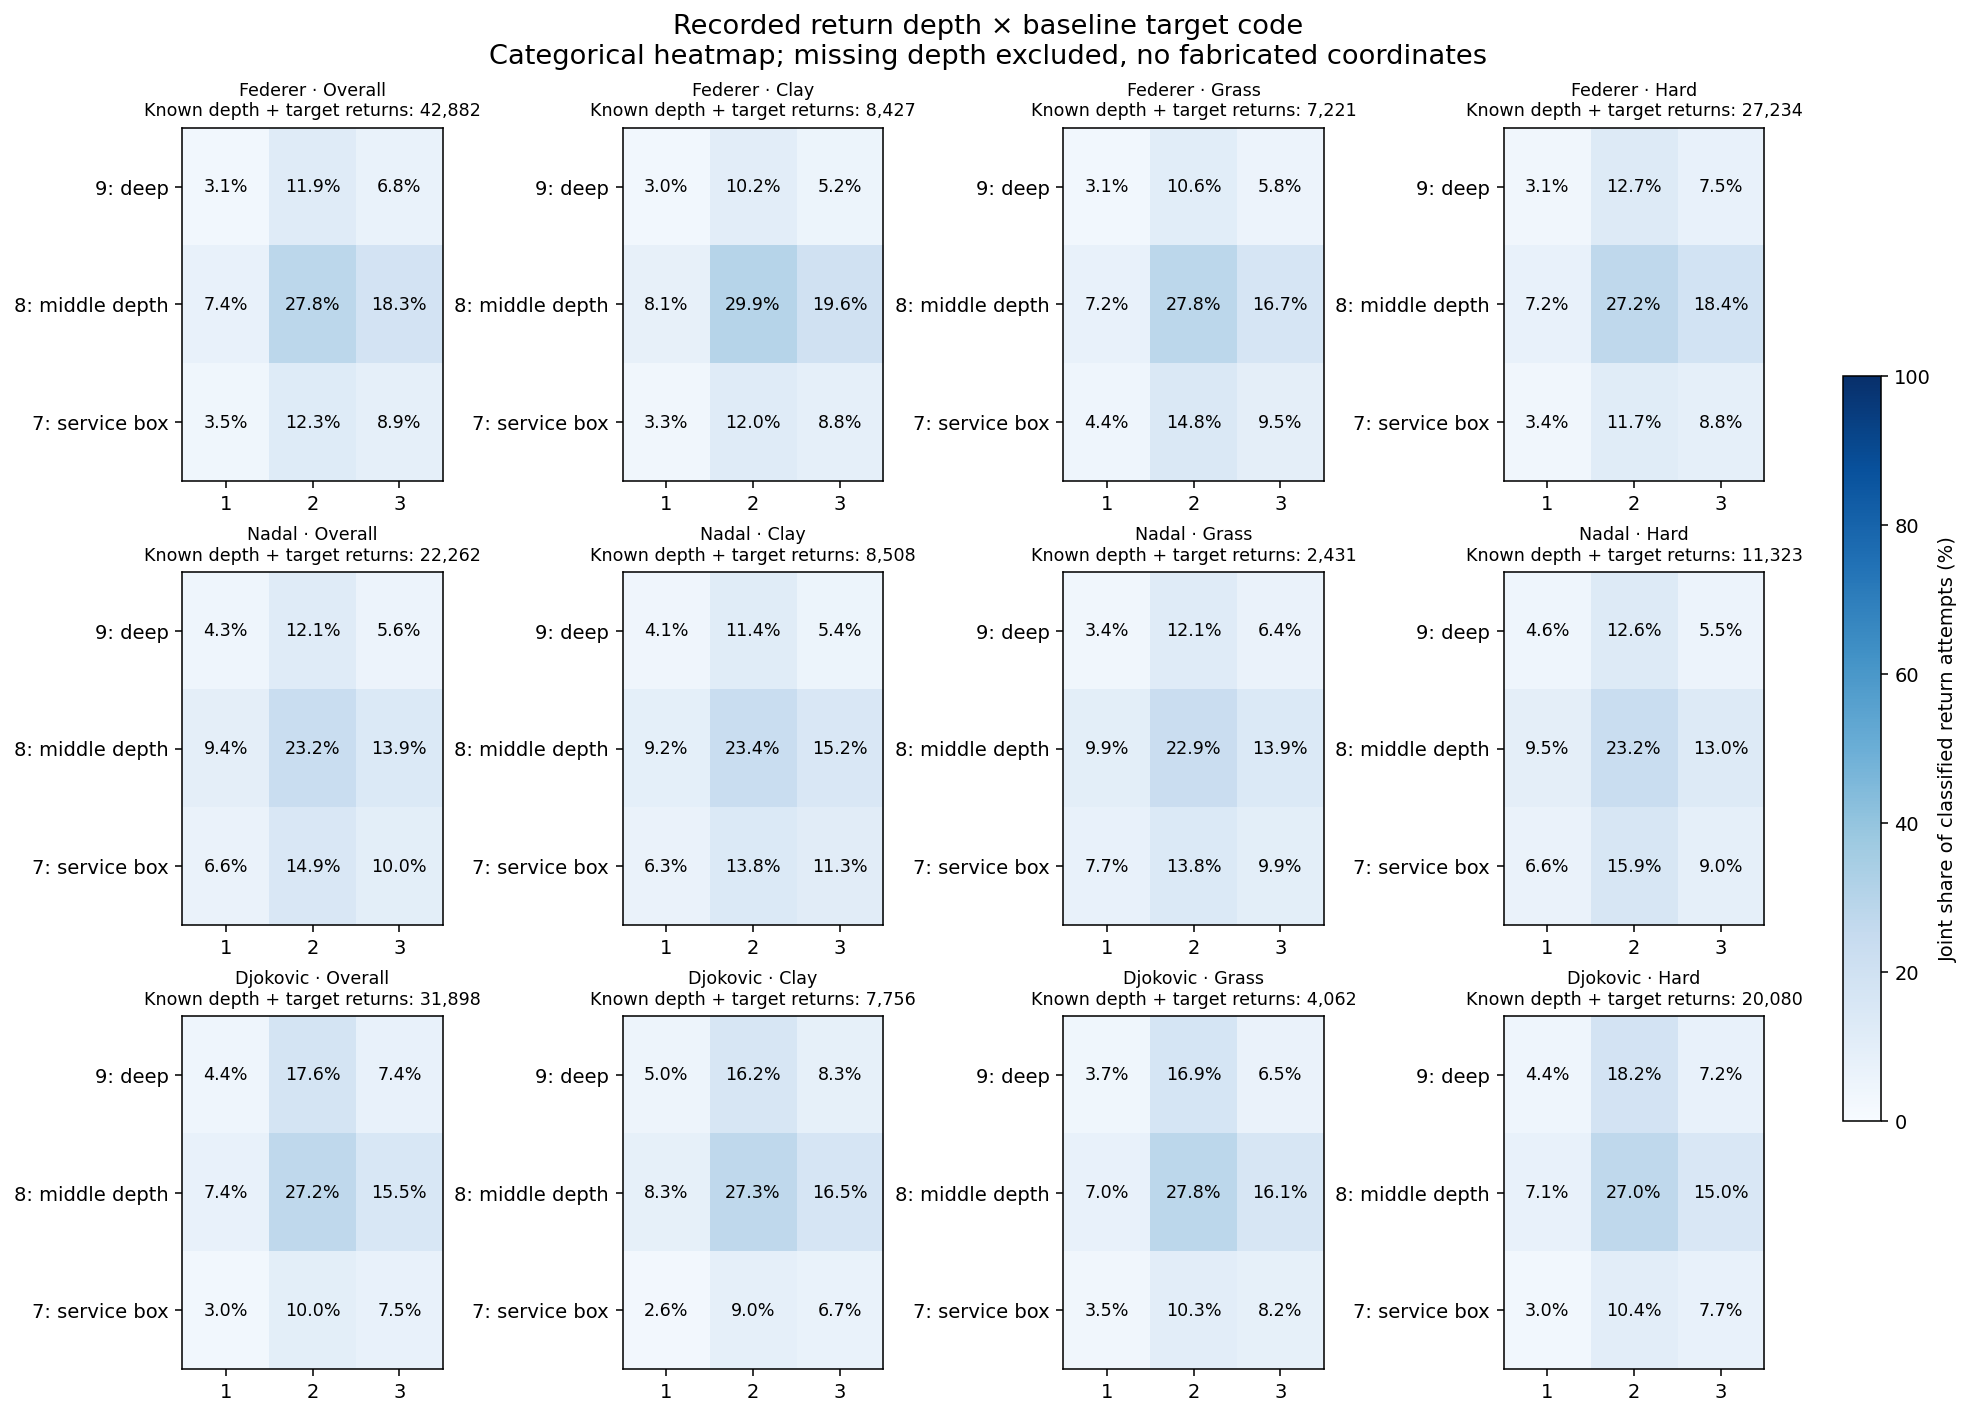

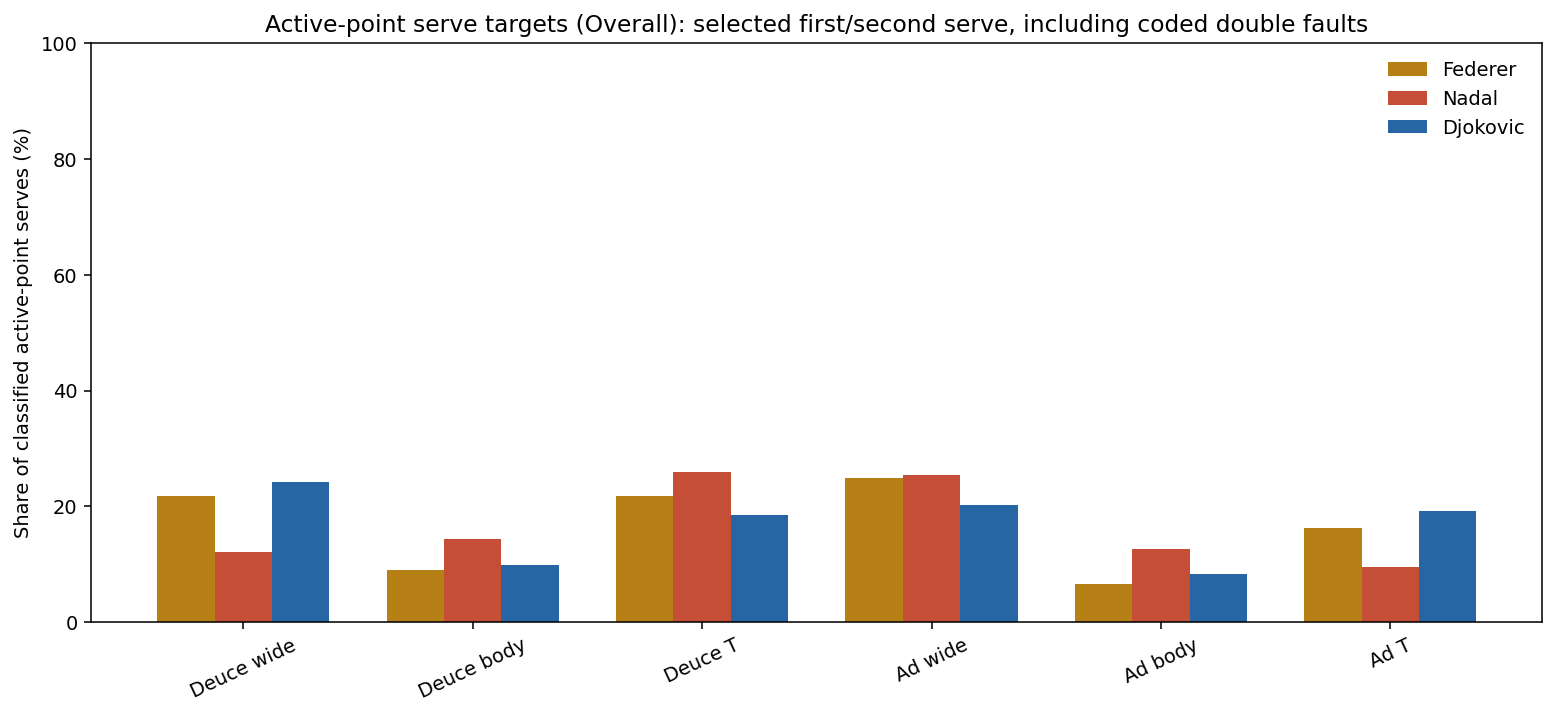

In [18]:
def draw_reference_court(ax):
    # Regulation singles reference geometry, in metres; no measured positions are implied.
    half_width, baseline, service = 4.115, 11.885, 6.4
    ax.set_facecolor("#f1f5f2")
    ax.plot([-half_width, half_width, half_width, -half_width, -half_width],
            [-baseline, -baseline, baseline, baseline, -baseline], color="#53645a", linewidth=.8)
    ax.hlines([-service, 0, service], -half_width, half_width, color="#53645a", linewidth=[.6, 1.3, .6])
    ax.vlines(0, -service, service, color="#53645a", linewidth=.6)
    ax.set_xlim(-4.5, 4.5)
    ax.set_ylim(-13, 13)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.text(0, -12.5, "Hitter's end", ha="center", fontsize=7)

with plt.style.context("default"):
    cmap = plt.get_cmap("Blues")
    norm = plt.Normalize(0, 100)
    fig, axes = plt.subplots(3, 4, figsize=(12, 13), constrained_layout=True)
    for row_index, player in enumerate(BIG_THREE):
        for column, scope in enumerate(["Overall"]+PROJECT_SURFACES):
            ax = axes[row_index, column]
            draw_reference_court(ax)
            data = get_shot_distribution(player, scope, "target_all_attempts", TARGET_CATEGORIES)
            for index, category in enumerate(TARGET_CATEGORIES):
                value = data.loc[category, "share_pct"]
                left = -4.115 + index*(8.23/3)
                ax.add_patch(plt.Rectangle((left, 9.3), 8.23/3, 2.585, facecolor=cmap(norm(value)) if pd.notna(value) else "lightgray", edgecolor="white", linewidth=.7))
                ax.text(left+8.23/6, 10.55, f"{value:.1f}%" if pd.notna(value) else "n/a", ha="center", va="center", fontsize=8, color="white" if value > 55 else "black")
            coverage = shot_coverage_summary.loc[shot_coverage_summary["player"].eq(player) & shot_coverage_summary["surface"].eq(scope)].iloc[0]
            ax.text(0, 7.9, "1          2          3", ha="center", fontsize=7)
            ax.text(0, -3.5, f"Directed attempts\n{int(coverage['classified_targets']):,}\n\nDirection coverage\n{coverage['target_direction_coverage_pct']:.1f}%", ha="center", va="center", fontsize=8)
            ax.set_title(KPI_SHORT_NAMES[player]+" · "+scope, fontsize=10)
    fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes, shrink=.5, label="Share of direction-classified attempts (%)")
    fig.suptitle("Baseline target codes: left-page 1 / center 2 / right-page 3\nCategorical court strips; depth and origin are not reconstructed", fontsize=14)
    display_kpi_figure(fig)

    fig, axes = plt.subplots(3, 4, figsize=(14, 10), constrained_layout=True)
    for row_index, player in enumerate(BIG_THREE):
        for column, scope in enumerate(["Overall"]+PROJECT_SURFACES):
            ax = axes[row_index, column]
            data = get_shot_distribution(player, scope, "return_depth_target", RETURN_JOINT_CATEGORIES)
            matrix = data["share_pct"].to_numpy().reshape(3, 3)
            ax.imshow(matrix, origin="lower", vmin=0, vmax=100, cmap="Blues", aspect="auto")
            for y in range(3):
                for x in range(3):
                    value = matrix[y, x]
                    ax.text(x, y, f"{value:.1f}%" if pd.notna(value) else "n/a", ha="center", va="center", fontsize=9, color="white" if value > 55 else "black")
            ax.set_xticks(range(3), ["1", "2", "3"])
            ax.set_yticks(range(3), ["7: service box", "8: middle depth", "9: deep"])
            n = int(data["classified_denominator"].iloc[0])
            ax.set_title(KPI_SHORT_NAMES[player]+" · "+scope+f"\nKnown depth + target returns: {n:,}", fontsize=9)
    fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes, shrink=.6, label="Joint share of classified return attempts (%)")
    fig.suptitle("Recorded return depth × baseline target code\nCategorical heatmap; missing depth excluded, no fabricated coordinates", fontsize=14)
    display_kpi_figure(fig)

    fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
    for index, player in enumerate(BIG_THREE):
        data = get_shot_distribution(player, "Overall", "active_serve_target", SERVE_ZONE_CATEGORIES)
        ax.bar(np.arange(6)+(index-1)*.25, data["share_pct"], width=.25, color=KPI_PLAYER_COLORS[player], label=KPI_SHORT_NAMES[player])
    ax.set_xticks(range(6), ["Deuce wide", "Deuce body", "Deuce T", "Ad wide", "Ad body", "Ad T"], rotation=25)
    ax.set_ylabel("Share of classified active-point serves (%)")
    ax.set_ylim(0, 100)
    ax.legend(frameon=False)
    ax.set_title("Active-point serve targets (Overall): selected first/second serve, including coded double faults")
    display_kpi_figure(fig)


### 7.4 Interpretation and limitations
The tables distinguish stroke family, source-defined direction, return target, return depth, and active serve placement. Entropy is descriptive: a reliable repeated crosscourt pattern may be more effective than a varied but unsuccessful pattern. Stroke-type diversity does not measure athleticism, invention, or match-winning ability. Differences may reflect opponents, career periods, surfaces, error rates, and charting coverage. Conditional F/B/S and return tables help explain aggregates without manufacturing shot combinations absent from the sources.

`shot_distribution_long`, `shot_diversity_summary`, and `shot_coverage_summary` are the authoritative tabular outputs. The court illustrations use observed categorical percentages, common color scales, and disclosed denominators. No inferred origins or synthetic KDE coordinates are used. Section VIII uses these frequencies for tactical evolution; Section IX treats style and preference scoring as separate questions.

<a id="adaptability"></a>

## VIII. Surface adaptability and tactical evolution

**Evolution question:** How balanced are observed results across surfaces, and which tactical frequencies change over supported career periods? Cross-surface success and within-career tactical change answer separate questions.


### 8.1 Primary adaptability definition and sensitivity
Use known match outcomes from each player's entire available charted career on Clay, Grass, and Hard. Let p be the pooled win rate in this three-surface universe and p_s the rate on surface s. **Parity = 100 × [1 − sqrt(mean_s((p_s − p)²))]**. **SAS = 0.60 × parity + 0.40 × [100 × min_s(p_s)]**. Require evidence on all three surfaces; a score for an individual surface would not measure cross-surface adaptability. Unknown outcomes remain excluded and counted separately.

Parity rewards consistency, including consistency at modest win rates. The weakest-surface component adds winning strength. The 60/40 weights are a declared preference, not a learned truth. Report sensitivity over parity weights from 0 to 1 and an alternative equal-surface anchor for p to expose dependence on surface scheduling. The primary definition remains unchanged. Joint match bootstraps recompute all surface rates, parity, weakest rate, and SAS; the weakest surface can change in a replicate. Small-sample flags apply when any surface has fewer than 30 known-outcome matches. Intervals condition on charted selection and verified outcomes.


In [19]:
adaptability_rows, adaptability_bootstraps, adaptability_weight_rows = [], {}, []
for player in BIG_THREE:
    group = kpi_master.loc[kpi_master["player"].eq(player) & kpi_master["surface"].isin(PROJECT_SURFACES)]
    point_counts = []
    vectors = []
    for surface in PROJECT_SURFACES:
        sample = group.loc[group["surface"].eq(surface) & group["winner"].notna()]
        point_counts.append([int(sample["is_win"].sum()), len(sample)])
        for value_field in ["verified_win_count", "known_outcome"]:
            vector = np.zeros(len(bootstrap_match_ids))
            for mid, value in sample[["match_id", value_field]].itertuples(index=False, name=None):
                vector[bootstrap_match_index[mid]] = value
            vectors.append(vector)
    counts = np.array(point_counts, dtype=float)
    totals = bootstrap_weights @ np.column_stack(vectors)
    with np.errstate(divide="ignore", invalid="ignore"):
        surface_rates = counts[:, 0] / counts[:, 1]
        boot_rates = totals[:, [0, 2, 4]] / totals[:, [1, 3, 5]]
        overall_rate = counts[:, 0].sum() / counts[:, 1].sum()
        boot_overall = totals[:, [0, 2, 4]].sum(axis=1) / totals[:, [1, 3, 5]].sum(axis=1)
        parity = 100 * (1 - np.sqrt(np.mean((surface_rates - overall_rate)**2)))
        boot_parity = 100 * (1 - np.sqrt(np.mean((boot_rates - boot_overall[:, None])**2, axis=1)))
        weakest_rate_pct = 100 * np.min(surface_rates)
        boot_weakest = 100 * np.min(boot_rates, axis=1)
        score = .6 * parity + .4 * weakest_rate_pct
        boot_score = .6 * boot_parity + .4 * boot_weakest
        alternate_parity = 100 * (1 - np.sqrt(np.mean((surface_rates - surface_rates.mean())**2)))
    row = {"player": player, "known_outcome_matches": int(counts[:, 1].sum()),
        "unknown_outcome_matches": int(group["winner"].isna().sum()), "win_rate_overall_pct": 100*overall_rate,
        "parity_score": parity, "weakest_surface_win_pct": weakest_rate_pct,
        "weakest_surface": ", ".join(s for s, rate in zip(PROJECT_SURFACES, surface_rates) if np.isclose(rate, surface_rates.min())) if np.isfinite(surface_rates).all() else "Unavailable",
        "surface_adaptability_score": score, "equal_surface_anchor_sas_sensitivity": .6*alternate_parity + .4*weakest_rate_pct,
        "small_surface_sample": bool(np.any(counts[:, 1] < SMALL_SAMPLE_THRESHOLDS["matches"]))}
    for surface, count, rate in zip(PROJECT_SURFACES, counts, surface_rates):
        row[surface + "_known_matches"] = int(count[1])
        row[surface + "_wins"] = int(count[0])
        row[surface + "_win_pct"] = 100*rate
    for name, values in [("parity_score", boot_parity), ("weakest_surface_win_pct", boot_weakest), ("surface_adaptability_score", boot_score)]:
        valid = values[np.isfinite(values)]
        row[name + "_valid_bootstraps"] = len(valid)
        row[name + "_ci95_lower"] = np.percentile(valid, 2.5) if len(valid) >= .95*BOOTSTRAP_REPLICATES else np.nan
        row[name + "_ci95_upper"] = np.percentile(valid, 97.5) if len(valid) >= .95*BOOTSTRAP_REPLICATES else np.nan
    adaptability_rows.append(row)
    adaptability_bootstraps[player] = {"surface_rates": boot_rates, "parity": boot_parity, "weakest_rate_pct": boot_weakest, "sas": boot_score}
    for parity_weight in np.linspace(0, 1, 11):
        adaptability_weight_rows.append({"player": player, "parity_weight": parity_weight,
            "weakest_surface_weight": 1-parity_weight, "score": parity_weight*parity+(1-parity_weight)*weakest_rate_pct})
surface_adaptability_summary_v2 = pd.DataFrame(adaptability_rows)
surface_adaptability_weight_sensitivity = pd.DataFrame(adaptability_weight_rows)
surface_adaptability_weight_sensitivity["rank_within_weight"] = surface_adaptability_weight_sensitivity.groupby("parity_weight")["score"].rank(ascending=False, method="min")
assert surface_adaptability_summary_v2["surface_adaptability_score"].dropna().between(0, 100).all()
assert surface_adaptability_summary_v2["parity_score"].dropna().between(0, 100).all()
for player in BIG_THREE:
    row = surface_adaptability_summary_v2.loc[surface_adaptability_summary_v2["player"].eq(player)].iloc[0]
    source = core_kpi_by_surface.loc[core_kpi_by_surface["player"].eq(player)].set_index("surface")
    for surface in PROJECT_SURFACES:
        assert row[surface+"_known_matches"] == source.loc[surface, "known_outcome_matches"]
        assert np.isclose(row[surface+"_win_pct"], source.loc[surface, "match_win_pct"])
    assert np.isclose(row["surface_adaptability_score"], .6*row["parity_score"]+.4*row["weakest_surface_win_pct"])
print("Primary surface adaptability, evidence rates, and uncertainty:")
with pd.option_context("display.max_columns", None):
    report_table(surface_adaptability_summary_v2.round(4))
print("Weight sensitivity; descriptive score ranks are conditional on the definition:")
with pd.option_context("display.max_rows", None):
    report_table(surface_adaptability_weight_sensitivity.round(4))


Primary surface adaptability, evidence rates, and uncertainty:


player,known_outcome_matches,unknown_outcome_matches,win_rate_overall_pct,parity_score,weakest_surface_win_pct,weakest_surface,surface_adaptability_score,equal_surface_anchor_sas_sensitivity,small_surface_sample,Clay_known_matches,Clay_wins,Clay_win_pct,Grass_known_matches,Grass_wins,Grass_win_pct,Hard_known_matches,Hard_wins,Hard_win_pct,parity_score_valid_bootstraps,parity_score_ci95_lower,parity_score_ci95_upper,weakest_surface_win_pct_valid_bootstraps,weakest_surface_win_pct_ci95_lower,weakest_surface_win_pct_ci95_upper,surface_adaptability_score_valid_bootstraps,surface_adaptability_score_ci95_lower,surface_adaptability_score_ci95_upper
Roger Federer,709,14,78.843,93.652,69.048,Clay,83.810,83.877,False,126,87,69.048,116,97,83.621,467,375,80.300,2000,89.161,97.433,2000,60.869,76.787,2000,77.811,88.900
Rafael Nadal,412,13,72.330,88.822,59.459,Grass,77.077,77.263,False,164,139,84.756,37,22,59.459,211,137,64.929,2000,81.609,93.377,2000,43.583,68.185,2000,66.502,83.046
Novak Djokovic,526,27,76.806,95.850,70.161,Clay,85.575,85.638,False,124,87,70.161,56,44,78.571,346,273,78.902,2000,90.474,98.699,2000,61.817,76.745,2000,79.299,89.564


Weight sensitivity; descriptive score ranks are conditional on the definition:


player,parity_weight,weakest_surface_weight,score,rank_within_weight
Roger Federer,0.000,1.000,69.048,2.000
Roger Federer,0.100,0.900,71.508,2.000
Roger Federer,0.200,0.800,73.968,2.000
Roger Federer,0.300,0.700,76.429,2.000
Roger Federer,0.400,0.600,78.889,2.000
Roger Federer,0.500,0.500,81.350,2.000
Roger Federer,0.600,0.400,83.810,2.000
Roger Federer,0.700,0.300,86.270,2.000
Roger Federer,0.800,0.200,88.731,2.000
Roger Federer,0.900,0.100,91.191,2.000


### 8.2 Prespecified career windows and tactical inputs
Use **four-calendar-year bins anchored to each player's first charted year**, with the final bin truncated to the last available year. Boundaries use coverage only, not observed tactical changes. The first and last periods are coverage edges, not evidence of a professional debut, retirement date, or a complete calendar period. Show every period, including small samples and unavailable surfaces; do not carry forward missing values or force common career dates.

Approach and NetPoints frequencies use their distinct source slices divided by source-matched service plus return points. Serve-and-volley frequency uses the SnV numerator and service points: a missing SnV row becomes zero **only when the nonSnV complement equals all source service points**. Missing counts can also be recovered from explicit serve-prefix `+` codes when the coded service-point total reconciles to Overview; an absent `+` on a fully coded serve is a genuine non-SnV observation. Source/code disagreements are flagged and excluded. Otherwise missing counts stay unavailable; present rows must reconcile complements or the independently coded serve points. Parsed drop-shot and slice shares use known stroke families, with attempted error strokes included. Rally shares use known rally lengths of at least one shot (serve included, ending error excluded), excluding double faults and entirely uncharted sequences. Serve target shares are conditional on a known court and direction and are calculated separately within deuce and ad courts.

For each metric, show the raw pooled period rate and within-surface rates. A separate **equal-surface standardized** series averages the three surface rates with fixed 1/3 weights, only when all three are available. It does not extrapolate missing grass data. Percentage-point contrasts compare the first and last periods with a supported standardized estimate, identifying the endpoints explicitly; they may exclude career-edge periods without three-surface support. Counts and small-sample flags remain visible, and wide intervals are not evidence of stability. Evolution measures change, not invention, improvement, or influence on tennis.

Endpoint-change intervals are exploratory, unadjusted 95% intervals across multiple tactical measures; they are not a family of confirmatory significance tests.

In [20]:
TACTICAL_PERIOD_YEARS = 4
period_plan_rows = []
for player in BIG_THREE:
    dates = canonical_master.loc[canonical_master["player"].eq(player), "match_date"]
    first_year, last_year = int(dates.min().year), int(dates.max().year)
    for index, start in enumerate(range(first_year, last_year+1, TACTICAL_PERIOD_YEARS)):
        end = min(start+TACTICAL_PERIOD_YEARS-1, last_year)
        sample = canonical_master.loc[canonical_master["player"].eq(player) & canonical_master["match_date"].dt.year.between(start, end)]
        period_plan_rows.append({"player": player, "period_index": index, "period": f"{start}–{end}", "start_year": start,
            "end_year": end, "nominal_years": TACTICAL_PERIOD_YEARS, "coverage_edge": start == first_year or end == last_year,
            "first_charted_date": sample["match_date"].min(), "last_charted_date": sample["match_date"].max(), "charted_matches": len(sample)})
tactical_period_plan = pd.DataFrame(period_plan_rows)
tactical_match_table = kpi_master.copy()
tactical_match_table["period_index"] = [int((date.year - int(tactical_period_plan.loc[tactical_period_plan["player"].eq(player), "start_year"].min())) // TACTICAL_PERIOD_YEARS)
    for player, date in tactical_match_table[["player", "match_date"]].itertuples(index=False, name=None)]
tactical_match_table = tactical_match_table.merge(tactical_period_plan[["player", "period_index", "period", "coverage_edge"]], on=["player", "period_index"], how="left", validate="many_to_one")
tactical_match_table["source_player_points"] = tactical_match_table["serve_pts"] + tactical_match_table["return_pts"]
for slice_name, field in [("Approach", "approach_points"), ("NetPoints", "net_points_all")]:
    source = analysis_dataframes["charting_m_stats_NetPoints"]
    selected = source.loc[source["row"].eq(slice_name), ["match_id", "player", "net_pts"]].rename(columns={"net_pts": field})
    tactical_match_table = tactical_match_table.merge(selected, on=["match_id", "player"], how="left", validate="one_to_one")
for slice_name, field in [("SnV", "snv_points"), ("nonSnV", "non_snv_points")]:
    source = analysis_dataframes["charting_m_stats_SnV"]
    selected = source.loc[source["row"].eq(slice_name), ["match_id", "player", "snv_pts"]].rename(columns={"snv_pts": field})
    tactical_match_table = tactical_match_table.merge(selected, on=["match_id", "player"], how="left", validate="one_to_one")
proven_no_snv = tactical_match_table["snv_points"].isna() & tactical_match_table["non_snv_points"].eq(tactical_match_table["serve_pts"]) & tactical_match_table["serve_pts"].notna()
tactical_match_table["snv_zero_proven_by_complement"] = proven_no_snv
tactical_match_table.loc[proven_no_snv, "snv_points"] = 0
snv_complete = (tactical_match_table["snv_points"].add(tactical_match_table["non_snv_points"]).eq(tactical_match_table["serve_pts"])
    | (tactical_match_table["non_snv_points"].isna() & tactical_match_table["snv_points"].eq(tactical_match_table["serve_pts"])))

# Independently recover SnV from explicit serve-prefix '+' markers, not from missing rows.
def serve_prefix_snv(sequence):
    token = SHOT_TOKEN_PATTERN.search(sequence)
    prefix = sequence[:token.start()] if token else sequence
    return "+" in prefix
snv_point_codes = serve_analysis.loc[serve_analysis["sequence_known"]].copy()
snv_point_codes["snv_from_code"] = snv_point_codes["sequence"].map(serve_prefix_snv).astype(int)
snv_point_codes["coded_service_points"] = 1
snv_code_counts = snv_point_codes.groupby(["match_id", "player"], as_index=False)[["snv_from_code", "coded_service_points"]].sum()
tactical_match_table = tactical_match_table.merge(snv_code_counts, on=["match_id", "player"], how="left", validate="one_to_one")
complete_snv_codes = (tactical_match_table["coded_service_points"].eq(tactical_match_table["serve_pts"])
    & tactical_match_table["serve_pts"].gt(0) & reconciled_mask(["service_points_parsed"]))
source_snv_present = tactical_match_table["snv_points"].notna()
source_snv_code_disagreement = source_snv_present & complete_snv_codes & tactical_match_table["snv_points"].ne(tactical_match_table["snv_from_code"])
snv_code_source_review = tactical_match_table.loc[source_snv_code_disagreement,
    ["match_id", "player", "snv_points", "snv_from_code", "coded_service_points", "serve_pts"]].copy()
recover_snv = ~source_snv_present & complete_snv_codes
tactical_match_table["snv_recovered_from_explicit_codes"] = recover_snv
tactical_match_table.loc[recover_snv, "snv_points"] = tactical_match_table.loc[recover_snv, "snv_from_code"]
snv_complete = ((snv_complete | complete_snv_codes) & ~source_snv_code_disagreement)

shot_counts = shot_analysis.assign(known_family=shot_analysis["shot_family"].ne("unknown").astype(int),
    drop_count=shot_analysis["shot_family"].eq("drop shot").astype(int),
    slice_count=shot_analysis["shot_family"].eq("slice").astype(int)).groupby(["match_id", "player"], as_index=False)[["known_family", "drop_count", "slice_count"]].sum()
tactical_match_table = tactical_match_table.merge(shot_counts, on=["match_id", "player"], how="left", validate="one_to_one")
rallies = canonical_player_points.loc[canonical_player_points["rally_length"].notna() & canonical_player_points["rally_length"].ge(1)].copy()
rallies["known_rallies"] = 1
rallies["short_rallies"] = rallies["rally_length"].le(4).astype(int)
rallies["medium_rallies"] = rallies["rally_length"].between(5, 8).astype(int)
rallies["long_rallies"] = rallies["rally_length"].ge(9).astype(int)
rally_counts = rallies.groupby(["match_id", "player"], as_index=False)[["known_rallies", "short_rallies", "medium_rallies", "long_rallies"]].sum()
tactical_match_table = tactical_match_table.merge(rally_counts, on=["match_id", "player"], how="left", validate="one_to_one")
for court in ["deuce", "ad"]:
    serves = serve_analysis.loc[serve_analysis["service_court"].eq(court) & serve_analysis["target_category"].notna()].copy()
    serves[court+"_classified_serves"] = 1
    for code, name in [(4, "wide"), (5, "body"), (6, "t")]:
        serves[court+"_"+name+"_serves"] = serves["serve_direction_code"].eq(code).astype(int)
    fields = [court+"_classified_serves"] + [court+"_"+name+"_serves" for name in ["wide", "body", "t"]]
    tactical_match_table = tactical_match_table.merge(serves.groupby(["match_id", "player"], as_index=False)[fields].sum(), on=["match_id", "player"], how="left", validate="one_to_one")
assert list(tactical_match_table[["match_id", "player"]].itertuples(index=False, name=None)) == kpi_pairs

tactical_metric_specs = {
    "approach_frequency_pct": ("approach_points", "source_player_points", "points"),
    "net_point_frequency_pct": ("net_points_all", "source_player_points", "points"),
    "serve_volley_frequency_pct": ("snv_points", "serve_pts", "points"),
    "drop_shot_share_pct": ("drop_count", "known_family", "shots"),
    "slice_share_pct": ("slice_count", "known_family", "shots"),
    "short_rally_share_pct": ("short_rallies", "known_rallies", "points"),
    "medium_rally_share_pct": ("medium_rallies", "known_rallies", "points"),
    "long_rally_share_pct": ("long_rallies", "known_rallies", "points"),
}
for court in ["deuce", "ad"]:
    for name in ["wide", "body", "t"]:
        tactical_metric_specs[court+"_"+name+"_serve_share_pct"] = (court+"_"+name+"_serves", court+"_classified_serves", "points")
tactical_masks = {}
for metric, (num, den, basis) in tactical_metric_specs.items():
    a, b = tactical_match_table[num], tactical_match_table[den]
    mask = a.notna() & b.notna() & np.isfinite(a) & np.isfinite(b) & a.ge(0) & b.gt(0) & a.le(b)
    if metric in ["approach_frequency_pct", "net_point_frequency_pct"]:
        mask &= reconciled_mask(["service_points_parsed", "return_points_parsed"])
    if metric == "serve_volley_frequency_pct":
        mask &= snv_complete & reconciled_mask(["service_points_parsed"])
    tactical_masks[metric] = mask

tactical_rows, tactical_rate_bootstraps = [], {}
for plan in tactical_period_plan.itertuples(index=False):
    period_mask = tactical_match_table["player"].eq(plan.player) & tactical_match_table["period_index"].eq(plan.period_index)
    for scope in ["Overall"] + PROJECT_SURFACES:
        group_mask = period_mask if scope == "Overall" else period_mask & tactical_match_table["surface"].eq(scope)
        for metric, (num, den, basis) in tactical_metric_specs.items():
            sample = tactical_match_table.loc[group_mask & tactical_masks[metric]]
            numerator, denominator = sample[num].sum(min_count=1), sample[den].sum(min_count=1)
            vectors = np.zeros((len(bootstrap_match_ids), 2))
            for mid, a, b in sample[["match_id", num, den]].itertuples(index=False, name=None):
                vectors[bootstrap_match_index[mid]] = [a, b]
            totals = bootstrap_weights @ vectors
            with np.errstate(divide="ignore", invalid="ignore"):
                values = np.where(totals[:, 1] > 0, 100*totals[:, 0]/totals[:, 1], np.nan)
            valid = values[np.isfinite(values)]
            tactical_rows.append({"player": plan.player, "period_index": plan.period_index, "period": plan.period,
                "surface": scope, "metric": metric, "numerator": numerator, "denominator": denominator,
                "estimate_pct": 100*numerator/denominator if denominator > 0 else np.nan,
                "contributing_matches": len(sample), "cohort_matches": int(group_mask.sum()),
                "coverage_pct": 100*len(sample)/group_mask.sum() if group_mask.sum() else np.nan,
                "small_sample": len(sample) < SMALL_SAMPLE_THRESHOLDS["matches"] or pd.isna(denominator) or denominator < SMALL_SAMPLE_THRESHOLDS[basis],
                "coverage_edge_period": plan.coverage_edge, "valid_bootstraps": len(valid),
                "ci95_lower": np.percentile(valid, 2.5) if len(valid) >= .95*BOOTSTRAP_REPLICATES else np.nan,
                "ci95_upper": np.percentile(valid, 97.5) if len(valid) >= .95*BOOTSTRAP_REPLICATES else np.nan})
            tactical_rate_bootstraps[(plan.player, plan.period_index, scope, metric)] = values
tactical_evolution_long = pd.DataFrame(tactical_rows)
standardized_rows, standardized_bootstraps = [], {}
for plan in tactical_period_plan.itertuples(index=False):
    for metric in tactical_metric_specs:
        rates = tactical_evolution_long.loc[tactical_evolution_long["player"].eq(plan.player)
            & tactical_evolution_long["period_index"].eq(plan.period_index) & tactical_evolution_long["metric"].eq(metric)].set_index("surface").reindex(PROJECT_SURFACES)
        all_surfaces = rates["estimate_pct"].notna().all()
        boot = np.column_stack([tactical_rate_bootstraps[(plan.player, plan.period_index, s, metric)] for s in PROJECT_SURFACES])
        values = np.mean(boot, axis=1) if all_surfaces else np.full(BOOTSTRAP_REPLICATES, np.nan)
        valid = values[np.isfinite(values)]
        standardized_rows.append({"player": plan.player, "period_index": plan.period_index, "period": plan.period, "metric": metric,
            "standardized_pct": rates["estimate_pct"].mean() if all_surfaces else np.nan,
            "surfaces_available": int(rates["estimate_pct"].notna().sum()), "small_sample": bool(rates["small_sample"].any()),
            "ci95_lower": np.percentile(valid, 2.5) if len(valid) >= .95*BOOTSTRAP_REPLICATES else np.nan,
            "ci95_upper": np.percentile(valid, 97.5) if len(valid) >= .95*BOOTSTRAP_REPLICATES else np.nan,
            "valid_bootstraps": len(valid)})
        standardized_bootstraps[(plan.player, plan.period_index, metric)] = values
tactical_standardized_trends = pd.DataFrame(standardized_rows)
contrast_rows = []
for player in BIG_THREE:
    for metric in tactical_metric_specs:
        available = tactical_standardized_trends.loc[tactical_standardized_trends["player"].eq(player)
            & tactical_standardized_trends["metric"].eq(metric) & tactical_standardized_trends["standardized_pct"].notna()].sort_values("period_index")
        if len(available) < 2:
            contrast_rows.append({"player": player, "metric": metric, "status": "fewer than two three-surface periods"})
            continue
        first, last = available.iloc[0], available.iloc[-1]
        delta = standardized_bootstraps[(player, last["period_index"], metric)] - standardized_bootstraps[(player, first["period_index"], metric)]
        valid = delta[np.isfinite(delta)]
        contrast_rows.append({"player": player, "metric": metric, "first_supported_period": first["period"], "last_supported_period": last["period"],
            "change_percentage_points": last["standardized_pct"]-first["standardized_pct"],
            "ci95_lower": np.percentile(valid, 2.5) if len(valid) >= .95*BOOTSTRAP_REPLICATES else np.nan,
            "ci95_upper": np.percentile(valid, 97.5) if len(valid) >= .95*BOOTSTRAP_REPLICATES else np.nan,
            "valid_bootstraps": len(valid), "status": "small endpoint sample" if first["small_sample"] or last["small_sample"] else "available"})
tactical_change_summary = pd.DataFrame(contrast_rows)
snv_source_coverage = tactical_match_table.groupby("player", as_index=False).agg(
    cohort_matches=("match_id", "size"), proven_zero_snv_matches=("snv_zero_proven_by_complement", "sum"),
    matches_with_known_snv_count=("snv_points", "count"),
    matches_recovered_from_explicit_snv_codes=("snv_recovered_from_explicit_codes", "sum"))
assert not tactical_evolution_long.duplicated(["player", "period_index", "surface", "metric"]).any()
assert tactical_evolution_long["estimate_pct"].dropna().between(0, 100).all()
assert tactical_standardized_trends.loc[tactical_standardized_trends["surfaces_available"].lt(3), "standardized_pct"].isna().all()
assert tactical_period_plan.groupby("player")["charted_matches"].sum().reindex(BIG_THREE).eq(canonical_master.groupby("player").size().reindex(BIG_THREE)).all()
assert (tactical_match_table["short_rallies"]+tactical_match_table["medium_rallies"]+tactical_match_table["long_rallies"]).dropna().eq(tactical_match_table["known_rallies"].dropna()).all()
print("Career periods, fixed before inspecting tactical values:")
report_table(tactical_period_plan)
print("Serve-and-volley source/complement coverage (missing does not automatically mean zero):")
report_table(snv_source_coverage)
print("SnV source/code discrepancies (excluded, not forced to agree):")
report_table(snv_code_source_review)
print("All tactical rates: pooled and within-surface, with eligibility, counts, and uncertainty:")
for player in BIG_THREE:
    print(player)
    with pd.option_context("display.max_rows", None):
        report_table(tactical_evolution_long.loc[tactical_evolution_long["player"].eq(player)].round(3))
print("Equal-surface standardized trends; no estimate without all three surfaces:")
with pd.option_context("display.max_rows", None):
    report_table(tactical_standardized_trends.round(3))
print("First/last supported standardized-period contrasts, in percentage points (not performance gains):")
with pd.option_context("display.max_rows", None):
    report_table(tactical_change_summary.round(3))


Career periods, fixed before inspecting tactical values:


player,period_index,period,start_year,end_year,nominal_years,coverage_edge,first_charted_date,last_charted_date,charted_matches
Roger Federer,0,1998–2001,1998,2001,4,True,1998-07-04,2001-12-14,32
Roger Federer,1,2002–2005,2002,2005,4,False,2002-01-12,2005-11-19,162
Roger Federer,2,2006–2009,2006,2009,4,False,2006-01-06,2009-11-28,170
Roger Federer,3,2010–2013,2010,2013,4,False,2010-01-08,2013-11-05,134
Roger Federer,4,2014–2017,2014,2017,4,False,2014-01-01,2017-10-29,126
Roger Federer,5,2018–2021,2018,2021,4,True,2018-01-16,2021-07-05,99
Rafael Nadal,0,2003–2006,2003,2006,4,True,2003-05-15,2006-11-17,38
Rafael Nadal,1,2007–2010,2007,2010,4,False,2007-01-16,2010-11-28,96
Rafael Nadal,2,2011–2014,2011,2014,4,False,2011-01-07,2014-07-01,111
Rafael Nadal,3,2015–2018,2015,2018,4,False,2015-01-05,2018-09-07,104


Serve-and-volley source/complement coverage (missing does not automatically mean zero):


player,cohort_matches,proven_zero_snv_matches,matches_with_known_snv_count,matches_recovered_from_explicit_snv_codes
Novak Djokovic,553,0,550,222
Rafael Nadal,425,0,415,241
Roger Federer,723,0,720,51


SnV source/code discrepancies (excluded, not forced to agree):


...

,player,period_index,period,surface,metric,numerator,denominator,estimate_pct,contributing_matches,cohort_matches,coverage_pct,small_sample,coverage_edge_period,valid_bootstraps,ci95_lower,ci95_upper
672,Novak Djokovic,0,2005–2008,Overall,approach_frequency_pct,907.000,"7,419.000",12.225,47,50,94.000,False,True,2000,10.703,13.873
673,Novak Djokovic,0,2005–2008,Overall,net_point_frequency_pct,"1,056.000","7,419.000",14.234,47,50,94.000,False,True,2000,12.659,15.997
674,Novak Djokovic,0,2005–2008,Overall,serve_volley_frequency_pct,86.000,"3,965.000",2.169,49,50,98.000,False,True,2000,1.432,2.942
675,Novak Djokovic,0,2005–2008,Overall,drop_shot_share_pct,312.000,"16,497.000",1.891,50,50,100.000,False,True,2000,1.582,2.199
676,Novak Djokovic,0,2005–2008,Overall,slice_share_pct,966.000,"16,497.000",5.856,50,50,100.000,False,True,2000,5.191,6.580
677,Novak Djokovic,0,2005–2008,Overall,short_rally_share_pct,"4,630.000","7,585.000",61.042,50,50,100.000,False,True,2000,58.533,63.521
678,Novak Djokovic,0,2005–2008,Overall,medium_rally_share_pct,"1,840.000","7,585.000",24.258,50,50,100.000,False,True,2000,22.848,25.687
679,Novak Djokovic,0,2005–2008,Overall,long_rally_share_pct,"1,115.000","7,585.000",14.700,50,50,100.000,False,True,2000,12.998,16.479
680,Novak Djokovic,0,2005–2008,Overall,deuce_wide_serve_share_pct,"1,004.000","2,096.000",47.901,50,50,100.000,False,True,2000,44.416,51.690
681,Novak Djokovic,0,2005–2008,Overall,deuce_body_serve_share_pct,453.000,"2,096.000",21.613,50,50,100.000,False,True,2000,17.900,25.599


Equal-surface standardized trends; no estimate without all three surfaces:


player,period_index,period,metric,standardized_pct,surfaces_available,small_sample,ci95_lower,ci95_upper,valid_bootstraps
Roger Federer,0,1998–2001,approach_frequency_pct,21.832,3,True,18.141,25.861,1975
Roger Federer,0,1998–2001,net_point_frequency_pct,22.389,3,True,17.967,26.483,1983
Roger Federer,0,1998–2001,serve_volley_frequency_pct,25.974,3,True,17.768,33.559,1983
Roger Federer,0,1998–2001,drop_shot_share_pct,0.358,3,True,0.212,0.533,1983
Roger Federer,0,1998–2001,slice_share_pct,16.325,3,True,14.145,18.768,1983
Roger Federer,0,1998–2001,short_rally_share_pct,72.616,3,True,69.032,77.364,1983
Roger Federer,0,1998–2001,medium_rally_share_pct,19.644,3,True,16.677,22.348,1983
Roger Federer,0,1998–2001,long_rally_share_pct,7.740,3,True,5.603,9.143,1983
Roger Federer,0,1998–2001,deuce_wide_serve_share_pct,35.782,3,True,31.117,41.510,1983
Roger Federer,0,1998–2001,deuce_body_serve_share_pct,19.118,3,True,14.600,22.813,1983


First/last supported standardized-period contrasts, in percentage points (not performance gains):


player,metric,first_supported_period,last_supported_period,change_percentage_points,ci95_lower,ci95_upper,valid_bootstraps,status
Roger Federer,approach_frequency_pct,1998–2001,2018–2021,-5.746,-10.071,-1.972,1975,small endpoint sample
Roger Federer,net_point_frequency_pct,1998–2001,2018–2021,-4.251,-8.687,0.380,1983,small endpoint sample
Roger Federer,serve_volley_frequency_pct,1998–2001,2018–2021,-13.468,-21.308,-5.072,1983,small endpoint sample
Roger Federer,drop_shot_share_pct,1998–2001,2018–2021,1.374,1.045,1.663,1983,small endpoint sample
Roger Federer,slice_share_pct,1998–2001,2018–2021,3.471,0.659,6.027,1983,small endpoint sample
Roger Federer,short_rally_share_pct,1998–2001,2018–2021,-1.428,-6.566,2.823,1983,small endpoint sample
Roger Federer,medium_rally_share_pct,1998–2001,2018–2021,0.845,-2.117,4.021,1983,small endpoint sample
Roger Federer,long_rally_share_pct,1998–2001,2018–2021,0.583,-1.241,2.912,1983,small endpoint sample
Roger Federer,deuce_wide_serve_share_pct,1998–2001,2018–2021,8.079,2.013,13.257,1983,small endpoint sample
Roger Federer,deuce_body_serve_share_pct,1998–2001,2018–2021,-5.945,-10.308,-0.943,1983,small endpoint sample


### 8.3 Adaptability and evolution charts
SAS intervals reflect uncertainty in the recorded outcomes; weight curves show definition sensitivity rather than probabilities of being greatest. Tactical solid lines are equal-surface standardized estimates and dashed lines are raw pooled estimates. Both use their own eligible samples; separation can reflect surface composition and source coverage. Within-surface panels and the evidence tables remain essential. Small-period samples are retained and flagged; no line is interpolated over a missing standardized estimate.

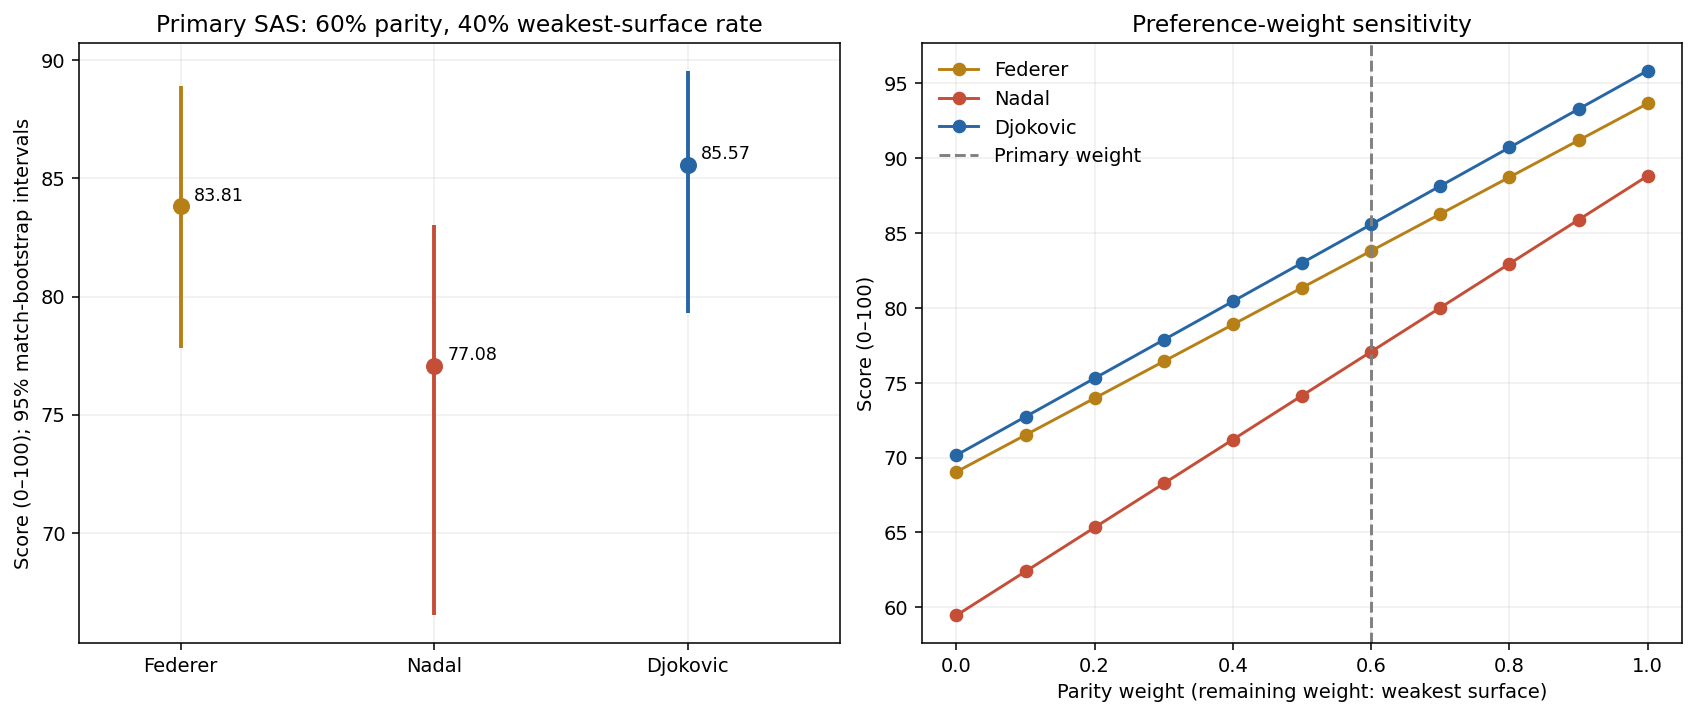

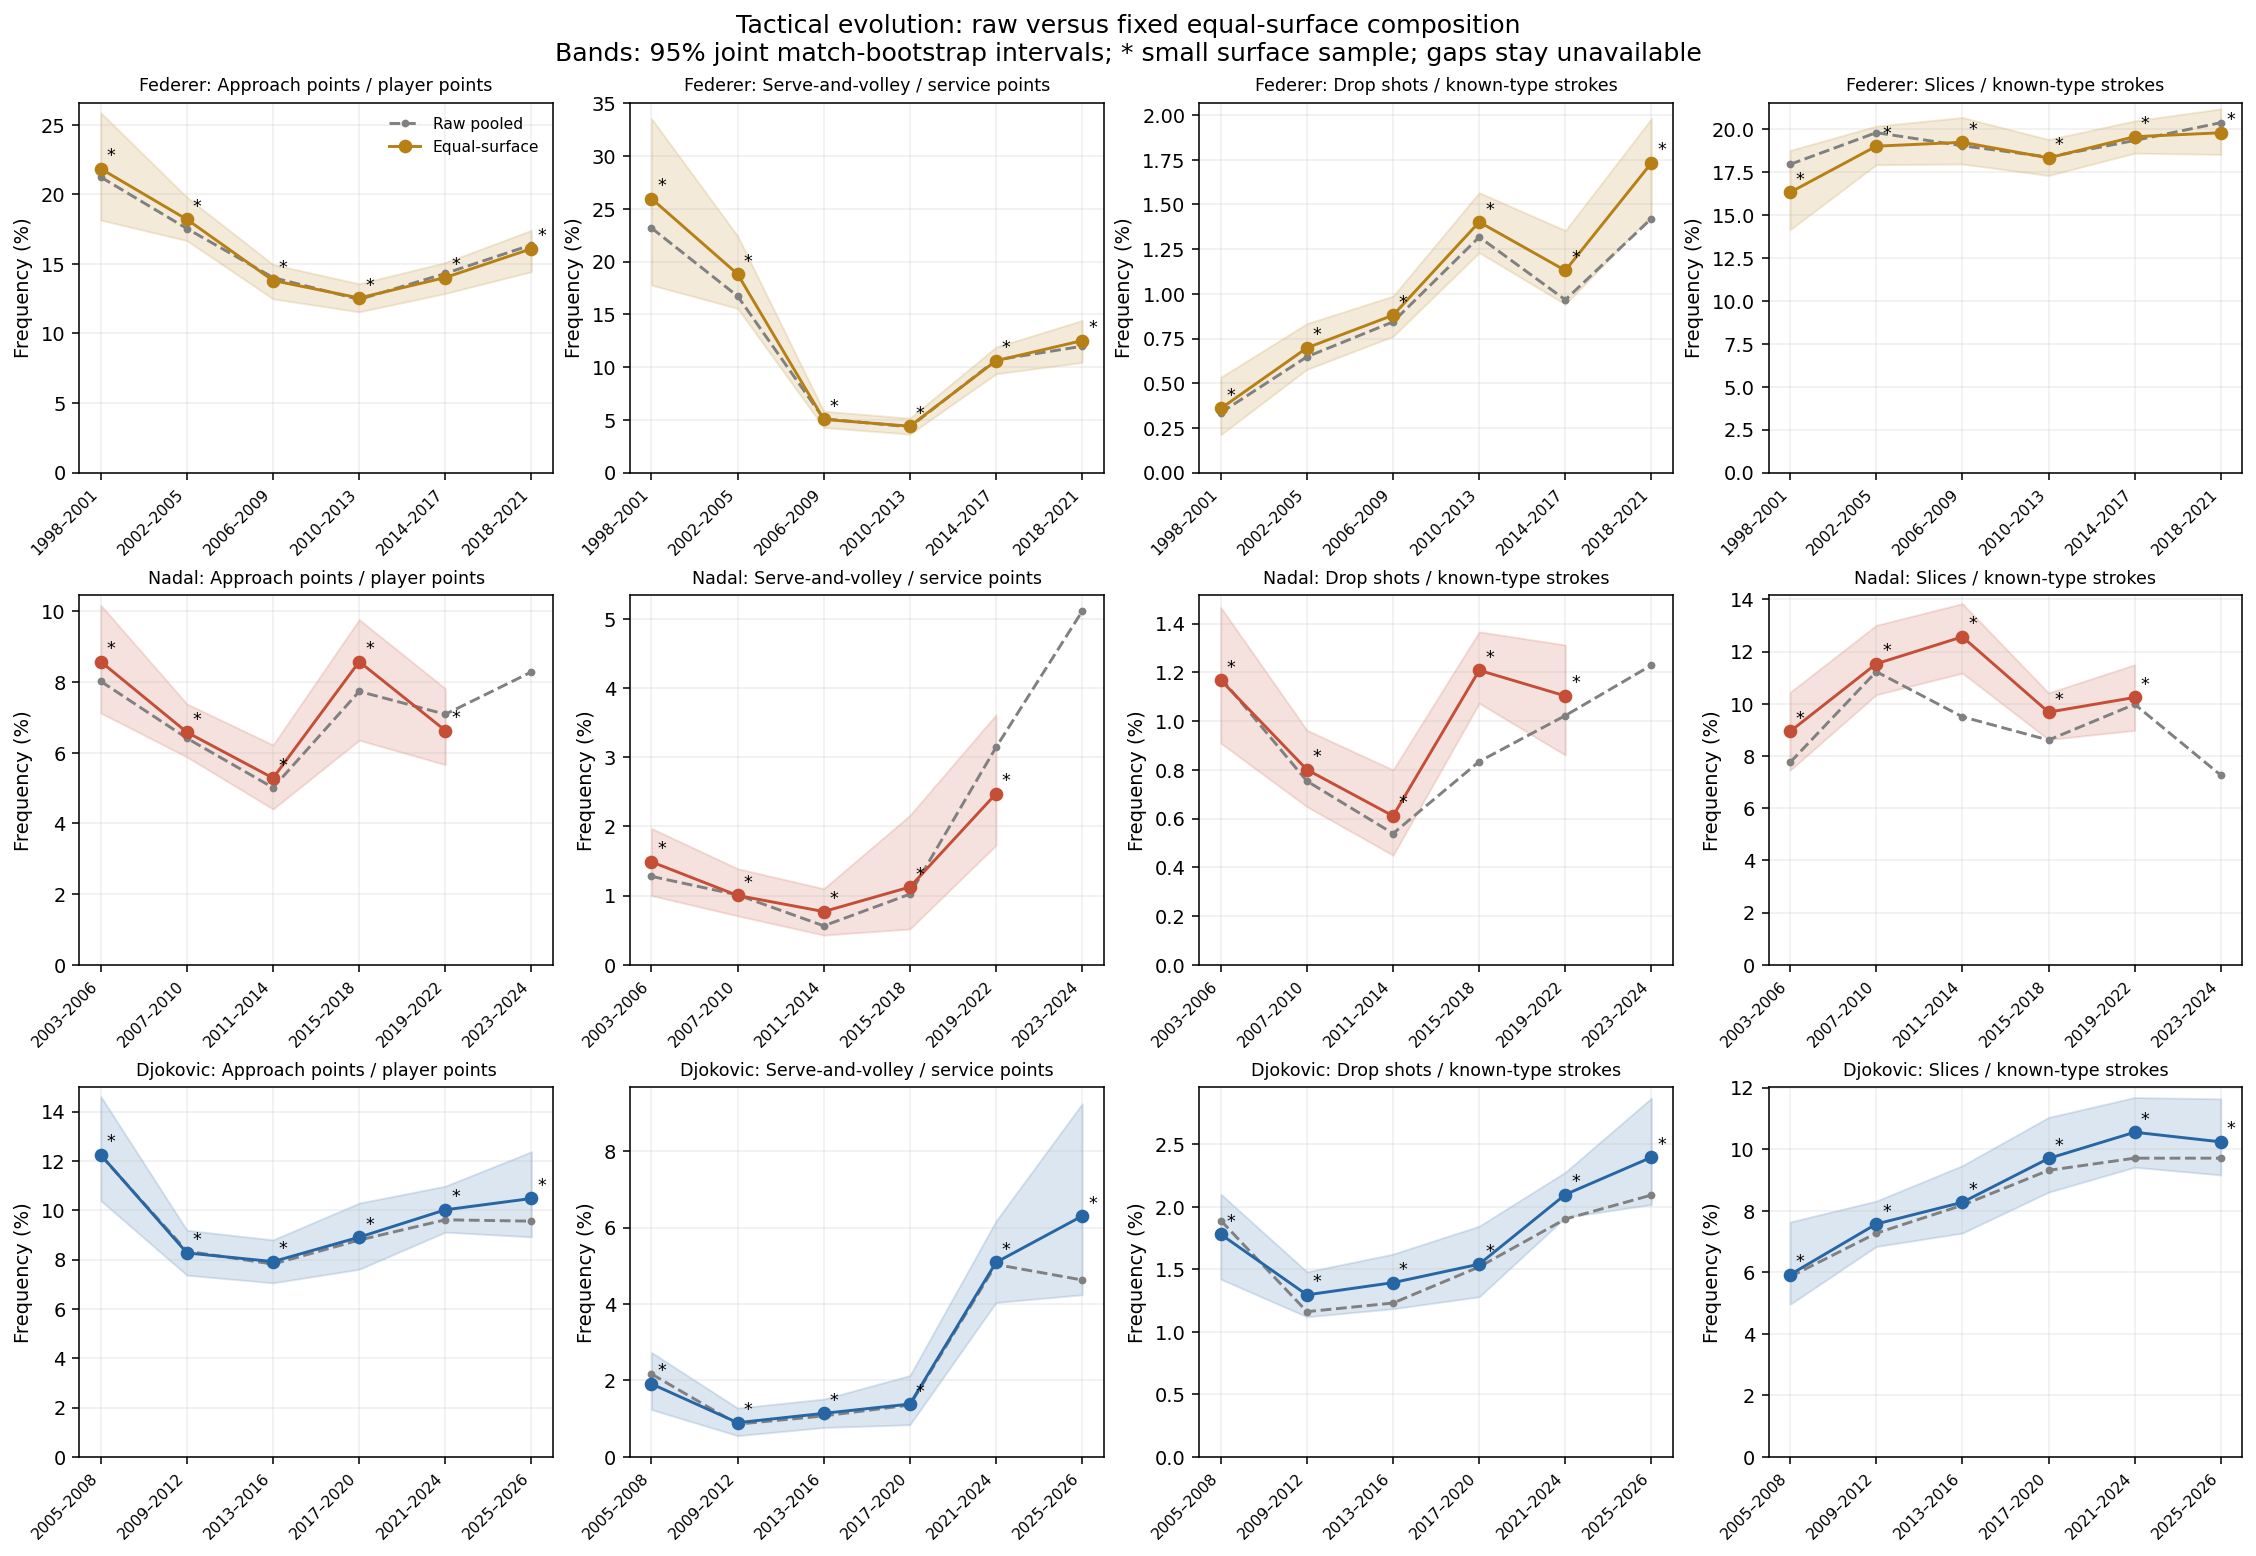

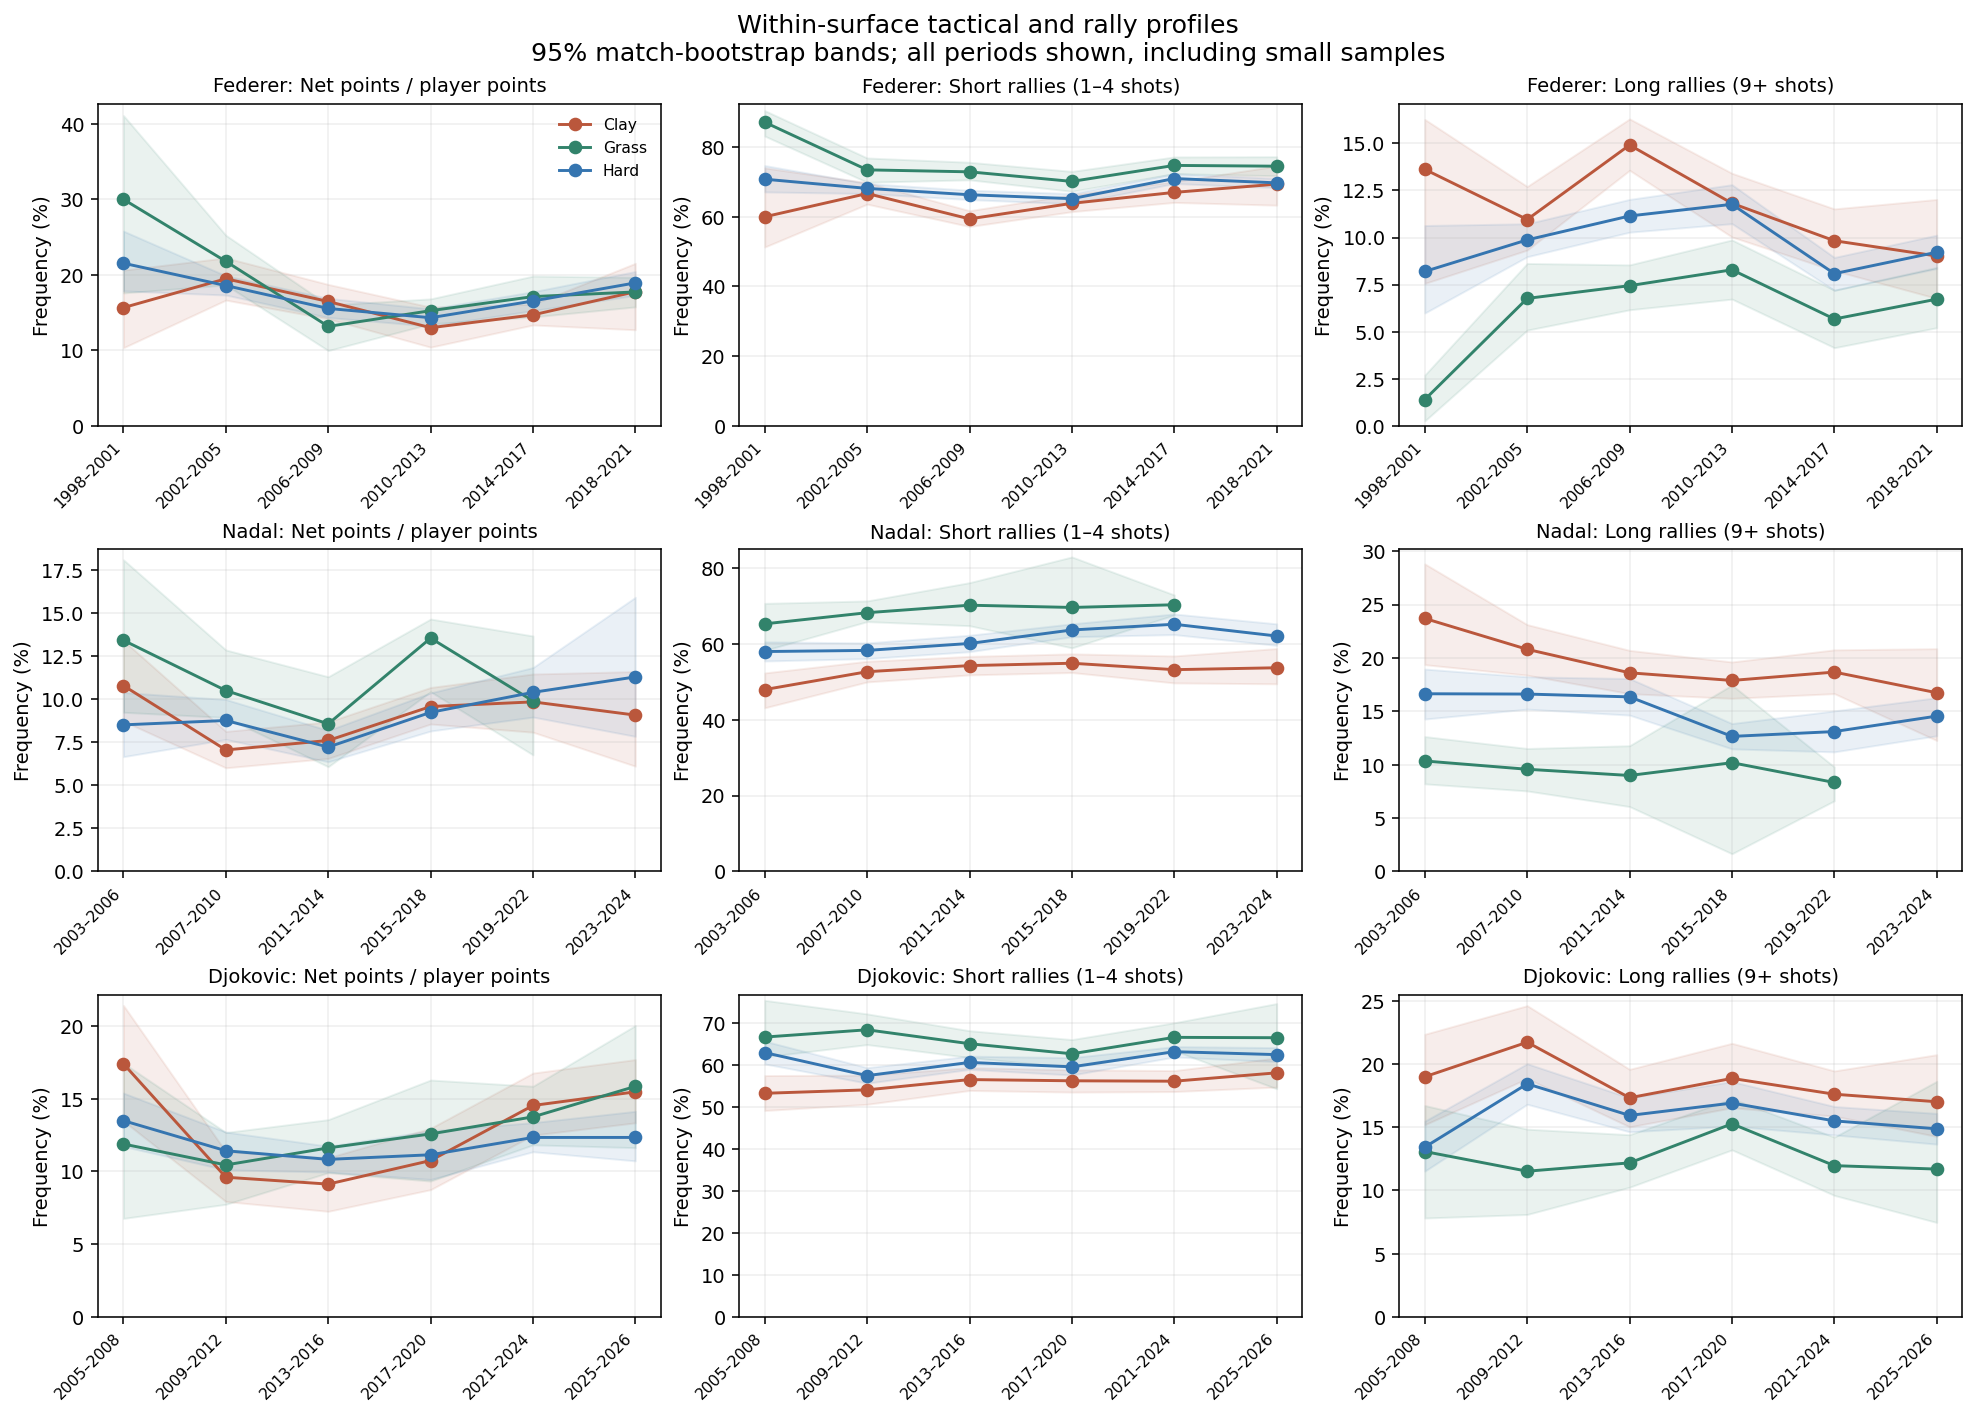

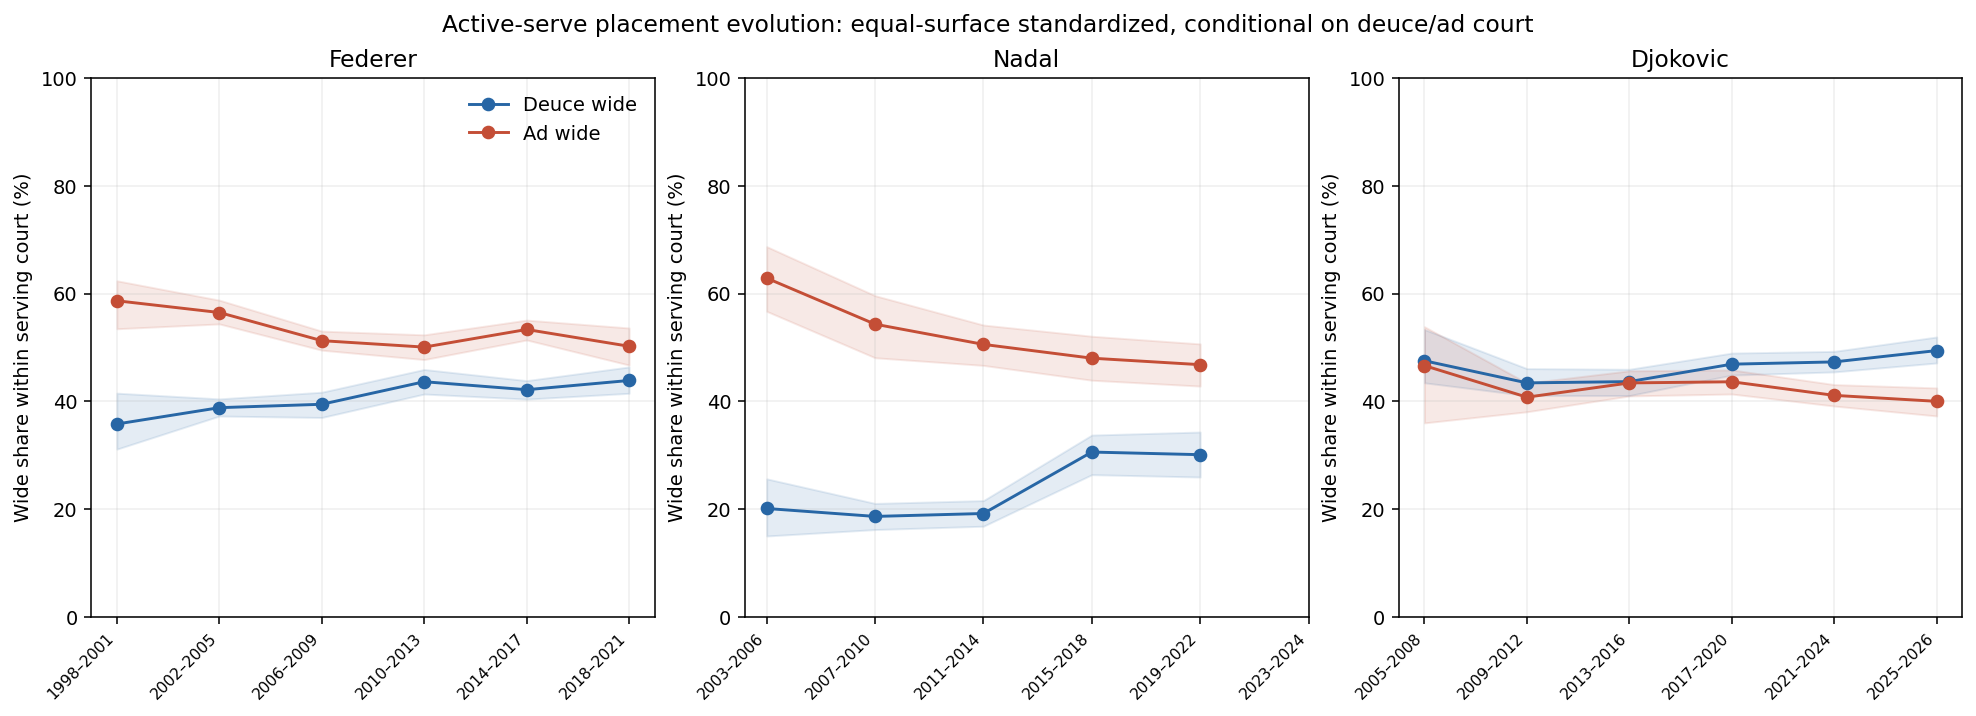

In [21]:
with plt.style.context("default"):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
    for index, player in enumerate(BIG_THREE):
        row = surface_adaptability_summary_v2.loc[surface_adaptability_summary_v2["player"].eq(player)].iloc[0]
        axes[0].scatter(index, row["surface_adaptability_score"], color=KPI_PLAYER_COLORS[player], s=60)
        axes[0].vlines(index, row["surface_adaptability_score_ci95_lower"], row["surface_adaptability_score_ci95_upper"], color=KPI_PLAYER_COLORS[player], linewidth=2)
        axes[0].annotate(f"{row['surface_adaptability_score']:.2f}", (index, row["surface_adaptability_score"]), xytext=(7, 3), textcoords="offset points", fontsize=9)
        curve = surface_adaptability_weight_sensitivity.loc[surface_adaptability_weight_sensitivity["player"].eq(player)]
        axes[1].plot(curve["parity_weight"], curve["score"], marker="o", color=KPI_PLAYER_COLORS[player], label=KPI_SHORT_NAMES[player])
    axes[0].set_xticks(range(3), [KPI_SHORT_NAMES[p] for p in BIG_THREE])
    axes[0].set_title("Primary SAS: 60% parity, 40% weakest-surface rate")
    axes[0].set_ylabel("Score (0–100); 95% match-bootstrap intervals")
    axes[0].set_xlim(-.4, 2.6)
    axes[1].axvline(.6, color="gray", linestyle="--", label="Primary weight")
    axes[1].set_xlabel("Parity weight (remaining weight: weakest surface)")
    axes[1].set_ylabel("Score (0–100)")
    axes[1].set_title("Preference-weight sensitivity")
    axes[1].legend(frameon=False)
    for ax in axes:
        ax.grid(alpha=.2)
    display_kpi_figure(fig)

    metrics = ["approach_frequency_pct", "serve_volley_frequency_pct", "drop_shot_share_pct", "slice_share_pct"]
    titles = ["Approach points / player points", "Serve-and-volley / service points", "Drop shots / known-type strokes", "Slices / known-type strokes"]
    fig, axes = plt.subplots(3, 4, figsize=(16, 11), constrained_layout=True)
    for row_index, player in enumerate(BIG_THREE):
        plan = tactical_period_plan.loc[tactical_period_plan["player"].eq(player)]
        x = plan["period_index"].to_numpy()
        for ax, metric, title in zip(axes[row_index], metrics, titles):
            raw = tactical_evolution_long.loc[tactical_evolution_long["player"].eq(player) & tactical_evolution_long["surface"].eq("Overall") & tactical_evolution_long["metric"].eq(metric)].set_index("period_index").reindex(x)
            adjusted = tactical_standardized_trends.loc[tactical_standardized_trends["player"].eq(player) & tactical_standardized_trends["metric"].eq(metric)].set_index("period_index").reindex(x)
            ax.plot(x, raw["estimate_pct"], linestyle="--", marker=".", color="gray", label="Raw pooled")
            ax.plot(x, adjusted["standardized_pct"], marker="o", color=KPI_PLAYER_COLORS[player], label="Equal-surface")
            ax.fill_between(x, adjusted["ci95_lower"].to_numpy(dtype=float), adjusted["ci95_upper"].to_numpy(dtype=float), color=KPI_PLAYER_COLORS[player], alpha=.16)
            for xpos, (_, point) in zip(x, adjusted.iterrows()):
                if point["small_sample"] and pd.notna(point["standardized_pct"]):
                    ax.annotate("*", (xpos, point["standardized_pct"]), xytext=(3, 4), textcoords="offset points", fontsize=9)
            ax.set_xticks(x, plan["period"], rotation=45, ha="right", fontsize=8)
            ax.set_title(KPI_SHORT_NAMES[player]+": "+title, fontsize=9)
            ax.set_ylabel("Frequency (%)")
            ax.set_ylim(bottom=0)
            ax.grid(alpha=.2)
    axes[0, 0].legend(frameon=False, fontsize=8)
    fig.suptitle("Tactical evolution: raw versus fixed equal-surface composition\nBands: 95% joint match-bootstrap intervals; * small surface sample; gaps stay unavailable", fontsize=13)
    display_kpi_figure(fig)

    fig, axes = plt.subplots(3, 3, figsize=(14, 10), constrained_layout=True)
    for row_index, player in enumerate(BIG_THREE):
        plan = tactical_period_plan.loc[tactical_period_plan["player"].eq(player)]
        x = plan["period_index"].to_numpy()
        for ax, metric, title in zip(axes[row_index], ["net_point_frequency_pct", "short_rally_share_pct", "long_rally_share_pct"],
            ["Net points / player points", "Short rallies (1–4 shots)", "Long rallies (9+ shots)"]):
            for surface, color in [("Clay", "#BA573C"), ("Grass", "#32836B"), ("Hard", "#3575B0")]:
                data = tactical_evolution_long.loc[tactical_evolution_long["player"].eq(player) & tactical_evolution_long["surface"].eq(surface) & tactical_evolution_long["metric"].eq(metric)].set_index("period_index").reindex(x)
                ax.plot(x, data["estimate_pct"], marker="o", color=color, label=surface)
                ax.fill_between(x, data["ci95_lower"].to_numpy(dtype=float), data["ci95_upper"].to_numpy(dtype=float), color=color, alpha=.10)
            ax.set_xticks(x, plan["period"], rotation=45, ha="right", fontsize=8)
            ax.set_title(KPI_SHORT_NAMES[player]+": "+title, fontsize=10)
            ax.set_ylabel("Frequency (%)")
            ax.set_ylim(bottom=0)
            ax.grid(alpha=.2)
    axes[0, 0].legend(frameon=False, fontsize=8)
    fig.suptitle("Within-surface tactical and rally profiles\n95% match-bootstrap bands; all periods shown, including small samples", fontsize=13)
    display_kpi_figure(fig)

    fig, axes = plt.subplots(1, 3, figsize=(14, 5), constrained_layout=True)
    for ax, player in zip(axes, BIG_THREE):
        plan = tactical_period_plan.loc[tactical_period_plan["player"].eq(player)]
        for metric, label, color in [("deuce_wide_serve_share_pct", "Deuce wide", "#2766A5"), ("ad_wide_serve_share_pct", "Ad wide", "#C44E36")]:
            data = tactical_standardized_trends.loc[tactical_standardized_trends["player"].eq(player) & tactical_standardized_trends["metric"].eq(metric)].set_index("period_index").reindex(plan["period_index"])
            ax.plot(plan["period_index"], data["standardized_pct"], marker="o", color=color, label=label)
            ax.fill_between(plan["period_index"].to_numpy(), data["ci95_lower"].to_numpy(dtype=float), data["ci95_upper"].to_numpy(dtype=float), color=color, alpha=.12)
        ax.set_xticks(plan["period_index"], plan["period"], rotation=45, ha="right", fontsize=8)
        ax.set_title(KPI_SHORT_NAMES[player])
        ax.set_ylabel("Wide share within serving court (%)")
        ax.set_ylim(0, 100)
        ax.grid(alpha=.2)
    axes[0].legend(frameon=False)
    fig.suptitle("Active-serve placement evolution: equal-surface standardized, conditional on deuce/ad court", fontsize=12)
    display_kpi_figure(fig)


### 8.4 Interpretation and limitations
SAS describes the declared blend of three-surface consistency and weakest-surface success in verified charted outcomes; it cannot establish causal adjustment skill when a player changes court surface. Tactical evolution reports component changes with coverage and surface context, not an innovation ranking. Source completeness, opponent mix, ageing, match selection, and sparse grass observations remain alternative explanations. The standardized series controls surface weights only, not all confounding.

`surface_adaptability_summary_v2` and its sensitivity table are the primary adaptability outputs. `tactical_period_plan`, `tactical_evolution_long`, `tactical_standardized_trends`, `tactical_change_summary`, and `tactical_match_table` retain period definitions, counts, masks, and changes for the style/profile and preference comparison in Section IX. Unsupported radar/equipment inputs remain unavailable, and no full tactical-innovation composite is fabricated. Weeks at No. 1 remain unavailable.

<a id="comparison"></a>

## IX. Playing styles and preference-based Big Three comparison

**Synthesis question:** How do measured styles and direct matchups explain the comparison, and which conclusions depend on the reader’s preferences? Direct rivalries can expose matchup differences that an overall sample obscures.


### 9.1 Evidence-based style profiles
Describe style with observed serving, returning, net activity, rally patterns, shot mix, and source-recorded winner/error rates. All overall profiles pool counts across each player's own charted window; surface profiles retain their own samples. Rates are not averaged across periods or surfaces. Source winner/error fields are reported as supplied and may overlap serve outcomes, so they are not independent aggression dimensions. Net-point success uses the NetPoints slice, not Approach. Missing values stay unavailable.

Profiles use raw rates and intervals rather than synthetic athleticism, acrobatics, or strength scores. Diversity is descriptive, not a reward for winning tennis. No fixed archetype is learned from three player summaries. The earlier PCA/cluster analysis is omitted: weak separation and subjective labels do not add evidence needed for these profiles. The profiles below state measurable tendencies without claiming intrinsic player types or causal explanations.


In [22]:
profile_master = tactical_match_table.merge(
    analysis_dataframes["charting_m_stats_NetPoints"].loc[lambda x: x["row"].eq("NetPoints"), ["match_id", "player", "pts_won"]].rename(columns={"pts_won": "net_points_won"}),
    on=["match_id", "player"], how="left", validate="one_to_one")
profile_rows = []
profile_tactical_metrics = ["approach_frequency_pct", "net_point_frequency_pct", "serve_volley_frequency_pct", "drop_shot_share_pct",
    "slice_share_pct", "short_rally_share_pct", "long_rally_share_pct"]
for player, surface in kpi_scope_groups:
    group_mask = profile_master["player"].eq(player)
    if surface != "Overall":
        group_mask &= profile_master["surface"].eq(surface)
    for metric in ["service_point_win_pct", "return_point_win_pct", "ace_pct"]:
        row = core_kpi_long.loc[core_kpi_long["player"].eq(player) & core_kpi_long["surface"].eq(surface) & core_kpi_long["metric"].eq(metric)].iloc[0]
        profile_rows.append({"player": player, "surface": surface, "metric": metric, "estimate": row["estimate"], "unit": "%",
            "numerator": row["numerator"], "denominator": row["denominator"], "contributing_matches": row["eligible_matches"],
            "ci95_lower": row["ci95_lower"], "ci95_upper": row["ci95_upper"], "small_sample": row["small_sample"]})
    profile_specs = {metric: tactical_metric_specs[metric] for metric in profile_tactical_metrics}
    profile_specs.update({"source_winner_rate_pct": ("winners", "source_player_points", "points"),
        "source_unforced_error_rate_pct": ("unforced", "source_player_points", "points"),
        "net_point_success_pct": ("net_points_won", "net_points_all", "events")})
    for metric, (num, den, basis) in profile_specs.items():
        a, b = profile_master[num], profile_master[den]
        mask = group_mask & a.notna() & b.notna() & np.isfinite(a) & np.isfinite(b) & a.ge(0) & b.gt(0) & a.le(b)
        if metric in tactical_masks:
            mask &= tactical_masks[metric]
        else:
            mask &= reconciled_mask(["service_points_parsed", "return_points_parsed"])
        sample = profile_master.loc[mask]
        numerator, denominator = sample[num].sum(min_count=1), sample[den].sum(min_count=1)
        matrix = np.zeros((len(bootstrap_match_ids), 2))
        for mid, x, y in sample[["match_id", num, den]].itertuples(index=False, name=None):
            matrix[bootstrap_match_index[mid]] = [x, y]
        totals = bootstrap_weights @ matrix
        with np.errstate(divide="ignore", invalid="ignore"):
            draws = np.where(totals[:, 1] > 0, 100*totals[:, 0]/totals[:, 1], np.nan)
        valid = draws[np.isfinite(draws)]
        profile_rows.append({"player": player, "surface": surface, "metric": metric,
            "estimate": 100*numerator/denominator if denominator > 0 else np.nan, "unit": "%", "numerator": numerator, "denominator": denominator,
            "contributing_matches": len(sample), "small_sample": pd.isna(denominator) or denominator < SMALL_SAMPLE_THRESHOLDS[basis],
            "ci95_lower": np.percentile(valid, 2.5) if len(valid) >= .95*BOOTSTRAP_REPLICATES else np.nan,
            "ci95_upper": np.percentile(valid, 97.5) if len(valid) >= .95*BOOTSTRAP_REPLICATES else np.nan})
    ground = get_shot_distribution(player, surface, "shot_type", SHOT_ALL_FAMILIES).loc["groundstroke"]
    profile_rows.append({"player": player, "surface": surface, "metric": "groundstroke_share_pct", "estimate": ground["share_pct"], "unit": "%",
        "numerator": ground["count"], "denominator": ground["classified_denominator"], "contributing_matches": ground["contributing_matches"],
        "ci95_lower": ground["ci95_lower"], "ci95_upper": ground["ci95_upper"], "small_sample": ground["classified_denominator"] < SMALL_SAMPLE_THRESHOLDS["shots"]})
    for distribution, metric in [("shot_type", "shot_family_diversity"), ("source_direction_Total", "directional_diversity")]:
        row = shot_diversity_summary.loc[shot_diversity_summary["player"].eq(player) & shot_diversity_summary["surface"].eq(surface)
            & shot_diversity_summary["distribution"].eq(distribution)].iloc[0]
        profile_rows.append({"player": player, "surface": surface, "metric": metric, "estimate": row["normalized_entropy"], "unit": "index (0–1)",
            "numerator": np.nan, "denominator": row["classified_strokes"], "contributing_matches": row["contributing_matches"],
            "ci95_lower": row["ci95_lower"], "ci95_upper": row["ci95_upper"], "small_sample": row["small_sample"]})
style_profile_long = pd.DataFrame(profile_rows)
style_profile_wide = style_profile_long.pivot(index=["player", "surface"], columns="metric", values="estimate").reset_index()
style_cards = []
for row in style_profile_wide.itertuples(index=False):
    style_cards.append({"player": row.player, "surface": row.surface,
        "evidence_profile": f"Service points won {row.service_point_win_pct:.1f}%; return points won {row.return_point_win_pct:.1f}%. "
        f"Approach frequency {row.approach_frequency_pct:.1f}%; serve-and-volley {row.serve_volley_frequency_pct:.1f}%. "
        f"Short rallies {row.short_rally_share_pct:.1f}%; long rallies {row.long_rally_share_pct:.1f}%. "
        f"Groundstrokes {row.groundstroke_share_pct:.1f}% and slices {row.slice_share_pct:.1f}% of their stated classified stroke samples. "
        "See the evidence table for denominators and intervals; these are observed tendencies, not athleticism labels."})
playing_style_profiles = pd.DataFrame(style_cards)
assert not style_profile_long.duplicated(["player", "surface", "metric"]).any()
assert style_profile_long.loc[style_profile_long["unit"].eq("%"), "estimate"].dropna().between(0, 100).all()
print("Style profiles overall and by surface (raw units; no composite style score):")
report_table(style_profile_wide.round(3))
with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
    report_table(playing_style_profiles)
    report_table(style_profile_long.round(4))


Style profiles overall and by surface (raw units; no composite style score):


metric,player,surface,ace_pct,approach_frequency_pct,directional_diversity,drop_shot_share_pct,groundstroke_share_pct,long_rally_share_pct,net_point_frequency_pct,net_point_success_pct,return_point_win_pct,serve_volley_frequency_pct,service_point_win_pct,short_rally_share_pct,shot_family_diversity,slice_share_pct,source_unforced_error_rate_pct,source_winner_rate_pct
,Novak Djokovic,Clay,4.891,8.810,0.839,2.375,87.652,18.656,12.350,69.388,41.074,1.896,64.076,55.723,0.257,5.378,17.266,16.267
,Novak Djokovic,Grass,9.272,10.336,0.823,1.436,80.801,12.700,12.547,72.005,37.680,3.481,68.834,65.670,0.328,12.343,13.882,16.333
,Novak Djokovic,Hard,7.612,8.866,0.827,1.226,85.160,16.143,11.708,70.182,40.812,2.473,67.540,60.845,0.277,9.019,15.414,15.638
,Novak Djokovic,Overall,7.195,9.047,0.830,1.547,85.295,16.275,11.971,70.249,40.448,2.472,66.900,60.282,0.280,8.468,15.636,15.878
,Rafael Nadal,Clay,2.609,5.869,0.861,1.052,89.413,19.402,8.611,75.145,44.823,0.667,65.032,53.289,0.217,6.291,14.480,15.074
,Rafael Nadal,Grass,7.008,8.390,0.859,1.124,79.027,9.484,10.901,75.437,35.279,1.674,68.671,68.809,0.335,15.007,11.817,17.101
,Rafael Nadal,Hard,4.786,6.920,0.856,0.553,84.399,14.778,8.955,74.450,38.151,1.795,65.961,61.507,0.270,11.197,14.042,14.713
,Rafael Nadal,Overall,4.277,6.728,0.859,0.813,85.980,15.831,9.074,74.833,40.174,1.375,65.958,59.383,0.257,9.516,13.921,15.139
,Roger Federer,Clay,7.295,14.597,0.868,1.520,76.505,12.243,16.270,69.446,39.906,7.621,65.752,63.657,0.373,15.325,18.737,18.670
,Roger Federer,Grass,11.886,16.196,0.866,0.880,67.682,6.632,17.680,71.814,36.998,15.022,72.791,74.000,0.451,21.690,13.109,20.427


player,surface,evidence_profile
Novak Djokovic,Clay,"Service points won 64.1%; return points won 41.1%. Approach frequency 8.8%; serve-and-volley 1.9%. Short rallies 55.7%; long rallies 18.7%. Groundstrokes 87.7% and slices 5.4% of their stated classified stroke samples. See the evidence table for denominators and intervals; these are observed tendencies, not athleticism labels."
Novak Djokovic,Grass,"Service points won 68.8%; return points won 37.7%. Approach frequency 10.3%; serve-and-volley 3.5%. Short rallies 65.7%; long rallies 12.7%. Groundstrokes 80.8% and slices 12.3% of their stated classified stroke samples. See the evidence table for denominators and intervals; these are observed tendencies, not athleticism labels."
Novak Djokovic,Hard,"Service points won 67.5%; return points won 40.8%. Approach frequency 8.9%; serve-and-volley 2.5%. Short rallies 60.8%; long rallies 16.1%. Groundstrokes 85.2% and slices 9.0% of their stated classified stroke samples. See the evidence table for denominators and intervals; these are observed tendencies, not athleticism labels."
Novak Djokovic,Overall,"Service points won 66.9%; return points won 40.4%. Approach frequency 9.0%; serve-and-volley 2.5%. Short rallies 60.3%; long rallies 16.3%. Groundstrokes 85.3% and slices 8.5% of their stated classified stroke samples. See the evidence table for denominators and intervals; these are observed tendencies, not athleticism labels."
Rafael Nadal,Clay,"Service points won 65.0%; return points won 44.8%. Approach frequency 5.9%; serve-and-volley 0.7%. Short rallies 53.3%; long rallies 19.4%. Groundstrokes 89.4% and slices 6.3% of their stated classified stroke samples. See the evidence table for denominators and intervals; these are observed tendencies, not athleticism labels."
Rafael Nadal,Grass,"Service points won 68.7%; return points won 35.3%. Approach frequency 8.4%; serve-and-volley 1.7%. Short rallies 68.8%; long rallies 9.5%. Groundstrokes 79.0% and slices 15.0% of their stated classified stroke samples. See the evidence table for denominators and intervals; these are observed tendencies, not athleticism labels."
Rafael Nadal,Hard,"Service points won 66.0%; return points won 38.2%. Approach frequency 6.9%; serve-and-volley 1.8%. Short rallies 61.5%; long rallies 14.8%. Groundstrokes 84.4% and slices 11.2% of their stated classified stroke samples. See the evidence table for denominators and intervals; these are observed tendencies, not athleticism labels."
Rafael Nadal,Overall,"Service points won 66.0%; return points won 40.2%. Approach frequency 6.7%; serve-and-volley 1.4%. Short rallies 59.4%; long rallies 15.8%. Groundstrokes 86.0% and slices 9.5% of their stated classified stroke samples. See the evidence table for denominators and intervals; these are observed tendencies, not athleticism labels."
Roger Federer,Clay,"Service points won 65.8%; return points won 39.9%. Approach frequency 14.6%; serve-and-volley 7.6%. Short rallies 63.7%; long rallies 12.2%. Groundstrokes 76.5% and slices 15.3% of their stated classified stroke samples. See the evidence table for denominators and intervals; these are observed tendencies, not athleticism labels."
Roger Federer,Grass,"Service points won 72.8%; return points won 37.0%. Approach frequency 16.2%; serve-and-volley 15.0%. Short rallies 74.0%; long rallies 6.6%. Groundstrokes 67.7% and slices 21.7% of their stated classified stroke samples. See the evidence table for denominators and intervals; these are observed tendencies, not athleticism labels."


player,surface,metric,estimate,unit,numerator,denominator,contributing_matches,ci95_lower,ci95_upper,small_sample
Roger Federer,Overall,service_point_win_pct,69.283,%,"40,906.000","59,042.000",712,68.743,69.800,False
Roger Federer,Overall,return_point_win_pct,39.228,%,"24,853.000","63,355.000",711,38.679,39.763,False
Roger Federer,Overall,ace_pct,10.178,%,"6,009.000","59,042.000",712,9.763,10.573,False
Roger Federer,Overall,approach_frequency_pct,15.248,%,"18,029.000","118,238.000",687,14.724,15.765,False
Roger Federer,Overall,net_point_frequency_pct,16.938,%,"20,492.000","120,981.000",703,16.416,17.472,False
Roger Federer,Overall,serve_volley_frequency_pct,10.211,%,"5,931.000","58,086.000",702,9.329,11.106,False
Roger Federer,Overall,drop_shot_share_pct,0.969,%,"2,135.000","220,248.000",722,0.906,1.039,False
Roger Federer,Overall,slice_share_pct,19.252,%,"42,402.000","220,248.000",722,18.807,19.698,False
Roger Federer,Overall,short_rally_share_pct,68.292,%,"82,408.000","120,670.000",722,67.708,68.890,False
Roger Federer,Overall,long_rally_share_pct,9.823,%,"11,854.000","120,670.000",722,9.463,10.186,False


### 9.2 Declared comparison model, scaling, and dependence
The overall comparison uses four validated measures: known-outcome match win rate, DR, full common-cohort CI, and primary SAS. Totals are excluded because charting exposure differs; athleticism, style diversity, tactical change, unsupported innovation inputs, and unavailable ranking weeks are not scored. Metrics retain their own disclosed eligible samples; only the CI's components share its internal common cohort. Individual career windows remain different as requested.

**Primary fixed scaling:** win rate and CI already lie in [0,1]; SAS is divided by 100; DR is mapped monotonically to **DR / (1 + DR)**. This transformation is a disclosed scoring scale, not a new measured tennis KPI. No fitted reference population or sample extrema are needed. A weighted arithmetic mean is displayed ×100. Equal weights mean equal influence for equal changes on these fixed scales, not equal empirical variance or independent information. DR overlaps serving/returning performance; CI includes serving outcomes; SAS includes win rates. These are overlapping perspectives, not four independent votes.

Five declared scenarios emphasize balance, winning, dominance, clutch, or adaptability. Sensitivity includes a 0.1-step four-weight simplex grid, leave-one-metric-out scores, and an alternative within-Big-Three min–max point-estimate scale. Min–max sensitivity uses only these three players and can amplify small differences; it is not the primary score and has no separate uncertainty claim. Grid-leading share describes the chosen preference grid, **not a probability of greatness**.

All primary score draws reuse the same joint match bootstrap, with eligibility and scales fixed and derived metrics recomputed from their component draws. First-place frequencies are conditional bootstrap rank frequencies, not posterior probabilities that a player is the GOAT. Ties split rank credit. Score-difference intervals and conditional pairwise frequencies are shown directly; none repairs missing outcomes or chart-selection bias. Separate illustrative surface comparisons omit SAS and equally weight surface win rate, transformed DR, and full surface CI; sparse CI components remain flagged.

In [23]:
COMPARISON_METRICS = ["winning", "dominance", "clutch", "adaptability"]
COMPARISON_SCENARIOS = {
    "Balanced": {"winning": .25, "dominance": .25, "clutch": .25, "adaptability": .25},
    "Winning priority": {"winning": .55, "dominance": .15, "clutch": .15, "adaptability": .15},
    "Dominance priority": {"winning": .20, "dominance": .50, "clutch": .15, "adaptability": .15},
    "Clutch priority": {"winning": .20, "dominance": .15, "clutch": .50, "adaptability": .15},
    "Adaptability priority": {"winning": .20, "dominance": .15, "clutch": .15, "adaptability": .50},
}
comparison_weights = pd.DataFrame(COMPARISON_SCENARIOS).T.rename_axis("scenario").reset_index()
assert comparison_weights[COMPARISON_METRICS].ge(0).all().all()
assert np.allclose(comparison_weights[COMPARISON_METRICS].sum(axis=1), 1)

# Recover already-computed core bootstrap metrics; no second resampling or clipping.
core_metric_draws = {}
for index, metric, columns in bootstrap_descriptors:
    if metric not in ["match_win_pct", "dominance_ratio"]:
        continue
    info = core_kpi_long.loc[index]
    with np.errstate(divide="ignore", invalid="ignore"):
        if metric == "dominance_ratio":
            rw, rp, sw, sp = [bootstrap_totals[:, column] for column in columns]
            loss = 1-sw/sp
            values = np.where((rp > 0) & (sp > 0) & (loss > 0), (rw/rp)/loss, np.nan)
        else:
            wins, matches = [bootstrap_totals[:, column] for column in columns]
            values = np.where(matches > 0, wins/matches, np.nan)
    core_metric_draws[(info["player"], info["surface"], metric)] = values
comparison_input_rows, comparison_draw_arrays = [], []
for player in BIG_THREE:
    core = core_kpi_overall.loc[core_kpi_overall["player"].eq(player)].iloc[0]
    ci = clutch_overall.loc[clutch_overall["player"].eq(player)].iloc[0]
    sas = surface_adaptability_summary_v2.loc[surface_adaptability_summary_v2["player"].eq(player)].iloc[0]
    raw = [core["match_win_pct"]/100, core["dominance_ratio"], ci["clutch_index_full"], sas["surface_adaptability_score"]]
    scaled = [raw[0], raw[1]/(1+raw[1]), raw[2], raw[3]/100]
    dr_draws = core_metric_draws[(player, "Overall", "dominance_ratio")]
    draws = np.column_stack([core_metric_draws[(player, "Overall", "match_win_pct")], dr_draws/(1+dr_draws),
        clutch_bootstrap_distributions[(player, "Overall")], adaptability_bootstraps[player]["sas"]/100])
    comparison_draw_arrays.append(draws)
    counts = [int(core["known_outcome_matches"]), int(core_kpi_long.loc[core_kpi_long["player"].eq(player)
        & core_kpi_long["surface"].eq("Overall") & core_kpi_long["metric"].eq("dominance_ratio"), "eligible_matches"].iloc[0]),
        int(ci["common_ci_matches"]), int(sas["known_outcome_matches"])]
    for metric, value, score_value, count in zip(COMPARISON_METRICS, raw, scaled, counts):
        comparison_input_rows.append({"player": player, "metric": metric, "raw_value": value, "fixed_scale_value": score_value,
            "contributing_matches": count, "earliest_charted_date": core["earliest_charted_date"], "latest_charted_date": core["latest_charted_date"]})
comparison_inputs = pd.DataFrame(comparison_input_rows)
comparison_points = comparison_inputs.pivot(index="player", columns="metric", values="fixed_scale_value").reindex(index=BIG_THREE, columns=COMPARISON_METRICS).to_numpy()
comparison_raw_points = comparison_inputs.pivot(index="player", columns="metric", values="raw_value").reindex(index=BIG_THREE, columns=COMPARISON_METRICS).to_numpy()
comparison_draws = np.stack(comparison_draw_arrays, axis=1)  # replicate × player × metric
comparison_valid_draw = np.isfinite(comparison_draws).all(axis=(1, 2))
comparison_draws_valid = comparison_draws[comparison_valid_draw]
if comparison_valid_draw.sum() < .95*BOOTSTRAP_REPLICATES:
    raise ValueError("Too few fully paired score draws; investigate metric coverage before ranking")
assert np.isfinite(comparison_points).all()
assert ((comparison_points >= 0) & (comparison_points <= 1)).all()

def fractional_rank_frequencies(scores):
    # Each player occupies a span of ranks when tied; split credit evenly over that span.
    greater = (scores[:, None, :] > scores[:, :, None]+1e-12).sum(axis=2)
    ties = np.isclose(scores[:, None, :], scores[:, :, None], rtol=0, atol=1e-12).sum(axis=2)
    return np.column_stack([np.mean(np.where((greater < rank) & (rank <= greater+ties), 1/ties, 0), axis=0)
        for rank in range(1, scores.shape[1]+1)])

scenario_rows, contribution_rows, score_difference_rows = [], [], []
comparison_score_bootstraps = {}
for scenario, weights in COMPARISON_SCENARIOS.items():
    w = np.array([weights[metric] for metric in COMPARISON_METRICS])
    points = 100*(comparison_points @ w)
    draws = 100*(comparison_draws_valid @ w)
    comparison_score_bootstraps[scenario] = draws
    rank_frequencies = fractional_rank_frequencies(draws)
    for index, player in enumerate(BIG_THREE):
        scenario_rows.append({"scenario": scenario, "player": player, "score": points[index],
            "score_boot_median": np.median(draws[:, index]), "ci95_lower": np.percentile(draws[:, index], 2.5),
            "ci95_upper": np.percentile(draws[:, index], 97.5), "point_estimate_rank": int(1+(points > points[index]+1e-12).sum()),
            "bootstrap_first_place_pct": 100*rank_frequencies[index, 0], "bootstrap_second_place_pct": 100*rank_frequencies[index, 1],
            "bootstrap_third_place_pct": 100*rank_frequencies[index, 2], "paired_valid_bootstraps": len(draws)})
        for metric_index, metric in enumerate(COMPARISON_METRICS):
            contribution_rows.append({"scenario": scenario, "player": player, "metric": metric, "weight": w[metric_index],
                "fixed_scale_value": comparison_points[index, metric_index], "score_contribution": 100*w[metric_index]*comparison_points[index, metric_index]})
    for a, b in [(0, 1), (0, 2), (1, 2)]:
        difference = draws[:, a]-draws[:, b]
        score_difference_rows.append({"scenario": scenario, "comparison": BIG_THREE[a]+" minus "+BIG_THREE[b],
            "point_score_difference": points[a]-points[b], "ci95_lower": np.percentile(difference, 2.5), "ci95_upper": np.percentile(difference, 97.5),
            "bootstrap_a_ahead_pct": 100*np.mean((difference > 1e-12)+.5*np.isclose(difference, 0, rtol=0, atol=1e-12))})
comparison_scores = pd.DataFrame(scenario_rows)
comparison_contributions = pd.DataFrame(contribution_rows)
comparison_pairwise_differences = pd.DataFrame(score_difference_rows)

# Full nonnegative 0.1-step simplex, including single-metric corners; not a probability distribution over true preferences.
grid_rows = []
for a in range(11):
    for b in range(11-a):
        for c in range(11-a-b):
            w = np.array([a, b, c, 10-a-b-c])/10
            scores = 100*(comparison_points @ w)
            leaders = np.isclose(scores, scores.max(), rtol=0, atol=1e-12)
            row = {metric+"_weight": w[i] for i, metric in enumerate(COMPARISON_METRICS)}
            row["leaders"] = "; ".join(p for p, lead in zip(BIG_THREE, leaders) if lead)
            for i, player in enumerate(BIG_THREE):
                row[player+"_score"] = scores[i]
                row[player+"_lead_credit"] = int(leaders[i])/leaders.sum()
            grid_rows.append(row)
comparison_weight_grid = pd.DataFrame(grid_rows)
comparison_grid_summary = pd.DataFrame([{"player": p, "grid_settings": len(comparison_weight_grid),
    "fractional_grid_lead_pct": 100*comparison_weight_grid[p+"_lead_credit"].mean()} for p in BIG_THREE])

raw_min, raw_max = comparison_raw_points.min(axis=0), comparison_raw_points.max(axis=0)
span = raw_max-raw_min
alternative_minmax_points = np.divide(comparison_raw_points-raw_min, span, out=np.full_like(comparison_raw_points, .5), where=span > 0)
normalization_audit = comparison_inputs.copy()
for j, metric in enumerate(COMPARISON_METRICS):
    normalization_audit.loc[normalization_audit["metric"].eq(metric), "three_player_min"] = raw_min[j]
    normalization_audit.loc[normalization_audit["metric"].eq(metric), "three_player_max"] = raw_max[j]
    for i, player in enumerate(BIG_THREE):
        normalization_audit.loc[normalization_audit["metric"].eq(metric) & normalization_audit["player"].eq(player), "alternative_minmax_value"] = alternative_minmax_points[i, j]
scaling_sensitivity_rows = []
for scenario, weights in COMPARISON_SCENARIOS.items():
    w = np.array([weights[m] for m in COMPARISON_METRICS])
    values = 100*(alternative_minmax_points @ w)
    for i, player in enumerate(BIG_THREE):
        scaling_sensitivity_rows.append({"scenario": scenario, "player": player, "alternative_minmax_score": values[i],
            "alternative_point_rank": int(1+(values > values[i]+1e-12).sum())})
comparison_scaling_sensitivity = pd.DataFrame(scaling_sensitivity_rows)
leave_one_out_rows = []
for omitted in COMPARISON_METRICS:
    w = np.array([0 if m == omitted else 1/3 for m in COMPARISON_METRICS])
    values = 100*(comparison_points @ w)
    for i, player in enumerate(BIG_THREE):
        leave_one_out_rows.append({"omitted_metric": omitted, "player": player, "score": values[i],
            "point_rank": int(1+(values > values[i]+1e-12).sum())})
comparison_leave_one_out = pd.DataFrame(leave_one_out_rows)

# Illustrative surface scores use three metrics only; adaptability has no single-surface interpretation.
surface_comparison_rows = []
for surface in PROJECT_SURFACES:
    point_rows, draw_rows = [], []
    for player in BIG_THREE:
        core = core_kpi_by_surface.loc[core_kpi_by_surface["player"].eq(player) & core_kpi_by_surface["surface"].eq(surface)].iloc[0]
        ci = clutch_by_surface.loc[clutch_by_surface["player"].eq(player) & clutch_by_surface["surface"].eq(surface)].iloc[0]
        dr = core_metric_draws[(player, surface, "dominance_ratio")]
        point_rows.append([core["match_win_pct"]/100, core["dominance_ratio"]/(1+core["dominance_ratio"]), ci["clutch_index_full"]])
        draw_rows.append(np.column_stack([core_metric_draws[(player, surface, "match_win_pct")], dr/(1+dr), clutch_bootstrap_distributions[(player, surface)]]))
    points = np.array(point_rows).mean(axis=1)*100
    draws = np.stack(draw_rows, axis=1).mean(axis=2)*100
    valid = np.isfinite(draws).all(axis=1)
    frequencies = fractional_rank_frequencies(draws[valid]) if valid.any() else np.full((3,3), np.nan)
    for i, player in enumerate(BIG_THREE):
        ci = clutch_by_surface.loc[clutch_by_surface["player"].eq(player) & clutch_by_surface["surface"].eq(surface)].iloc[0]
        surface_comparison_rows.append({"player": player, "surface": surface, "illustrative_score": points[i], "small_ci_sample": ci["small_sample"],
            "ci95_lower": np.percentile(draws[valid, i], 2.5) if valid.sum() >= .95*BOOTSTRAP_REPLICATES else np.nan,
            "ci95_upper": np.percentile(draws[valid, i], 97.5) if valid.sum() >= .95*BOOTSTRAP_REPLICATES else np.nan,
            "bootstrap_first_place_pct": 100*frequencies[i, 0], "paired_valid_bootstraps": int(valid.sum())})
surface_preference_comparison = pd.DataFrame(surface_comparison_rows)

# Assertions cover ties, decomposition, probability mass, score bounds, and paired resampling.
assert np.allclose(fractional_rank_frequencies(np.ones((5, 3))), np.full((3,3), 1/3))
assert np.allclose(fractional_rank_frequencies(np.tile([3,2,1], (5,1))), np.eye(3))
assert len(comparison_weight_grid) == 286
assert comparison_scores["score"].between(0, 100).all()
assert np.allclose(comparison_scores.groupby("scenario")["bootstrap_first_place_pct"].sum(), 100)
assert np.allclose(comparison_scores[["bootstrap_first_place_pct", "bootstrap_second_place_pct", "bootstrap_third_place_pct"]].sum(axis=1), 100)
assert np.allclose(comparison_grid_summary["fractional_grid_lead_pct"].sum(), 100)
recomputed = comparison_contributions.groupby(["scenario", "player"])["score_contribution"].sum()
assert np.allclose(recomputed.sort_index(), comparison_scores.set_index(["scenario", "player"])["score"].sort_index())
print("Primary fixed-scale inputs, eligible samples, and alternative three-player min–max scale:")
report_table(normalization_audit.round(5))
print("Declared scenario weights:")
report_table(comparison_weights)
print("Primary scores and conditional bootstrap rank frequencies:")
with pd.option_context("display.max_columns", None):
    report_table(comparison_scores.round(4))
print("Score contributions (sum to each primary score):")
with pd.option_context("display.max_rows", None):
    report_table(comparison_contributions.round(5))
print("Direct score differences; bootstrap-ahead frequency is not a hypothesis-test p-value:")
with pd.option_context("display.max_colwidth", None):
    report_table(comparison_pairwise_differences.round(4))
print("Preference-grid lead shares: a summary of this chosen grid, not a probability of greatest ability:")
report_table(comparison_grid_summary.round(3))
with pd.option_context("display.max_rows", None):
    report_table(comparison_weight_grid.round(4))
print("Alternative scaling sensitivity (point estimates only):")
report_table(comparison_scaling_sensitivity.round(4))
print("Leave-one-metric-out sensitivity (equal remaining weights):")
report_table(comparison_leave_one_out.round(4))
print("Illustrative within-surface comparison; equal winning/DR/CI weights, SAS omitted:")
report_table(surface_preference_comparison.round(4))


Primary fixed-scale inputs, eligible samples, and alternative three-player min–max scale:


player,metric,raw_value,fixed_scale_value,contributing_matches,earliest_charted_date,latest_charted_date,three_player_min,three_player_max,alternative_minmax_value
Roger Federer,winning,0.788,0.788,709,1998-07-04,2021-07-05,0.723,0.788,1.000
Roger Federer,dominance,1.277,0.561,703,1998-07-04,2021-07-05,1.183,1.277,1.000
Roger Federer,clutch,0.639,0.639,687,1998-07-04,2021-07-05,0.608,0.643,0.889
Roger Federer,adaptability,83.810,0.838,709,1998-07-04,2021-07-05,77.077,85.575,0.792
Rafael Nadal,winning,0.723,0.723,412,2003-05-15,2024-11-19,0.723,0.788,0.000
Rafael Nadal,dominance,1.183,0.542,406,2003-05-15,2024-11-19,1.183,1.277,0.000
Rafael Nadal,clutch,0.608,0.608,392,2003-05-15,2024-11-19,0.608,0.643,0.000
Rafael Nadal,adaptability,77.077,0.771,412,2003-05-15,2024-11-19,77.077,85.575,0.000
Novak Djokovic,winning,0.768,0.768,526,2005-01-17,2026-03-11,0.723,0.788,0.687
Novak Djokovic,dominance,1.221,0.550,546,2005-01-17,2026-03-11,1.183,1.277,0.406


Declared scenario weights:


scenario,winning,dominance,clutch,adaptability
Balanced,0.250,0.250,0.250,0.250
Winning priority,0.550,0.150,0.150,0.150
Dominance priority,0.200,0.500,0.150,0.150
Clutch priority,0.200,0.150,0.500,0.150
Adaptability priority,0.200,0.150,0.150,0.500


Primary scores and conditional bootstrap rank frequencies:


...

scenario,player,alternative_minmax_score,alternative_point_rank
Balanced,Roger Federer,92.042,1
Balanced,Rafael Nadal,0.000,3
Balanced,Novak Djokovic,77.321,2
Winning priority,Roger Federer,95.225,1
Winning priority,Rafael Nadal,0.000,3
Winning priority,Novak Djokovic,73.880,2
Dominance priority,Roger Federer,95.225,1
Dominance priority,Rafael Nadal,0.000,3
Dominance priority,Novak Djokovic,64.025,2
Clutch priority,Roger Federer,91.353,1


Leave-one-metric-out sensitivity (equal remaining weights):


omitted_metric,player,score,point_rank
winning,Roger Federer,67.924,2
winning,Rafael Nadal,64.014,3
winning,Novak Djokovic,68.273,1
dominance,Roger Federer,75.510,2
dominance,Rafael Nadal,70.059,3
dominance,Novak Djokovic,75.547,1
clutch,Roger Federer,72.913,1
clutch,Rafael Nadal,67.868,3
clutch,Novak Djokovic,72.454,2
adaptability,Roger Federer,66.268,1


Illustrative within-surface comparison; equal winning/DR/CI weights, SAS omitted:


player,surface,illustrative_score,small_ci_sample,ci95_lower,ci95_upper,bootstrap_first_place_pct,paired_valid_bootstraps
Roger Federer,Clay,60.921,False,56.421,65.411,0.100,2000
Rafael Nadal,Clay,69.355,False,66.038,72.525,99.350,2000
Novak Djokovic,Clay,61.701,False,57.463,66.269,0.550,2000
Roger Federer,Grass,69.644,True,65.058,73.888,75.200,2000
Rafael Nadal,Grass,56.419,True,48.617,64.551,0.250,2000
Novak Djokovic,Grass,66.939,True,60.714,72.438,24.550,2000
Roger Federer,Hard,66.949,False,64.669,69.257,58.400,2000
Rafael Nadal,Hard,58.514,False,54.882,62.208,0.000,2000
Novak Djokovic,Hard,66.576,False,63.979,69.065,41.600,2000


<a id="scorecards"></a>

### 9.3 Rivalry context and consolidated scorecards
Head-to-head summaries use distinct eligible matches and verified outcomes; unknown endings remain counted separately. They cover charted meetings, not complete historical rivalry records, and are not additional inputs to the overall score. Surface results give context to specialization that an aggregate adaptability-focused model can under-reward.

The consolidated scorecards place performance, pressure, style, adaptability, and coverage together. SAS is overall only; its surface cells are intentionally unavailable. Tactical evolution points to the measured component changes in Section VIII, not an unsupported innovation score. Preference scores are displayed separately because they depend on chosen definitions, scales, and weights.

In [24]:
h2h_rows = []
for a,b in [(BIG_THREE[0], BIG_THREE[1]), (BIG_THREE[0], BIG_THREE[2]), (BIG_THREE[1], BIG_THREE[2])]:
    pair = canonical_match_results.loc[((canonical_match_results["player1"].eq(a) & canonical_match_results["player2"].eq(b))
        | (canonical_match_results["player1"].eq(b) & canonical_match_results["player2"].eq(a)))]
    for surface in ["Overall"]+PROJECT_SURFACES:
        sample = pair if surface == "Overall" else pair.loc[pair["surface"].eq(surface)]
        known = sample.loc[sample["winner"].notna()]
        matrix = np.zeros((len(bootstrap_match_ids),2))
        for mid, winner in known[["match_id", "winner"]].itertuples(index=False,name=None):
            matrix[bootstrap_match_index[mid]] = [int(winner==a),1]
        totals = bootstrap_weights @ matrix
        with np.errstate(divide="ignore", invalid="ignore"):
            draws = np.where(totals[:,1]>0,100*totals[:,0]/totals[:,1],np.nan)
        valid = draws[np.isfinite(draws)]
        h2h_rows.append({"player_a":a,"player_b":b,"surface":surface,"charted_meetings":len(sample),"known_outcomes":len(known),
            "unknown_outcomes":int(sample["winner"].isna().sum()),"a_verified_wins":int(known["winner"].eq(a).sum()),
            "b_verified_wins":int(known["winner"].eq(b).sum()),"a_win_pct":100*known["winner"].eq(a).mean() if len(known) else np.nan,
            "a_win_pct_ci95_lower":np.percentile(valid,2.5) if len(valid)>=.95*BOOTSTRAP_REPLICATES else np.nan,
            "a_win_pct_ci95_upper":np.percentile(valid,97.5) if len(valid)>=.95*BOOTSTRAP_REPLICATES else np.nan,
            "small_sample":len(known)<SMALL_SAMPLE_THRESHOLDS["matches"]})
validated_h2h_summary = pd.DataFrame(h2h_rows)
assert validated_h2h_summary["a_verified_wins"].add(validated_h2h_summary["b_verified_wins"]).eq(validated_h2h_summary["known_outcomes"]).all()
final_player_scorecard = core_kpi_wide.merge(clutch_summary[["player","surface","clutch_index_full","clutch_index_full_ci95_lower","clutch_index_full_ci95_upper","common_ci_matches","status"]].rename(columns={"status":"clutch_status"}),
    on=["player","surface"],how="left",validate="one_to_one")
style_columns = ["player","surface","approach_frequency_pct","net_point_frequency_pct","net_point_success_pct","serve_volley_frequency_pct",
    "short_rally_share_pct","long_rally_share_pct","groundstroke_share_pct","slice_share_pct","drop_shot_share_pct","source_winner_rate_pct",
    "source_unforced_error_rate_pct","shot_family_diversity","directional_diversity"]
final_player_scorecard = final_player_scorecard.merge(style_profile_wide[style_columns],on=["player","surface"],how="left",validate="one_to_one")
sas_scorecard = surface_adaptability_summary_v2[["player","surface_adaptability_score","surface_adaptability_score_ci95_lower","surface_adaptability_score_ci95_upper"]].assign(surface="Overall")
final_player_scorecard = final_player_scorecard.merge(sas_scorecard,on=["player","surface"],how="left",validate="one_to_one")
final_player_scorecard["tactical_evolution"] = "Supported component trends: Section VIII"
final_player_scorecard["tactical_innovation_composite"] = "Unavailable: invention, radar variation, and equipment change not established"
final_summary_fields = ["charted_matches","verified_wins","known_outcome_matches","unknown_outcome_matches","earliest_charted_date","latest_charted_date",
    "handedness","weeks_at_no_1","match_win_pct","dominance_ratio","clutch_index_full","surface_adaptability_score","first_serve_win_pct","second_serve_win_pct",
    "ace_pct","double_fault_pct","return_point_win_pct","break_point_save_pct","break_point_conversion_pct","service_hold_pct","return_break_pct",
    "approach_frequency_pct","serve_volley_frequency_pct","short_rally_share_pct","long_rally_share_pct","shot_family_diversity","directional_diversity","tactical_evolution"]
final_overall_player_summary = final_player_scorecard.loc[final_player_scorecard["surface"].eq("Overall")].set_index("player").reindex(BIG_THREE)[final_summary_fields].T
assert len(final_player_scorecard)==12
assert not final_player_scorecard.duplicated(["player","surface"]).any()
assert final_player_scorecard.loc[final_player_scorecard["surface"].ne("Overall"),"surface_adaptability_score"].isna().all()
print("Validated charted rivalry context:")
with pd.option_context("display.max_columns",None):
    report_table(validated_h2h_summary.round(3))
print("Overall consolidated player summary (percentages 0–100; DR and CI retain their own units):")
with pd.option_context("display.max_rows",None,"display.max_columns",None):
    report_table(final_overall_player_summary)
print("Full overall/surface scorecard:")
with pd.option_context("display.max_columns",None):
    report_table(final_player_scorecard.round(4))


Validated charted rivalry context:


player_a,player_b,surface,charted_meetings,known_outcomes,unknown_outcomes,a_verified_wins,b_verified_wins,a_win_pct,a_win_pct_ci95_lower,a_win_pct_ci95_upper,small_sample
Roger Federer,Rafael Nadal,Overall,35,35,0,13,22,37.143,21.875,52.946,False
Roger Federer,Rafael Nadal,Clay,16,16,0,2,14,12.500,0.000,30.769,True
Roger Federer,Rafael Nadal,Grass,4,4,0,3,1,75.000,0.000,100.000,True
Roger Federer,Rafael Nadal,Hard,15,15,0,8,7,53.333,26.625,80.000,True
Roger Federer,Novak Djokovic,Overall,47,45,2,19,26,42.222,27.901,57.143,False
Roger Federer,Novak Djokovic,Clay,8,7,1,3,4,42.857,0.000,83.393,True
Roger Federer,Novak Djokovic,Grass,4,4,0,1,3,25.000,0.000,100.000,True
Roger Federer,Novak Djokovic,Hard,35,34,1,15,19,44.118,27.500,61.368,False
Rafael Nadal,Novak Djokovic,Overall,52,49,3,21,28,42.857,28.845,56.864,False
Rafael Nadal,Novak Djokovic,Clay,24,23,1,14,9,60.870,39.282,80.000,True


Overall consolidated player summary (percentages 0–100; DR and CI retain their own units):


player,Roger Federer,Rafael Nadal,Novak Djokovic
charted_matches,723,425,553
verified_wins,559,298,404
known_outcome_matches,709,412,526
unknown_outcome_matches,14,13,27
earliest_charted_date,1998-07-04 00:00:00,2003-05-15 00:00:00,2005-01-17 00:00:00
latest_charted_date,2021-07-05 00:00:00,2024-11-19 00:00:00,2026-03-11 00:00:00
handedness,Right-handed,Unavailable/conflicting,Right-handed
weeks_at_no_1,Unavailable in supplied files,Unavailable in supplied files,Unavailable in supplied files
match_win_pct,78.843,72.330,76.806
dominance_ratio,1.277,1.183,1.221


Full overall/surface scorecard:


player,surface,charted_matches,verified_wins,known_outcome_matches,unknown_outcome_matches,matches_with_overview,matches_with_points,earliest_charted_date,latest_charted_date,handedness,weeks_at_no_1,ace_pct,break_point_conversion_pct,break_point_save_pct,dominance_ratio,double_fault_pct,first_serve_in_pct,first_serve_win_pct,match_win_pct,point_win_pct,return_break_pct,return_point_win_pct,second_serve_win_pct,service_hold_pct,service_point_win_pct,clutch_index_full,clutch_index_full_ci95_lower,clutch_index_full_ci95_upper,common_ci_matches,clutch_status,approach_frequency_pct,net_point_frequency_pct,net_point_success_pct,serve_volley_frequency_pct,short_rally_share_pct,long_rally_share_pct,groundstroke_share_pct,slice_share_pct,drop_shot_share_pct,source_winner_rate_pct,source_unforced_error_rate_pct,shot_family_diversity,directional_diversity,surface_adaptability_score,surface_adaptability_score_ci95_lower,surface_adaptability_score_ci95_upper,tactical_evolution,tactical_innovation_composite
Roger Federer,Overall,723,559,709,14,722,722,1998-07-04,2021-07-05,Right-handed,Unavailable in supplied files,10.178,40.639,65.794,1.277,2.198,62.452,76.994,78.843,53.755,25.683,39.228,56.457,88.207,69.283,0.639,0.614,0.664,687,available,15.248,16.938,70.593,10.211,68.292,9.823,71.843,19.252,0.969,19.753,16.555,0.410,0.860,83.810,77.811,88.900,Supported component trends: Section VIII,"Unavailable: invention, radar variation, and equipment change not established"
Roger Federer,Clay,130,87,126,4,130,130,1999-07-16,2021-06-05,Right-handed,Unavailable in supplied files,7.295,40.557,62.500,1.162,1.926,61.092,72.981,69.048,52.577,27.009,39.906,54.401,82.450,65.752,0.600,0.541,0.659,122,available,14.597,16.270,69.446,7.621,63.657,12.243,76.505,15.325,1.520,18.670,18.737,0.373,0.868,Unavailable,Unavailable,Unavailable,Supported component trends: Section VIII,"Unavailable: invention, radar variation, and equipment change not established"
Roger Federer,Grass,119,97,116,3,119,119,1998-07-04,2021-07-05,Right-handed,Unavailable in supplied files,11.886,39.719,71.816,1.360,1.584,65.404,79.736,83.621,54.096,21.322,36.998,59.662,92.850,72.791,0.677,0.614,0.736,116,small sample,16.196,17.680,71.814,15.022,74.000,6.632,67.682,21.690,0.880,20.427,13.110,0.451,0.866,Unavailable,Unavailable,Unavailable,Supported component trends: Section VIII,"Unavailable: invention, radar variation, and equipment change not established"
Roger Federer,Hard,474,375,467,7,473,473,1998-10-05,2021-03-10,Right-handed,Unavailable in supplied files,10.523,40.902,65.710,1.294,2.466,61.969,77.302,80.300,54.003,26.630,39.713,56.207,88.462,69.279,0.641,0.609,0.674,449,available,15.157,16.908,70.528,9.553,67.954,10.063,71.360,19.927,0.811,19.866,16.971,0.410,0.856,Unavailable,Unavailable,Unavailable,Supported component trends: Section VIII,"Unavailable: invention, radar variation, and equipment change not established"
Rafael Nadal,Overall,425,298,412,13,424,423,2003-05-15,2024-11-19,Unavailable/conflicting,Unavailable in supplied files,4.277,42.853,63.858,1.183,2.317,68.877,70.554,72.330,52.751,28.314,40.174,55.787,83.232,65.958,0.608,0.572,0.640,392,available,6.728,9.074,74.833,1.375,59.383,15.831,85.980,9.516,0.813,15.139,13.921,0.257,0.859,77.077,66.502,83.046,Supported component trends: Section VIII,"Unavailable: invention, radar variation, and equipment change not established"
Rafael Nadal,Clay,166,139,164,2,165,166,2003-05-15,2024-07-29,Unavailable/conflicting,Unavailable in supplied files,2.609,45.841,65.306,1.283,2.139,70.496,68.970,84.756,54.650,37.954,44.823,55.621,81.859,65.032,0.671,0.614,0.721,153,available,5.869,8.611,75.144,0.667,53.289,19.402,89.413,6.291,1.052,15.074,14.480,0.217,0.861,Unavailable,Unavailable,Unavailable,Supported component trends: Section VIII,"Unavailable: invention, radar variation, and equipment change not established"
Rafael Nadal,Grass,40,22,37,3,40,39,2003-06-27,2022-07-04,Left-handed,Unavailable in supplied files,7.008,38.226,67.755,1.129,1.940

### 9.4 Visual comparison and conclusions
Style panels display raw measurements and match-bootstrap intervals. Scenario scores combine the declared four fixed scales, while contribution bars expose each metric's role. The weight sweep varies one metric's weight and divides the remainder equally among the other three. These are examples of preferences, not an exhaustive value system for greatness.

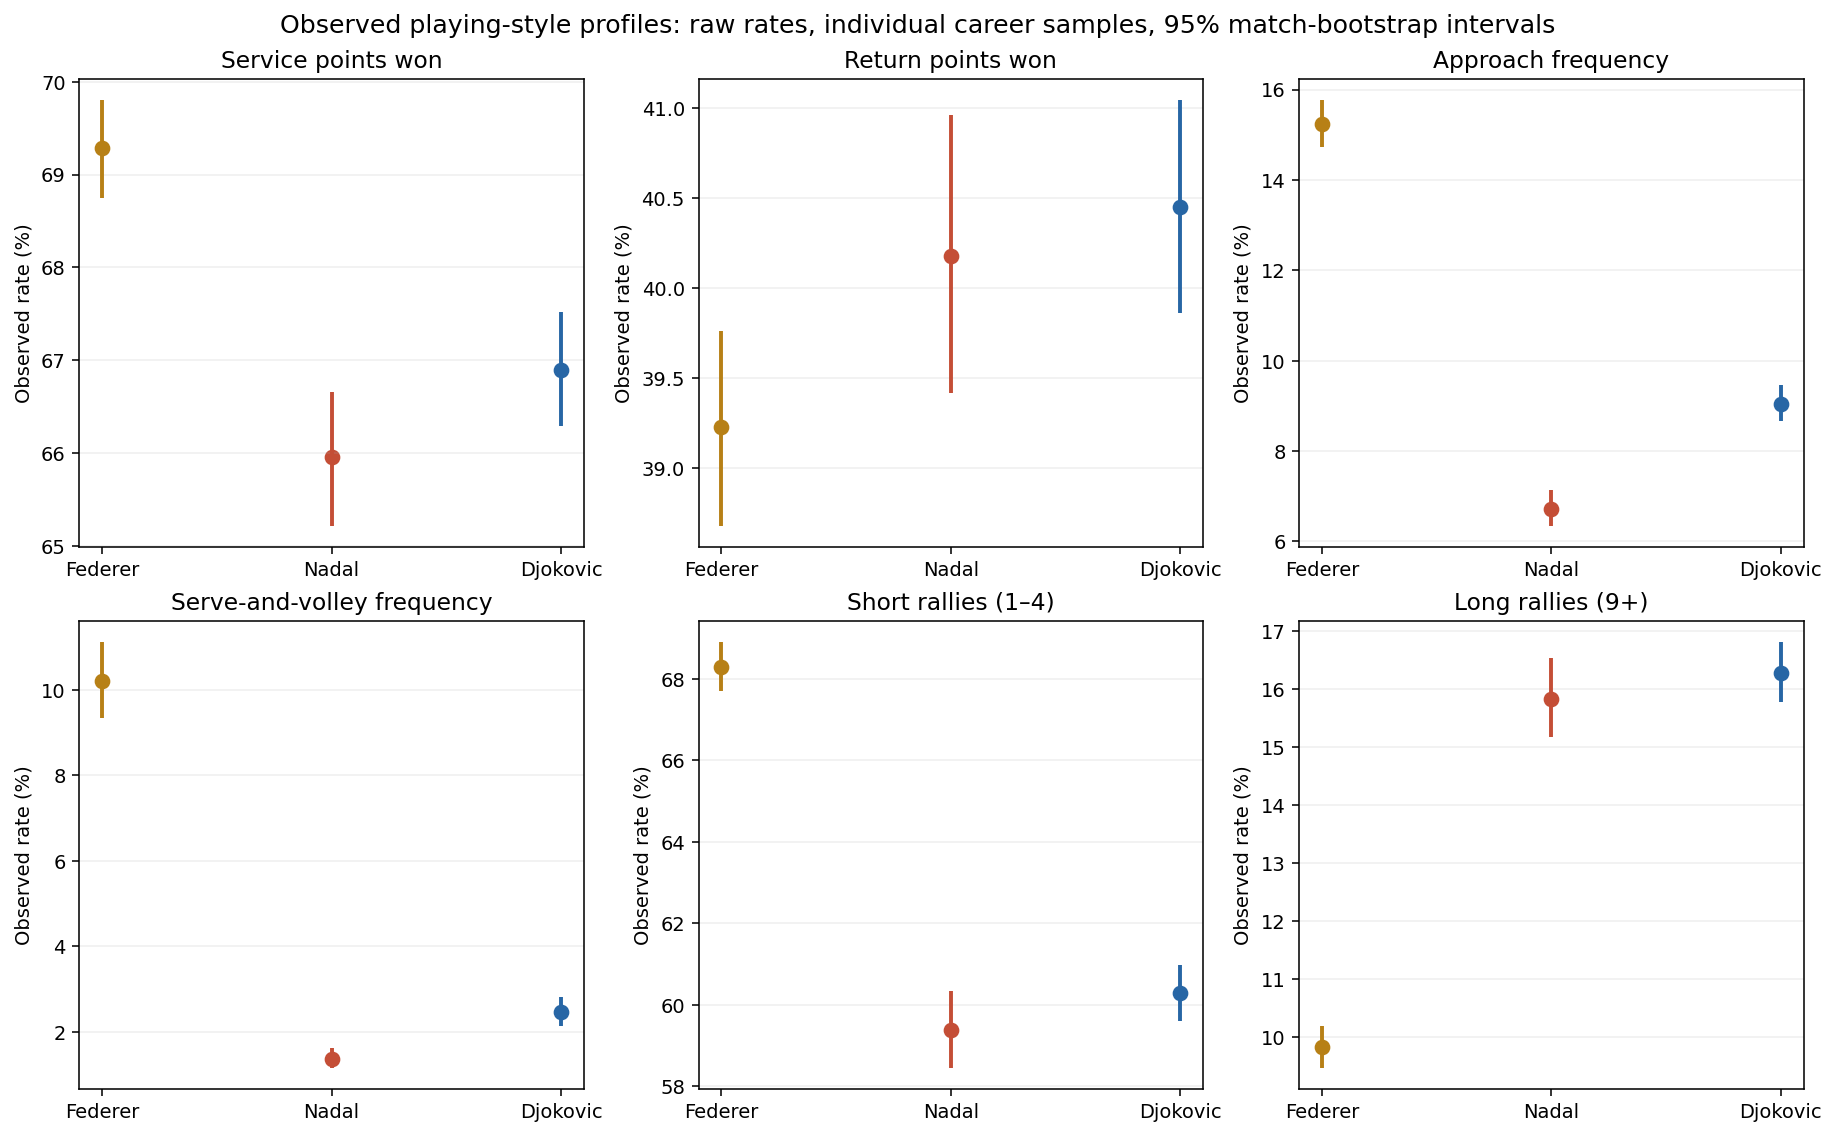

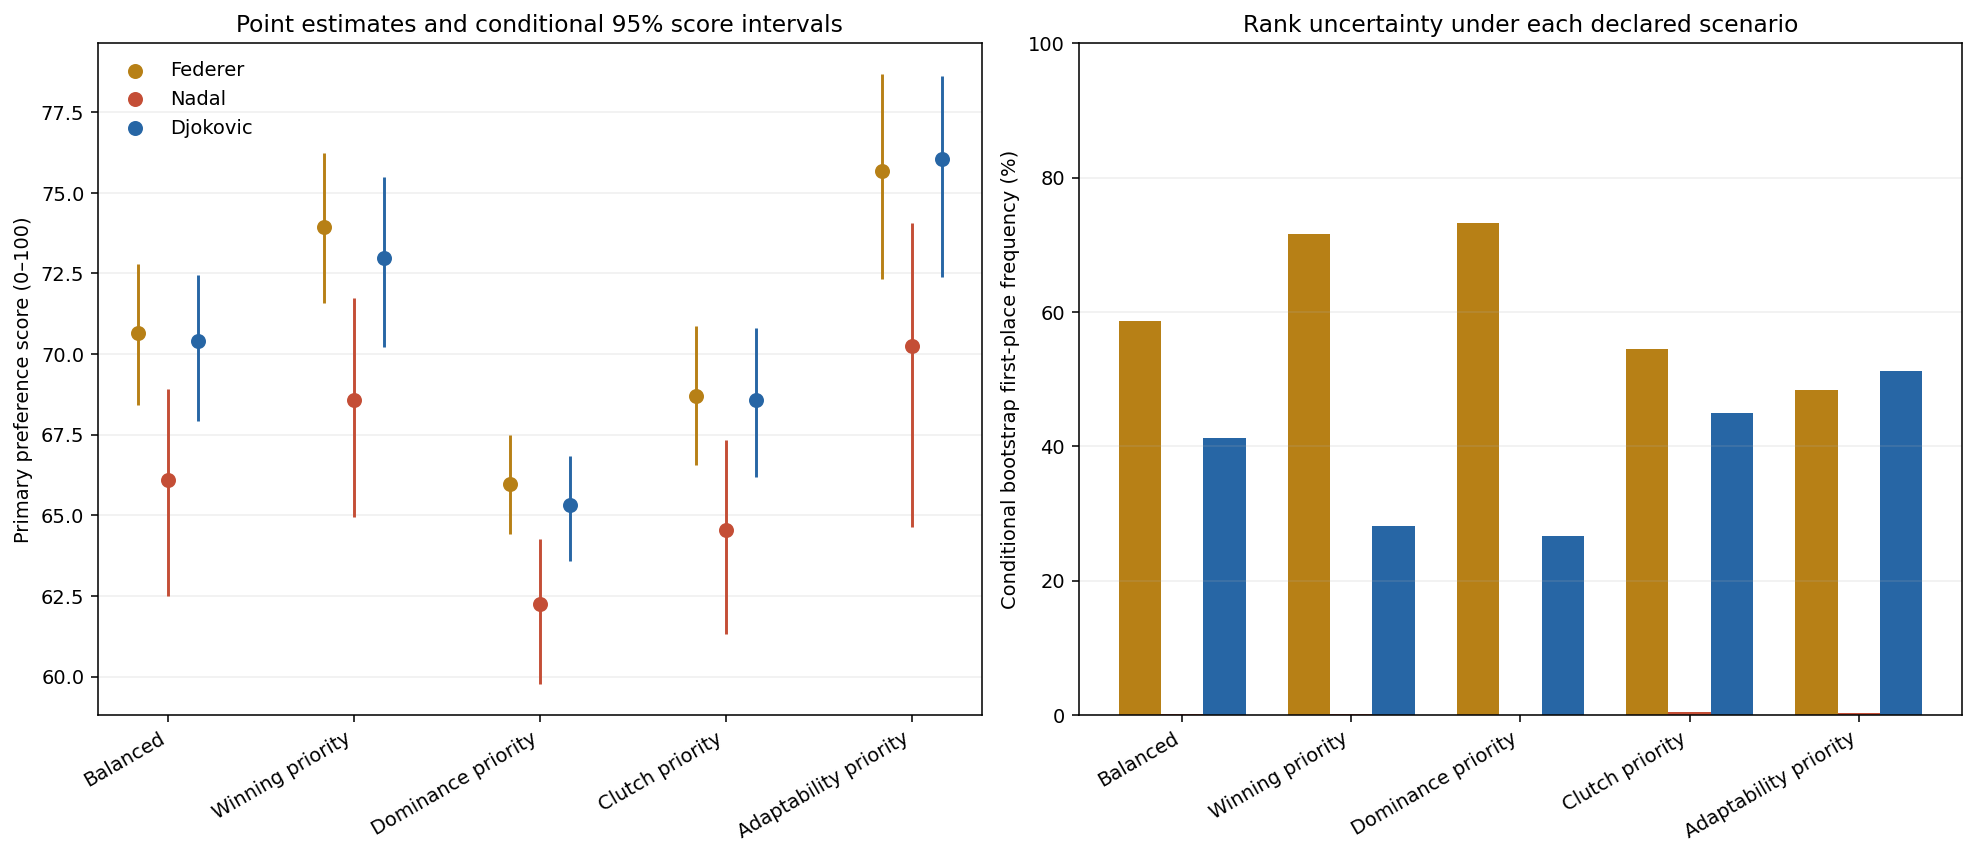

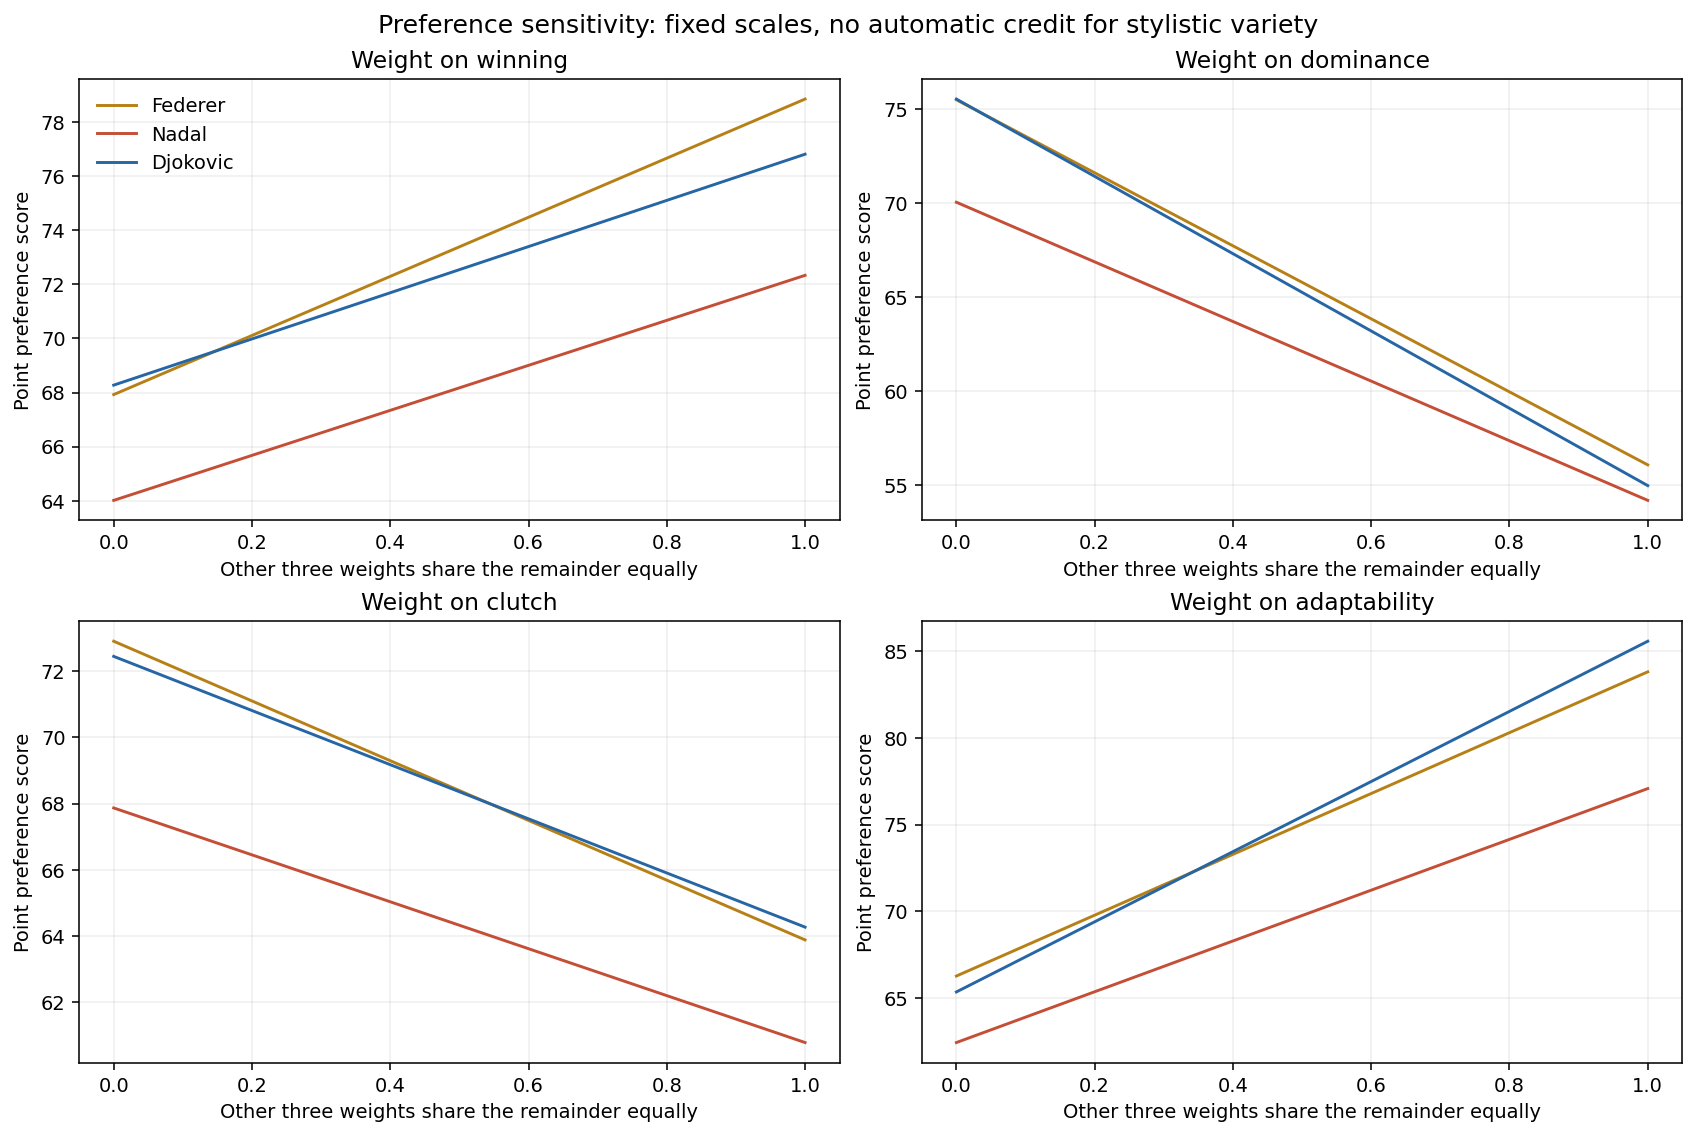

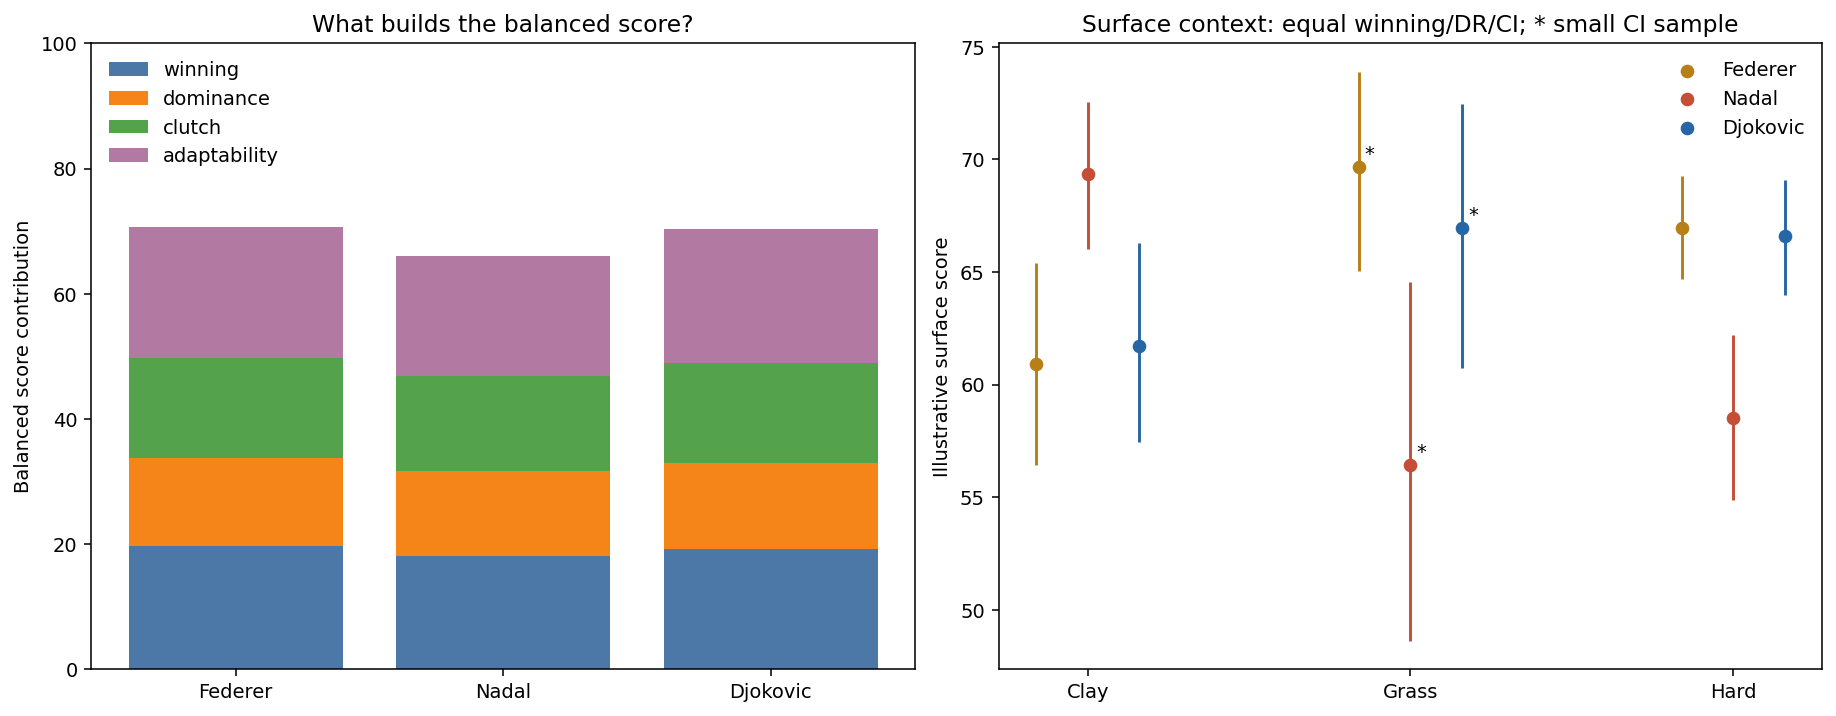

In [25]:
with plt.style.context("default"):
    fig,axes=plt.subplots(2,3,figsize=(13,8),constrained_layout=True)
    for ax,metric,title in zip(axes.flat,["service_point_win_pct","return_point_win_pct","approach_frequency_pct","serve_volley_frequency_pct","short_rally_share_pct","long_rally_share_pct"],
        ["Service points won","Return points won","Approach frequency","Serve-and-volley frequency","Short rallies (1–4)","Long rallies (9+)"]):
        for i,player in enumerate(BIG_THREE):
            row=style_profile_long.loc[style_profile_long["player"].eq(player)&style_profile_long["surface"].eq("Overall")&style_profile_long["metric"].eq(metric)].iloc[0]
            ax.scatter(i,row["estimate"],color=KPI_PLAYER_COLORS[player],s=50)
            ax.vlines(i,row["ci95_lower"],row["ci95_upper"],color=KPI_PLAYER_COLORS[player],linewidth=2)
        ax.set_xticks(range(3),[KPI_SHORT_NAMES[p] for p in BIG_THREE]);ax.set_ylabel("Observed rate (%)");ax.set_title(title);ax.grid(axis="y",alpha=.2)
    fig.suptitle("Observed playing-style profiles: raw rates, individual career samples, 95% match-bootstrap intervals",fontsize=13)
    display_kpi_figure(fig)

    fig,axes=plt.subplots(1,2,figsize=(14,6),constrained_layout=True)
    scenarios=list(COMPARISON_SCENARIOS)
    for i,player in enumerate(BIG_THREE):
        rows=comparison_scores.loc[comparison_scores["player"].eq(player)].set_index("scenario").reindex(scenarios)
        x=np.arange(len(scenarios))+(i-1)*.16
        axes[0].scatter(x,rows["score"],color=KPI_PLAYER_COLORS[player],label=KPI_SHORT_NAMES[player],s=45)
        for xpos,(_,row) in zip(x,rows.iterrows()):
            axes[0].vlines(xpos,row["ci95_lower"],row["ci95_upper"],color=KPI_PLAYER_COLORS[player])
        axes[1].bar(np.arange(len(scenarios))+(i-1)*.25,rows["bootstrap_first_place_pct"],width=.25,color=KPI_PLAYER_COLORS[player],label=KPI_SHORT_NAMES[player])
    for ax in axes:
        ax.set_xticks(range(len(scenarios)),scenarios,rotation=30,ha="right");ax.grid(axis="y",alpha=.2)
    axes[0].set_ylabel("Primary preference score (0–100)");axes[0].set_title("Point estimates and conditional 95% score intervals");axes[0].legend(frameon=False, loc="upper left")
    axes[1].set_ylabel("Conditional bootstrap first-place frequency (%)");axes[1].set_ylim(0,100);axes[1].set_title("Rank uncertainty under each declared scenario")
    display_kpi_figure(fig)

    fig,axes=plt.subplots(2,2,figsize=(12,8),constrained_layout=True)
    weight_sweep_rows=[]
    for ax,emphasis in zip(axes.flat,COMPARISON_METRICS):
        for i,player in enumerate(BIG_THREE):
            values=[]
            for weight in np.linspace(0,1,21):
                w=np.array([weight if m==emphasis else (1-weight)/3 for m in COMPARISON_METRICS])
                value=100*comparison_points[i]@w
                values.append(value)
                weight_sweep_rows.append({"emphasized_metric":emphasis,"emphasis_weight":weight,"player":player,"score":value})
            ax.plot(np.linspace(0,1,21),values,color=KPI_PLAYER_COLORS[player],label=KPI_SHORT_NAMES[player])
        ax.set_title("Weight on "+emphasis);ax.set_xlabel("Other three weights share the remainder equally");ax.set_ylabel("Point preference score");ax.grid(alpha=.2)
    axes.flat[0].legend(frameon=False)
    fig.suptitle("Preference sensitivity: fixed scales, no automatic credit for stylistic variety",fontsize=13)
    comparison_weight_sweeps=pd.DataFrame(weight_sweep_rows)
    display_kpi_figure(fig)

    fig,axes=plt.subplots(1,2,figsize=(13,5),constrained_layout=True)
    colors=["#4C78A8","#F58518","#54A24B","#B279A2"]
    bottom=np.zeros(3)
    for metric,color in zip(COMPARISON_METRICS,colors):
        values=comparison_contributions.loc[comparison_contributions["scenario"].eq("Balanced")&comparison_contributions["metric"].eq(metric)].set_index("player").reindex(BIG_THREE)["score_contribution"].to_numpy()
        axes[0].bar(range(3),values,bottom=bottom,color=color,label=metric);bottom+=values
    axes[0].set_xticks(range(3),[KPI_SHORT_NAMES[p] for p in BIG_THREE]);axes[0].set_ylabel("Balanced score contribution");axes[0].set_ylim(0,100);axes[0].legend(frameon=False, loc="upper left");axes[0].set_title("What builds the balanced score?")
    for i,player in enumerate(BIG_THREE):
        rows=surface_preference_comparison.loc[surface_preference_comparison["player"].eq(player)].set_index("surface").reindex(PROJECT_SURFACES)
        x=np.arange(3)+(i-1)*.16
        axes[1].scatter(x,rows["illustrative_score"],color=KPI_PLAYER_COLORS[player],label=KPI_SHORT_NAMES[player])
        for xpos,(_,row) in zip(x,rows.iterrows()):
            axes[1].vlines(xpos,row["ci95_lower"],row["ci95_upper"],color=KPI_PLAYER_COLORS[player])
            if row["small_ci_sample"]:
                axes[1].annotate("*",(xpos,row["illustrative_score"]),xytext=(3,4),textcoords="offset points")
    axes[1].set_xticks(range(3),PROJECT_SURFACES);axes[1].set_ylabel("Illustrative surface score");axes[1].set_title("Surface context: equal winning/DR/CI; * small CI sample");axes[1].legend(frameon=False)
    display_kpi_figure(fig)



<a id="executive-summary"></a>

## Executive conclusion
The scorecards and profiles are the consolidated evidence. Scenario ordering, first-place bootstrap frequency, preference-grid lead share, and historical greatness are different concepts. No single scenario is declared the objective answer. Read the computed summary below alongside direct score-difference intervals, weight/scaling sensitivity, rivalry context, individual coverage, and unavailable ranking history.


In [26]:
from IPython.display import Markdown
summary_columns = ["player", "verified_wins", "unknown_outcome_matches", "match_win_pct", "dominance_ratio",
                   "clutch_index_full", "surface_adaptability_score", "handedness"]
print("Executive scorecard: verified charted outcomes, individual career windows; units follow column definitions")
report_table(final_player_scorecard.loc[final_player_scorecard["surface"].eq("Overall"), summary_columns].round(4), expanded=True)
balanced=comparison_scores.loc[comparison_scores["scenario"].eq("Balanced")].sort_values("score",ascending=False)
lines=["**Conditional findings from the current saved data:**"]
for row in balanced.itertuples(index=False):
    lines.append(f"- {row.player}: balanced score {row.score:.2f}, 95% score interval {row.ci95_lower:.2f}–{row.ci95_upper:.2f}, first-place frequency {row.bootstrap_first_place_pct:.1f}% of paired bootstrap draws.")
leaders=comparison_scores.loc[comparison_scores["point_estimate_rank"].eq(1),["scenario","player"]]
lines.append("\nScenario point leaders: "+"; ".join(f"{r.scenario}: {r.player}" for r in leaders.itertuples(index=False))+".")
lines.append("\nThe report supports a conditional Big Three comparison, not an objectively proven greatest player. The preference inputs overlap, charted schedules and outcome coverage differ, and missing ranking history and other career achievements are not represented. Surface specialization and the raw profiles should be read alongside the aggregate model; change or variety alone is not rewarded.")
display(Markdown("\n".join(lines)))

print("Coverage and uncertainty remain part of every conclusion; unsupported ranking weeks and an innovation composite are unavailable.")


Executive scorecard: verified charted outcomes, individual career windows; units follow column definitions


,player,verified_wins,unknown_outcome_matches,match_win_pct,dominance_ratio,clutch_index_full,surface_adaptability_score,handedness
0,Roger Federer,559,14,78.843,1.277,0.639,83.810,Right-handed
4,Rafael Nadal,298,13,72.330,1.183,0.608,77.077,Unavailable/conflicting
8,Novak Djokovic,404,27,76.806,1.221,0.643,85.575,Right-handed


**Conditional findings from the current saved data:**
- Roger Federer: balanced score 70.65, 95% score interval 68.42–72.80, first-place frequency 58.6% of paired bootstrap draws.
- Novak Djokovic: balanced score 70.41, 95% score interval 67.91–72.46, first-place frequency 41.2% of paired bootstrap draws.
- Rafael Nadal: balanced score 66.09, 95% score interval 62.49–68.92, first-place frequency 0.2% of paired bootstrap draws.

Scenario point leaders: Balanced: Roger Federer; Winning priority: Roger Federer; Dominance priority: Roger Federer; Clutch priority: Roger Federer; Adaptability priority: Novak Djokovic.

The report supports a conditional Big Three comparison, not an objectively proven greatest player. The preference inputs overlap, charted schedules and outcome coverage differ, and missing ranking history and other career achievements are not represented. Surface specialization and the raw profiles should be read alongside the aggregate model; change or variety alone is not rewarded.

Coverage and uncertainty remain part of every conclusion; unsupported ranking weeks and an innovation composite are unavailable.


<a id="tableau-handoff"></a>

## X. Reproduction, Tableau handoff, and release checks

### 10.1 Reproduce the saved report
Open `goat.ipynb` from the project root so `Raw Data` resolves beside it, select a Python environment with the packages listed in Section II, then **Restart Kernel and Run All**. All transformations, validation, visualizations, and export code are in this notebook. Source CSVs are never overwritten. The local dictionary and workbook explain chart semantics; the analysis uses no external datasets or network calls.

The version table and installation command below record the executed environment, not a universal compatibility guarantee. Each source is fingerprinted with SHA-256; the aggregate fingerprint identifies this input snapshot. Re-execution with different files can change results, denominators, and confidence intervals. The generated executive conclusion is authoritative for that run. The report uses seed 42 and 2,000 shared match-bootstrap draws.

Interpretation limits remain: chart selection, different opponents and career stages, uncertain endings, source disagreements, missing ranking history, descriptive opponent proxies, and conditional bootstrap inference. Court illustrations show categories, not tracking. More tactical change or variety is not automatically better performance. Unknown and not-applicable values remain missing, never zero-filled for presentation.


In [27]:
import hashlib
import io
import json

REPORT_VERSION = "1.1"
REPORT_SNAPSHOT_DATE = "2026-10-17"  # Report preparation date supplied by the project session.
WRITE_TABLEAU_EXPORTS = True  # Final release: write the validated Tableau CSV bundle.
TABLEAU_EXPORT_DIR = Path("Tableau Exports")
source_manifest_rows = []
source_paths = [raw_data_dir / name for name in csv_filenames] + [raw_data_dir/"data_dictionary.txt", raw_data_dir/"MatchChart 0.3.2.xlsm"]
for path in sorted(source_paths, key=lambda item: item.as_posix()):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024*1024), b""):
            digest.update(block)
    key = path.stem.replace("-", "_")
    source_manifest_rows.append({"relative_path": path.as_posix(), "bytes": path.stat().st_size,
        "sha256": digest.hexdigest(), "raw_rows": len(raw_dataframes_unfiltered[key]) if key in raw_dataframes_unfiltered else pd.NA,
        "role": "analysis CSV" if path.suffix == ".csv" else "local interpretation reference"})
source_manifest = pd.DataFrame(source_manifest_rows)
source_snapshot_sha256 = hashlib.sha256("\n".join(
    source_manifest["relative_path"]+" "+source_manifest["sha256"]).encode("utf-8")).hexdigest()
reproduction_requirements = " ".join(package+"=="+version(package) for package in ["pandas","numpy","matplotlib","seaborn","scipy","scikit-learn","ipython","ipykernel","nbformat","nbclient"])
print("Executed package installation command (use in your chosen environment):")
print("python -m pip install "+reproduction_requirements)
print("Input snapshot SHA-256:", source_snapshot_sha256)
report_table(source_manifest)


Executed package installation command (use in your chosen environment):
python -m pip install pandas==2.2.2 numpy==1.26.4 matplotlib==3.8.4 seaborn==0.13.2 scipy==1.13.0 scikit-learn==1.4.2 ipython==8.5.0 ipykernel==6.15.3 nbformat==5.5.0 nbclient==0.6.8
Input snapshot SHA-256: 1b253ea57274935af4e7102b6e83d97d534b8fc74b6cc1ed48effcc8c258eab7


relative_path,bytes,sha256,raw_rows,role
Raw Data/MatchChart 0.3.2.xlsm,482316,46e2349eee512296a86170449f6e463a6be91be9261a0c7b6b5d5a25c006729f,<NA>,local interpretation reference
Raw Data/charting-m-matches.csv,1141817,d8dce1ad8d12c04efa01da587441b54ece8e8100530660528312244f632efe80,7566,analysis CSV
Raw Data/charting-m-points-2010s.csv,36475702,2719cdc136b64698f24b360cf4f60302e11add24971c2fdd585e1b729178db8c,357229,analysis CSV
Raw Data/charting-m-points-2020s.csv,56590483,2cd43f73e0530a47ea4c02b99dae40177ca6d58a8ccf9189358eb05dffb4be9a,547478,analysis CSV
Raw Data/charting-m-points-to-2009.csv,38025307,12613c7fc4d7acc6d4577ec33554a4308497a5e18669560688f1a2e00704fc72,379569,analysis CSV
Raw Data/charting-m-stats-KeyPointsReturn.csv,5351478,817cebdd70f81a57b699cbd15a89313f1e76c7bfccae73e639a8dce101a5e697,60464,analysis CSV
Raw Data/charting-m-stats-KeyPointsServe.csv,5832013,a2cec9bfe6cb98545895ea100c4fd77900c8febfb9d34c6d63326999f5dcd8f0,60464,analysis CSV
Raw Data/charting-m-stats-NetPoints.csv,6184262,239540c77767512921153a05d8e320450524b6a06976c5bf0d496268a2dee0e8,59396,analysis CSV
Raw Data/charting-m-stats-Overview.csv,6651805,9b08d763e1209dec276206998b96823731f0351ab9b86d25415a7e3dd313290c,56850,analysis CSV
Raw Data/charting-m-stats-Rally.csv,10974130,39fca5a5f930a7a3444d00533016baa764ec37ce43d0a06aa07b713f38d6b498,96706,analysis CSV


### 10.2 Tableau data model and export contract
The registry below defines each CSV's grain, unique key, and use. All registered tables are also retained as notebook DataFrames, and their evidence is displayed in the report. **Exports are enabled for this release.** Set `WRITE_TABLEAU_EXPORTS = False` for a notebook-only rerun; this switch controls file writing and does not change analytical results. Rerun the registry/export cell after running the analysis to refresh the bundle. The export directory is `Tableau Exports`; it contains generated tables, a field catalog, and a manifest, not independent analysis code.

Use `players` as a dimension and **relationships rather than physical joins between multiple fact tables**. Scope values are `Overall`, `Clay`, `Grass`, or `Hard`; never add Overall to its component surfaces. Period facts relate through `player_id` plus `period_index`, and scope-specific facts through `player_id` plus `scope`. Categories, metrics, scenarios, and replicate IDs complete the grains listed below. H2H has two role-playing player keys. Standardized tactical trends relate to players/periods and must remain distinct from observed surface facts.

Percentages are 0–100 unless the unit explicitly says fraction/index; CI and entropy are 0–1, SAS and preference scores 0–100, and DR is a ratio. Format using the supplied units. Do not SUM percentages, scores, CI, entropy, or ranks across rows. At a complete grain use ATTR/MIN for precomputed rates; where pooling is meaningful, use summed numerators divided by summed denominators from the same metric/eligibility sample. Unknown values export as blank cells; ranking weeks are a nullable numeric field with a separate availability label.

For a first dashboard, use: (1) the consolidated overall/surface scorecard; (2) shot type and conditional direction shares with coverage; (3) raw versus standardized tactical trends with period counts; (4) primary scenario scores with uncertainty. Keep coverage and small-sample flags visible in tooltips. Existing intervals and rank frequencies belong to their saved scenarios and cannot be reused for arbitrary dashboard weights.

For custom weight parameters, `comparison_inputs_wide` contains the fixed-scale player inputs. With nonnegative weights and a positive total, calculate `100 × (w_win × winning + w_dr × dominance + w_ci × clutch + w_sas × adaptability) / (w_win + w_dr + w_ci + w_sas)`. The paired `comparison_bootstrap_inputs` uses exactly the same four columns per replicate/player if custom uncertainty is implemented: retain all three players within each replicate and split tie credit. Treat bootstrap first-place frequency as conditional uncertainty, not a probability of being the greatest in history.


In [28]:
# Every table has an explicit grain, no inf values, deterministic player IDs, and validated CSV round-trips.
PLAYER_IDS = {"Roger Federer":"federer", "Rafael Nadal":"nadal", "Novak Djokovic":"djokovic"}

def tableau_frame(frame):
    result = frame.copy()
    for column in ["player", "player_a", "player_b"]:
        if column in result:
            id_column = "player_id" if column == "player" else column+"_id"
            result[id_column] = result[column].map(PLAYER_IDS)
            if result[id_column].isna().any():
                raise ValueError(f"Unrecognized player in {column}")
    if "surface" in result:
        result = result.rename(columns={"surface":"scope"})
    for column in result:
        if pd.api.types.is_datetime64_any_dtype(result[column]):
            result[column] = result[column].dt.strftime("%Y-%m-%d")
    if "weeks_at_no_1" in result:
        result["weeks_at_no_1_availability"] = result["weeks_at_no_1"]
        result["weeks_at_no_1"] = pd.Series(pd.NA, index=result.index, dtype="Float64")
    return result.reset_index(drop=True)

players_export = core_kpi_coverage.loc[core_kpi_coverage["surface"].eq("Overall"),
    ["player","handedness","earliest_charted_date","latest_charted_date","weeks_at_no_1"]]
clutch_export_rows=[]
for row in clutch_summary.itertuples(index=False):
    for name,num,den in [("bp_component","bp_saved","bp_faced"),("tb_component","tiebreaks_won","tiebreaks_played"),
                         ("deciding_component","deciding_sets_won","deciding_sets_played"),("clutch_index_full",None,None)]:
        clutch_export_rows.append({"player":row.player,"surface":row.surface,"metric":name,"estimate":getattr(row,name),
            "unit":"fraction (0–1)","numerator":getattr(row,num) if num else np.nan,"denominator":getattr(row,den) if den else np.nan,
            "common_ci_matches":row.common_ci_matches,"cohort_matches":row.cohort_matches,"small_sample":row.small_sample,
            "ci95_lower":getattr(row,name+"_ci95_lower"),"ci95_upper":getattr(row,name+"_ci95_upper")})
bootstrap_export = pd.DataFrame(comparison_draws_valid.reshape(-1,4),columns=COMPARISON_METRICS)
bootstrap_export["replicate_id"] = np.repeat(np.arange(1,len(comparison_draws_valid)+1),len(BIG_THREE))
bootstrap_export["player"] = np.tile(BIG_THREE,len(comparison_draws_valid))
inputs_wide_export = pd.DataFrame(comparison_points,columns=COMPARISON_METRICS).assign(player=BIG_THREE)
weights_long_export = comparison_weights.melt(id_vars="scenario",value_vars=COMPARISON_METRICS,var_name="metric",value_name="weight")

# table name: (dataframe, full unique key, dashboard use / unit notes)
export_specs = {
 "players":(players_export,["player_id"],"Player dimension; charted coverage dates; ranking weeks blank with availability label"),
 "coverage":(core_kpi_coverage,["player_id","scope"],"Observed player/scope coverage and known/unknown outcomes"),
 "performance_metrics":(core_kpi_long,["player_id","scope","metric"],"Percentages 0–100 or DR ratio as unit states; matched counts and bootstrap intervals"),
 "clutch_metrics":(pd.DataFrame(clutch_export_rows),["player_id","scope","metric"],"Common-cohort components and full CI, fractions 0–1"),
 "clutch_component_evidence":(clutch_component_evidence,["player_id","scope","component"],"Component-specific versus common-cohort rates, fractions 0–1"),
 "pressure_event_coverage":(pressure_event_coverage,["model","player_id","scope"],"Observed eligible pressure points and match clusters; percentages 0–100"),
 "pressure_model_contrasts":(pressure_pairwise,["model","comparison"],"Direct conditional odds ratios, Wald intervals, Holm-adjusted p-values"),
 "shot_distribution":(shot_distribution_long,["player_id","scope","distribution","category"],"Categorical counts and shares 0–100; no tracking coordinates"),
 "shot_diversity":(shot_diversity_summary,["player_id","scope","distribution"],"Normalized entropy 0–1; fixed K and classified denominator"),
 "shot_coverage":(shot_coverage_summary,["player_id","scope"],"Sequence/type/target/depth coverage, not inferred missing strokes"),
 "surface_adaptability":(surface_adaptability_summary_v2.assign(surface="Overall"),["player_id","scope"],"Primary SAS/parity 0–100; weakest surface evidence and intervals"),
 "adaptability_weights":(surface_adaptability_weight_sensitivity,["player_id","parity_weight"],"Point definition-sensitivity scores; weights are fractions"),
 "periods":(tactical_period_plan,["player_id","period_index"],"Individual four-year bin definitions and observed dates; sort by period_index"),
 "tactical_trends":(tactical_evolution_long,["player_id","scope","period_index","metric"],"Raw pooled and within-surface rates 0–100, counts, eligible samples"),
 "tactical_standardized":(tactical_standardized_trends,["player_id","period_index","metric"],"Equal-surface estimates 0–100; not an observed Overall scope"),
 "tactical_changes":(tactical_change_summary,["player_id","metric"],"Exploratory first/last supported-period changes in percentage points"),
 "style_profiles":(style_profile_long,["player_id","scope","metric"],"Raw percentages 0–100 or diversity indices 0–1; unit column applies"),
 "comparison_inputs":(normalization_audit,["player_id","metric"],"Raw values, primary fixed scales 0–1, alternative three-player min–max sensitivity"),
 "comparison_inputs_wide":(inputs_wide_export,["player_id"],"Four primary fixed scales 0–1 for custom point weights"),
 "comparison_bootstrap_inputs":(bootstrap_export,["replicate_id","player_id"],"Joint paired scaled draws; do not break replicate/player dependence"),
 "preference_scores":(comparison_scores,["scenario","player_id"],"Scenario scores 0–100, rank frequencies 0–100 and conditional intervals"),
 "preference_weights":(weights_long_export,["scenario","metric"],"Scenario weights are nonnegative fractions summing to one"),
 "preference_contributions":(comparison_contributions,["scenario","player_id","metric"],"Contributions sum to scenario/player score, not independent achievements"),
 "score_differences":(comparison_pairwise_differences,["scenario","comparison"],"Paired score differences and bootstrap-ahead frequency, not p-values"),
 "surface_preference_scores":(surface_preference_comparison,["player_id","scope"],"Illustrative equal winning/DR/CI score 0–100, SAS omitted"),
 "head_to_head":(validated_h2h_summary,["player_a_id","player_b_id","scope"],"Charted rivalry outcomes; unknown matches retained, rates 0–100"),
 "scorecard":(final_player_scorecard,["player_id","scope"],"Consolidated wide KPIs; units follow named metrics; SAS only Overall"),
 "source_manifest":(source_manifest,["relative_path"],"Local input filenames, byte counts and SHA-256 fingerprints"),
 "audit_summary":(audit_summary,["dataset"],"Raw = duplicates removed + quarantined + eligible; counts are not rates"),
 "audit_review_register":(audit_review_register,["issue"],"Review scopes and metric-specific handling; flags are not all corrupt matches"),
}
tableau_exports, registry_rows, field_rows, csv_payloads = {}, [], [], {}
for name,(frame,key,notes) in export_specs.items():
    exported=tableau_frame(frame)
    if exported[key].isna().any().any() or exported.duplicated(key).any():
        raise AssertionError(f"Invalid export key: {name}")
    for column in exported.select_dtypes(include="number"):
        if np.isinf(exported[column].to_numpy(dtype=float,na_value=np.nan)).any():
            raise AssertionError(f"Infinite numeric export value: {name}.{column}")
    with np.errstate(invalid="ignore"):
        csv_text=exported.to_csv(index=False,na_rep="",lineterminator="\n",float_format="%.12g")
    parsed=pd.read_csv(io.StringIO(csv_text),dtype=str,keep_default_na=False)
    if len(parsed)!=len(exported) or list(parsed.columns)!=list(exported.columns):
        raise AssertionError(f"CSV schema/row round-trip failed: {name}")
    if parsed.duplicated(key).any():
        raise AssertionError(f"CSV key round-trip failed: {name}")
    for column in exported.select_dtypes(include="number"):
        if pd.api.types.is_bool_dtype(exported[column]):
            continue
        expected=exported[column].to_numpy(dtype=float,na_value=np.nan)
        actual=pd.to_numeric(parsed[column].where(parsed[column].ne(""),np.nan),errors="coerce").to_numpy(dtype=float)
        if not np.allclose(expected,actual,rtol=1e-10,atol=1e-10,equal_nan=True):
            raise AssertionError(f"CSV numeric round-trip failed: {name}.{column}")
    tableau_exports[name]=exported
    csv_payloads[name]=csv_text
    registry_rows.append({"table":name,"rows":len(exported),"columns":len(exported.columns),"unique_key":", ".join(key),
        "notes":notes,"csv_sha256":hashlib.sha256(csv_text.encode("utf-8")).hexdigest()})
    for column in exported:
        role="key" if column in key else "measure" if pd.api.types.is_numeric_dtype(exported[column]) else "attribute"
        field_rows.append({"table":name,"field":column,"pandas_dtype":str(exported[column].dtype),"role":role,
            "missing_cells":int(exported[column].isna().sum()),"table_units_and_use":notes})
tableau_export_registry=pd.DataFrame(registry_rows)
tableau_field_catalog=pd.DataFrame(field_rows)
export_manifest={"report_version":REPORT_VERSION,"report_snapshot_date":REPORT_SNAPSHOT_DATE,"input_snapshot_sha256":source_snapshot_sha256,
    "random_seed":RANDOM_SEED,"bootstrap_replicates":BOOTSTRAP_REPLICATES,"player_ids":PLAYER_IDS,"percentage_scale":"0–100 unless unit states fraction/index",
    "missing_values":"empty CSV cells; unknown and not-applicable are not zeros","tables":tableau_export_registry.to_dict(orient="records")}
if WRITE_TABLEAU_EXPORTS:
    TABLEAU_EXPORT_DIR.mkdir(parents=True,exist_ok=True)
    for name,csv_text in csv_payloads.items():
        (TABLEAU_EXPORT_DIR/(name+".csv")).write_text(csv_text,encoding="utf-8")
    tableau_field_catalog.to_csv(TABLEAU_EXPORT_DIR/"field_catalog.csv",index=False)
    tableau_export_registry.to_csv(TABLEAU_EXPORT_DIR/"table_registry.csv",index=False)
    (TABLEAU_EXPORT_DIR/"manifest.json").write_text(json.dumps(export_manifest,ensure_ascii=False,indent=2)+"\n",encoding="utf-8")
    print(f"Wrote {len(csv_payloads)} data CSVs, field_catalog.csv, table_registry.csv and manifest.json to {TABLEAU_EXPORT_DIR}.")
else:
    print(f"Validated {len(csv_payloads)} optional data CSVs in memory; no export files written. Set WRITE_TABLEAU_EXPORTS=True to materialize them.")
report_table(tableau_export_registry,caption="Tableau table registry: complete grain and unit contracts")
report_table(tableau_field_catalog,caption="Tableau field catalog: all columns, roles, dtypes and missingness")


Validated 30 optional data CSVs in memory; no export files written. Set WRITE_TABLEAU_EXPORTS=True to materialize them.


table,rows,columns,unique_key,notes,csv_sha256
players,3,7,player_id,Player dimension; charted coverage dates; ranking weeks blank with availability label,ced277a53fcc24cda8fe6d23b915f2bae05d4e6e2f5135ca7a7cbf9bd1775e9b
coverage,12,14,"player_id, scope",Observed player/scope coverage and known/unknown outcomes,bfe3a776cff6db8563780c8efc9d73421df4e225c282dfd13802cb1ff9ef2a48
performance_metrics,168,22,"player_id, scope, metric",Percentages 0–100 or DR ratio as unit states; matched counts and bootstrap intervals,b4b56b02aef74a3a230eb7acdb70a8591574fe4b8a3ac9cfcba06fe1366e9050
clutch_metrics,48,13,"player_id, scope, metric","Common-cohort components and full CI, fractions 0–1",9eae8bfaf994e8874c4dca2b5051e3dff33a715c69127bd8ec75a747bd9b3638
clutch_component_evidence,36,11,"player_id, scope, component","Component-specific versus common-cohort rates, fractions 0–1",33af6acf8482f944c77b5992314fd3102f85a18b253e8ced2db0db10f1d068e7
pressure_event_coverage,18,8,"model, player_id, scope",Observed eligible pressure points and match clusters; percentages 0–100,73272bf57d2f70b877fa4c7afaebe40927f36e7b33bba723ed74005e461a5317
pressure_model_contrasts,6,7,"model, comparison","Direct conditional odds ratios, Wald intervals, Holm-adjusted p-values",7694a553ba40cf56a42a202676403f8a00e08ad5dcb92c5916ca8e202a51e0a6
shot_distribution,648,12,"player_id, scope, distribution, category",Categorical counts and shares 0–100; no tracking coordinates,d687601c1e5907102221086ef4c68680ff99c5d2f1da8de40eeee887534fd90a
shot_diversity,96,12,"player_id, scope, distribution",Normalized entropy 0–1; fixed K and classified denominator,87bfc7159115d6569ea7ebb7450da44e2e7df273cd867234d6a045018c011d9e
shot_coverage,12,24,"player_id, scope","Sequence/type/target/depth coverage, not inferred missing strokes",ff71f735ac0ed2fc20b3fd5d57652a9e453799966349db1ad8c066ad74695333


table,field,pandas_dtype,role,missing_cells,table_units_and_use
players,player,object,attribute,0,Player dimension; charted coverage dates; ranking weeks blank with availability label
players,handedness,object,attribute,0,Player dimension; charted coverage dates; ranking weeks blank with availability label
players,earliest_charted_date,object,attribute,0,Player dimension; charted coverage dates; ranking weeks blank with availability label
players,latest_charted_date,object,attribute,0,Player dimension; charted coverage dates; ranking weeks blank with availability label
players,weeks_at_no_1,Float64,measure,3,Player dimension; charted coverage dates; ranking weeks blank with availability label
players,player_id,object,key,0,Player dimension; charted coverage dates; ranking weeks blank with availability label
players,weeks_at_no_1_availability,object,attribute,0,Player dimension; charted coverage dates; ranking weeks blank with availability label
coverage,player,object,attribute,0,Observed player/scope coverage and known/unknown outcomes
coverage,scope,object,key,0,Observed player/scope coverage and known/unknown outcomes
coverage,charted_matches,int64,measure,0,Observed player/scope coverage and known/unknown outcomes


### 10.3 Release validation and source traceability
The checks below verify input preservation, output grains and bounds, paired rank-frequency mass, export round-trips, and required unavailable fields. Metric-specific review flags are retained and handled by eligibility; a passed check does not erase source uncertainty or selection bias. A fresh-kernel execution must finish every cell without an error before saving the report. Detailed evidence remains embedded even when its presentation panel is collapsed.

To publish, share this notebook with its saved outputs. Reproducing it requires the unchanged `Raw Data` inputs identified by the manifest; viewing its tables and figures does not require execution. To build Tableau, use the validated release bundle or regenerate it using the documented switch and use the registry's relationships and units. All analysis and export logic remains here.


In [29]:
release_checks=[]
def release_check(name,condition):
    release_checks.append({"check":name,"status":"PASS" if bool(condition) else "FAIL"})
    if not condition:
        raise AssertionError(name)

# Re-read each CSV to verify that the preserved original frames were not changed in memory.
for filename in csv_filenames:
    key=Path(filename).stem.replace("-","_")
    original_again=pd.read_csv(raw_data_dir/filename,low_memory=False)
    pd.testing.assert_frame_equal(raw_dataframes_unfiltered[key],original_again)
release_check("All 19 original input frames equal freshly read CSVs",len(raw_dataframes_unfiltered)==19)
release_check("Shared audit accounting and hard key checks pass",integrity_check_results["failures"].sum()==0)
release_check("Canonical player-match spine is unique",not canonical_master.duplicated(["match_id","player"]).any())
release_check("Unknown outcomes stay missing rather than losses",canonical_master.loc[canonical_master["winner"].isna(),"is_win"].isna().all())
release_check("Core performance keys are unique",not core_kpi_long.duplicated(["player","surface","metric"]).any())
release_check("Full CI remains within 0–1",clutch_summary["clutch_index_full"].dropna().between(0,1).all())
release_check("SAS remains within 0–100",surface_adaptability_summary_v2["surface_adaptability_score"].dropna().between(0,100).all())
release_check("Standardized trends require every surface",tactical_standardized_trends.loc[tactical_standardized_trends["surfaces_available"].lt(3),"standardized_pct"].isna().all())
release_check("Primary scenario rank frequencies sum to 100",np.allclose(comparison_scores.groupby("scenario")["bootstrap_first_place_pct"].sum(),100))
release_check("Consolidated scorecard has 12 unique player/scope rows",len(final_player_scorecard)==12 and not final_player_scorecard.duplicated(["player","surface"]).any())
release_check("Single-surface SAS is not fabricated",final_player_scorecard.loc[final_player_scorecard["surface"].ne("Overall"),"surface_adaptability_score"].isna().all())
release_check("Ranking weeks remain nullable numeric with unavailable status",tableau_exports["players"]["weeks_at_no_1"].isna().all())
release_check("All registered export tables passed unique-key and CSV round-trip checks",len(tableau_exports)==len(export_specs)==len(csv_payloads))
release_check("All 21 local sources have recorded fingerprints",len(source_manifest)==21 and source_manifest["sha256"].str.len().eq(64).all())
release_validation=pd.DataFrame(release_checks)
report_table(release_validation,expanded=True)
report_run_manifest=pd.DataFrame([{"report_version":REPORT_VERSION,"snapshot_preparation_date":REPORT_SNAPSHOT_DATE,
    "input_snapshot_sha256":source_snapshot_sha256,"seed":RANDOM_SEED,"bootstrap_replicates":BOOTSTRAP_REPLICATES,
    "original_source_tables":len(raw_dataframes_unfiltered),"canonical_player_matches":len(canonical_master),
    "source_review_flags_retained":len(numeric_quality_flags),"tableau_data_tables":len(tableau_exports),
    "export_files_written":WRITE_TABLEAU_EXPORTS,"release_assertions_passed":len(release_validation)}])
report_table(report_run_manifest,expanded=True)
print("All release assertions passed. Analysis tables and static figures are saved in the notebook; input review flags and inferential limits remain disclosed.")


check,status
All 19 original input frames equal freshly read CSVs,PASS
Shared audit accounting and hard key checks pass,PASS
Canonical player-match spine is unique,PASS
Unknown outcomes stay missing rather than losses,PASS
Core performance keys are unique,PASS
Full CI remains within 0–1,PASS
SAS remains within 0–100,PASS
Standardized trends require every surface,PASS
Primary scenario rank frequencies sum to 100,PASS
Consolidated scorecard has 12 unique player/scope rows,PASS


report_version,snapshot_preparation_date,input_snapshot_sha256,seed,bootstrap_replicates,original_source_tables,canonical_player_matches,source_review_flags_retained,tableau_data_tables,export_files_written,release_assertions_passed
1.0,2026-10-16,1b253ea57274935af4e7102b6e83d97d534b8fc74b6cc1ed48effcc8c258eab7,42,2000,19,1701,12138,30,False,14


All release assertions passed. Analysis tables and static figures are saved in the notebook; input review flags and inferential limits remain disclosed.
